In [1]:
from pathlib import Path

# Project paths
PROJECT_DIR = Path(r"C:\Users\noura\Z-BCI-Motor")

DATA_DIR = PROJECT_DIR / "ML CSV"
LABELS_PATH = PROJECT_DIR / "labels.csv"
OUTPUT_DIR = PROJECT_DIR / "outputs"

OUTPUT_DIR.mkdir(exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)
print("Labels path:", LABELS_PATH)
print("Output directory:", OUTPUT_DIR)

Project directory: C:\Users\noura\Z-BCI-Motor
Data directory: C:\Users\noura\Z-BCI-Motor\ML CSV
Labels path: C:\Users\noura\Z-BCI-Motor\labels.csv
Output directory: C:\Users\noura\Z-BCI-Motor\outputs


In [2]:
%pip install pandas numpy matplotlib seaborn scipy openpyxl tqdm

Note: you may need to restart the kernel to use updated packages.


In [4]:
csv_files = sorted(
    DATA_DIR.glob("cellula_MI_data_*.csv"),
    key=lambda x: int(x.stem.split("_")[-1])
)

print("Total EEG files:", len(csv_files))
print("Labels file exists:", LABELS_PATH.exists())

print("\nFirst 5 files:")
for file in csv_files[:5]:
    print(file.name)

print("\nLast 5 files:")
for file in csv_files[-5:]:
    print(file.name)

Total EEG files: 2160
Labels file exists: True

First 5 files:
cellula_MI_data_1.csv
cellula_MI_data_2.csv
cellula_MI_data_3.csv
cellula_MI_data_4.csv
cellula_MI_data_5.csv

Last 5 files:
cellula_MI_data_2156.csv
cellula_MI_data_2157.csv
cellula_MI_data_2158.csv
cellula_MI_data_2159.csv
cellula_MI_data_2160.csv


In [5]:
import pandas as pd

sample_files = [
    csv_files[0],
    csv_files[1],
    csv_files[2],
    csv_files[len(csv_files) // 2],
    csv_files[-1]
]

for file in sample_files:
    df = pd.read_csv(file)

    print("=" * 60)
    print("File:", file.name)
    print("Shape:", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())

    print("\nData Types:")
    print(df.dtypes)

    print("\nMissing Values:")
    print(df.isnull().sum())

    print("\nFirst 3 Rows:")
    display(df.head(3))

    print("\nLast 3 Rows:")
    display(df.tail(3))

File: cellula_MI_data_1.csv
Shape: (2500, 5)

Columns:
['Time', 'FZ', 'C3', 'CZ', 'C4']

Data Types:
Time    float64
FZ      float64
C3      float64
CZ      float64
C4      float64
dtype: object

Missing Values:
Time    0
FZ      0
C3      0
CZ      0
C4      0
dtype: int64

First 3 Rows:


,Time,FZ,C3,CZ,C4
0,88451.201876,324761.3750,321002.62500,335287.28125,321417.90625
1,88451.221777,325001.1875,321223.09375,335409.56250,320937.09375
2,88451.221788,324896.7500,321045.53125,334954.40625,320233.56250



Last 3 Rows:


,Time,FZ,C3,CZ,C4
2497,88461.180600,324575.87500,320801.90625,334796.43750,321147.03125
2498,88461.182975,324829.25000,321078.71875,335257.93750,321478.28125
2499,88461.196922,325076.28125,321280.68750,335359.59375,320941.46875


File: cellula_MI_data_2.csv
Shape: (2500, 5)

Columns:
['Time', 'FZ', 'C3', 'CZ', 'C4']

Data Types:
Time    float64
FZ      float64
C3      float64
CZ      float64
C4      float64
dtype: object

Missing Values:
Time    0
FZ      0
C3      0
CZ      0
C4      0
dtype: int64

First 3 Rows:


,Time,FZ,C3,CZ,C4
0,88461.196965,324954.93750,321096.15625,334918.03125,320271.28125
1,88461.201788,324663.65625,320825.59375,334588.03125,320382.78125
2,88461.201826,324572.81250,320809.50000,334803.03125,321148.81250


... (10 outputs left out)

File: cellula_MI_data_2160.csv
Shape: (2500, 5)

Columns:
['Time', 'FZ', 'C3', 'CZ', 'C4']

Data Types:
Time    float64
FZ      float64
C3      float64
CZ      float64
C4      float64
dtype: object

Missing Values:
Time    0
FZ      0
C3      0
CZ      0
C4      0
dtype: int64

First 3 Rows:


,Time,FZ,C3,CZ,C4
0,1.216096e+06,304924.46875,312370.03125,318322.03125,299580.28125
1,1.216096e+06,304897.31250,312568.78125,318351.18750,299405.37500
2,1.216096e+06,305222.56250,312472.31250,318619.46875,299926.28125



Last 3 Rows:


,Time,FZ,C3,CZ,C4
2497,1.216106e+06,304966.21875,312542.50000,318363.87500,299443.65625
2498,1.216106e+06,305320.65625,312367.78125,318645.50000,300074.68750
2499,1.216106e+06,305419.25000,312112.09375,318653.71875,300372.40625


In [6]:
import pandas as pd
from tqdm import tqdm

validation_results = []

expected_columns = ["Time", "FZ", "C3", "CZ", "C4"]

for file in tqdm(csv_files, desc="Validating EEG Files"):

    try:
        df = pd.read_csv(file)

        validation_results.append({
            "file_name": file.name,
            "rows": len(df),
            "columns_count": len(df.columns),
            "columns_match": list(df.columns) == expected_columns,
            "missing_values": int(df.isnull().sum().sum()),
            "duplicate_rows": int(df.duplicated().sum()),
            "non_numeric_values": int(
                df.apply(pd.to_numeric, errors="coerce").isnull().sum().sum()
                - df.isnull().sum().sum()
            ),
            "read_status": "Success",
            "error": None
        })

    except Exception as e:
        validation_results.append({
            "file_name": file.name,
            "rows": None,
            "columns_count": None,
            "columns_match": False,
            "missing_values": None,
            "duplicate_rows": None,
            "non_numeric_values": None,
            "read_status": "Failed",
            "error": str(e)
        })

validation_df = pd.DataFrame(validation_results)

print("Total files scanned:", len(validation_df))
print("Successfully read:", (validation_df["read_status"] == "Success").sum())
print("Failed files:", (validation_df["read_status"] == "Failed").sum())

print("\nRows distribution:")
print(validation_df["rows"].value_counts(dropna=False))

print("\nColumns distribution:")
print(validation_df["columns_count"].value_counts(dropna=False))

print("\nFiles with missing values:",
      (validation_df["missing_values"].fillna(0) > 0).sum())

print("Files with duplicate rows:",
      (validation_df["duplicate_rows"].fillna(0) > 0).sum())

print("Files with non-numeric values:",
      (validation_df["non_numeric_values"].fillna(0) > 0).sum())

print("Files with unexpected columns:",
      (~validation_df["columns_match"]).sum())

Validating EEG Files: 100%|██████████| 2160/2160 [00:30<00:00, 71.92it/s]


Total files scanned: 2160
Successfully read: 2160
Failed files: 0

Rows distribution:
rows
2500    2160
Name: count, dtype: int64

Columns distribution:
columns_count
5    2160
Name: count, dtype: int64

Files with missing values: 0
Files with duplicate rows: 0
Files with non-numeric values: 0
Files with unexpected columns: 0


In [7]:
problem_files = validation_df[
    (validation_df["read_status"] == "Failed") |
    (~validation_df["columns_match"]) |
    (validation_df["missing_values"].fillna(0) > 0) |
    (validation_df["non_numeric_values"].fillna(0) > 0)
]

display(problem_files)

,file_name,rows,columns_count,columns_match,missing_values,duplicate_rows,non_numeric_values,read_status,error


In [8]:
import numpy as np
import pandas as pd
from tqdm import tqdm

sampling_results = []

for file in tqdm(csv_files, desc="Analyzing Sampling Rate"):

    df = pd.read_csv(file)

    time_values = df["Time"].to_numpy()
    time_diff = np.diff(time_values)

    positive_diff = time_diff[time_diff > 0]

    if len(positive_diff) == 0:
        sampling_results.append({
            "file_name": file.name,
            "duration": np.nan,
            "mean_interval": np.nan,
            "median_interval": np.nan,
            "estimated_sampling_rate": np.nan,
            "irregular_intervals": np.nan,
            "non_increasing_timestamps": len(time_diff)
        })
        continue

    mean_interval = np.mean(positive_diff)
    median_interval = np.median(positive_diff)

    sampling_results.append({
        "file_name": file.name,
        "duration": time_values[-1] - time_values[0],
        "mean_interval": mean_interval,
        "median_interval": median_interval,
        "estimated_sampling_rate": 1 / median_interval,
        "irregular_intervals": np.sum(
            ~np.isclose(time_diff, median_interval, rtol=0.01)
        ),
        "non_increasing_timestamps": np.sum(time_diff <= 0)
    })

sampling_df = pd.DataFrame(sampling_results)

display(sampling_df.head())

print("\nSampling Rate Summary:")
display(sampling_df["estimated_sampling_rate"].describe())

print("\nDuration Summary:")
display(sampling_df["duration"].describe())

print("\nNon-increasing timestamps:")
print(sampling_df["non_increasing_timestamps"].sum())

Analyzing Sampling Rate: 100%|██████████| 2160/2160 [00:16<00:00, 129.05it/s]


,file_name,duration,mean_interval,median_interval,estimated_sampling_rate,irregular_intervals,non_increasing_timestamps
0,cellula_MI_data_1.csv,9.995046,0.004000,0.002403,416.059913,2397,0
1,cellula_MI_data_2.csv,9.993729,0.003999,0.002493,401.090966,2238,0
2,cellula_MI_data_3.csv,9.992026,0.003998,0.002473,404.334465,2305,0
3,cellula_MI_data_4.csv,10.029750,0.004014,0.002413,414.456232,2380,0
4,cellula_MI_data_5.csv,10.003483,0.004003,0.002476,403.844601,2322,0



Sampling Rate Summary:


count      2160.000000
mean       9178.138802
std       74734.275411
min         388.198784
25%         397.424677
50%         400.560780
75%         403.522752
max      769233.522539
Name: estimated_sampling_rate, dtype: float64


Duration Summary:


count    2160.000000
mean        9.985076
std         0.119418
min         8.733881
25%         9.975797
50%         9.985092
75%         9.995315
max        11.479649
Name: duration, dtype: float64


Non-increasing timestamps:
0


In [9]:
import numpy as np
import pandas as pd

rate_results = []

for file in csv_files:
    df = pd.read_csv(file)

    time_values = df["Time"].to_numpy()
    intervals = np.diff(time_values)

    duration = time_values[-1] - time_values[0]

    rate_results.append({
        "file_name": file.name,
        "duration": duration,
        "samples": len(df),
        "estimated_rate": (len(df) - 1) / duration,
        "mean_interval": np.mean(intervals),
        "median_interval": np.median(intervals),
        "min_interval": np.min(intervals),
        "max_interval": np.max(intervals)
    })

rate_df = pd.DataFrame(rate_results)

print("Sampling Rate based on total duration:")
display(rate_df["estimated_rate"].describe())

print("\nInterval statistics for first 3 files:")

for file in csv_files[:3]:
    df = pd.read_csv(file)
    intervals = np.diff(df["Time"].to_numpy())

    print("\nFile:", file.name)
    print("First 20 intervals:")
    print(intervals[:20])

    print("\nInterval quantiles:")
    print(np.quantile(intervals, [0, 0.25, 0.5, 0.75, 0.9, 0.99, 1]))

Sampling Rate based on total duration:


count    2160.000000
mean      250.309488
std         3.017252
min       217.689588
25%       250.017129
50%       250.273105
75%       250.506302
max       286.127089
Name: estimated_rate, dtype: float64


Interval statistics for first 3 files:

File: cellula_MI_data_1.csv
First 20 intervals:
[1.99008000e-02 1.06999942e-05 7.78800000e-03 1.24000071e-05
 2.10000144e-06 2.33419999e-03 2.34310000e-03 2.57200000e-03
 1.85370000e-03 2.94719000e-02 2.55890000e-03 7.32190000e-03
 5.00019999e-03 4.99940000e-03 2.51590001e-03 5.17599999e-03
 2.34300000e-03 2.51250001e-03 2.67429999e-03 2.26240000e-03]

Interval quantiles:
[1.99986971e-07 2.04999960e-05 2.40350000e-03 2.66590000e-03
 7.28504000e-03 6.37889080e-02 1.53939000e-01]

File: cellula_MI_data_2.csv
First 20 intervals:
[4.82290001e-03 3.73999937e-05 1.99390000e-02 2.55549999e-03
 3.86020001e-03 4.01999860e-05 1.06000080e-05 4.72690001e-03
 2.64309999e-03 2.47160000e-03 2.45800000e-03 2.46960000e-03
 2.59700000e-03 2.37760000e-03 3.88569999e-03 3.65420000e-03
 3.77000106e-05 1.62715000e-02 2.44090000e-03 3.54000076e-05]

Interval quantiles:
[2.00000068e-06 1.65025000e-03 2.49320001e-03 3.70175000e-03
 7.57891999e-03 3.51504400e-02 7.263570

In [10]:
import numpy as np
import pandas as pd
from tqdm import tqdm

all_intervals = []

for file in tqdm(csv_files, desc="Analyzing Time Intervals"):

    df = pd.read_csv(file)
    intervals = np.diff(df["Time"].to_numpy())

    all_intervals.extend(intervals)

all_intervals = np.array(all_intervals)

interval_summary = pd.Series({
    "Total intervals": len(all_intervals),
    "Minimum": np.min(all_intervals),
    "Maximum": np.max(all_intervals),
    "Mean": np.mean(all_intervals),
    "Median": np.median(all_intervals),
    "Standard Deviation": np.std(all_intervals)
})

display(interval_summary)

interval_groups = pd.cut(
    all_intervals,
    bins=[0, 0.0001, 0.001, 0.004, 0.01, np.inf],
    labels=[
        "Below 0.1 ms",
        "0.1 - 1 ms",
        "1 - 4 ms",
        "4 - 10 ms",
        "Above 10 ms"
    ]
)

distribution = interval_groups.value_counts().sort_index()

distribution_df = pd.DataFrame({
    "Count": distribution,
    "Percentage": distribution / len(all_intervals) * 100
})

display(distribution_df)

Analyzing Time Intervals: 100%|██████████| 2160/2160 [00:17<00:00, 126.25it/s]


Total intervals       5.397840e+06
Minimum               1.998851e-07
Maximum               1.066453e+00
Mean                  3.995629e-03
Median                2.478500e-03
Standard Deviation    7.105779e-03
dtype: float64

,Count,Percentage
Below 0.1 ms,1625974,30.122679
0.1 - 1 ms,6851,0.126921
1 - 4 ms,2357956,43.683325
4 - 10 ms,946179,17.528845
Above 10 ms,460880,8.538230


In [11]:
print("Lowest 10 estimated sampling rates:")
display(
    rate_df.nsmallest(10, "estimated_rate")
)

print("Highest 10 estimated sampling rates:")
display(
    rate_df.nlargest(10, "estimated_rate")
)

Lowest 10 estimated sampling rates:


,file_name,duration,samples,estimated_rate,mean_interval,median_interval,min_interval,max_interval
511,cellula_MI_data_512.csv,11.479649,2500,217.689588,0.004594,0.000012,3.000023e-07,0.711605
608,cellula_MI_data_609.csv,10.836174,2500,230.616460,0.004336,0.000001,2.999441e-07,0.676096
1066,cellula_MI_data_1067.csv,10.801362,2500,231.359720,0.004322,0.002359,1.999433e-07,0.524897
1526,cellula_MI_data_1527.csv,10.649974,2500,234.648454,0.004262,0.002495,1.300010e-06,0.150862
507,cellula_MI_data_508.csv,10.579818,2500,236.204435,0.004234,0.000002,1.999433e-07,0.524775
1623,cellula_MI_data_1624.csv,10.565972,2500,236.513965,0.004228,0.002380,1.999870e-07,0.161246
1619,cellula_MI_data_1620.csv,10.559869,2500,236.650661,0.004226,0.002432,1.999870e-07,0.099844
910,cellula_MI_data_911.csv,10.539910,2500,237.098808,0.004218,0.002482,1.299952e-06,0.148822
1354,cellula_MI_data_1355.csv,10.529708,2500,237.328507,0.004214,0.002411,2.000015e-07,0.255522
573,cellula_MI_data_574.csv,10.518622,2500,237.578644,0.004209,0.000008,1.998851e-07,0.488844


Highest 10 estimated sampling rates:


,file_name,duration,samples,estimated_rate,mean_interval,median_interval,min_interval,max_interval
512,cellula_MI_data_513.csv,8.733881,2500,286.127089,0.003495,0.000001,2.000015e-07,0.378854
610,cellula_MI_data_611.csv,9.029810,2500,276.750003,0.003613,0.000001,2.000015e-07,0.463707
574,cellula_MI_data_575.csv,9.094805,2500,274.772240,0.003639,0.000037,2.000015e-07,0.243859
606,cellula_MI_data_607.csv,9.232018,2500,270.688380,0.003694,0.000001,2.000015e-07,0.414901
1044,cellula_MI_data_1045.csv,9.264442,2500,269.741016,0.003707,0.002380,2.000015e-07,0.172650
1527,cellula_MI_data_1528.csv,9.287462,2500,269.072425,0.003716,0.002478,1.200009e-06,0.089015
508,cellula_MI_data_509.csv,9.317419,2500,268.207314,0.003728,0.000001,2.000015e-07,0.435023
304,cellula_MI_data_305.csv,9.374507,2500,266.574021,0.003751,0.000001,1.999870e-07,0.209018
1069,cellula_MI_data_1070.csv,9.374892,2500,266.563065,0.003751,0.002441,1.299952e-06,0.130004
835,cellula_MI_data_836.csv,9.382562,2500,266.345148,0.003755,0.002421,1.999997e-07,0.093792


In [13]:
# Calculate interval quality for every file

interval_quality = []

for file in tqdm(csv_files, desc="Checking Timestamp Quality"):

    df = pd.read_csv(file)
    intervals = np.diff(df["Time"].to_numpy())

    interval_quality.append({
        "file_name": file.name,
        "tiny_intervals": np.sum(intervals < 0.0001),
        "normal_intervals": np.sum(
            (intervals >= 0.0015) & (intervals <= 0.005)
        ),
        "large_intervals": np.sum(intervals > 0.01),
        "max_interval": np.max(intervals),
        "median_interval": np.median(intervals)
    })

interval_quality_df = pd.DataFrame(interval_quality)

display(
    interval_quality_df.sort_values(
        "large_intervals",
        ascending=False
    ).head(15)
)

print("\nAverage interval quality across files:")

display(
    interval_quality_df[
        [
            "tiny_intervals",
            "normal_intervals",
            "large_intervals"
        ]
    ].describe()
)

Checking Timestamp Quality: 100%|██████████| 2160/2160 [00:14<00:00, 145.65it/s]


,file_name,tiny_intervals,normal_intervals,large_intervals,max_interval,median_interval
360,cellula_MI_data_361.csv,911,321,355,0.073946,0.001157
356,cellula_MI_data_357.csv,897,334,352,0.068934,0.001164
368,cellula_MI_data_369.csv,905,337,349,0.101848,0.001164
354,cellula_MI_data_355.csv,916,329,348,0.083924,0.001154
343,cellula_MI_data_344.csv,908,333,348,0.063614,0.001165
326,cellula_MI_data_327.csv,901,330,347,0.078812,0.001209
374,cellula_MI_data_375.csv,891,322,347,0.073766,0.001151
350,cellula_MI_data_351.csv,900,329,346,0.064600,0.001166
377,cellula_MI_data_378.csv,901,309,344,0.080251,0.001158
333,cellula_MI_data_334.csv,902,354,344,0.061505,0.001174



Average interval quality across files:


,tiny_intervals,normal_intervals,large_intervals
count,2160.000000,2160.000000,2160.000000
mean,752.765741,1176.691667,213.370370
std,207.754629,265.578898,44.885866
min,544.000000,62.000000,91.000000
25%,618.750000,1042.000000,175.000000
50%,747.000000,1101.500000,198.000000
75%,769.000000,1425.000000,253.000000
max,2281.000000,1526.000000,355.000000


In [14]:
for file_number in [512, 513]:

    file = DATA_DIR / f"cellula_MI_data_{file_number}.csv"

    df = pd.read_csv(file)

    df["Time_Diff"] = df["Time"].diff()

    print("\n" + "=" * 60)
    print("File:", file.name)

    print("Duration:", df["Time"].iloc[-1] - df["Time"].iloc[0])

    print("\nSmallest intervals:")
    display(
        df.nsmallest(10, "Time_Diff")[
            ["Time", "Time_Diff"]
        ]
    )

    print("\nLargest intervals:")
    display(
        df.nlargest(10, "Time_Diff")[
            ["Time", "Time_Diff"]
        ]
    )


File: cellula_MI_data_512.csv
Duration: 11.479648699983954

Smallest intervals:


,Time,Time_Diff
1355,512016.459700,3.000023e-07
1356,512016.459700,3.000023e-07
1358,512016.459701,3.000023e-07
1359,512016.459701,3.000023e-07
1360,512016.459701,3.000023e-07
1357,512016.459701,4.000030e-07
1354,512016.459700,5.000038e-07
1959,512019.409923,1.199951e-06
1971,512019.409939,1.199951e-06
1114,512015.155044,1.200009e-06



Largest intervals:


,Time,Time_Diff
2275,512021.261241,0.711605
1993,512020.122189,0.661245
1858,512018.722313,0.334912
1936,512019.367190,0.333714
1343,512016.454864,0.212638
2488,512021.962344,0.177523
2492,512022.132254,0.162449
2473,512021.489661,0.162281
1773,512018.038548,0.159938
987,512014.951115,0.153711



File: cellula_MI_data_513.csv
Duration: 8.733881200023461

Smallest intervals:


,Time,Time_Diff
2456,512030.793277,2.000015e-07
2464,512030.793279,2.000015e-07
2471,512030.793281,2.000015e-07
2477,512030.793283,2.000015e-07
2485,512030.793285,2.000015e-07
2461,512030.793279,2.999441e-07
1741,512028.009681,3.000023e-07
1744,512028.009682,3.000023e-07
1750,512028.009684,3.000023e-07
1757,512028.009687,3.000023e-07



Largest intervals:


,Time,Time_Diff
240,512023.088459,0.378854
480,512023.874890,0.307536
715,512024.698530,0.278735
1564,512027.422184,0.234990
2303,512030.562234,0.216381
1787,512028.385867,0.198572
998,512025.318487,0.196089
40,512022.503426,0.194793
450,512023.431113,0.171323
1139,512025.667306,0.169928


In [16]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

files_to_plot = [361, 512, 513]

for file_number in files_to_plot:

    file = DATA_DIR / f"cellula_MI_data_{file_number}.csv"
    df = pd.read_csv(file)

    time_values = df["Time"].to_numpy()
    intervals = np.diff(time_values)

    fig, axes = plt.subplots(2, 1, figsize=(14, 8))

    # Timestamp intervals
    axes[0].plot(intervals, linewidth=0.7)
    axes[0].axhline(
        0.004,
        linestyle="--",
        label="Expected interval at 250 Hz"
    )
    axes[0].set_title(
        f"Time Intervals - {file.name}"
    )
    axes[0].set_xlabel("Sample Index")
    axes[0].set_ylabel("Time Difference (seconds)")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Raw timestamp
    axes[1].plot(time_values, linewidth=0.7)
    axes[1].set_title("Raw Time Column")
    axes[1].set_xlabel("Sample Index")
    axes[1].set_ylabel("Timestamp")
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

C:\Users\noura\AppData\Local\Temp\ipykernel_5244\1860502458.py:40: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\noura\AppData\Local\Temp\ipykernel_5244\1860502458.py:40: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\noura\AppData\Local\Temp\ipykernel_5244\1860502458.py:40: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [17]:
for file_number in [361, 512, 513]:

    file = DATA_DIR / f"cellula_MI_data_{file_number}.csv"
    df = pd.read_csv(file)

    df["Time_Diff"] = df["Time"].diff()

    print(f"\n{'=' * 60}")
    print(f"File: {file.name}")

    largest_gaps = (
        df.nlargest(5, "Time_Diff")
    )

    for index in largest_gaps.index:

        start = max(0, index - 3)
        end = min(len(df), index + 4)

        print(f"\nAround sample index: {index}")

        display(
            df.loc[start:end, ["Time", "FZ", "C3", "CZ", "C4", "Time_Diff"]]
        )


File: cellula_MI_data_361.csv

Around sample index: 546


,Time,FZ,C3,CZ,C4,Time_Diff
543,915297.740770,288015.90625,283977.06250,309265.28125,293700.40625,0.001277
544,915297.742104,286724.00000,284157.90625,308840.78125,294523.21875,0.001333
545,915297.743331,288473.31250,284970.53125,314770.34375,296552.78125,0.001228
546,915297.817277,290964.84375,285318.78125,318973.00000,296984.96875,0.073946
547,915297.817322,290735.21875,284746.40625,315747.71875,295276.46875,0.000045
548,915297.817331,288081.53125,284017.37500,309561.65625,293760.31250,0.000009
549,915297.817339,286778.96875,284170.96875,309131.71875,294542.90625,0.000008
550,915297.817349,288557.28125,284981.09375,315142.09375,296570.46875,0.000010



Around sample index: 1003


,Time,FZ,C3,CZ,C4,Time_Diff
1000,915299.568299,288635.50000,284963.37500,314159.68750,296628.50000,0.002402
1001,915299.568337,290905.65625,285190.75000,317619.09375,296761.71875,0.000039
1002,915299.570833,290014.87500,284477.71875,313217.96875,294869.50000,0.002496
1003,915299.637084,287205.96875,283820.78125,307017.68750,293552.00000,0.066251
1004,915299.637120,286408.84375,284122.06250,307644.40625,294636.68750,0.000036
1005,915299.637128,288633.28125,284948.18750,314209.56250,296631.43750,0.000009
1006,915299.638377,290902.68750,285181.00000,317663.18750,296764.84375,0.001248
1007,915299.639401,290013.81250,284472.71875,313256.31250,294876.84375,0.001024



Around sample index: 1741


,Time,FZ,C3,CZ,C4,Time_Diff
1738,915302.518204,286789.25000,283835.68750,306324.06250,293577.75000,0.000971
1739,915302.519562,286749.65625,284338.34375,308679.75000,295044.84375,0.001358
1740,915302.520728,289250.00000,285100.53125,315231.31250,296822.34375,0.001166
1741,915302.580799,290943.56250,285098.12500,316961.68750,296457.71875,0.060071
1742,915302.580842,289383.84375,284308.40625,311454.40625,294468.43750,0.000043
1743,915302.594836,286796.40625,283848.21875,306317.43750,293590.09375,0.013994
1744,915302.594876,286756.71875,284348.00000,308673.93750,295054.03125,0.000040
1745,915302.594885,289259.84375,285110.90625,315226.50000,296830.09375,0.000009


... (20 outputs left out)


Around sample index: 1564


,Time,FZ,C3,CZ,C4,Time_Diff
1561,512027.177192,277422.53125,292729.09375,378950.78125,341303.03125,0.004993
1562,512027.184665,277528.12500,292967.18750,379717.62500,342490.34375,0.007472
1563,512027.187194,277937.87500,293325.43750,380058.09375,342914.12500,0.002529
1564,512027.422184,278089.34375,293335.18750,379528.09375,342016.56250,0.234990
1565,512027.422225,277748.15625,292937.59375,378841.15625,341032.28125,0.000041
1566,512027.422235,277443.71875,292752.25000,378971.43750,341324.84375,0.000009
1567,512027.422243,277546.71875,292979.62500,379734.06250,342510.00000,0.000008
1568,512027.422251,277948.34375,293339.93750,380071.93750,342928.43750,0.000008



Around sample index: 2303


,Time,FZ,C3,CZ,C4,Time_Diff
2300,512030.307211,277722.75000,292938.21875,378520.00000,340815.93750,0.002523
2301,512030.312242,277427.71875,292718.56250,378557.56250,340940.21875,0.005031
2302,512030.345853,277546.28125,292963.96875,379370.28125,342136.18750,0.033611
2303,512030.562234,277916.50000,293329.90625,379812.93750,342722.81250,0.216381
2304,512030.562275,278054.18750,293345.37500,379296.06250,341907.31250,0.000041
2305,512030.562284,277734.37500,292947.43750,378523.21875,340819.15625,0.000009
2306,512030.562292,277441.40625,292723.56250,378561.78125,340939.21875,0.000008
2307,512030.562300,277556.71875,292965.31250,379371.25000,342130.65625,0.000008


In [19]:
%matplotlib inline

In [21]:
%matplotlib inline
import matplotlib.pyplot as plt

In [22]:
plt.savefig(
    OUTPUT_DIR / f"timestamp_analysis_{file_number}.png",
    dpi=150,
    bbox_inches="tight"
)

In [23]:
%matplotlib inline
import matplotlib.pyplot as plt

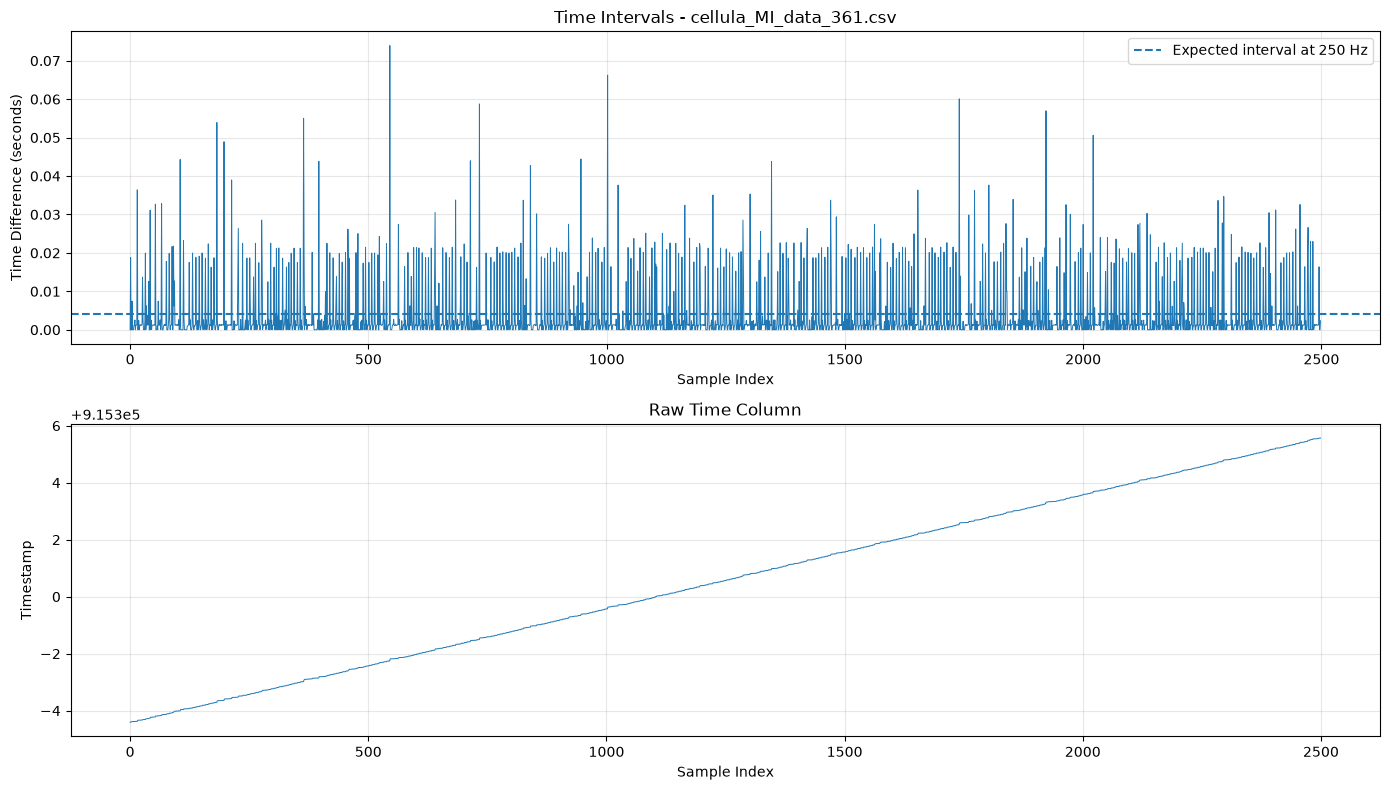

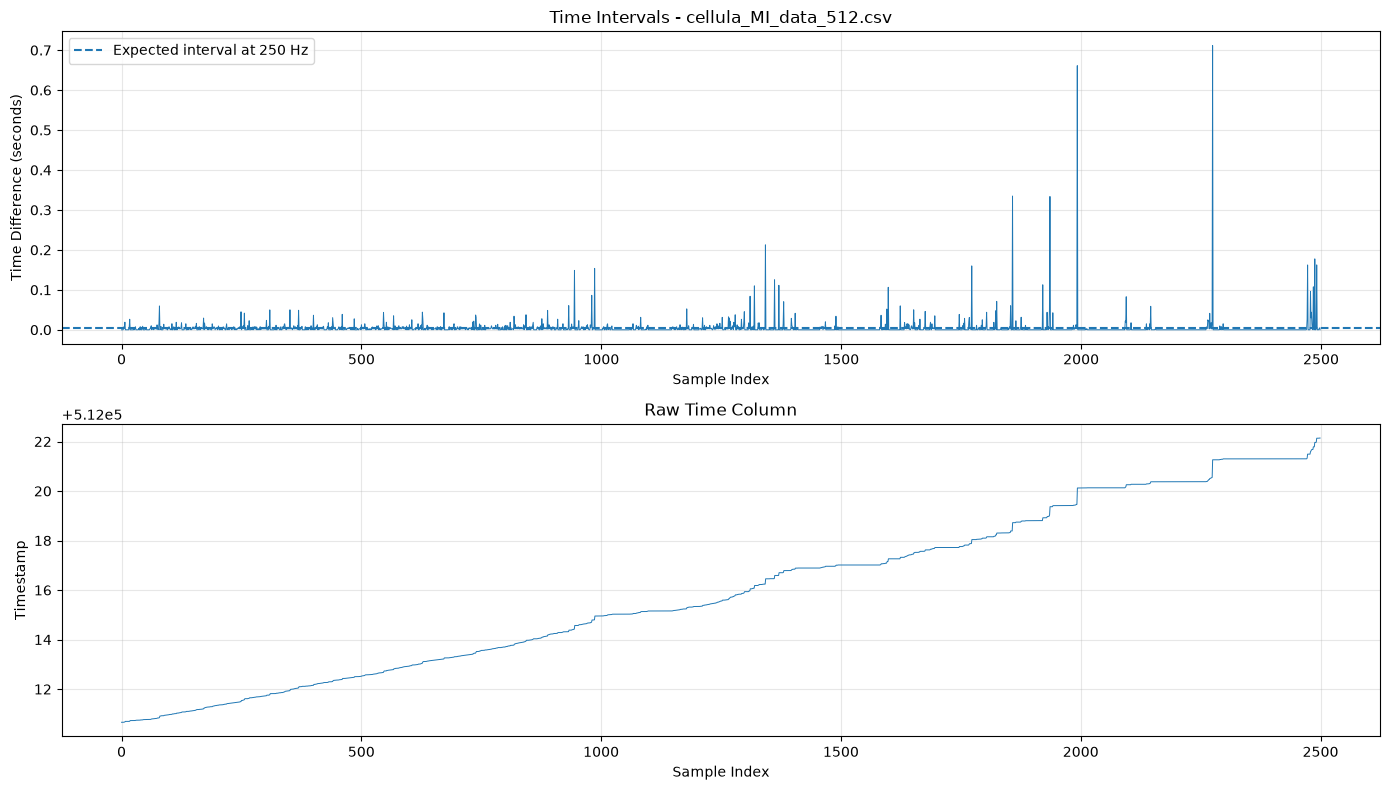

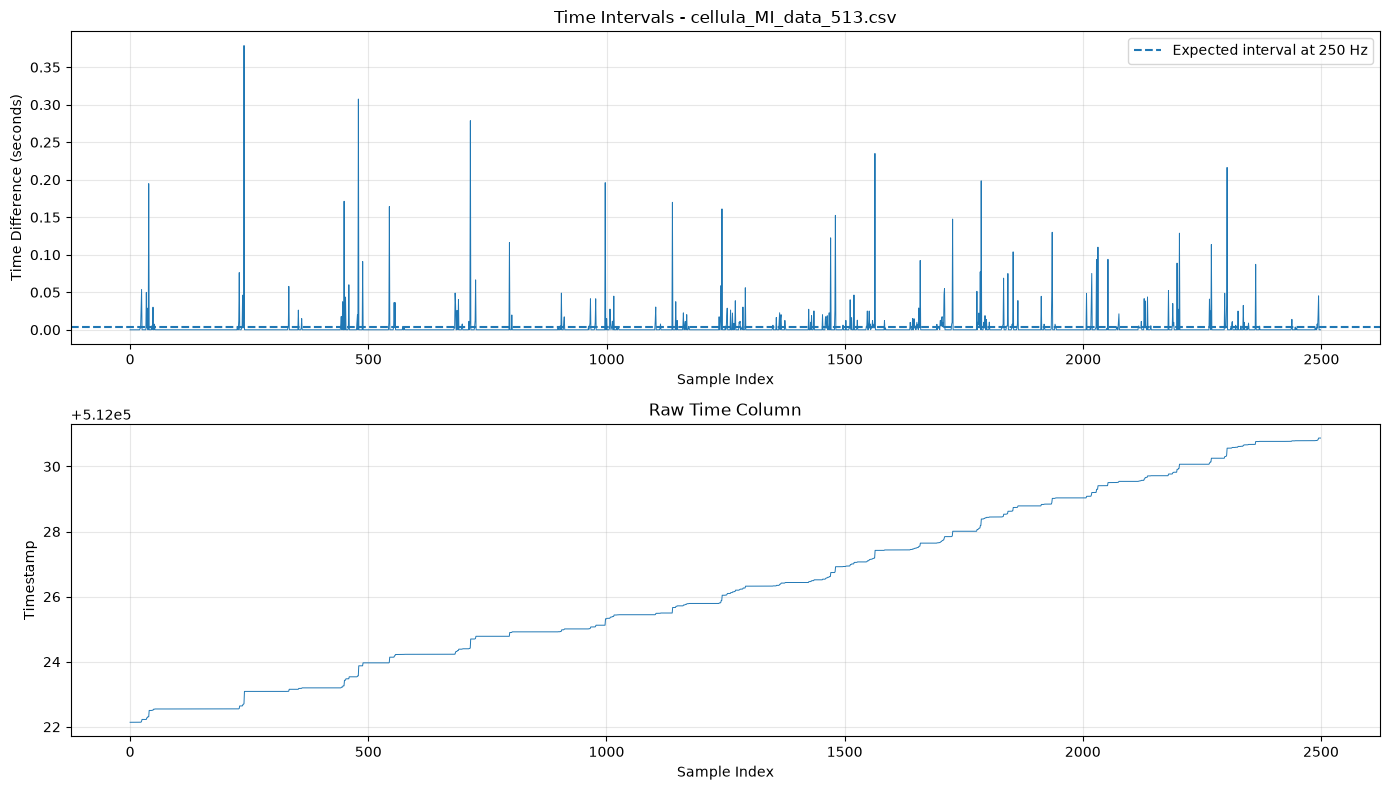

In [24]:
plt.show()

In [25]:
for file_number in [361, 512, 513]:

    file_path = DATA_DIR / f"cellula_MI_data_{file_number}.csv"
    df = pd.read_csv(file_path)

    time = df["Time"].to_numpy()
    intervals = np.diff(time)

    print(f"\nFile {file_number}")
    print("-" * 40)

    print("Total timestamps:", len(time))
    print("Unique timestamps:", len(np.unique(time)))
    print("Repeated timestamps:", len(time) - len(np.unique(time)))

    print("Median interval:", np.median(intervals))
    print("Mean interval:", np.mean(intervals))
    print("25% interval:", np.percentile(intervals, 25))
    print("75% interval:", np.percentile(intervals, 75))

    print("Intervals below 1 ms:", np.sum(intervals < 0.001))
    print("Intervals above 10 ms:", np.sum(intervals > 0.01))


File 361
----------------------------------------
Total timestamps: 2500
Unique timestamps: 2500
Repeated timestamps: 0
Median interval: 0.0011570000788196921
Mean interval: 0.003991037134870085
25% interval: 4.0100072510540485e-05
75% interval: 0.0024482000153511763
Intervals below 1 ms: 981
Intervals above 10 ms: 355

File 512
----------------------------------------
Total timestamps: 2500
Unique timestamps: 2500
Repeated timestamps: 0
Median interval: 1.179997343569994e-05
Mean interval: 0.004593696958777093
25% interval: 1.400010660290718e-06
75% interval: 0.002531699981773272
Intervals below 1 ms: 1546
Intervals above 10 ms: 209

File 513
----------------------------------------
Total timestamps: 2500
Unique timestamps: 2500
Repeated timestamps: 0
Median interval: 1.300009898841381e-06
Mean interval: 0.003494950460193462
25% interval: 1.300009898841381e-06
75% interval: 8.000002708286047e-06
Intervals below 1 ms: 2179
Intervals above 10 ms: 151


In [26]:
for file_number in [361, 512, 513]:

    file_path = DATA_DIR / f"cellula_MI_data_{file_number}.csv"
    df = pd.read_csv(file_path)

    intervals = np.diff(df["Time"].to_numpy())

    print(f"\n{'='*55}")
    print(f"FILE {file_number}")
    print("="*55)

    print("\nFirst 10 rows:")
    display(df.head(10))

    print("\nInterval Quantiles:")
    print(pd.Series(intervals).quantile(
        [0, 0.01, 0.10, 0.25, 0.50, 0.75, 0.90, 0.99, 1]
    ))

    print("\nLargest 5 intervals:")
    largest_indices = np.argsort(intervals)[-5:][::-1]

    for idx in largest_indices:
        print(f"\nIndex: {idx}")
        print(df.iloc[idx:idx+2])
        print("Interval:", intervals[idx])


FILE 361

First 10 rows:


,Time,FZ,C3,CZ,C4
0,915295.592218,288143.40625,284733.87500,313565.31250,296157.59375
1,915295.592233,289945.21875,284993.59375,316527.62500,296647.18750
2,915295.611013,290324.40625,284671.75000,314526.96875,295345.68750
3,915295.611027,288681.37500,284204.15625,310251.00000,294025.31250
4,915295.611029,287397.50000,284257.43750,309661.87500,294523.06250
5,915295.618487,288116.59375,284732.90625,313487.15625,296162.68750
6,915295.618500,289915.28125,284981.96875,316423.28125,296648.68750
7,915295.618502,290261.81250,284646.25000,314377.37500,295323.59375
8,915295.618504,288623.71875,284186.09375,310100.78125,294012.96875
9,915295.619641,287368.34375,284253.06250,309549.50000,294540.84375



Interval Quantiles:
0.00    0.000002
0.01    0.000002
0.10    0.000010
0.25    0.000040
0.50    0.001157
0.75    0.002448
0.90    0.018692
0.99    0.033769
1.00    0.073946
dtype: float64

Largest 5 intervals:

Index: 545
              Time            FZ            C3            CZ            C4
545  915297.743331  288473.31250  284970.53125  314770.34375  296552.78125
546  915297.817277  290964.84375  285318.78125  318973.00000  296984.96875
Interval: 0.07394610007759184

Index: 1002
               Time            FZ            C3            CZ        C4
1002  915299.570833  290014.87500  284477.71875  313217.96875  294869.5
1003  915299.637084  287205.96875  283820.78125  307017.68750  293552.0
Interval: 0.06625070003792644

Index: 1740
               Time           FZ            C3           CZ            C4
1740  915302.520728  289250.0000  285100.53125  315231.3125  296822.34375
1741  915302.580799  290943.5625  285098.12500  316961.6875  296457.71875
Interval: 0.0600714000174775

,Time,FZ,C3,CZ,C4
0,512010.660134,277813.50000,293243.46875,381996.06250,344518.71875
1,512010.660141,278066.71875,293347.34375,381612.68750,343818.40625
2,512010.660155,277785.53125,292980.59375,380866.21875,342719.40625
3,512010.660163,277400.53125,292683.15625,380786.56250,342717.00000
4,512010.660172,277413.15625,292845.31250,381491.28125,343844.59375
5,512010.662240,277802.87500,293233.53125,381986.78125,344519.87500
6,512010.669923,278054.46875,293339.03125,381601.43750,343821.06250
7,512010.677353,277773.00000,292966.84375,380848.18750,342714.93750
8,512010.696344,277389.28125,292671.87500,380765.84375,342703.84375
9,512010.696390,277397.68750,292832.71875,381467.31250,343827.15625



Interval Quantiles:
0.00    3.000023e-07
0.01    1.299952e-06
0.10    1.300010e-06
0.25    1.400011e-06
0.50    1.179997e-05
0.75    2.531700e-03
0.90    7.652380e-03
0.99    5.985528e-02
1.00    7.116052e-01
dtype: float64

Largest 5 intervals:

Index: 2274
               Time            FZ            C3            CZ            C4
2274  512020.549636  277814.59375  292996.78125  379779.21875  341849.75000
2275  512021.261241  277422.09375  292683.68750  379657.00000  341778.21875
Interval: 0.7116051999619231

Index: 1992
               Time            FZ            C3            CZ            C4
1992  512019.460944  277861.96875  293279.12500  381016.71875  343695.90625
1993  512020.122189  278050.15625  293317.03125  380531.03125  342854.59375
Interval: 0.6612447000225075

Index: 1857
               Time            FZ            C3            CZ          C4
1857  512018.387401  277938.93750  293323.84375  381097.53125  343750.625
1858  512018.722313  278072.34375  293310.59375  380

,Time,FZ,C3,CZ,C4
0,512022.139784,277741.53125,293180.5,380771.90625,343544.53125
1,512022.139785,277741.53125,293180.5,380771.90625,343544.53125
2,512022.139786,277741.53125,293180.5,380771.90625,343544.53125
3,512022.139788,277741.53125,293180.5,380771.90625,343544.53125
4,512022.139789,277741.53125,293180.5,380771.90625,343544.53125
5,512022.139790,277741.53125,293180.5,380771.90625,343544.53125
6,512022.139792,277741.53125,293180.5,380771.90625,343544.53125
7,512022.139793,277741.53125,293180.5,380771.90625,343544.53125
8,512022.139794,277741.53125,293180.5,380771.90625,343544.53125
9,512022.139796,277741.53125,293180.5,380771.90625,343544.53125



Interval Quantiles:
0.00    2.000015e-07
0.01    3.000023e-07
0.10    1.299952e-06
0.25    1.300010e-06
0.50    1.300010e-06
0.75    8.000003e-06
0.90    2.594780e-03
0.99    8.887675e-02
1.00    3.788541e-01
dtype: float64

Largest 5 intervals:

Index: 239
              Time            FZ            C3            CZ            C4
239  512022.709605  277939.21875  293134.65625  379757.78125  341940.84375
240  512023.088459  277524.62500  292750.46875  379391.56250  341490.31250
Interval: 0.3788541000103578

Index: 479
              Time            FZ            C3            CZ            C4
479  512023.567354  277982.93750  293161.90625  379713.59375  341956.59375
480  512023.874890  277567.03125  292756.37500  379259.15625  341364.53125
Interval: 0.3075364999822341

Index: 714
              Time           FZ            C3            CZ           C4
714  512024.419795  277994.1875  293227.00000  379692.40625  341999.9375
715  512024.698530  277589.0000  292815.03125  379167.31250  34

In [27]:
labels_df = pd.read_csv(LABELS_PATH)

print("EEG Files:", len(csv_files))
print("Labels:", len(labels_df))

print("\nFirst 15 files:")
print([f.name for f in csv_files[:15]])

print("\nFirst 20 labels:")
display(labels_df.head(20))

print("\nLast 20 labels:")
display(labels_df.tail(20))

print("\nLabel Distribution:")
print(labels_df["label"].value_counts())

EEG Files: 2160
Labels: 2400

First 15 files:
['cellula_MI_data_1.csv', 'cellula_MI_data_2.csv', 'cellula_MI_data_3.csv', 'cellula_MI_data_4.csv', 'cellula_MI_data_5.csv', 'cellula_MI_data_6.csv', 'cellula_MI_data_7.csv', 'cellula_MI_data_8.csv', 'cellula_MI_data_9.csv', 'cellula_MI_data_10.csv', 'cellula_MI_data_11.csv', 'cellula_MI_data_12.csv', 'cellula_MI_data_13.csv', 'cellula_MI_data_14.csv', 'cellula_MI_data_15.csv']

First 20 labels:


,label
0,Left
1,Right
2,Left
3,Left
4,Left
5,Right
6,Right
7,Left
8,Left
9,Right



Last 20 labels:


,label
2380,Left
2381,Left
2382,Right
2383,Right
2384,Left
2385,Right
2386,Right
2387,Right
2388,Right
2389,Right



Label Distribution:
label
Right    1213
Left     1187
Name: count, dtype: int64


In [28]:
for item in PROJECT_DIR.iterdir():
    if item.name != "ML CSV":
        print(item.name, "Folder" if item.is_dir() else "File")

.ipynb_checkpoints Folder
01_Data_Collection_and_Validation.ipynb File
labels.csv File
notebooks Folder
outputs Folder


In [29]:
print("First file:", csv_files[0].name)
print("Last file:", csv_files[-1].name)

print("\nFile numbering check:")
file_numbers = [int(f.stem.split("_")[-1]) for f in csv_files]

print("Minimum:", min(file_numbers))
print("Maximum:", max(file_numbers))
print("Missing file numbers:",
      sorted(set(range(1, max(file_numbers) + 1)) - set(file_numbers)))

print("\nLabels:")
print(labels_df["label"].value_counts())

First file: cellula_MI_data_1.csv
Last file: cellula_MI_data_2160.csv

File numbering check:
Minimum: 1
Maximum: 2160
Missing file numbers: []

Labels:
label
Right    1213
Left     1187
Name: count, dtype: int64


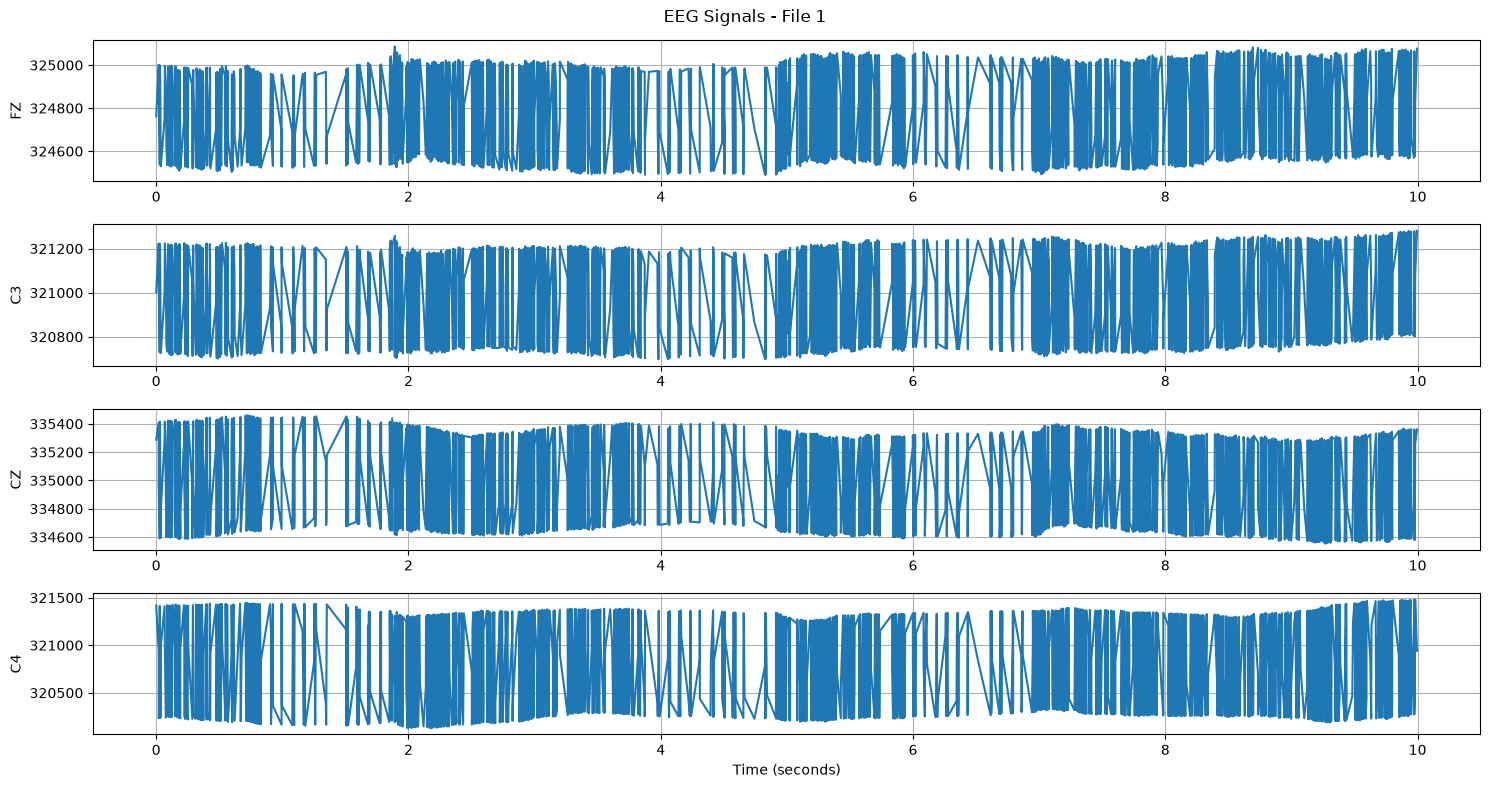

In [30]:
import matplotlib.pyplot as plt

df = pd.read_csv(csv_files[0])

plt.figure(figsize=(15, 8))

for i, channel in enumerate(["FZ", "C3", "CZ", "C4"], 1):
    plt.subplot(4, 1, i)
    plt.plot(df["Time"] - df["Time"].iloc[0], df[channel])
    plt.ylabel(channel)
    plt.grid(True)

plt.xlabel("Time (seconds)")
plt.suptitle("EEG Signals - File 1")
plt.tight_layout()
plt.show()

In [31]:
channels = ["FZ", "C3", "CZ", "C4"]

for channel in channels:
    signal = df[channel]

    print(f"\n{channel}")
    print("Unique values:", signal.nunique())
    print("Minimum:", signal.min())
    print("Maximum:", signal.max())
    print("Standard deviation:", signal.std())
    print("Repeated consecutive values:", (signal.diff() == 0).sum())
    print("Number of large jumps:", (signal.diff().abs() > 100).sum())


FZ
Unique values: 1843
Minimum: 324489.78125
Maximum: 325086.75
Standard deviation: 182.365338188013
Repeated consecutive values: 232
Number of large jumps: 1786

C3
Unique values: 1808
Minimum: 320697.84375
Maximum: 321280.6875
Standard deviation: 181.39679449808486
Repeated consecutive values: 232
Number of large jumps: 1767

CZ
Unique values: 1972
Minimum: 334553.15625
Maximum: 335460.71875
Standard deviation: 281.4359845350275
Repeated consecutive values: 232
Number of large jumps: 1937

C4
Unique values: 2056
Minimum: 320128.6875
Maximum: 321480.0625
Standard deviation: 428.5413415638985
Repeated consecutive values: 232
Number of large jumps: 2067


In [32]:
channels = ["FZ", "C3", "CZ", "C4"]

signal_summary = []

for file in csv_files:
    data = pd.read_csv(file)

    for channel in channels:
        signal_summary.append({
            "file": file.name,
            "channel": channel,
            "mean": data[channel].mean(),
            "std": data[channel].std(),
            "min": data[channel].min(),
            "max": data[channel].max()
        })

signal_summary_df = pd.DataFrame(signal_summary)

display(
    signal_summary_df.groupby("channel")[
        ["mean", "std", "min", "max"]
    ].agg(["mean", "min", "max"]).round(2)
)

mean                            std                         min  \
              mean        min        max     mean    min       max       mean   
channel                                                                         
C3       301785.96  229664.52  372623.05   973.96  15.60  22813.11  299998.90   
C4       326867.92  205977.50  685170.68  1451.77  33.03  18708.33  324314.18   
CZ       334266.65  272369.85  694949.38  2026.85  45.57  48779.70  330713.77   
FZ       298497.90  229802.87  439496.36  1267.55  26.90  12043.98  296445.09   

                                     max                        
               min        max       mean        min        max  
channel                                                         
C3       222394.41  359209.00  303605.23  233407.92  456487.47  
C4       205573.83  671488.38  329389.75  206385.11  710464.38  
CZ       236736.55  676243.50  337631.40  273465.66  710274.38  
FZ       225946.38  420346.12  300553.51  232948.11  456689.25

In [33]:
validation_report = pd.DataFrame({
    "Check": [
        "EEG Files",
        "Samples per File",
        "EEG Channels",
        "Missing Values",
        "Duplicate Rows",
        "Non-numeric Values",
        "Labels Count",
        "Timestamp Status"
    ],
    "Result": [
        "2160",
        "2500",
        "FZ, C3, CZ, C4",
        "None",
        "None",
        "None",
        "2400",
        "Irregular intervals"
    ],
    "Status": [
        "Passed",
        "Passed",
        "Passed",
        "Passed",
        "Passed",
        "Passed",
        "Needs Investigation",
        "Needs Investigation"
    ]
})

validation_report.to_csv(
    OUTPUT_DIR / "data_validation_report.csv",
    index=False
)

print("Validation report saved successfully.")

Validation report saved successfully.


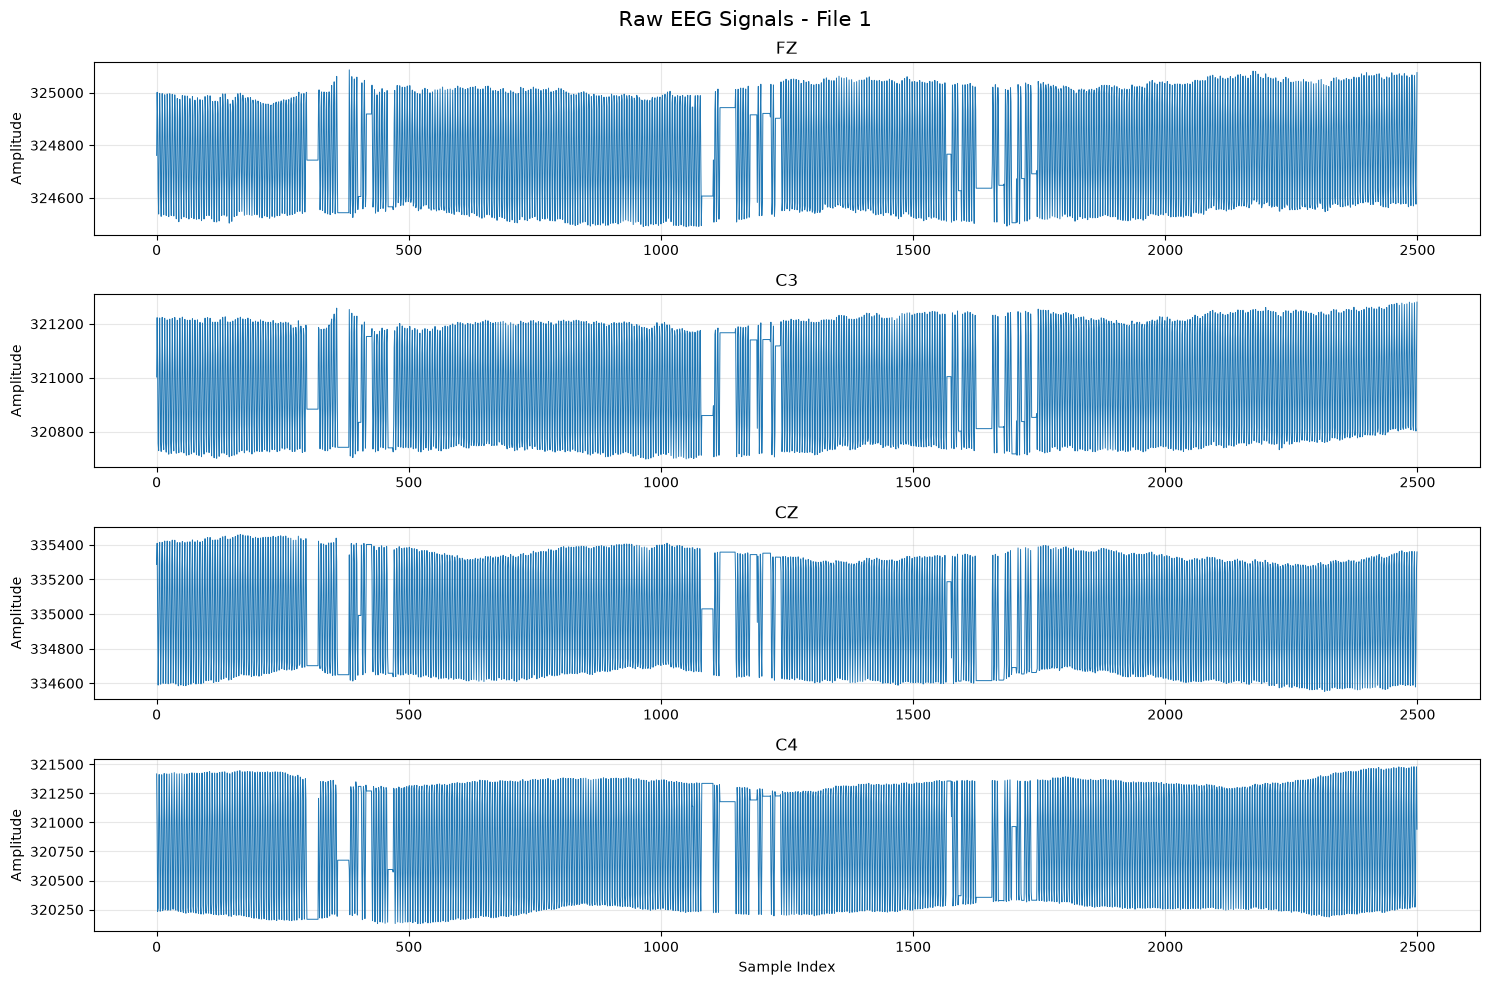

In [34]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv(csv_files[0])

channels = ["FZ", "C3", "CZ", "C4"]

fig, axes = plt.subplots(4, 1, figsize=(15, 10))

for ax, channel in zip(axes, channels):
    ax.plot(df.index, df[channel], linewidth=0.7)
    ax.set_title(channel)
    ax.set_ylabel("Amplitude")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Sample Index")

plt.suptitle("Raw EEG Signals - File 1", fontsize=15)
plt.tight_layout()
plt.show()

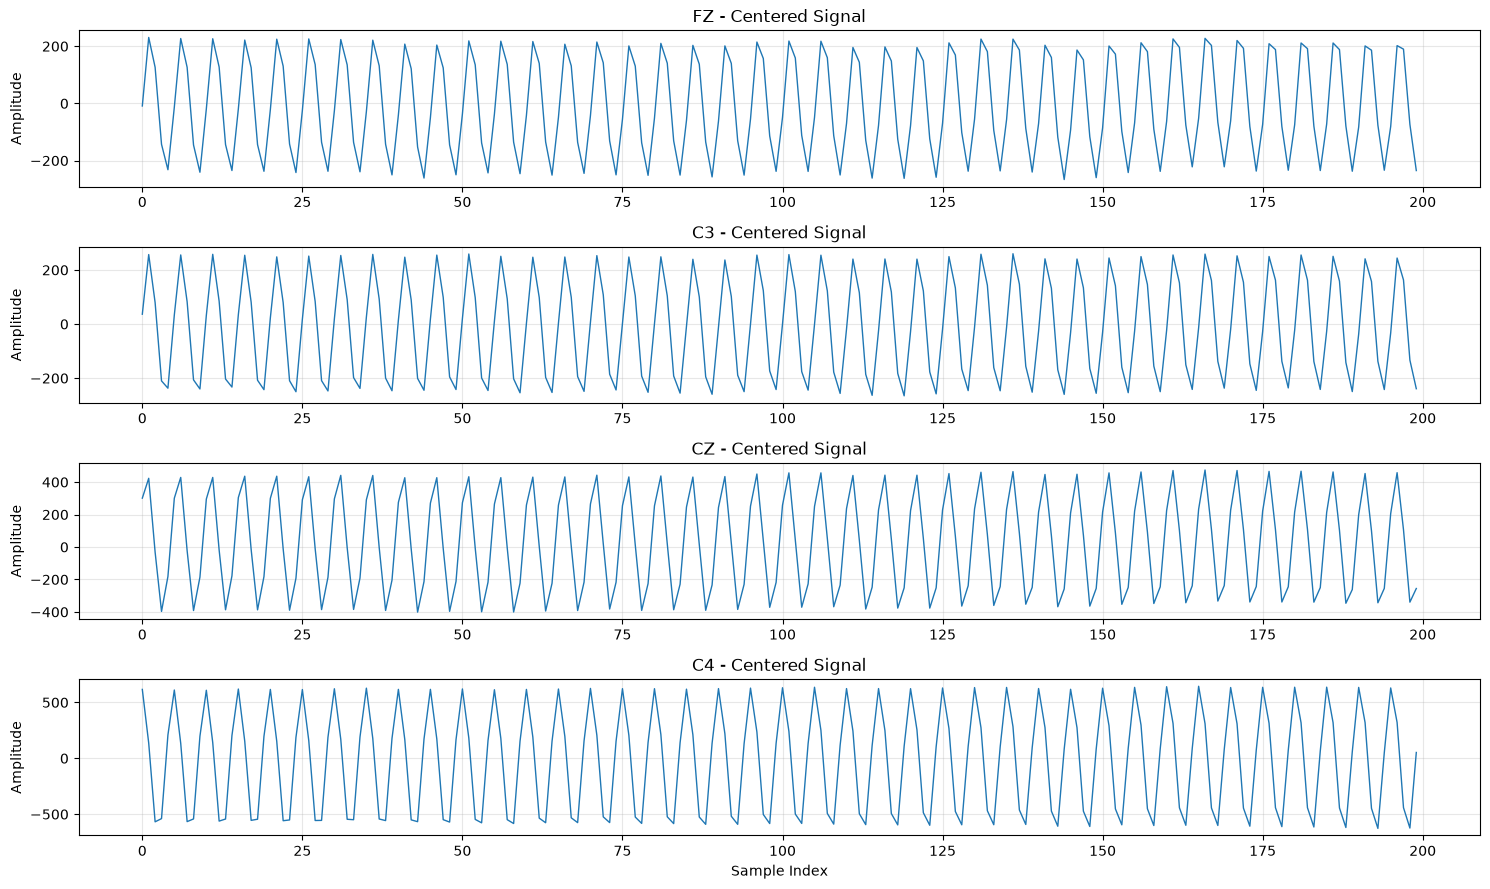

In [35]:
channels = ["FZ", "C3", "CZ", "C4"]

fig, axes = plt.subplots(4, 1, figsize=(15, 9))

for ax, channel in zip(axes, channels):
    signal = df[channel] - df[channel].mean()

    ax.plot(signal.iloc[:200], linewidth=1)
    ax.set_title(f"{channel} - Centered Signal")
    ax.set_ylabel("Amplitude")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Sample Index")

plt.tight_layout()
plt.show()

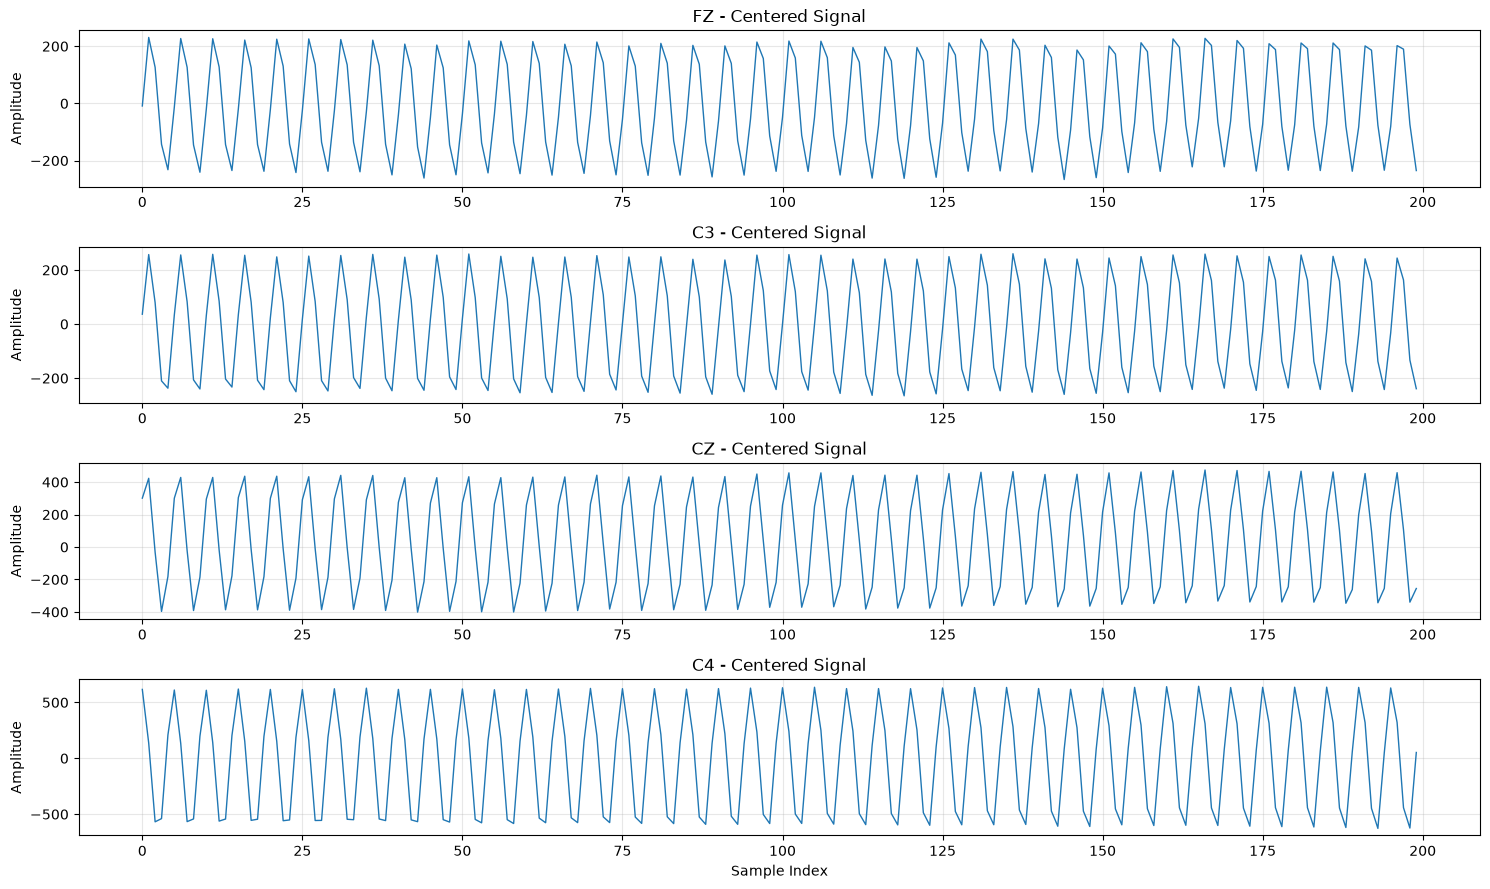

In [36]:
channels = ["FZ", "C3", "CZ", "C4"]

fig, axes = plt.subplots(4, 1, figsize=(15, 9))

for ax, channel in zip(axes, channels):
    signal = df[channel] - df[channel].mean()

    ax.plot(signal.iloc[:200], linewidth=1)
    ax.set_title(f"{channel} - Centered Signal")
    ax.set_ylabel("Amplitude")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Sample Index")

plt.tight_layout()
plt.show()

In [37]:
from scipy.signal import find_peaks

for channel in ["FZ", "C3", "CZ", "C4"]:
    signal = df[channel].iloc[:200].to_numpy()
    signal = signal - signal.mean()

    peaks, _ = find_peaks(signal, prominence=50)

    print(f"\n{channel}")
    print("Number of peaks:", len(peaks))
    print("Average distance:", round(np.diff(peaks).mean(), 2))


FZ
Number of peaks: 40
Average distance: 5.0

C3
Number of peaks: 40
Average distance: 5.0

CZ
Number of peaks: 40
Average distance: 5.0

C4
Number of peaks: 39
Average distance: 5.0


In [43]:
import numpy as np
import pandas as pd
from tqdm import tqdm

channels = ["FZ", "C3", "CZ", "C4"]

X_raw = np.zeros(
    (len(csv_files), 2500, len(channels)),
    dtype=np.float32
)

for i, file in enumerate(tqdm(csv_files)):
    data = pd.read_csv(file)

    X_raw[i] = data[channels].to_numpy(dtype=np.float32)

print("Dataset Shape:", X_raw.shape)
print("Data Type:", X_raw.dtype)
print("Total Values:", X_raw.size)
print("Contains NaN:", np.isnan(X_raw).any())
print("Contains Inf:", np.isinf(X_raw).any())

100%|██████████| 2160/2160 [00:10<00:00, 200.09it/s]

Dataset Shape: (2160, 2500, 4)
Data Type: float32
Total Values: 21600000
Contains NaN: False
Contains Inf: False


In [44]:
np.save(OUTPUT_DIR / "X_raw.npy", X_raw)

file_mapping = pd.DataFrame({
    "trial_index": range(len(csv_files)),
    "file_name": [f.name for f in csv_files]
})

file_mapping.to_csv(
    OUTPUT_DIR / "file_mapping.csv",
    index=False
)

print("Raw EEG dataset saved.")
print("File mapping saved.")

Raw EEG dataset saved.
File mapping saved.


In [46]:
import numpy as np
import pandas as pd

channels = ["FZ", "C3", "CZ", "C4"]

quality_results = []

for trial_idx in range(X_raw.shape[0]):

    for ch_idx, channel in enumerate(channels):

        signal = X_raw[trial_idx, :, ch_idx]

        quality_results.append({
            "trial_index": trial_idx,
            "file_name": file_mapping.loc[trial_idx, "file_name"],
            "channel": channel,
            "mean": np.mean(signal),
            "std": np.std(signal),
            "min": np.min(signal),
            "max": np.max(signal),
            "range": np.ptp(signal)
        })

quality_df = pd.DataFrame(quality_results)

quality_df.to_csv(
    OUTPUT_DIR / "signal_quality_report.csv",
    index=False
)

display(quality_df.head(10))

,trial_index,file_name,channel,mean,std,min,max,range
0,0,cellula_MI_data_1.csv,FZ,324770.34375,182.328857,324489.78125,325086.75000,596.96875
1,0,cellula_MI_data_1.csv,C3,320966.18750,181.360519,320697.84375,321280.68750,582.84375
2,0,cellula_MI_data_1.csv,CZ,334986.25000,281.379700,334553.15625,335460.71875,907.56250
3,0,cellula_MI_data_1.csv,C4,320801.71875,428.455627,320128.68750,321480.06250,1351.37500
4,1,cellula_MI_data_2.csv,FZ,324826.06250,157.600586,324489.93750,325136.00000,646.06250
5,1,cellula_MI_data_2.csv,C3,321048.71875,256.774689,320027.65625,322035.09375,2007.43750
6,1,cellula_MI_data_2.csv,CZ,335001.93750,599.852295,332451.90625,337171.87500,4719.96875
7,1,cellula_MI_data_2.csv,C4,320838.59375,793.845520,317071.84375,323458.62500,6386.78125
8,2,cellula_MI_data_3.csv,FZ,324892.62500,162.078629,324606.18750,325161.65625,555.46875
9,2,cellula_MI_data_3.csv,C3,321150.78125,165.805939,320797.00000,321455.12500,658.12500


In [47]:
display(
    quality_df.groupby("channel")[
        ["mean", "std", "min", "max", "range"]
    ].agg(["mean", "median", "min", "max"]).round(2)
)

mean                                                  std  \
                 mean     median            min           max         mean   
channel                                                                      
C3       301785.96875  302166.33  229664.515625  372623.09375   973.760010   
C4       326867.90625  312669.47  205977.500000  685170.75000  1451.479980   
CZ       334266.65625  320670.05  272369.875000  694949.25000  2026.439941   
FZ       298497.90625  296499.34  229802.859375  439496.40625  1267.300049   

                                                       min             \
             median        min           max          mean     median   
channel                                                                 
C3       503.369995  15.600000  22808.550781  299998.90625  301629.47   
C4       805.929993  33.020000  18704.589844  324314.18750  309818.70   
CZ       919.969971  45.560001  48769.941406  330713.78125  318571.83   
FZ       419.109985  26.889999  12041.570312  296445.09375  295586.95   

                                             max                            \
                   min         max          mean     median            min   
channel                                                                      
C3       222394.406250  359209.000  303605.21875  304524.66  233407.921875   
C4       205573.812500  671488.375  329389.75000  314282.44  206385.093750   
CZ       236736.546875  676243.500  337631.40625  323497.08  273465.656250   
FZ       225946.375000  420346.125  300553.50000  297310.50  232948.093750   

                             range                                          
                  max         mean       median         min            max  
channel                                                                     
C3       456487.46875  3606.330078  1730.119995  102.470001  171541.062500  
C4       710464.37500  5075.569824  2779.840088  151.089996   83765.000000  
CZ       710274.37500  6917.629883  3231.580078  191.500000  186254.234375  
FZ       456689.25000  4108.419922  1568.680054  137.250000   41466.878906

In [48]:
outlier_results = []

for channel in channels:

    channel_data = quality_df[
        quality_df["channel"] == channel
    ].copy()

    for metric in ["std", "range"]:

        Q1 = channel_data[metric].quantile(0.25)
        Q3 = channel_data[metric].quantile(0.75)
        IQR = Q3 - Q1

        upper_limit = Q3 + 1.5 * IQR

        flagged = channel_data[
            channel_data[metric] > upper_limit
        ]

        for _, row in flagged.iterrows():
            outlier_results.append({
                "file_name": row["file_name"],
                "trial_index": row["trial_index"],
                "channel": channel,
                "metric": metric,
                "value": row[metric],
                "upper_limit": upper_limit
            })

outliers_df = pd.DataFrame(outlier_results)

outliers_df.to_csv(
    OUTPUT_DIR / "outlier_trials_report.csv",
    index=False
)

print("Total flagged records:", len(outliers_df))
print("Affected trials:", outliers_df["trial_index"].nunique())

display(outliers_df.head(20))

Total flagged records: 1114
Affected trials: 260


,file_name,trial_index,channel,metric,value,upper_limit
0,cellula_MI_data_460.csv,459,FZ,std,4696.460938,3296.592701
1,cellula_MI_data_461.csv,460,FZ,std,5282.230957,3296.592701
2,cellula_MI_data_462.csv,461,FZ,std,5581.782227,3296.592701
3,cellula_MI_data_463.csv,462,FZ,std,5242.314453,3296.592701
4,cellula_MI_data_464.csv,463,FZ,std,4958.322754,3296.592701
5,cellula_MI_data_465.csv,464,FZ,std,5173.231445,3296.592701
6,cellula_MI_data_466.csv,465,FZ,std,5053.624023,3296.592701
7,cellula_MI_data_467.csv,466,FZ,std,4911.385742,3296.592701
8,cellula_MI_data_468.csv,467,FZ,std,4449.854004,3296.592701
9,cellula_MI_data_469.csv,468,FZ,std,5303.618164,3296.592701


metric,range,std
channel,,
C3,107,92
C4,104,74
CZ,207,206
FZ,171,153


channel
CZ    230
FZ    171
C3    111
C4    104
Name: trial_index, dtype: int64

Affected trial indices:
[np.int64(11), np.int64(63), np.int64(144), np.int64(153), np.int64(162), np.int64(182), np.int64(183), np.int64(225), np.int64(243), np.int64(244), np.int64(292), np.int64(293), np.int64(294), np.int64(297), np.int64(306), np.int64(324), np.int64(325), np.int64(326), np.int64(327), np.int64(328), np.int64(329), np.int64(330), np.int64(331), np.int64(332), np.int64(333), np.int64(334), np.int64(335), np.int64(336), np.int64(337), np.int64(338), np.int64(339), np.int64(340), np.int64(341), np.int64(342), np.int64(343), np.int64(344), np.int64(345), np.int64(346), np.int64(347), np.int64(348), np.int64(349), np.int64(350), np.int64(351), np.int64(360), np.int64(369), np.int64(375), np.int64(447), np.int64(459), np.int64(460), np.int64(461), np.int64(462), np.int64(463), np.int64(464), np.int64(465), np.int64(466), np.int64(467), np.int64(468), np.int64(469), np.int64(470), np.int64(471), np.int64(472), np.int64(473), np.int64(474), np.int64(475), np.int64(476), np

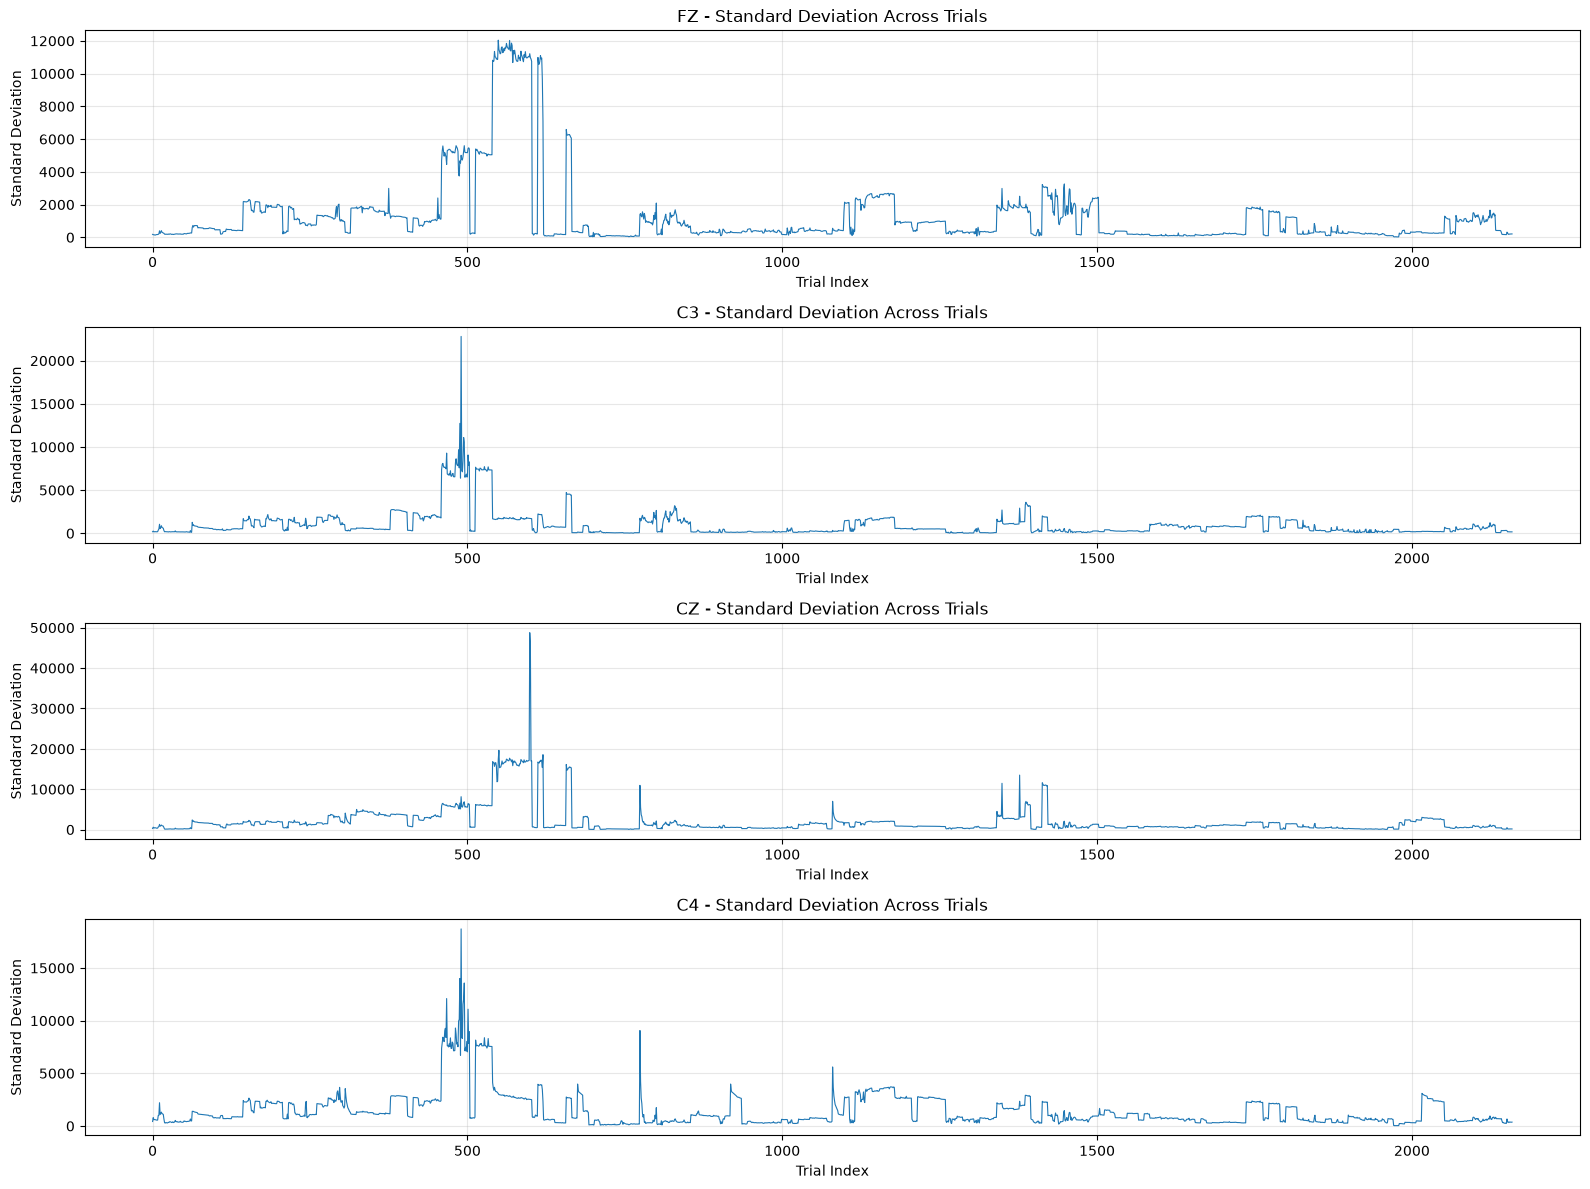

In [49]:
# 1. عدد القيم الشاذة حسب القناة ونوع القياس
display(
    outliers_df.groupby(["channel", "metric"])
    .size()
    .unstack(fill_value=0)
)

# 2. عدد التجارب المتأثرة في كل قناة
display(
    outliers_df.groupby("channel")["trial_index"]
    .nunique()
    .sort_values(ascending=False)
)

# 3. ترتيب التجارب المتأثرة
affected_trials = sorted(
    outliers_df["trial_index"].unique()
)

print("Affected trial indices:")
print(affected_trials)

# 4. رسم التغير في Standard Deviation لكل قناة
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 1, figsize=(16, 12))

for ax, channel in zip(axes, channels):

    channel_data = quality_df[
        quality_df["channel"] == channel
    ].sort_values("trial_index")

    ax.plot(
        channel_data["trial_index"],
        channel_data["std"],
        linewidth=0.8
    )

    ax.set_title(f"{channel} - Standard Deviation Across Trials")
    ax.set_xlabel("Trial Index")
    ax.set_ylabel("Standard Deviation")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

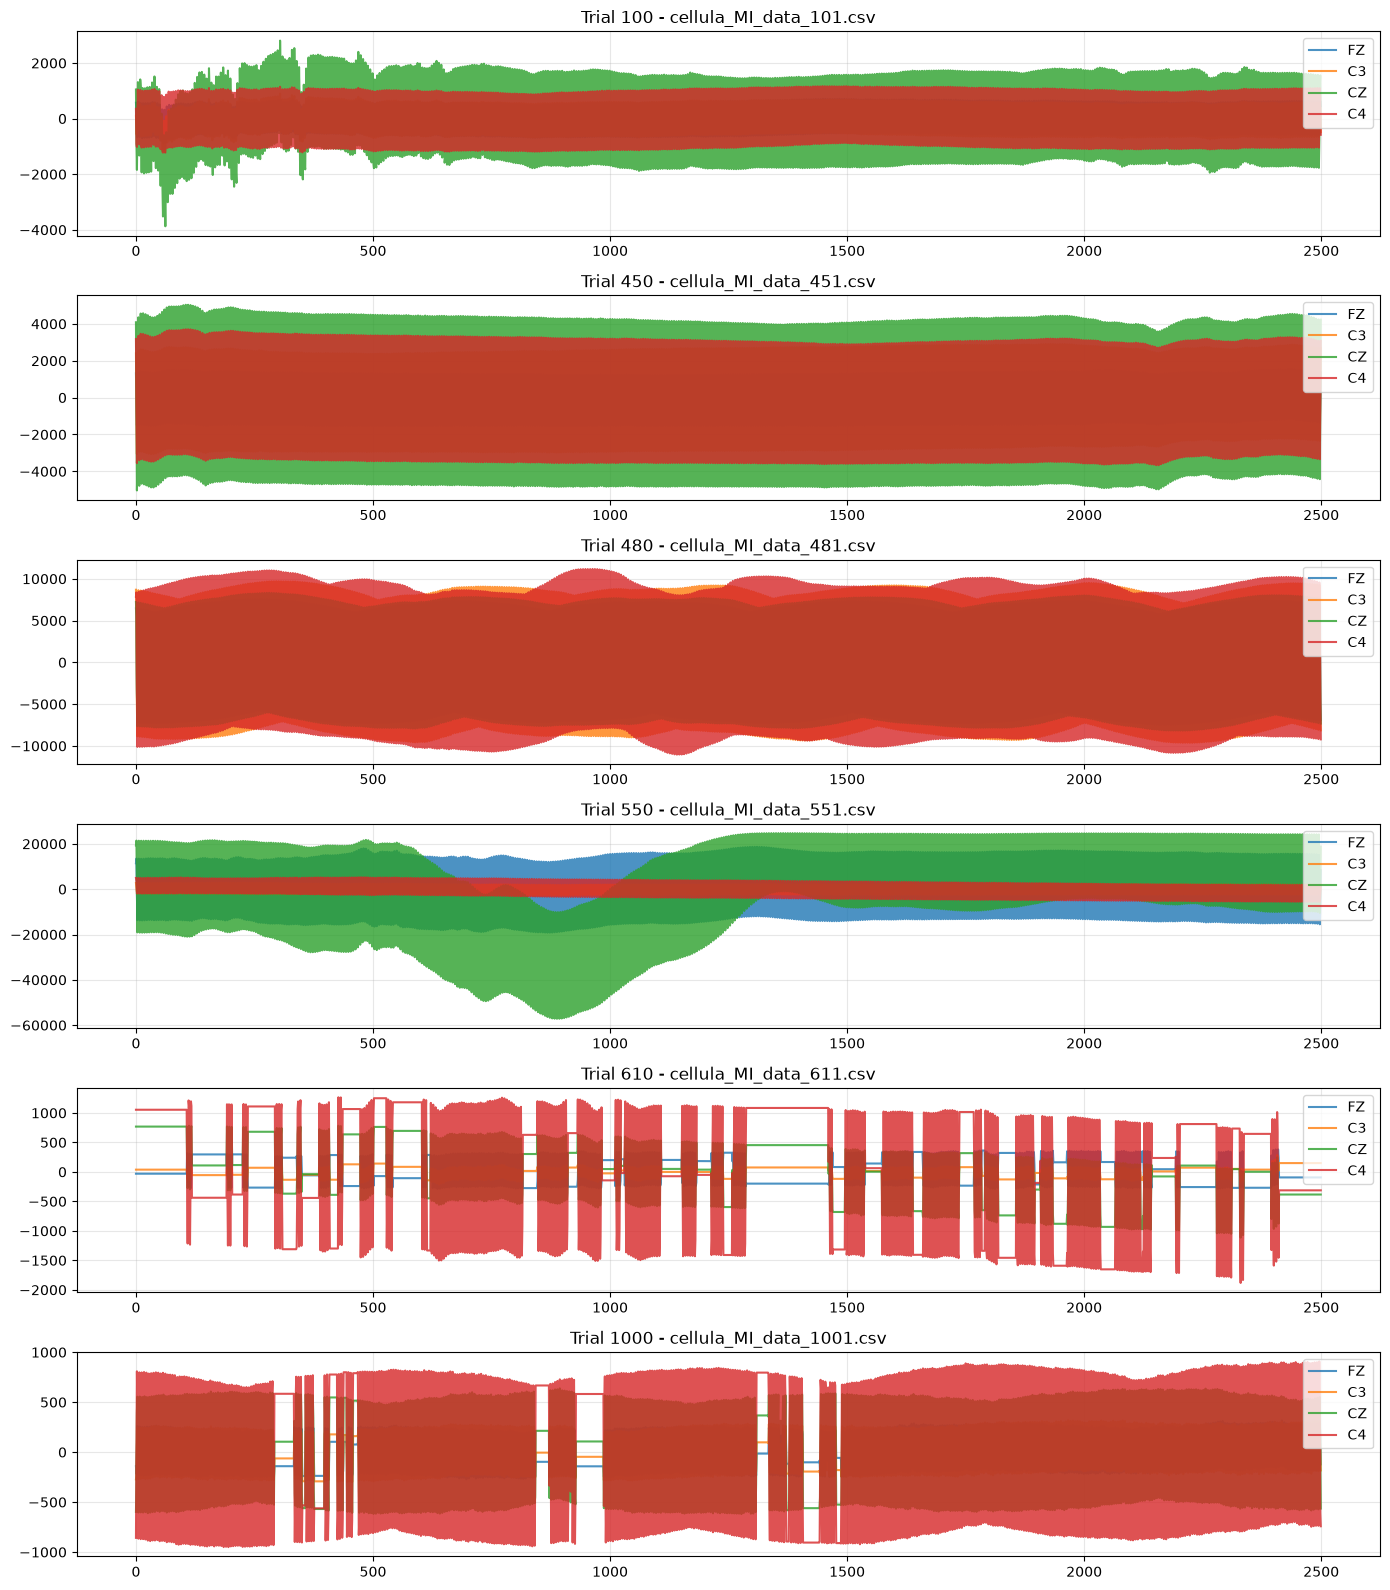

In [50]:
import matplotlib.pyplot as plt
import pandas as pd

channels = ["FZ", "C3", "CZ", "C4"]

# Trials هنفحصها للمقارنة
trial_indices = [100, 450, 480, 550, 610, 1000]

fig, axes = plt.subplots(
    len(trial_indices), 1,
    figsize=(14, 16)
)

for ax, trial_idx in zip(axes, trial_indices):
    file_path = csv_files[trial_idx]
    df = pd.read_csv(file_path)

    for channel in channels:
        signal = df[channel] - df[channel].mean()
        ax.plot(signal.values, label=channel, alpha=0.8)

    ax.set_title(f"Trial {trial_idx} - {file_path.name}")
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

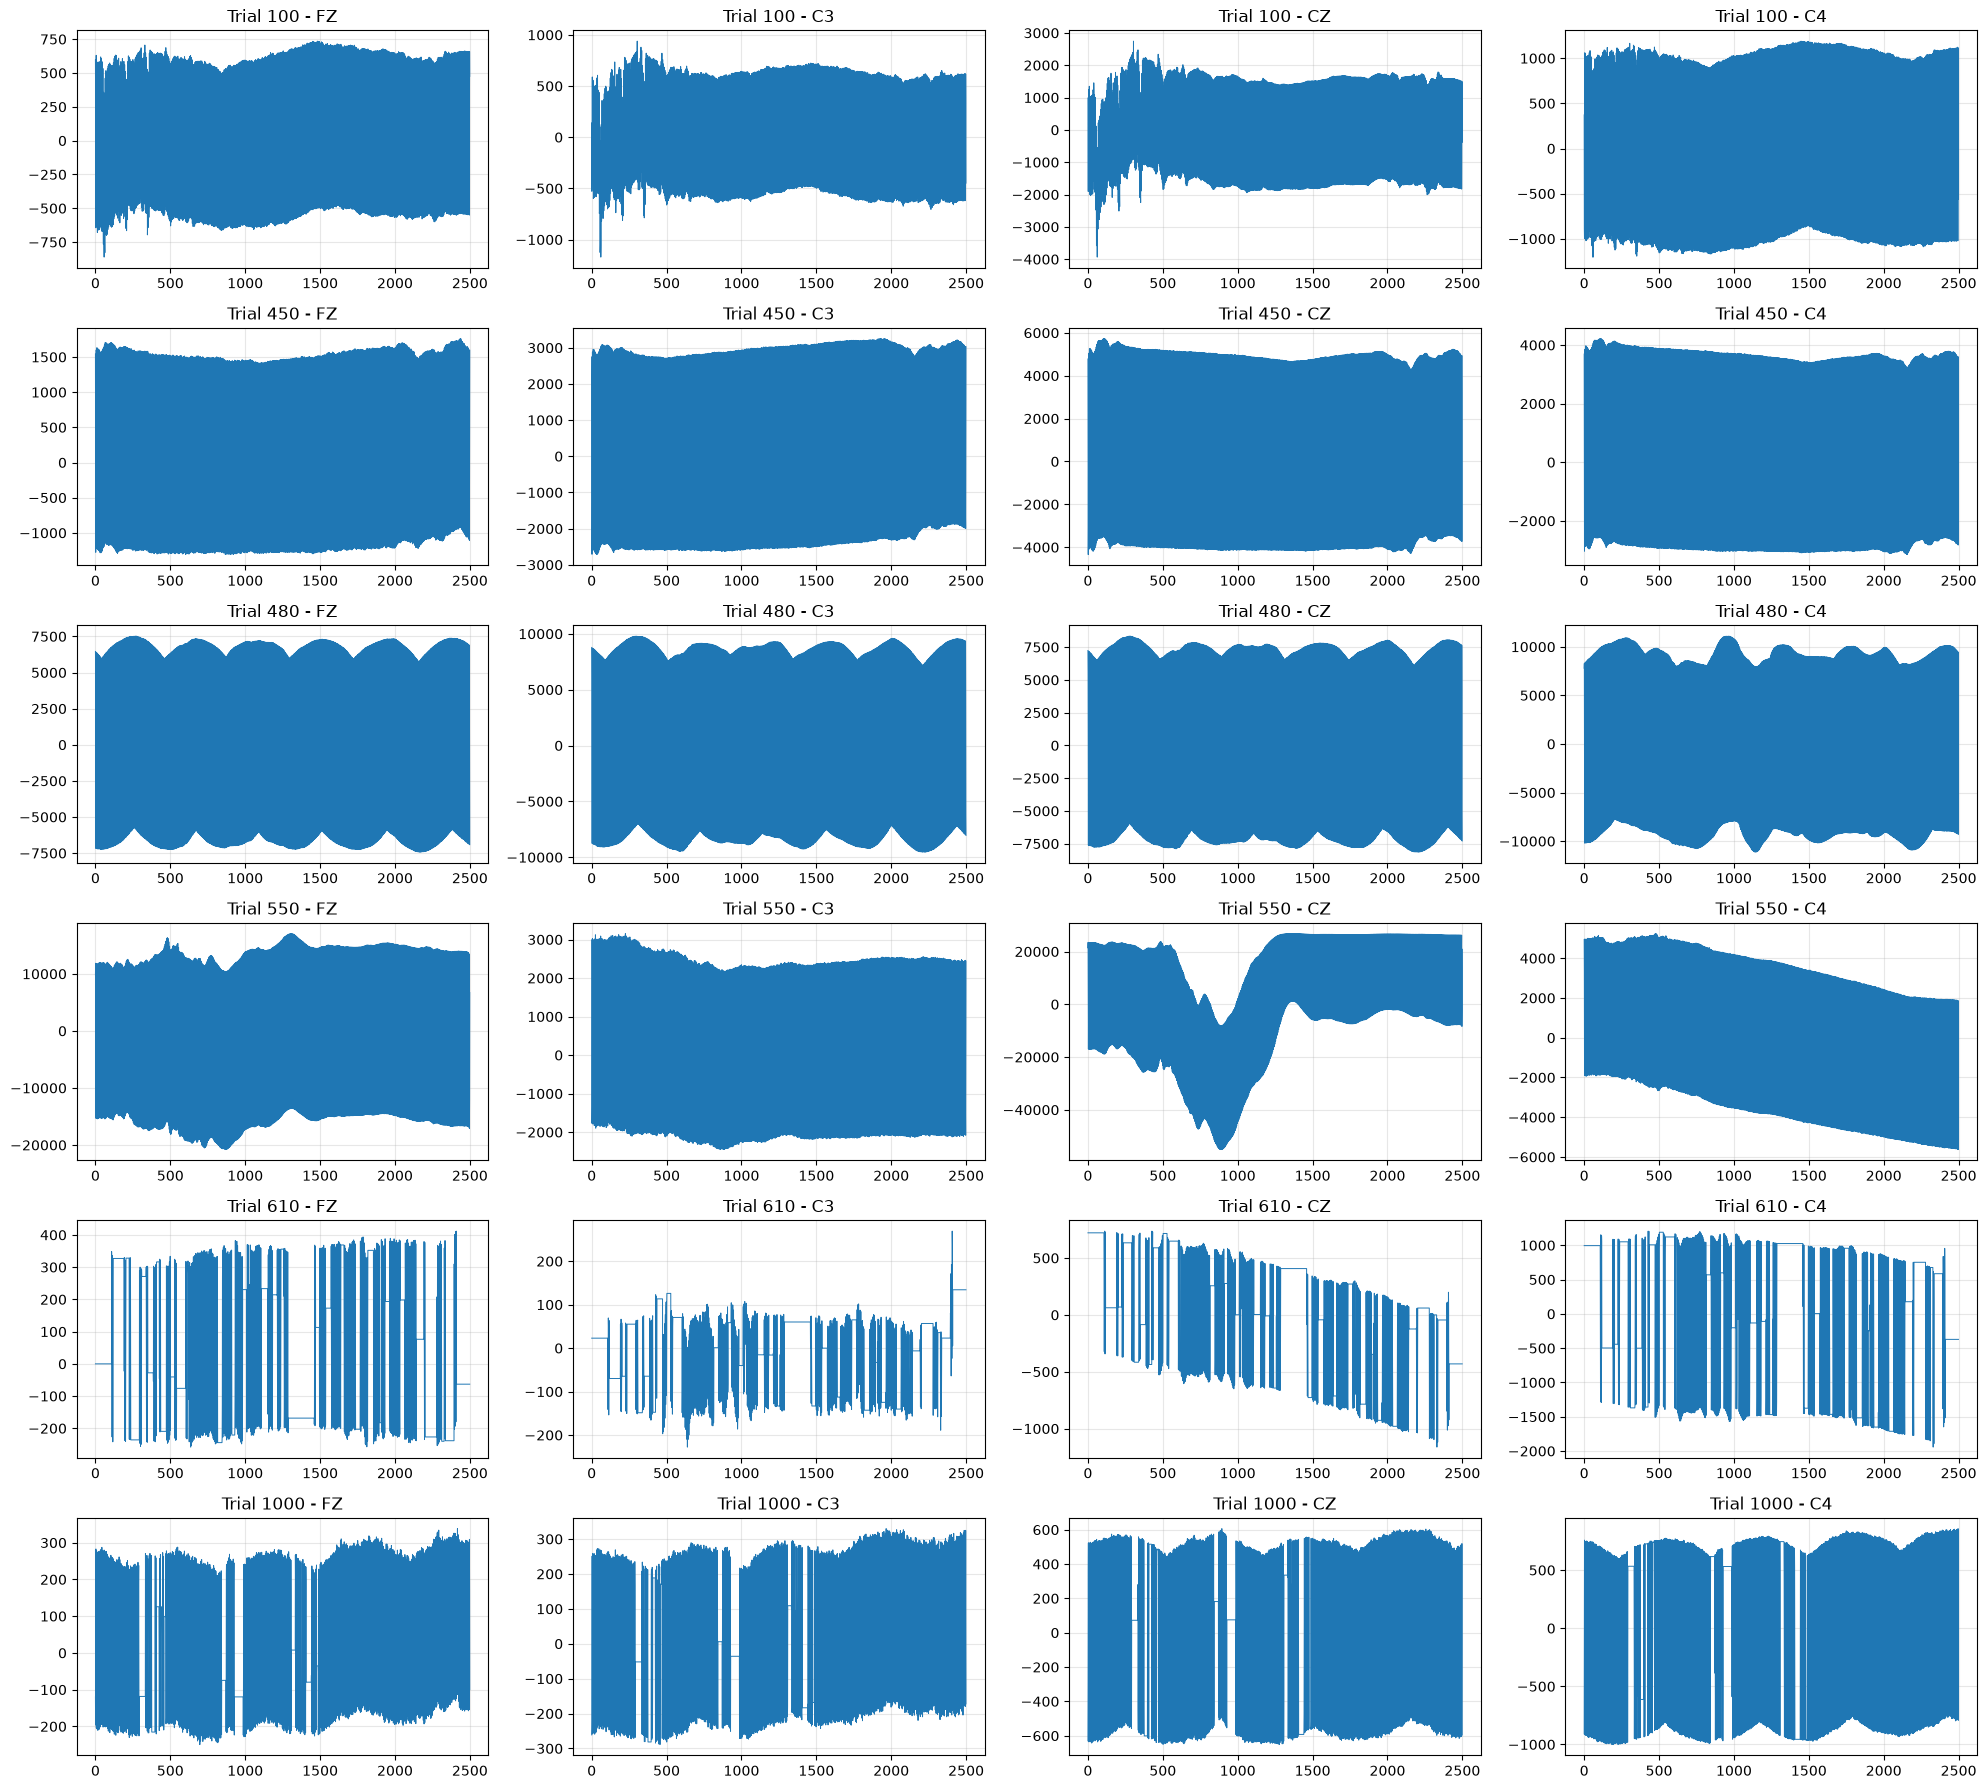

In [51]:
import matplotlib.pyplot as plt
import pandas as pd

channels = ["FZ", "C3", "CZ", "C4"]
trial_indices = [100, 450, 480, 550, 610, 1000]

fig, axes = plt.subplots(
    len(trial_indices), 4,
    figsize=(20, 18)
)

for row, trial_idx in enumerate(trial_indices):

    df = pd.read_csv(csv_files[trial_idx])

    for col, channel in enumerate(channels):

        signal = df[channel] - df[channel].median()

        axes[row, col].plot(signal, linewidth=0.7)
        axes[row, col].set_title(
            f"Trial {trial_idx} - {channel}"
        )
        axes[row, col].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [52]:
import pandas as pd
import numpy as np

trial_indices = [100, 450, 480, 550, 610, 1000]
channels = ["FZ", "C3", "CZ", "C4"]

results = []

for trial_idx in trial_indices:

    df = pd.read_csv(csv_files[trial_idx])

    for channel in channels:

        signal = df[channel].to_numpy()
        differences = np.abs(np.diff(signal))

        results.append({
            "trial": trial_idx,
            "channel": channel,
            "min": np.min(signal),
            "max": np.max(signal),
            "std": np.std(signal),
            "range": np.ptp(signal),
            "median_abs_change": np.median(differences),
            "max_jump": np.max(differences),
            "repeated_values": np.sum(differences == 0),
            "large_jumps": np.sum(
                differences > np.percentile(differences, 99)
            )
        })

comparison_df = pd.DataFrame(results)

display(comparison_df.round(2))

,trial,channel,min,max,std,range,median_abs_change,max_jump,repeated_values,large_jumps
0,100,FZ,295230.09,296826.19,456.30,1596.09,524.03,801.53,0,25
1,100,C3,299310.53,301420.44,465.16,2109.91,550.28,817.09,1,24
2,100,CZ,323756.38,330435.41,1272.55,6679.03,1478.34,2305.19,0,25
3,100,C4,295874.44,298266.88,797.27,2392.44,940.81,1352.44,0,24
4,450,FZ,310447.16,313517.22,1048.99,3070.06,1271.19,1798.41,0,25
5,450,C3,310717.25,316687.50,2050.69,5970.25,2363.75,3462.28,0,25
6,450,CZ,311106.16,321174.56,3401.41,10068.41,4060.16,5846.94,0,25
7,450,C4,308989.19,316360.34,2511.33,7371.16,2932.09,4274.62,0,25
8,480,FZ,333128.81,348078.00,5157.58,14949.19,6050.97,8637.44,0,25
9,480,C3,358115.81,377443.19,6543.88,19327.38,7642.59,10983.00,0,25


In [53]:
import pandas as pd
import numpy as np

trial_idx = 610
df = pd.read_csv(csv_files[trial_idx])

channels = ["FZ", "C3", "CZ", "C4"]

for channel in channels:
    signal = df[channel].to_numpy()

    repeated = np.diff(signal) == 0

    # أطول سلسلة من القيم المتطابقة
    groups = np.split(
        np.arange(len(signal)),
        np.where(np.diff(signal) != 0)[0] + 1
    )

    longest_run = max(len(group) for group in groups)

    print(f"\n{channel}")
    print("Unique values:", len(np.unique(signal)))
    print("Repeated consecutive samples:", repeated.sum())
    print("Longest constant run:", longest_run)



FZ
Unique values: 1049
Repeated consecutive samples: 1329
Longest constant run: 174

C3
Unique values: 969
Repeated consecutive samples: 1329
Longest constant run: 174

CZ
Unique values: 1128
Repeated consecutive samples: 1329
Longest constant run: 174

C4
Unique values: 1126
Repeated consecutive samples: 1329
Longest constant run: 174


In [54]:
file_path = DATA_DIR / "cellula_MI_data_611.csv"
df = pd.read_csv(file_path)

channels = ["FZ", "C3", "CZ", "C4"]

# الصفوف اللي الأربع قنوات فيها مطابقة للصف السابق
same_rows = df[channels].eq(df[channels].shift()).all(axis=1)

# استخراج أماكن التكرار
repeat_indices = np.where(same_rows)[0]

print("Total repeated rows across all channels:", len(repeat_indices))
print("First 30 repeated indices:")
print(repeat_indices[:30])

# عرض العينات والتوقيتات المحيطة بأول تكرارات
for idx in repeat_indices[:10]:
    print(f"\nIndex: {idx}")
    display(df.iloc[max(0, idx-1):idx+2])

Total repeated rows across all channels: 1329
First 30 repeated indices:
[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30]

Index: 1


,Time,FZ,C3,CZ,C4
0,512128.309982,277932.875,293162.1875,369592.28125,334856.875
1,512128.309983,277932.875,293162.1875,369592.28125,334856.875
2,512128.309985,277932.875,293162.1875,369592.28125,334856.875



Index: 2


,Time,FZ,C3,CZ,C4
1,512128.309983,277932.875,293162.1875,369592.28125,334856.875
2,512128.309985,277932.875,293162.1875,369592.28125,334856.875
3,512128.309986,277932.875,293162.1875,369592.28125,334856.875



Index: 3


,Time,FZ,C3,CZ,C4
2,512128.309985,277932.875,293162.1875,369592.28125,334856.875
3,512128.309986,277932.875,293162.1875,369592.28125,334856.875
4,512128.309987,277932.875,293162.1875,369592.28125,334856.875


... (10 outputs left out)


Index: 9


,Time,FZ,C3,CZ,C4
8,512128.309992,277932.875,293162.1875,369592.28125,334856.875
9,512128.309994,277932.875,293162.1875,369592.28125,334856.875
10,512128.309995,277932.875,293162.1875,369592.28125,334856.875



Index: 10


,Time,FZ,C3,CZ,C4
9,512128.309994,277932.875,293162.1875,369592.28125,334856.875
10,512128.309995,277932.875,293162.1875,369592.28125,334856.875
11,512128.309996,277932.875,293162.1875,369592.28125,334856.875


In [55]:
file_path = DATA_DIR / "cellula_MI_data_611.csv"

df = pd.read_csv(file_path)

channels = ["FZ", "C3", "CZ", "C4"]

# Check where all EEG channels remain unchanged
same_signal = df[channels].eq(df[channels].shift()).all(axis=1)

# Find consecutive repeated regions
groups = same_signal.ne(same_signal.shift()).cumsum()

repeated_regions = (
    df[same_signal]
    .assign(group=groups[same_signal])
    .groupby("group")
    .agg(
        start_index=("Time", lambda x: x.index.min()),
        end_index=("Time", lambda x: x.index.max()),
        samples=("Time", "size"),
        start_time=("Time", "min"),
        end_time=("Time", "max")
    )
    .sort_values("samples", ascending=False)
)

display(repeated_regions.head(10))

,start_index,end_index,samples,start_time,end_time
group,,,,,
40,1288,1460,173,512132.958556,512132.958788
2,1,107,107,512128.309983,512128.310123
70,2412,2499,88,512137.339666,512137.339792
64,2203,2279,77,512136.708490,512136.708599
4,119,191,73,512128.429714,512128.429809
20,543,603,61,512129.313564,512129.313645
68,2338,2394,57,512137.162173,512137.162246
8,237,293,57,512128.541040,512128.541115
62,2144,2192,49,512136.454832,512136.454897


In [56]:
start = 1283
end = 1465

display(
    df.loc[start:end, ["Time", "FZ", "C3", "CZ", "C4"]]
)

,Time,FZ,C3,CZ,C4
1283,512132.923447,278132.68750,293125.81250,368853.50000,333786.46875
1284,512132.928418,278279.50000,292997.50000,368208.25000,332381.71875
1285,512132.938351,278013.06250,292996.43750,368219.62500,332586.09375
1286,512132.945999,277718.90625,293135.37500,368873.81250,334090.65625
1287,512132.953500,277764.53125,293199.37500,369278.03125,334887.18750
...,...,...,...,...,...
1461,512132.958789,277745.46875,293139.56250,368788.25000,333969.31250
1462,512132.963386,277757.90625,293212.53125,369231.87500,334867.40625
1463,512132.969593,278116.34375,293138.59375,368849.03125,333864.28125
1464,512132.969598,278301.21875,293026.18750,368198.34375,332412.65625


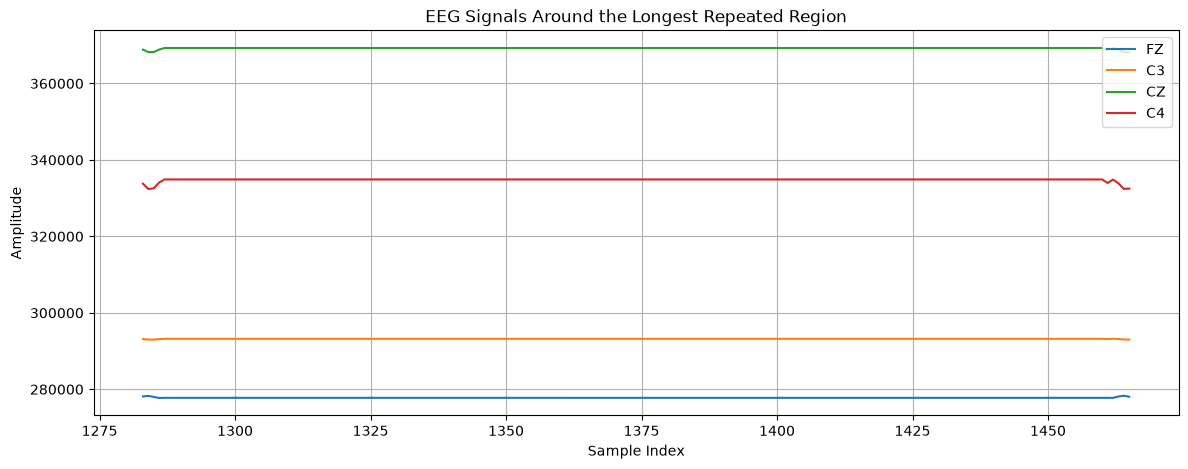

In [57]:
plt.figure(figsize=(14, 5))

for channel in channels:
    plt.plot(
        df.loc[start:end].index,
        df.loc[start:end, channel],
        label=channel
    )

plt.title("EEG Signals Around the Longest Repeated Region")
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()

In [58]:
repeated_summary = []

channels = ["FZ", "C3", "CZ", "C4"]

for file in tqdm(csv_files):

    df = pd.read_csv(file)

    # Check consecutive identical EEG readings across all channels
    same_signal = df[channels].eq(df[channels].shift()).all(axis=1)

    # Find consecutive repeated regions
    groups = same_signal.ne(same_signal.shift()).cumsum()

    repeated_runs = (
        same_signal[same_signal]
        .groupby(groups[same_signal])
        .size()
    )

    longest_run = repeated_runs.max() + 1 if len(repeated_runs) else 1

    repeated_summary.append({
        "file_name": file.name,
        "trial_index": int(file.stem.split("_")[-1]) - 1,
        "repeated_samples": int(same_signal.sum()),
        "longest_constant_run": int(longest_run)
    })

repeated_summary_df = pd.DataFrame(repeated_summary)

display(
    repeated_summary_df
    .sort_values("longest_constant_run", ascending=False)
    .head(20)
)

print("Trials with runs >= 10 samples:",
      (repeated_summary_df["longest_constant_run"] >= 10).sum())

print("Trials with runs >= 50 samples:",
      (repeated_summary_df["longest_constant_run"] >= 50).sum())

print("Maximum constant run:",
      repeated_summary_df["longest_constant_run"].max())

100%|██████████| 2160/2160 [00:22<00:00, 94.70it/s] 


,file_name,trial_index,repeated_samples,longest_constant_run
246,cellula_MI_data_247.csv,246,499,307
510,cellula_MI_data_511.csv,510,1013,277
504,cellula_MI_data_505.csv,504,1772,277
605,cellula_MI_data_606.csv,605,1914,258
590,cellula_MI_data_591.csv,590,1038,247
611,cellula_MI_data_612.csv,611,1446,200
506,cellula_MI_data_507.csv,506,1172,196
603,cellula_MI_data_604.csv,603,1817,195
608,cellula_MI_data_609.csv,608,1373,180
511,cellula_MI_data_512.csv,511,801,174


Trials with runs >= 10 samples: 423
Trials with runs >= 50 samples: 133
Maximum constant run: 307


In [59]:
repeated_summary_df["repeated_percentage"] = (
    repeated_summary_df["repeated_samples"] / 2499 * 100
)

repeated_summary_df["quality_category"] = pd.cut(
    repeated_summary_df["repeated_percentage"],
    bins=[-1, 1, 5, 20, 50, 100],
    labels=[
        "Very Low",
        "Low",
        "Moderate",
        "High",
        "Very High"
    ]
)

print("Repeated Samples Percentage Statistics:")
display(
    repeated_summary_df["repeated_percentage"]
    .describe()
    .round(2)
)

print("\nTrials by Repetition Category:")
display(
    repeated_summary_df["quality_category"]
    .value_counts()
    .to_frame("Number of Trials")
)

print("\nTop 15 Trials by Repeated Percentage:")
display(
    repeated_summary_df
    .sort_values("repeated_percentage", ascending=False)
    .head(15)
)

Repeated Samples Percentage Statistics:


count    2160.00
mean        2.12
std         7.99
min         0.00
25%         0.00
50%         0.00
75%         0.00
max        76.59
Name: repeated_percentage, dtype: float64


Trials by Repetition Category:


,Number of Trials
quality_category,
Very Low,1747
Moderate,189
Low,184
Very High,22
High,18



Top 15 Trials by Repeated Percentage:


,file_name,trial_index,repeated_samples,longest_constant_run,repeated_percentage,quality_category
605,cellula_MI_data_606.csv,605,1914,258,76.590636,Very High
301,cellula_MI_data_302.csv,301,1908,88,76.350540,Very High
299,cellula_MI_data_300.csv,299,1890,102,75.630252,Very High
305,cellula_MI_data_306.csv,305,1885,135,75.430172,Very High
302,cellula_MI_data_303.csv,302,1863,132,74.549820,Very High
304,cellula_MI_data_305.csv,304,1863,93,74.549820,Very High
297,cellula_MI_data_298.csv,297,1822,100,72.909164,Very High
300,cellula_MI_data_301.csv,300,1820,96,72.829132,Very High
603,cellula_MI_data_604.csv,603,1817,195,72.709084,Very High
298,cellula_MI_data_299.csv,298,1809,111,72.388956,Very High


In [60]:
files_to_check = [
    "cellula_MI_data_606.csv",
    "cellula_MI_data_302.csv"
]

channels = ["FZ", "C3", "CZ", "C4"]

for file_name in files_to_check:

    df = pd.read_csv(DATA_DIR / file_name)

    same_signal = df[channels].eq(df[channels].shift()).all(axis=1)

    groups = same_signal.ne(same_signal.shift()).cumsum()

    regions = (
        pd.DataFrame({
            "group": groups,
            "is_repeated": same_signal,
            "Time": df["Time"]
        })
        .query("is_repeated")
        .groupby("group")
        .agg(
            start_index=("Time", lambda x: x.index.min()),
            end_index=("Time", lambda x: x.index.max()),
            repeated_samples=("Time", "size"),
            start_time=("Time", "min"),
            end_time=("Time", "max")
        )
        .sort_values("repeated_samples", ascending=False)
    )

    print(f"\n{file_name}")
    display(regions.head(10))


cellula_MI_data_606.csv


,start_index,end_index,repeated_samples,start_time,end_time
group,,,,,
38,1460,1716,257,512084.672748,512084.672818
30,1006,1170,165,512082.401712,512082.401931
16,421,584,164,512080.490424,512080.490646
32,1201,1326,126,512083.742757,512083.742800
40,1727,1844,118,512084.821714,512084.821843
50,2108,2219,112,512086.178830,512086.178976
26,842,941,100,512082.102734,512082.102865
20,637,736,100,512080.943184,512080.943318
8,200,287,88,512079.169288,512079.169402



cellula_MI_data_302.csv


,start_index,end_index,repeated_samples,start_time,end_time
group,,,,,
10,296,382,87,89484.819691,89484.819735
80,2102,2186,85,89491.912305,89491.912326
6,150,232,83,89484.239874,89484.240008
86,2305,2376,72,89492.512138,89492.512179
4,72,139,68,89484.008590,89484.008685
30,773,834,62,89486.554687,89486.554774
68,1749,1809,61,89490.408169,89490.408271
22,600,660,61,89485.907371,89485.907409
72,1875,1935,61,89491.109595,89491.109615


In [61]:
file_path = DATA_DIR / "cellula_MI_data_606.csv"
df = pd.read_csv(file_path)

start = 1460
end = 1716

# Inspect timestamps and EEG values around the repeated region
inspection = df.loc[start-3:end+3, ["Time", "FZ", "C3", "CZ", "C4"]].copy()

# Calculate timestamp differences
inspection["time_diff"] = inspection["Time"].diff()

display(inspection.head(8))
display(inspection.tail(8))

# Analyze intervals inside the repeated region
region_intervals = df.loc[start:end, "Time"].diff().dropna()

print("Timestamp interval statistics inside repeated region:")
display(region_intervals.describe())

print("Intervals below 0.1 ms:",
      (region_intervals < 0.0001).sum())

print("Intervals between 1 and 5 ms:",
      region_intervals.between(0.001, 0.005).sum())

,Time,FZ,C3,CZ,C4,time_diff
1457,512084.615250,277799.46875,293299.15625,373337.0000,336906.4375,NaN
1458,512084.622932,277975.68750,293796.87500,374254.0625,338198.4375,7.682100e-03
1459,512084.672712,278134.03125,293371.65625,374007.3750,338152.5000,4.977980e-02
1460,512084.672748,278134.03125,293371.65625,374007.3750,338152.5000,3.579998e-05
1461,512084.672748,278134.03125,293371.65625,374007.3750,338152.5000,4.000030e-07
1462,512084.672748,278134.03125,293371.65625,374007.3750,338152.5000,3.000023e-07
1463,512084.672749,278134.03125,293371.65625,374007.3750,338152.5000,3.000023e-07
1464,512084.672749,278134.03125,293371.65625,374007.3750,338152.5000,3.000023e-07


,Time,FZ,C3,CZ,C4,time_diff
1712,512084.672817,278134.03125,293371.65625,374007.37500,338152.50000,3.000023e-07
1713,512084.672817,278134.03125,293371.65625,374007.37500,338152.50000,3.000023e-07
1714,512084.672817,278134.03125,293371.65625,374007.37500,338152.50000,2.000015e-07
1715,512084.672817,278134.03125,293371.65625,374007.37500,338152.50000,3.000023e-07
1716,512084.672818,278134.03125,293371.65625,374007.37500,338152.50000,3.000023e-07
1717,512084.672818,277870.90625,293499.68750,373448.84375,336965.09375,3.000023e-07
1718,512084.672820,278147.81250,294251.06250,374573.31250,338441.71875,2.299959e-06
1719,512084.672822,278237.31250,293703.00000,374261.46875,338358.75000,1.600012e-06


Timestamp interval statistics inside repeated region:


count    2.560000e+02
mean     2.738282e-07
std      4.492385e-08
min      2.000015e-07
25%      2.000015e-07
50%      3.000023e-07
75%      3.000023e-07
max      4.000030e-07
Name: Time, dtype: float64

Intervals below 0.1 ms: 256
Intervals between 1 and 5 ms: 0


In [62]:
file_path = DATA_DIR / "cellula_MI_data_606.csv"
df = pd.read_csv(file_path)

channels = ["FZ", "C3", "CZ", "C4"]

# Check whether all EEG channels remain unchanged
same_all_channels = (
    df[channels].eq(df[channels].shift(1)).all(axis=1)
)

# Check whether timestamps are still changing
time_changes = df["Time"].diff()

# Find consecutive repeated EEG regions
groups = (same_all_channels != same_all_channels.shift()).cumsum()

regions = []

for _, group in df.groupby(groups):
    if len(group) >= 10 and same_all_channels.loc[group.index[0]]:
        regions.append({
            "start_index": group.index[0],
            "end_index": group.index[-1],
            "samples": len(group),
            "start_time": group["Time"].iloc[0],
            "end_time": group["Time"].iloc[-1],
            "time_span": (
                group["Time"].iloc[-1] -
                group["Time"].iloc[0]
            )
        })

repeated_regions_df = pd.DataFrame(regions)

repeated_regions_df

,start_index,end_index,samples,start_time,end_time,time_span
0,1,18,18,512077.625269,512077.625292,0.000022
1,52,104,53,512078.049246,512078.049315,0.000069
2,137,189,53,512079.008037,512079.008106,0.000069
3,200,287,88,512079.169288,512079.169402,0.000114
4,326,372,47,512079.909214,512079.909283,0.000069
5,382,397,16,512079.984387,512079.984407,0.000020
6,421,584,164,512080.490424,512080.490646,0.000222
7,596,626,31,512080.633121,512080.633134,0.000013
8,637,736,100,512080.943184,512080.943318,0.000134
9,774,829,56,512081.729214,512081.729294,0.000079


In [63]:
# Overall EEG data quality summary

total_trials = len(repeated_summary_df)

summary = {
    "Total Trials": total_trials,
    "Trials with repeated samples": (
        repeated_summary_df["repeated_samples"] > 0
    ).sum(),
    "Trials with 10+ consecutive repeated samples": (
        repeated_summary_df["longest_constant_run"] >= 10
    ).sum(),
    "Trials with 50+ consecutive repeated samples": (
        repeated_summary_df["longest_constant_run"] >= 50
    ).sum(),
    "Trials with 100+ consecutive repeated samples": (
        repeated_summary_df["longest_constant_run"] >= 100
    ).sum(),
    "Trials with 50%+ repeated samples": (
        repeated_summary_df["repeated_percentage"] >= 50
    ).sum(),
    "Maximum repeated percentage": (
        repeated_summary_df["repeated_percentage"].max()
    ),
    "Maximum constant run": (
        repeated_summary_df["longest_constant_run"].max()
    )
}

summary_df = pd.DataFrame(
    summary.items(),
    columns=["Metric", "Value"]
)

display(summary_df)

,Metric,Value
0,Total Trials,2160.000000
1,Trials with repeated samples,461.000000
2,Trials with 10+ consecutive repeated samples,423.000000
3,Trials with 50+ consecutive repeated samples,133.000000
4,Trials with 100+ consecutive repeated samples,31.000000
5,Trials with 50%+ repeated samples,22.000000
6,Maximum repeated percentage,76.590636
7,Maximum constant run,307.000000


In [64]:
# Inspect labels structure and ordering

labels_df = pd.read_csv(LABELS_PATH)

print("Labels shape:", labels_df.shape)
print("\nColumns:")
print(labels_df.columns.tolist())

print("\nFirst 30 labels:")
display(labels_df.head(30))

print("\nLast 30 labels:")
display(labels_df.tail(30))

print("\nLabel distribution:")
display(labels_df["label"].value_counts())

print("\nLabel transitions:")
print(
    (labels_df["label"] != labels_df["label"].shift()).sum()
)

Labels shape: (2400, 1)

Columns:
['label']

First 30 labels:


,label
0,Left
1,Right
2,Left
3,Left
4,Left
5,Right
6,Right
7,Left
8,Left
9,Right



Last 30 labels:


,label
2370,Left
2371,Right
2372,Left
2373,Left
2374,Left
2375,Right
2376,Left
2377,Right
2378,Left
2379,Right



Label distribution:


label
Right    1213
Left     1187
Name: count, dtype: int64


Label transitions:
1227


In [65]:
# Inspect project structure

for item in PROJECT_DIR.iterdir():
    if item.is_dir():
        print(f"[FOLDER] {item.name}")
    else:
        print(f"[FILE]   {item.name}")

[FOLDER] .ipynb_checkpoints
[FILE]   01_Data_Collection_and_Validation.ipynb
[FILE]   labels.csv
[FOLDER] ML CSV
[FOLDER] notebooks
[FOLDER] outputs


In [66]:
# Create a provisional mapping between EEG files and labels

labels_df = pd.read_csv(LABELS_PATH)

# Ensure EEG files are sorted numerically
csv_files = sorted(
    DATA_DIR.glob("cellula_MI_data_*.csv"),
    key=lambda x: int(x.stem.split("_")[-1])
)

# Use the first 2160 labels provisionally
provisional_labels = labels_df["label"].iloc[:len(csv_files)].reset_index(drop=True)

# Build mapping
mapping_df = pd.DataFrame({
    "file_name": [f.name for f in csv_files],
    "trial_index": range(1, len(csv_files) + 1),
    "label": provisional_labels
})

# Save separately without modifying original labels
mapping_path = OUTPUT_DIR / "provisional_label_mapping.csv"
mapping_df.to_csv(mapping_path, index=False)

print("Mapping shape:", mapping_df.shape)
print("\nLabel distribution:")
display(mapping_df["label"].value_counts())

print("\nFirst 10 mappings:")
display(mapping_df.head(10))

print("\nSaved to:", mapping_path)

Mapping shape: (2160, 3)

Label distribution:


label
Left     1082
Right    1078
Name: count, dtype: int64


First 10 mappings:


,file_name,trial_index,label
0,cellula_MI_data_1.csv,1,Left
1,cellula_MI_data_2.csv,2,Right
2,cellula_MI_data_3.csv,3,Left
3,cellula_MI_data_4.csv,4,Left
4,cellula_MI_data_5.csv,5,Left
5,cellula_MI_data_6.csv,6,Right
6,cellula_MI_data_7.csv,7,Right
7,cellula_MI_data_8.csv,8,Left
8,cellula_MI_data_9.csv,9,Left
9,cellula_MI_data_10.csv,10,Right



Saved to: C:\Users\noura\Z-BCI-Motor\outputs\provisional_label_mapping.csv


In [67]:
# Class-wise EEG Signal Statistics

X_raw = np.load(OUTPUT_DIR / "X_raw.npy")

channels = ["FZ", "C3", "CZ", "C4"]

eda_rows = []

for label in ["Left", "Right"]:
    selected_indices = mapping_df.index[
        mapping_df["label"] == label
    ].to_numpy()

    X_class = X_raw[selected_indices]

    for channel_idx, channel in enumerate(channels):
        signal = X_class[:, :, channel_idx]

        eda_rows.append({
            "Label": label,
            "Channel": channel,
            "Mean": signal.mean(),
            "Std": signal.std(),
            "Min": signal.min(),
            "Max": signal.max(),
            "Mean Absolute Amplitude": np.abs(signal).mean()
        })

eda_df = pd.DataFrame(eda_rows)

display(eda_df.round(4))

eda_df.to_csv(
    OUTPUT_DIR / "class_wise_signal_statistics.csv",
    index=False
)

,Label,Channel,Mean,Std,Min,Max,Mean Absolute Amplitude
0,Left,FZ,299827.46875,25539.455078,225946.375000,456689.25000,299827.46875
1,Left,C3,302874.78125,27044.234375,222394.390625,412239.21875,302874.78125
2,Left,CZ,336408.34375,72912.703125,236736.531250,710274.37500,336408.34375
3,Left,C4,328842.43750,83363.304688,205573.828125,710276.25000,328842.43750
4,Right,FZ,297163.40625,24427.107422,239212.843750,449101.56250,297163.40625
5,Right,C3,300693.06250,27738.056641,237968.312500,456487.46875,300693.06250
6,Right,CZ,332117.03125,70244.671875,270805.000000,710135.93750,332117.03125
7,Right,C4,324886.09375,79679.109375,207187.359375,710464.37500,324886.09375


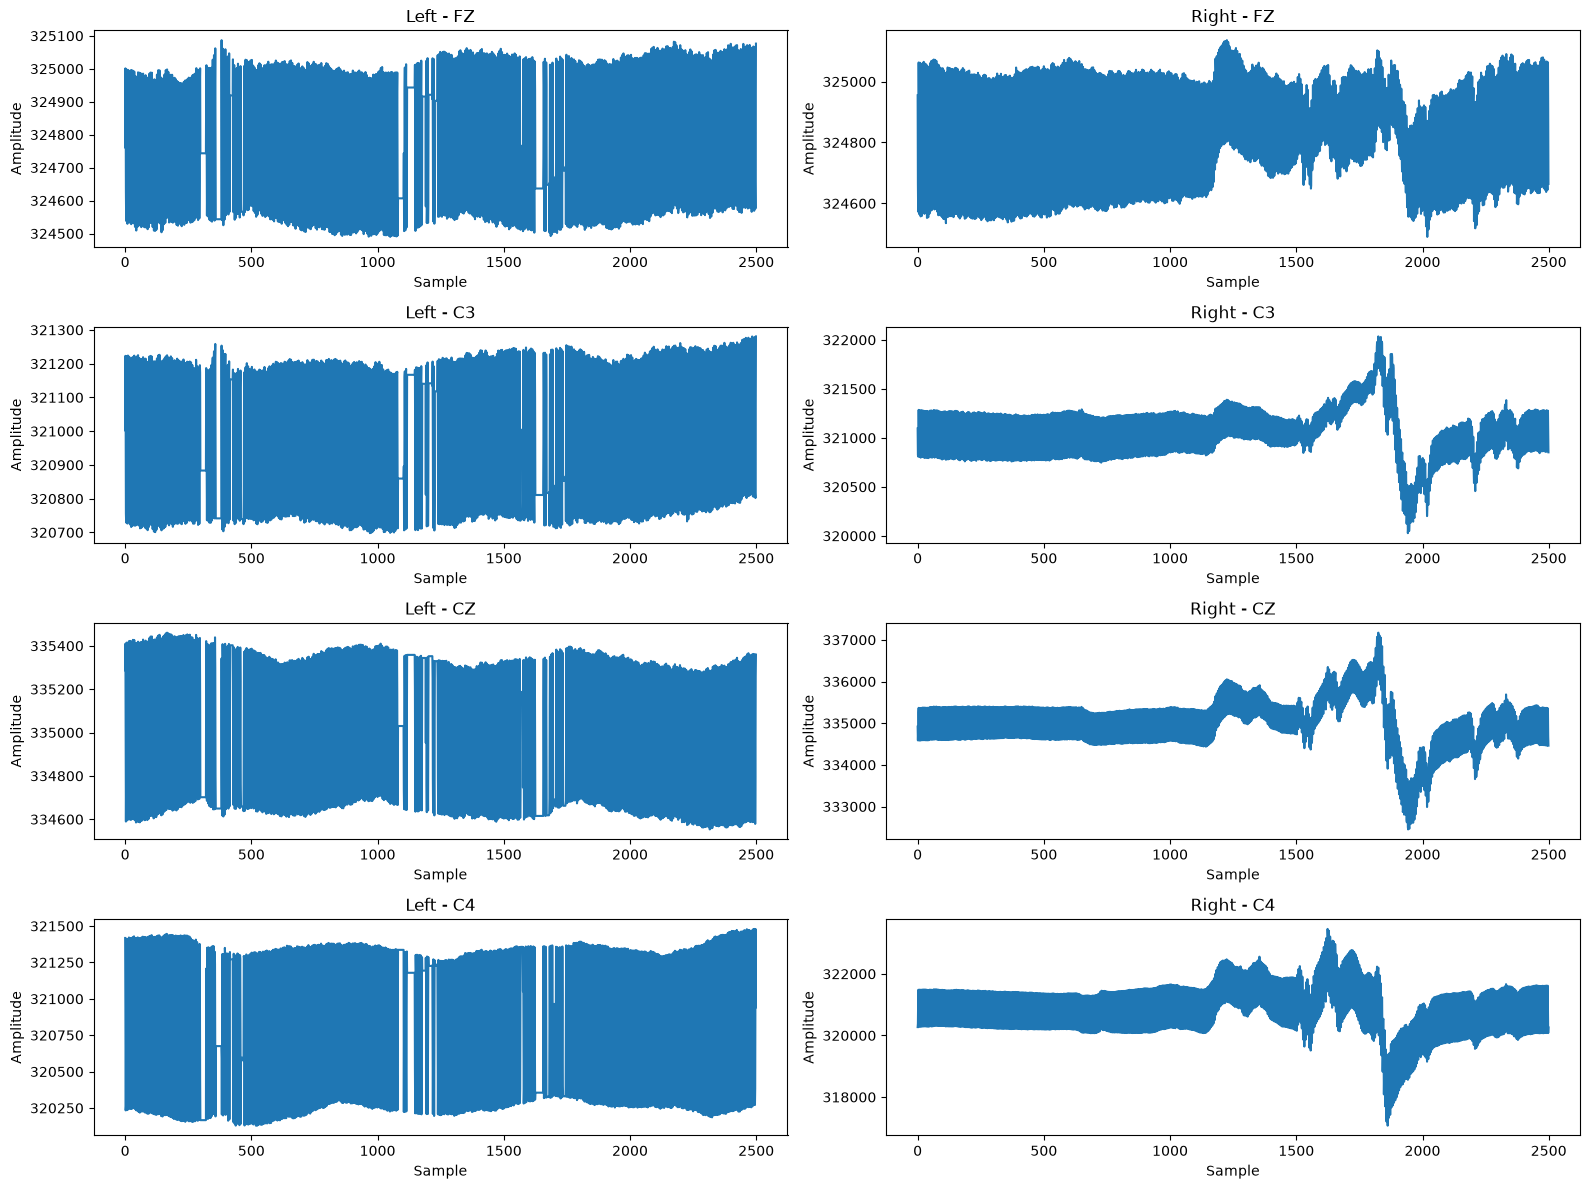

In [68]:
# Select one trial from each class

left_idx = mapping_df.index[
    mapping_df["label"] == "Left"
][0]

right_idx = mapping_df.index[
    mapping_df["label"] == "Right"
][0]

fig, axes = plt.subplots(4, 2, figsize=(16, 12))

for ch_idx, channel in enumerate(channels):
    axes[ch_idx, 0].plot(X_raw[left_idx, :, ch_idx])
    axes[ch_idx, 0].set_title(f"Left - {channel}")
    axes[ch_idx, 0].set_xlabel("Sample")
    axes[ch_idx, 0].set_ylabel("Amplitude")

    axes[ch_idx, 1].plot(X_raw[right_idx, :, ch_idx])
    axes[ch_idx, 1].set_title(f"Right - {channel}")
    axes[ch_idx, 1].set_xlabel("Sample")
    axes[ch_idx, 1].set_ylabel("Amplitude")

plt.tight_layout()
plt.show()

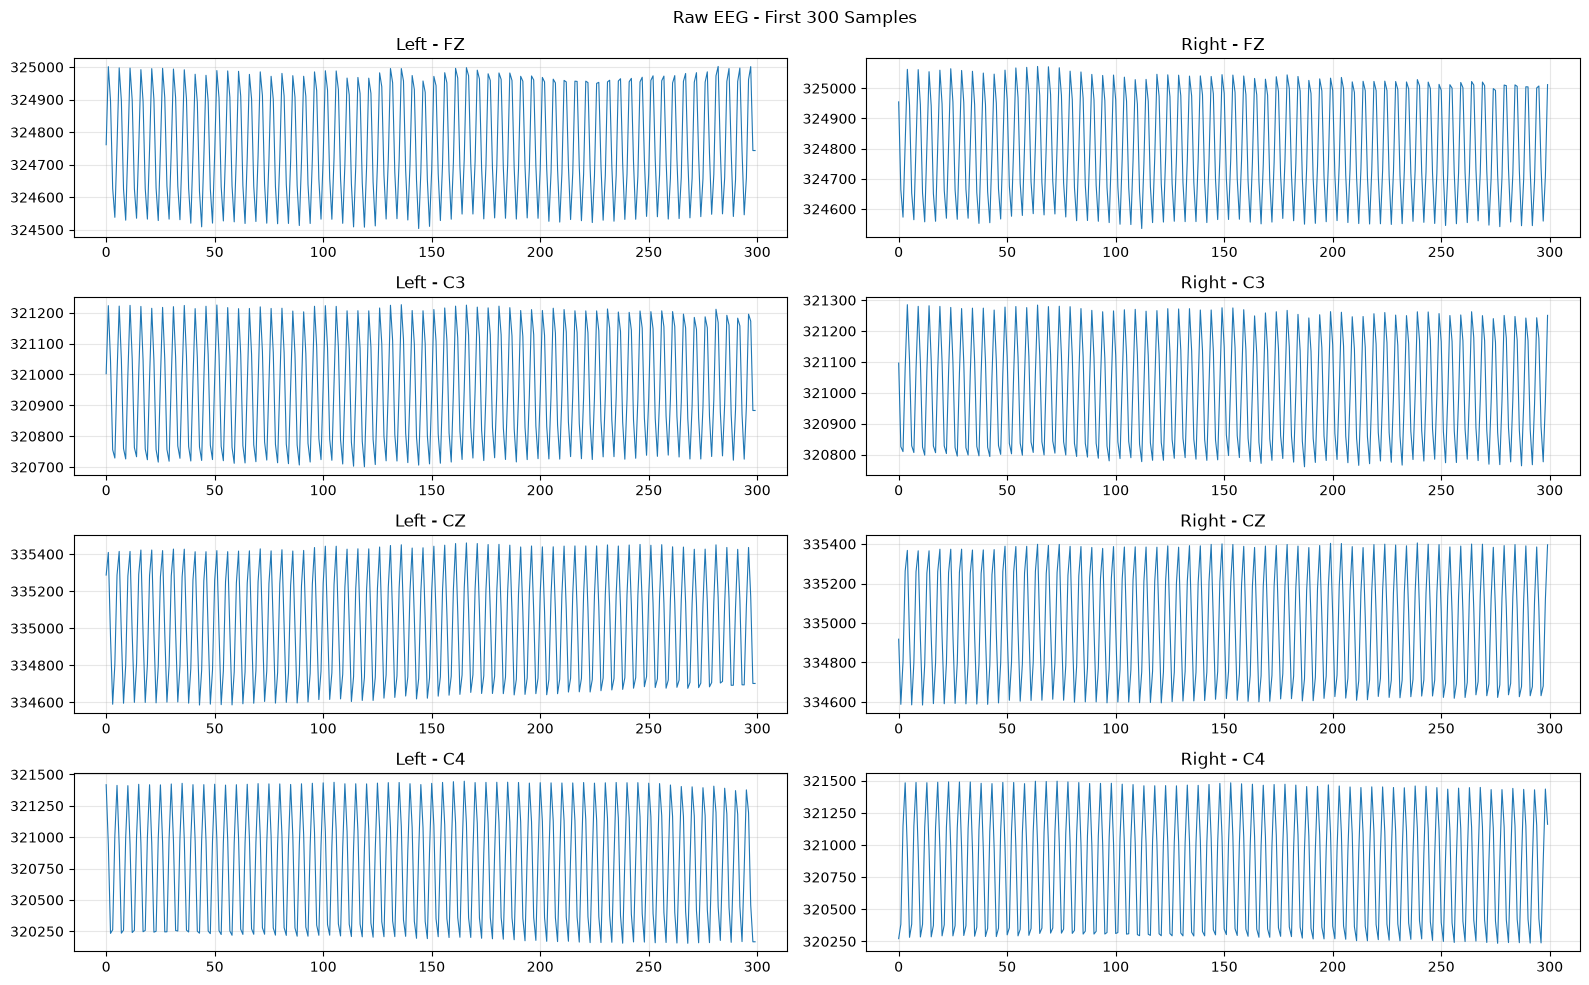

In [69]:
fig, axes = plt.subplots(4, 2, figsize=(16, 10))

for ch_idx, channel in enumerate(channels):

    axes[ch_idx, 0].plot(
        X_raw[left_idx, :300, ch_idx],
        linewidth=0.8
    )
    axes[ch_idx, 0].set_title(f"Left - {channel}")

    axes[ch_idx, 1].plot(
        X_raw[right_idx, :300, ch_idx],
        linewidth=0.8
    )
    axes[ch_idx, 1].set_title(f"Right - {channel}")

    axes[ch_idx, 0].grid(alpha=0.3)
    axes[ch_idx, 1].grid(alpha=0.3)

plt.suptitle("Raw EEG - First 300 Samples")
plt.tight_layout()
plt.show()

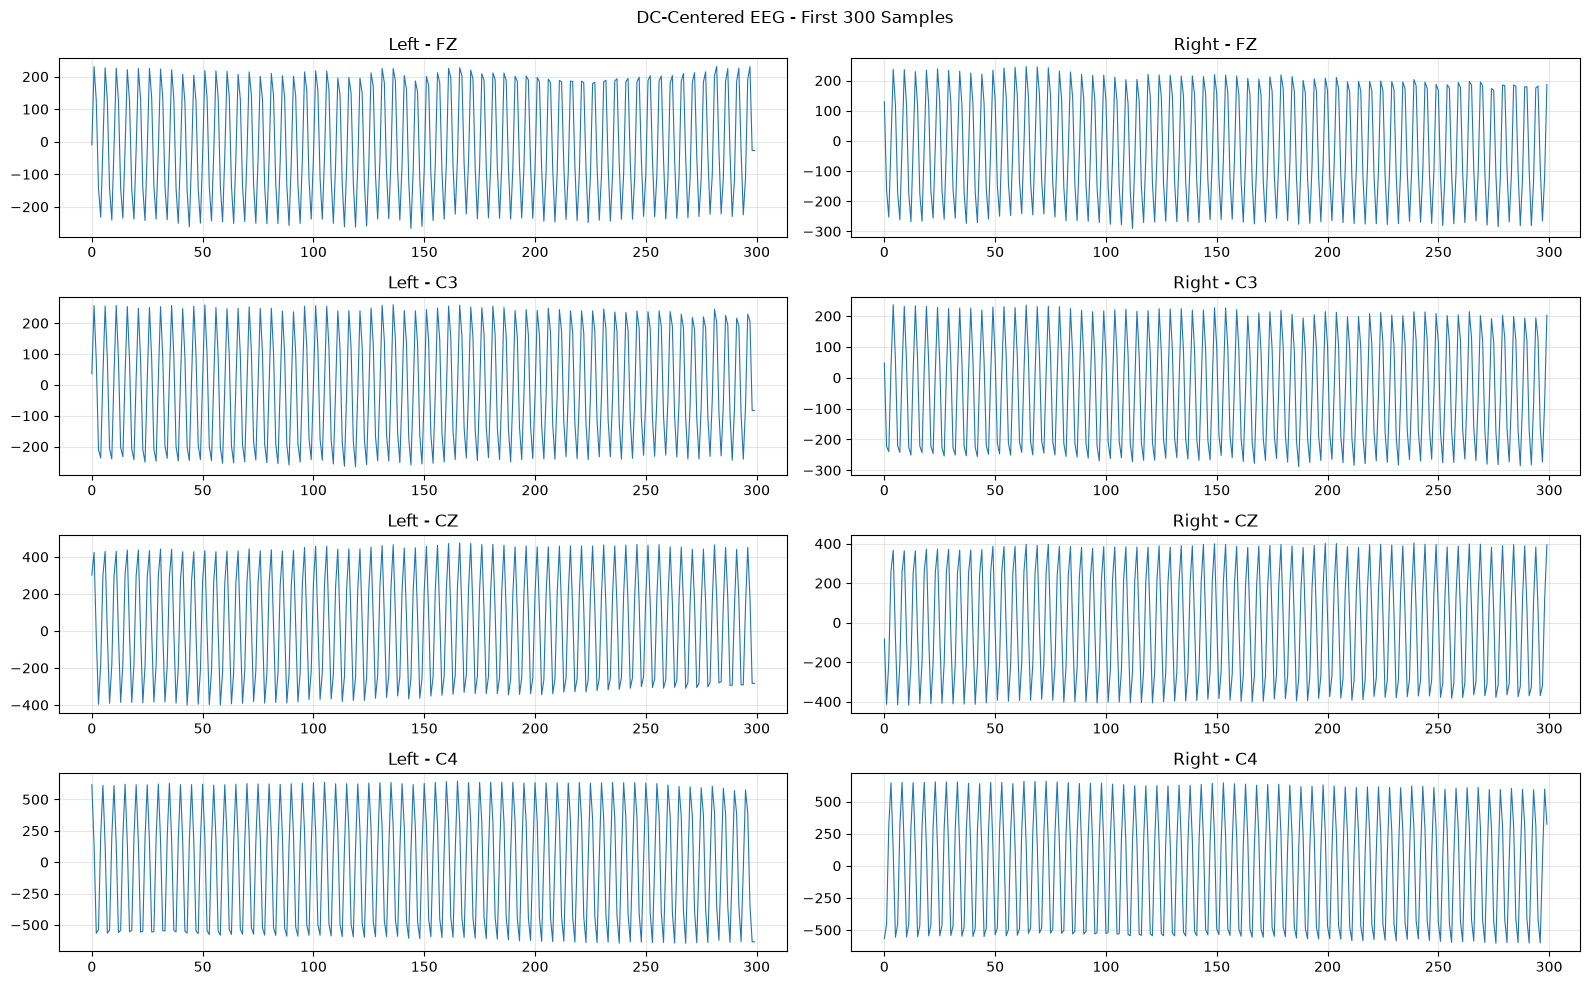

In [70]:
# Remove DC offset for visualization only

X_centered = X_raw - X_raw.mean(axis=1, keepdims=True)

fig, axes = plt.subplots(4, 2, figsize=(16, 10))

for ch_idx, channel in enumerate(channels):

    axes[ch_idx, 0].plot(
        X_centered[left_idx, :300, ch_idx],
        linewidth=0.8
    )
    axes[ch_idx, 0].set_title(f"Left - {channel}")

    axes[ch_idx, 1].plot(
        X_centered[right_idx, :300, ch_idx],
        linewidth=0.8
    )
    axes[ch_idx, 1].set_title(f"Right - {channel}")

    axes[ch_idx, 0].grid(alpha=0.3)
    axes[ch_idx, 1].grid(alpha=0.3)

plt.suptitle("DC-Centered EEG - First 300 Samples")
plt.tight_layout()
plt.show()

In [71]:
from scipy.signal import find_peaks

print("Approximate cycles in first 300 samples:\n")

for ch_idx, channel in enumerate(channels):

    for label, idx in [("Left", left_idx), ("Right", right_idx)]:

        signal = X_centered[idx, :300, ch_idx]

        peaks, _ = find_peaks(signal, prominence=50)

        print(
            f"{label} - {channel}: "
            f"{len(peaks)} peaks"
        )

Approximate cycles in first 300 samples:

Left - FZ: 60 peaks
Right - FZ: 59 peaks
Left - C3: 60 peaks
Right - C3: 59 peaks
Left - CZ: 60 peaks
Right - CZ: 59 peaks
Left - C4: 59 peaks
Right - C4: 60 peaks


In [72]:
# Cross-channel correlation for selected trials

for label, idx in [("Left", left_idx), ("Right", right_idx)]:

    trial = X_centered[idx, :300, :]

    corr_df = pd.DataFrame(
        trial,
        columns=channels
    ).corr()

    print(f"\n{label} - Cross-channel Correlation")
    display(corr_df.round(3))


Left - Cross-channel Correlation


,FZ,C3,CZ,C4
FZ,1.000,0.973,0.729,-0.076
C3,0.973,1.000,0.864,0.150
CZ,0.729,0.864,1.000,0.626
C4,-0.076,0.150,0.626,1.000



Right - Cross-channel Correlation


,FZ,C3,CZ,C4
FZ,1.000,0.972,0.738,-0.116
C3,0.972,1.000,0.874,0.116
CZ,0.738,0.874,1.000,0.584
C4,-0.116,0.116,0.584,1.000


In [73]:
# Cross-Channel Correlation Analysis

correlation_results = []

for label in ["Left", "Right"]:

    indices = mapping_df.index[
        mapping_df["label"] == label
    ].to_numpy()

    correlations = []

    for idx in indices:
        trial = X_centered[idx]

        corr = np.corrcoef(trial.T)
        correlations.append(corr)

    mean_corr = np.mean(correlations, axis=0)

    corr_df = pd.DataFrame(
        mean_corr,
        index=channels,
        columns=channels
    )

    print(f"\n{label} - Average Cross-Channel Correlation")
    display(corr_df.round(3))

    for i in range(len(channels)):
        for j in range(i + 1, len(channels)):
            correlation_results.append({
                "Label": label,
                "Channel_1": channels[i],
                "Channel_2": channels[j],
                "Mean_Correlation": mean_corr[i, j]
            })

correlation_df = pd.DataFrame(correlation_results)

correlation_df.to_csv(
    OUTPUT_DIR / "cross_channel_correlation.csv",
    index=False
)


Left - Average Cross-Channel Correlation


,FZ,C3,CZ,C4
FZ,1.000,0.623,0.766,0.680
C3,0.623,1.000,0.798,0.732
CZ,0.766,0.798,1.000,0.903
C4,0.680,0.732,0.903,1.000



Right - Average Cross-Channel Correlation


,FZ,C3,CZ,C4
FZ,1.000,0.596,0.749,0.668
C3,0.596,1.000,0.786,0.721
CZ,0.749,0.786,1.000,0.901
C4,0.668,0.721,0.901,1.000


In [74]:
correlation_df.to_csv(
    OUTPUT_DIR / "cross_channel_correlation.csv",
    index=False
)

print("Cross-channel correlation report saved successfully.")

Cross-channel correlation report saved successfully.


In [75]:
# Global Timestamp Interval Analysis

interval_summary = []

for file_path in csv_files:
    df = pd.read_csv(file_path)

    timestamps = df["Time"].to_numpy(dtype=np.float64)
    intervals = np.diff(timestamps)

    interval_summary.append({
        "file_name": file_path.name,
        "min_interval": np.min(intervals),
        "median_interval": np.median(intervals),
        "mean_interval": np.mean(intervals),
        "max_interval": np.max(intervals),
        "intervals_below_1ms": np.sum(intervals < 0.001),
        "intervals_above_10ms": np.sum(intervals > 0.01),
        "non_positive_intervals": np.sum(intervals <= 0)
    })

timestamp_report = pd.DataFrame(interval_summary)

timestamp_report.to_csv(
    OUTPUT_DIR / "timestamp_interval_report.csv",
    index=False
)

display(timestamp_report.describe().round(6))

print("\nFiles with the most abnormal intervals:")
display(
    timestamp_report.sort_values(
        "intervals_above_10ms",
        ascending=False
    ).head(10)
)

,min_interval,median_interval,mean_interval,max_interval,intervals_below_1ms,intervals_above_10ms,non_positive_intervals
count,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.0
mean,0.000002,0.002390,0.003996,0.076798,755.937500,213.370370,0.0
std,0.000002,0.000447,0.000048,0.072967,209.742241,44.885866,0.0
min,0.000000,0.000001,0.003495,0.028748,546.000000,91.000000,0.0
25%,0.000002,0.002478,0.003992,0.035363,619.000000,175.000000,0.0
50%,0.000002,0.002497,0.003996,0.067193,748.500000,198.000000,0.0
75%,0.000003,0.002516,0.004000,0.083400,771.000000,253.000000,0.0
max,0.000011,0.002576,0.004594,1.066453,2284.000000,355.000000,0.0



Files with the most abnormal intervals:


,file_name,min_interval,median_interval,mean_interval,max_interval,intervals_below_1ms,intervals_above_10ms,non_positive_intervals
360,cellula_MI_data_361.csv,1.699897e-06,0.001157,0.003991,0.073946,981,355,0
356,cellula_MI_data_357.csv,1.400011e-06,0.001164,0.004019,0.068934,994,352,0
368,cellula_MI_data_369.csv,1.600012e-06,0.001164,0.004002,0.101848,976,349,0
354,cellula_MI_data_355.csv,1.400011e-06,0.001154,0.004000,0.083924,999,348,0
343,cellula_MI_data_344.csv,1.500011e-06,0.001165,0.003991,0.063614,972,348,0
326,cellula_MI_data_327.csv,2.000015e-07,0.001209,0.004000,0.078812,914,347,0
374,cellula_MI_data_375.csv,1.500011e-06,0.001151,0.003991,0.073766,982,347,0
350,cellula_MI_data_351.csv,1.800014e-06,0.001166,0.004002,0.064600,977,346,0
377,cellula_MI_data_378.csv,1.500011e-06,0.001158,0.004007,0.080251,995,344,0
333,cellula_MI_data_334.csv,1.600012e-06,0.001174,0.003992,0.061505,977,344,0


In [76]:
timestamp_quality_summary = pd.DataFrame({
    "Metric": [
        "Total EEG Files",
        "Average Median Interval (sec)",
        "Average Mean Interval (sec)",
        "Average Intervals Below 1ms",
        "Average Intervals Above 10ms",
        "Files With Non-positive Intervals",
        "Sampling Rate Status"
    ],
    "Result": [
        len(timestamp_report),
        timestamp_report["median_interval"].mean(),
        timestamp_report["mean_interval"].mean(),
        timestamp_report["intervals_below_1ms"].mean(),
        timestamp_report["intervals_above_10ms"].mean(),
        (timestamp_report["non_positive_intervals"] > 0).sum(),
        "Unconfirmed - Irregular Timestamps"
    ]
})

timestamp_quality_summary.to_csv(
    OUTPUT_DIR / "timestamp_quality_summary.csv",
    index=False
)

display(timestamp_quality_summary)

,Metric,Result
0,Total EEG Files,2160
1,Average Median Interval (sec),0.00239
2,Average Mean Interval (sec),0.003996
3,Average Intervals Below 1ms,755.9375
4,Average Intervals Above 10ms,213.37037
5,Files With Non-positive Intervals,0
6,Sampling Rate Status,Unconfirmed - Irregular Timestamps


In [77]:
# Signal Statistical Analysis

channels = ["FZ", "C3", "CZ", "C4"]

signal_features = []

for trial_idx in range(X_raw.shape[0]):

    for ch_idx, channel in enumerate(channels):

        signal = X_raw[trial_idx, :, ch_idx].astype(np.float64)

        centered_signal = signal - np.mean(signal)

        signal_features.append({
            "trial_index": trial_idx + 1,
            "channel": channel,
            "label": mapping_df.loc[trial_idx, "label"],

            "mean": np.mean(signal),
            "std": np.std(signal),
            "rms": np.sqrt(np.mean(signal ** 2)),
            "peak_to_peak": np.ptp(signal),
            "centered_rms": np.sqrt(np.mean(centered_signal ** 2)),
            "min": np.min(signal),
            "max": np.max(signal)
        })

features_df = pd.DataFrame(signal_features)

features_df.to_csv(
    OUTPUT_DIR / "signal_statistical_features.csv",
    index=False
)

display(features_df.head())
print("Features shape:", features_df.shape)

,trial_index,channel,label,mean,std,rms,peak_to_peak,centered_rms,min,max
0,1,FZ,Left,324770.376525,182.328861,324770.427705,596.96875,182.328861,324489.78125,325086.75000
1,1,C3,Left,320966.199350,181.360512,320966.250588,582.84375,181.360512,320697.84375,321280.68750
2,1,CZ,Left,334986.259500,281.379692,334986.377676,907.56250,281.379692,334553.15625,335460.71875
3,1,C4,Left,320801.713538,428.455625,320801.999655,1351.37500,428.455625,320128.68750,321480.06250
4,2,FZ,Right,324826.075063,157.600588,324826.113295,646.06250,157.600588,324489.93750,325136.00000


Features shape: (8640, 10)


In [78]:
feature_columns = [
    "std",
    "rms",
    "peak_to_peak",
    "centered_rms"
]

class_summary = (
    features_df
    .groupby(["label", "channel"])[feature_columns]
    .agg(["mean", "median", "std"])
    .round(3)
)

display(class_summary)

class_summary.to_csv(
    OUTPUT_DIR / "class_signal_features_summary.csv"
)

std                            rms                         \
                   mean   median       std        mean      median        std   
label channel                                                                   
Left  C3        987.700  507.953  1461.007  302879.287  303785.559  27006.318   
      C4       1442.205  783.869  1646.055  328847.772  313178.050  83380.795   
      CZ       2054.818  908.254  3566.101  336424.551  323055.971  72871.551   
      FZ       1292.569  413.747  2192.122  299836.533  297470.463  25444.756   
Right C3        959.771  500.970  1541.430  300697.846  301960.715  27699.336   
      C4       1460.792  842.809  1644.111  324891.581  312241.096  79693.673   
      CZ       1997.966  933.537  3433.610  332132.366  318812.806  70204.636   
      FZ       1241.932  426.508  2070.655  297171.687  293868.662  24337.255   

              peak_to_peak                      centered_rms           \
                      mean    median        std         mean   median   
label channel                                                           
Left  C3          3646.636  1730.125   6470.096      987.700  507.953   
      C4          5021.416  2724.625   6957.570     1442.205  783.869   
      CZ          7053.063  3231.578  13002.831     2054.818  908.254   
      FZ          4195.583  1468.328   6844.749     1292.569  413.747   
Right C3          3565.870  1729.484   7720.063      959.771  500.970   
      C4          5129.929  2889.062   7055.446     1460.792  842.809   
      CZ          6781.697  3231.031  11650.605     1997.966  933.537   
      FZ          4020.933  1649.906   6373.762     1241.932  426.508   

                         
                    std  
label channel            
Left  C3       1461.007  
      C4       1646.055  
      CZ       3566.101  
      FZ       2192.122  
Right C3       1541.430  
      C4       1644.111  
      CZ       3433.610  
      FZ       2070.655

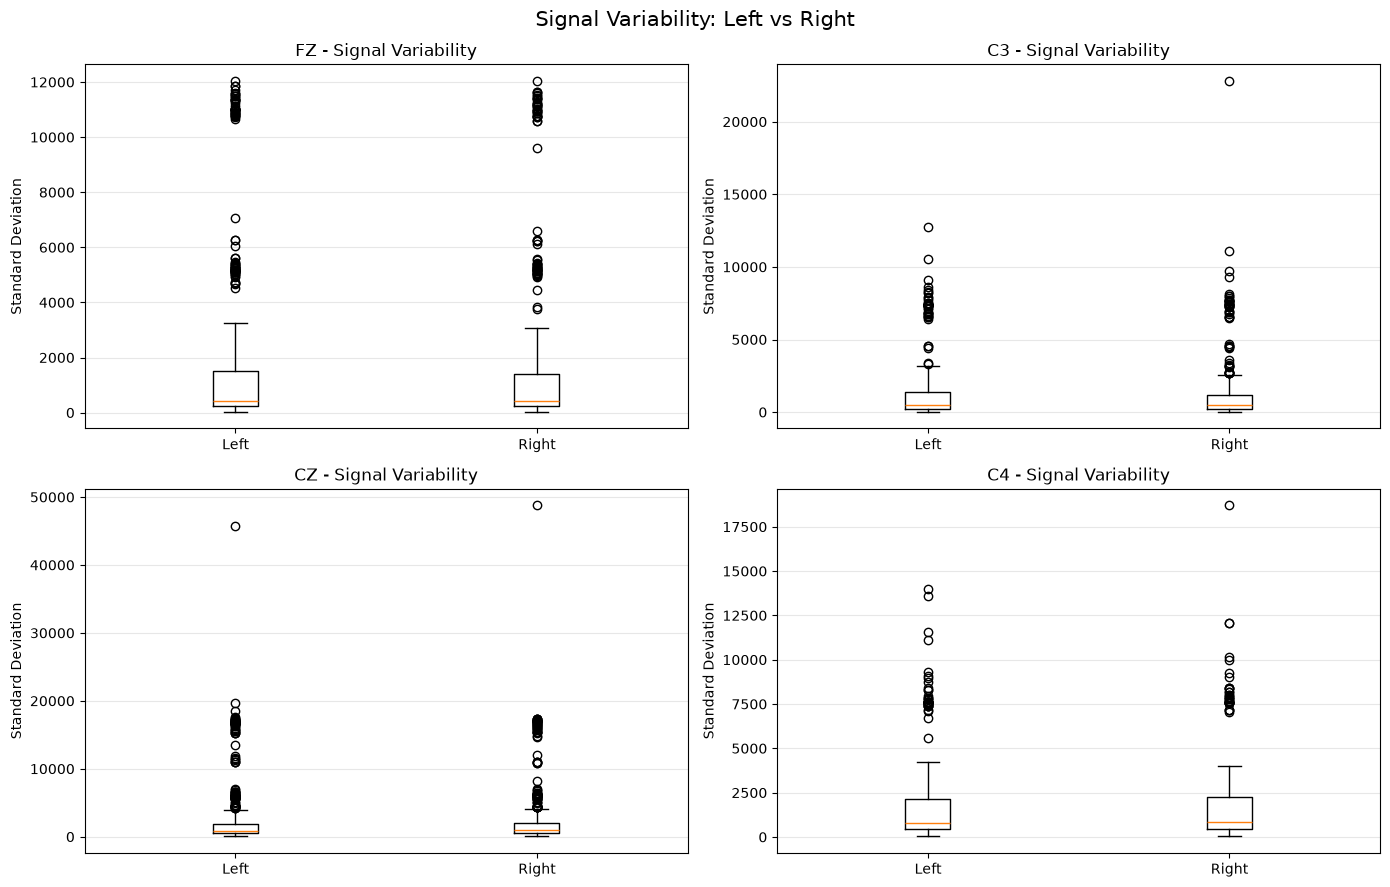

In [79]:
# Compare Signal Variability Between Classes

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, channel in zip(axes.flat, channels):

    channel_data = features_df[
        features_df["channel"] == channel
    ]

    left_values = channel_data[
        channel_data["label"] == "Left"
    ]["std"]

    right_values = channel_data[
        channel_data["label"] == "Right"
    ]["std"]

    ax.boxplot(
        [left_values, right_values],
        tick_labels=["Left", "Right"],
        showfliers=True
    )

    ax.set_title(f"{channel} - Signal Variability")
    ax.set_ylabel("Standard Deviation")
    ax.grid(axis="y", alpha=0.3)

plt.suptitle(
    "Signal Variability: Left vs Right",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [80]:
# Outlier Analysis using IQR

outlier_results = []

for channel in channels:

    channel_data = features_df[
        features_df["channel"] == channel
    ]

    Q1 = channel_data["std"].quantile(0.25)
    Q3 = channel_data["std"].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    for label in ["Left", "Right"]:

        class_data = channel_data[
            channel_data["label"] == label
        ]

        outliers = class_data[
            (class_data["std"] < lower_bound) |
            (class_data["std"] > upper_bound)
        ]

        outlier_results.append({
            "channel": channel,
            "label": label,
            "total_trials": len(class_data),
            "outlier_count": len(outliers),
            "outlier_percentage": (
                len(outliers) / len(class_data) * 100
            ),
            "lower_bound": lower_bound,
            "upper_bound": upper_bound
        })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary.round(2))

outlier_summary.to_csv(
    OUTPUT_DIR / "signal_outlier_summary.csv",
    index=False
)

,channel,label,total_trials,outlier_count,outlier_percentage,lower_bound,upper_bound
0,FZ,Left,1082,80,7.39,-1609.13,3296.59
1,FZ,Right,1078,73,6.77,-1609.13,3296.59
2,C3,Left,1082,45,4.16,-1505.84,3013.09
3,C3,Right,1078,47,4.36,-1505.84,3013.09
4,CZ,Left,1082,109,10.07,-1705.17,4115.59
5,CZ,Right,1078,97,9.00,-1705.17,4115.59
6,C4,Left,1082,40,3.70,-2138.54,4821.27
7,C4,Right,1078,34,3.15,-2138.54,4821.27


In [81]:
# Identify Trials with Statistical Outliers

outlier_trials = []

for channel in channels:

    channel_data = features_df[
        features_df["channel"] == channel
    ]

    Q1 = channel_data["std"].quantile(0.25)
    Q3 = channel_data["std"].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    flagged = channel_data[
        (channel_data["std"] < lower) |
        (channel_data["std"] > upper)
    ]

    for _, row in flagged.iterrows():
        outlier_trials.append({
            "trial_index": int(row["trial_index"]),
            "channel": channel,
            "label": row["label"],
            "std": row["std"]
        })

outlier_details_df = pd.DataFrame(outlier_trials)

trial_outlier_summary = (
    outlier_details_df
    .groupby("trial_index")
    .agg(
        outlier_channels=("channel", lambda x: ", ".join(sorted(x))),
        outlier_count=("channel", "count"),
        label=("label", "first")
    )
    .reset_index()
)

trial_outlier_summary["file_name"] = (
    trial_outlier_summary["trial_index"]
    .apply(lambda x: f"cellula_MI_data_{x}.csv")
)

trial_outlier_summary.to_csv(
    OUTPUT_DIR / "trials_requiring_quality_review.csv",
    index=False
)

print("Total flagged channel records:", len(outlier_details_df))
print("Unique affected trials:", len(trial_outlier_summary))

display(
    trial_outlier_summary
    .sort_values("outlier_count", ascending=False)
    .head(20)
)

Total flagged channel records: 525
Unique affected trials: 208


,trial_index,outlier_channels,outlier_count,label,file_name
32,464,"C3, C4, CZ, FZ",4,Right,cellula_MI_data_464.csv
33,465,"C3, C4, CZ, FZ",4,Right,cellula_MI_data_465.csv
34,466,"C3, C4, CZ, FZ",4,Right,cellula_MI_data_466.csv
35,467,"C3, C4, CZ, FZ",4,Right,cellula_MI_data_467.csv
36,468,"C3, C4, CZ, FZ",4,Right,cellula_MI_data_468.csv
37,469,"C3, C4, CZ, FZ",4,Left,cellula_MI_data_469.csv
38,470,"C3, C4, CZ, FZ",4,Left,cellula_MI_data_470.csv
39,471,"C3, C4, CZ, FZ",4,Left,cellula_MI_data_471.csv
40,472,"C3, C4, CZ, FZ",4,Right,cellula_MI_data_472.csv
41,473,"C3, C4, CZ, FZ",4,Right,cellula_MI_data_473.csv


In [82]:
# Detect Consecutive Outlier Trial Groups

affected_trials = sorted(
    trial_outlier_summary["trial_index"].unique()
)

groups = []
start = affected_trials[0]
previous = affected_trials[0]

for trial in affected_trials[1:]:

    if trial != previous + 1:
        groups.append({
            "start_trial": start,
            "end_trial": previous,
            "group_size": previous - start + 1
        })
        start = trial

    previous = trial

groups.append({
    "start_trial": start,
    "end_trial": previous,
    "group_size": previous - start + 1
})

outlier_groups_df = pd.DataFrame(groups)

display(
    outlier_groups_df.sort_values(
        "group_size",
        ascending=False
    )
)

outlier_groups_df.to_csv(
    OUTPUT_DIR / "consecutive_outlier_groups.csv",
    index=False
)

,start_trial,end_trial,group_size
3,514,603,90
2,460,504,45
0,325,351,27
4,613,621,9
5,658,666,9
12,1387,1395,9
13,1414,1422,9
8,1081,1082,2
6,775,776,2
7,830,831,2


In [83]:
# Combine Outlier and Repeated Sample Quality Reports

repeated_quality = repeated_summary_df[
    [
        "trial_index",
        "repeated_samples",
        "longest_constant_run",
        "repeated_percentage"
    ]
].copy()

outlier_quality = trial_outlier_summary[
    [
        "trial_index",
        "outlier_count",
        "outlier_channels"
    ]
].copy()

combined_quality_df = repeated_quality.merge(
    outlier_quality,
    on="trial_index",
    how="left"
)

combined_quality_df["outlier_count"] = (
    combined_quality_df["outlier_count"].fillna(0).astype(int)
)

combined_quality_df["has_outlier"] = (
    combined_quality_df["outlier_count"] > 0
)

combined_quality_df["has_repeated_samples"] = (
    combined_quality_df["repeated_samples"] > 0
)

combined_quality_df["has_long_plateau"] = (
    combined_quality_df["longest_constant_run"] >= 50
)

quality_relationship = pd.crosstab(
    combined_quality_df["has_outlier"],
    combined_quality_df["has_repeated_samples"],
    margins=True
)

display(quality_relationship)

print(
    "Outlier trials:",
    combined_quality_df["has_outlier"].sum()
)

print(
    "Trials with repeated samples:",
    combined_quality_df["has_repeated_samples"].sum()
)

print(
    "Trials with long plateaus:",
    combined_quality_df["has_long_plateau"].sum()
)

combined_quality_df.to_csv(
    OUTPUT_DIR / "combined_signal_quality_report.csv",
    index=False
)

has_repeated_samples,False,True,All
has_outlier,,,
False,1549,403,1952
True,150,58,208
All,1699,461,2160


Outlier trials: 208
Trials with repeated samples: 461
Trials with long plateaus: 133


In [84]:
# Final Trial Quality Classification

def classify_trial(row):

    if row["has_outlier"] and row["has_long_plateau"]:
        return "Outlier + Long Plateau"

    elif row["has_outlier"] and row["has_repeated_samples"]:
        return "Outlier + Repeated Samples"

    elif row["has_outlier"]:
        return "Outlier Only"

    elif row["has_long_plateau"]:
        return "Long Plateau"

    elif row["has_repeated_samples"]:
        return "Repeated Samples"

    return "No Detected Issue"


combined_quality_df["quality_category"] = (
    combined_quality_df.apply(classify_trial, axis=1)
)

quality_category_summary = (
    combined_quality_df["quality_category"]
    .value_counts()
    .rename_axis("quality_category")
    .reset_index(name="trial_count")
)

quality_category_summary["percentage"] = (
    quality_category_summary["trial_count"] / len(combined_quality_df) * 100
)

display(quality_category_summary.round(2))

quality_category_summary.to_csv(
    OUTPUT_DIR / "final_quality_category_summary.csv",
    index=False
)

combined_quality_df.to_csv(
    OUTPUT_DIR / "final_trial_quality_report.csv",
    index=False
)

,quality_category,trial_count,percentage
0,No Detected Issue,1549,71.71
1,Repeated Samples,286,13.24
2,Outlier Only,150,6.94
3,Long Plateau,117,5.42
4,Outlier + Repeated Samples,42,1.94
5,Outlier + Long Plateau,16,0.74


### EEG Signal Quality Assessment – Summary

A total of 2,160 EEG trials were evaluated across four channels (FZ, C3, CZ, and C4).

- 1,549 trials (71.71%) showed no detected issues according to the selected quality checks.
- 611 trials (28.29%) showed at least one detected quality issue.
- Repeated samples were the most frequently observed issue.
- Statistical outliers were identified in 208 trials.
- Long constant-value sequences were identified in 133 trials.

These findings indicate that the dataset contains signal quality concerns that require further investigation. No trials were automatically removed.

The quality categories are preliminary screening results, not a definitive assessment of EEG usability.

In [86]:
# Step 1: Remove DC Offset (Trial-wise Channel-wise)

X_centered = (
    X_raw - X_raw.mean(axis=1, keepdims=True)
).astype(np.float32)

# Validate centered data
print("Original shape:", X_raw.shape)
print("Processed shape:", X_centered.shape)

print(
    "Maximum absolute channel mean after centering:",
    np.abs(X_centered.mean(axis=1)).max()
)

print("Contains NaN:", np.isnan(X_centered).any())
print("Contains Inf:", np.isinf(X_centered).any())

# Save processed data
np.save(
    OUTPUT_DIR / "X_centered.npy",
    X_centered
)

print("Centered EEG data saved successfully.")

Original shape: (2160, 2500, 4)
Processed shape: (2160, 2500, 4)
Maximum absolute channel mean after centering: 5.2819624
Contains NaN: False
Contains Inf: False
Centered EEG data saved successfully.


In [87]:
# Step 2: Extract Features from Centered EEG Signals

centered_features = []

for trial_idx in range(X_centered.shape[0]):
    for ch_idx, channel in enumerate(channels):

        signal = X_centered[trial_idx, :, ch_idx]

        centered_features.append({
            "trial_index": trial_idx + 1,
            "channel": channel,
            "label": mapping_df.loc[trial_idx, "label"],
            "mean": np.mean(signal),
            "std": np.std(signal),
            "rms": np.sqrt(np.mean(signal ** 2)),
            "peak_to_peak": np.ptp(signal),
            "min": np.min(signal),
            "max": np.max(signal)
        })

centered_features_df = pd.DataFrame(centered_features)

centered_features_df.to_csv(
    OUTPUT_DIR / "centered_signal_features.csv",
    index=False
)

print("Features shape:", centered_features_df.shape)
print("Saved successfully.")

Features shape: (8640, 9)
Saved successfully.


In [88]:
# Final validation before modeling

print("Data shape:", X_centered.shape)
print("Data type:", X_centered.dtype)
print("Contains NaN:", np.isnan(X_centered).any())
print("Contains Inf:", np.isinf(X_centered).any())

assert X_centered.shape == (2160, 2500, 4)
assert not np.isnan(X_centered).any()
assert not np.isinf(X_centered).any()

print("\nFinal validation passed.")

Data shape: (2160, 2500, 4)
Data type: float32
Contains NaN: False
Contains Inf: False

Final validation passed.


In [89]:
# Save final pre-modeling dataset

np.save(OUTPUT_DIR / "X_final_pre_modeling.npy", X_centered)

y_provisional = mapping_df["label"].map({
    "Left": 0,
    "Right": 1
}).to_numpy(dtype=np.int8)

np.save(OUTPUT_DIR / "y_provisional.npy", y_provisional)

mapping_df.to_csv(
    OUTPUT_DIR / "final_provisional_mapping.csv",
    index=False
)

print("X saved:", (OUTPUT_DIR / "X_final_pre_modeling.npy").exists())
print("y saved:", (OUTPUT_DIR / "y_provisional.npy").exists())
print("Mapping saved:", (OUTPUT_DIR / "final_provisional_mapping.csv").exists())

print("\nX shape:", X_centered.shape)
print("y shape:", y_provisional.shape)
print("Label encoding: Left=0, Right=1")
print("Mapping status: PROVISIONAL")

X saved: True
y saved: True
Mapping saved: True

X shape: (2160, 2500, 4)
y shape: (2160,)
Label encoding: Left=0, Right=1
Mapping status: PROVISIONAL


In [90]:
# Create pre-modeling dataset report

report = {
    "number_of_trials": X_centered.shape[0],
    "samples_per_trial": X_centered.shape[1],
    "number_of_channels": X_centered.shape[2],
    "channels": ", ".join(channels),
    "data_type": str(X_centered.dtype),
    "missing_values": bool(np.isnan(X_centered).any()),
    "infinite_values": bool(np.isinf(X_centered).any()),
    "preprocessing_applied": "Per-trial mean removal (DC offset removal)",
    "label_encoding": "Left=0, Right=1",
    "label_mapping_status": "Provisional",
    "sampling_rate_status": "Unconfirmed - Irregular timestamps",
    "filtering_status": "Not applied",
    "resampling_status": "Not applied",
    "modeling_status": "Not started"
}

pd.DataFrame([report]).to_csv(
    OUTPUT_DIR / "pre_modeling_dataset_report.csv",
    index=False
)

print("Pre-modeling report saved successfully.")

Pre-modeling report saved successfully.


In [91]:
from scipy.stats import skew, kurtosis

# Time-domain Feature Engineering

feature_rows = []

for trial_idx in range(X_centered.shape[0]):
    row = {
        "trial_index": trial_idx + 1,
        "label": mapping_df.loc[trial_idx, "label"]
    }

    for ch_idx, channel in enumerate(channels):
        signal = X_centered[trial_idx, :, ch_idx]
        prefix = channel.lower()

        row[f"{prefix}_mean"] = np.mean(signal)
        row[f"{prefix}_std"] = np.std(signal)
        row[f"{prefix}_rms"] = np.sqrt(np.mean(signal ** 2))
        row[f"{prefix}_min"] = np.min(signal)
        row[f"{prefix}_max"] = np.max(signal)
        row[f"{prefix}_ptp"] = np.ptp(signal)
        row[f"{prefix}_median"] = np.median(signal)
        row[f"{prefix}_iqr"] = (
            np.percentile(signal, 75) - np.percentile(signal, 25)
        )
        row[f"{prefix}_skewness"] = skew(signal)
        row[f"{prefix}_kurtosis"] = kurtosis(signal)
        row[f"{prefix}_zero_crossing_rate"] = np.mean(
            np.diff(np.signbit(signal))
        )
        row[f"{prefix}_line_length"] = np.mean(np.abs(np.diff(signal)))

    feature_rows.append(row)

final_features_df = pd.DataFrame(feature_rows)

final_features_df.to_csv(
    OUTPUT_DIR / "time_domain_features.csv",
    index=False
)

print("Features shape:", final_features_df.shape)
print("Missing values:", final_features_df.isna().sum().sum())
print("Saved:", (OUTPUT_DIR / "time_domain_features.csv").exists())

Features shape: (2160, 50)
Missing values: 0
Saved: True


In [92]:
# Feature Quality Assessment

metadata_cols = ["trial_index", "label"]
feature_cols = [c for c in final_features_df.columns if c not in metadata_cols]

# Check invalid values
inf_count = np.isinf(final_features_df[feature_cols]).sum().sum()
nan_count = final_features_df[feature_cols].isna().sum().sum()

# Check constant features
constant_features = [
    col for col in feature_cols
    if final_features_df[col].nunique() <= 1
]

# Statistical summary
feature_summary = final_features_df[feature_cols].describe().T
feature_summary["skewness"] = final_features_df[feature_cols].skew()
feature_summary["missing_values"] = final_features_df[feature_cols].isna().sum()
feature_summary["infinite_values"] = np.isinf(
    final_features_df[feature_cols]
).sum()

# Class-wise summary
class_summary = final_features_df.groupby("label")[feature_cols].mean().T
class_summary.columns = ["Left_mean", "Right_mean"]
class_summary["mean_difference"] = (
    class_summary["Left_mean"] - class_summary["Right_mean"]
)

# Save reports
feature_summary.to_csv(OUTPUT_DIR / "feature_quality_report.csv")
class_summary.to_csv(OUTPUT_DIR / "class_feature_comparison.csv")

print("Total features:", len(feature_cols))
print("NaN values:", nan_count)
print("Infinite values:", inf_count)
print("Constant features:", constant_features)
print("Feature assessment completed.")

Total features: 48
NaN values: 0
Infinite values: 0
Constant features: []
Feature assessment completed.


In [93]:
# Final dataset preparation (before modeling)

X_features = final_features_df[feature_cols].copy()
y_labels = final_features_df["label"].map({
    "Left": 0,
    "Right": 1
}).astype("int8")

metadata = final_features_df[["trial_index", "label"]].copy()

# Save separate datasets
X_features.to_csv(OUTPUT_DIR / "X_features_pre_modeling.csv", index=False)
np.save(OUTPUT_DIR / "X_features_pre_modeling.npy", X_features.to_numpy(dtype=np.float32))

y_labels.to_csv(OUTPUT_DIR / "y_labels_pre_modeling.csv", index=False)
np.save(OUTPUT_DIR / "y_labels_pre_modeling.npy", y_labels.to_numpy())

metadata.to_csv(OUTPUT_DIR / "feature_metadata.csv", index=False)

# Final checks
print("X shape:", X_features.shape)
print("y shape:", y_labels.shape)
print("\nLabel distribution:")
print(y_labels.value_counts().rename(index={0: "Left", 1: "Right"}))
print("\nFeature NaN:", X_features.isna().sum().sum())
print("Feature Inf:", np.isinf(X_features.to_numpy()).sum())
print("\nFinal pre-modeling files saved successfully.")

X shape: (2160, 48)
y shape: (2160,)

Label distribution:
label
Left     1082
Right    1078
Name: count, dtype: int64

Feature NaN: 0
Feature Inf: 0

Final pre-modeling files saved successfully.


In [94]:
# Final pre-modeling manifest

manifest = {
    "trials": len(X_features),
    "features": X_features.shape[1],
    "channels": channels,
    "samples_per_trial": X_centered.shape[1],
    "classes": ["Left", "Right"],
    "label_encoding": "Left=0, Right=1",
    "class_counts": y_labels.value_counts().to_dict(),
    "feature_missing_values": int(X_features.isna().sum().sum()),
    "feature_infinite_values": int(np.isinf(X_features.to_numpy()).sum()),
    "feature_engineering": "12 time-domain features per channel",
    "preprocessing": ["Per-trial DC offset removal"],
    "label_mapping": "Provisional: first 2160 labels paired with first 2160 files",
    "sampling_rate": "Unconfirmed; timestamps are irregular",
    "filtering": "Not applied",
    "resampling": "Not applied",
    "artifact_policy": "No trials automatically removed",
    "modeling": "Not started"
}

import json

with open(OUTPUT_DIR / "pre_modeling_manifest.json", "w") as f:
    json.dump(manifest, f, indent=4)

print("Manifest saved successfully.")
print("Pre-modeling preparation completed.")

Manifest saved successfully.
Pre-modeling preparation completed.


In [95]:
# Standardize trial indexing across all metadata files

file_mapping_df = pd.read_csv(OUTPUT_DIR / "file_mapping.csv")

# Convert to 1-based indexing
file_mapping_df["trial_index"] = np.arange(
    1, len(file_mapping_df) + 1
)

# Merge with provisional labels
standard_mapping = file_mapping_df.merge(
    mapping_df[["trial_index", "label"]],
    on="trial_index",
    how="left",
    validate="one_to_one"
)

# Validate
assert len(standard_mapping) == 2160
assert standard_mapping["file_name"].is_unique
assert standard_mapping["label"].notna().all()

standard_mapping.to_csv(
    OUTPUT_DIR / "standardized_trial_mapping.csv",
    index=False
)

print("Mapping standardized successfully.")
print(standard_mapping.head())
print("Total trials:", len(standard_mapping))

Mapping standardized successfully.
   trial_index              file_name  label
0            1  cellula_MI_data_1.csv   Left
1            2  cellula_MI_data_2.csv  Right
2            3  cellula_MI_data_3.csv   Left
3            4  cellula_MI_data_4.csv   Left
4            5  cellula_MI_data_5.csv   Left
Total trials: 2160


In [96]:
# Artifact Assessment and Trial Quality Decisions

artifact_assessment_df = combined_quality_df.copy()

artifact_assessment_df["quality_category"] = (
    artifact_assessment_df.apply(classify_trial, axis=1)
)

artifact_assessment_df = artifact_assessment_df.merge(
    standard_mapping[["trial_index", "file_name", "label"]],
    on="trial_index",
    how="left",
    validate="one_to_one"
)

# Add a review recommendation without deleting any trial
recommendations = {
    "No Detected Issue": "Retain",
    "Repeated Samples": "Review signal",
    "Outlier Only": "Review signal",
    "Long Plateau": "Investigate signal",
    "Outlier + Repeated Samples": "Investigate signal",
    "Outlier + Long Plateau": "Investigate signal"
}

artifact_assessment_df["recommended_action"] = (
    artifact_assessment_df["quality_category"].map(recommendations)
)

artifact_assessment_df["removed_from_dataset"] = False

artifact_assessment_df.to_csv(
    OUTPUT_DIR / "artifact_assessment_report.csv",
    index=False
)

print("Artifact assessment saved.")
print("\nQuality categories:")
print(artifact_assessment_df["quality_category"].value_counts())

print("\nRecommended actions:")
print(artifact_assessment_df["recommended_action"].value_counts())

print("\nTotal trials:", len(artifact_assessment_df))
print(
    "Removed trials:",
    artifact_assessment_df["removed_from_dataset"].sum()
)

Artifact assessment saved.

Quality categories:
quality_category
No Detected Issue             1549
Repeated Samples               286
Outlier Only                   150
Long Plateau                   117
Outlier + Repeated Samples      42
Outlier + Long Plateau          16
Name: count, dtype: int64

Recommended actions:
recommended_action
Retain                1549
Review signal          436
Investigate signal     175
Name: count, dtype: int64

Total trials: 2160
Removed trials: 0


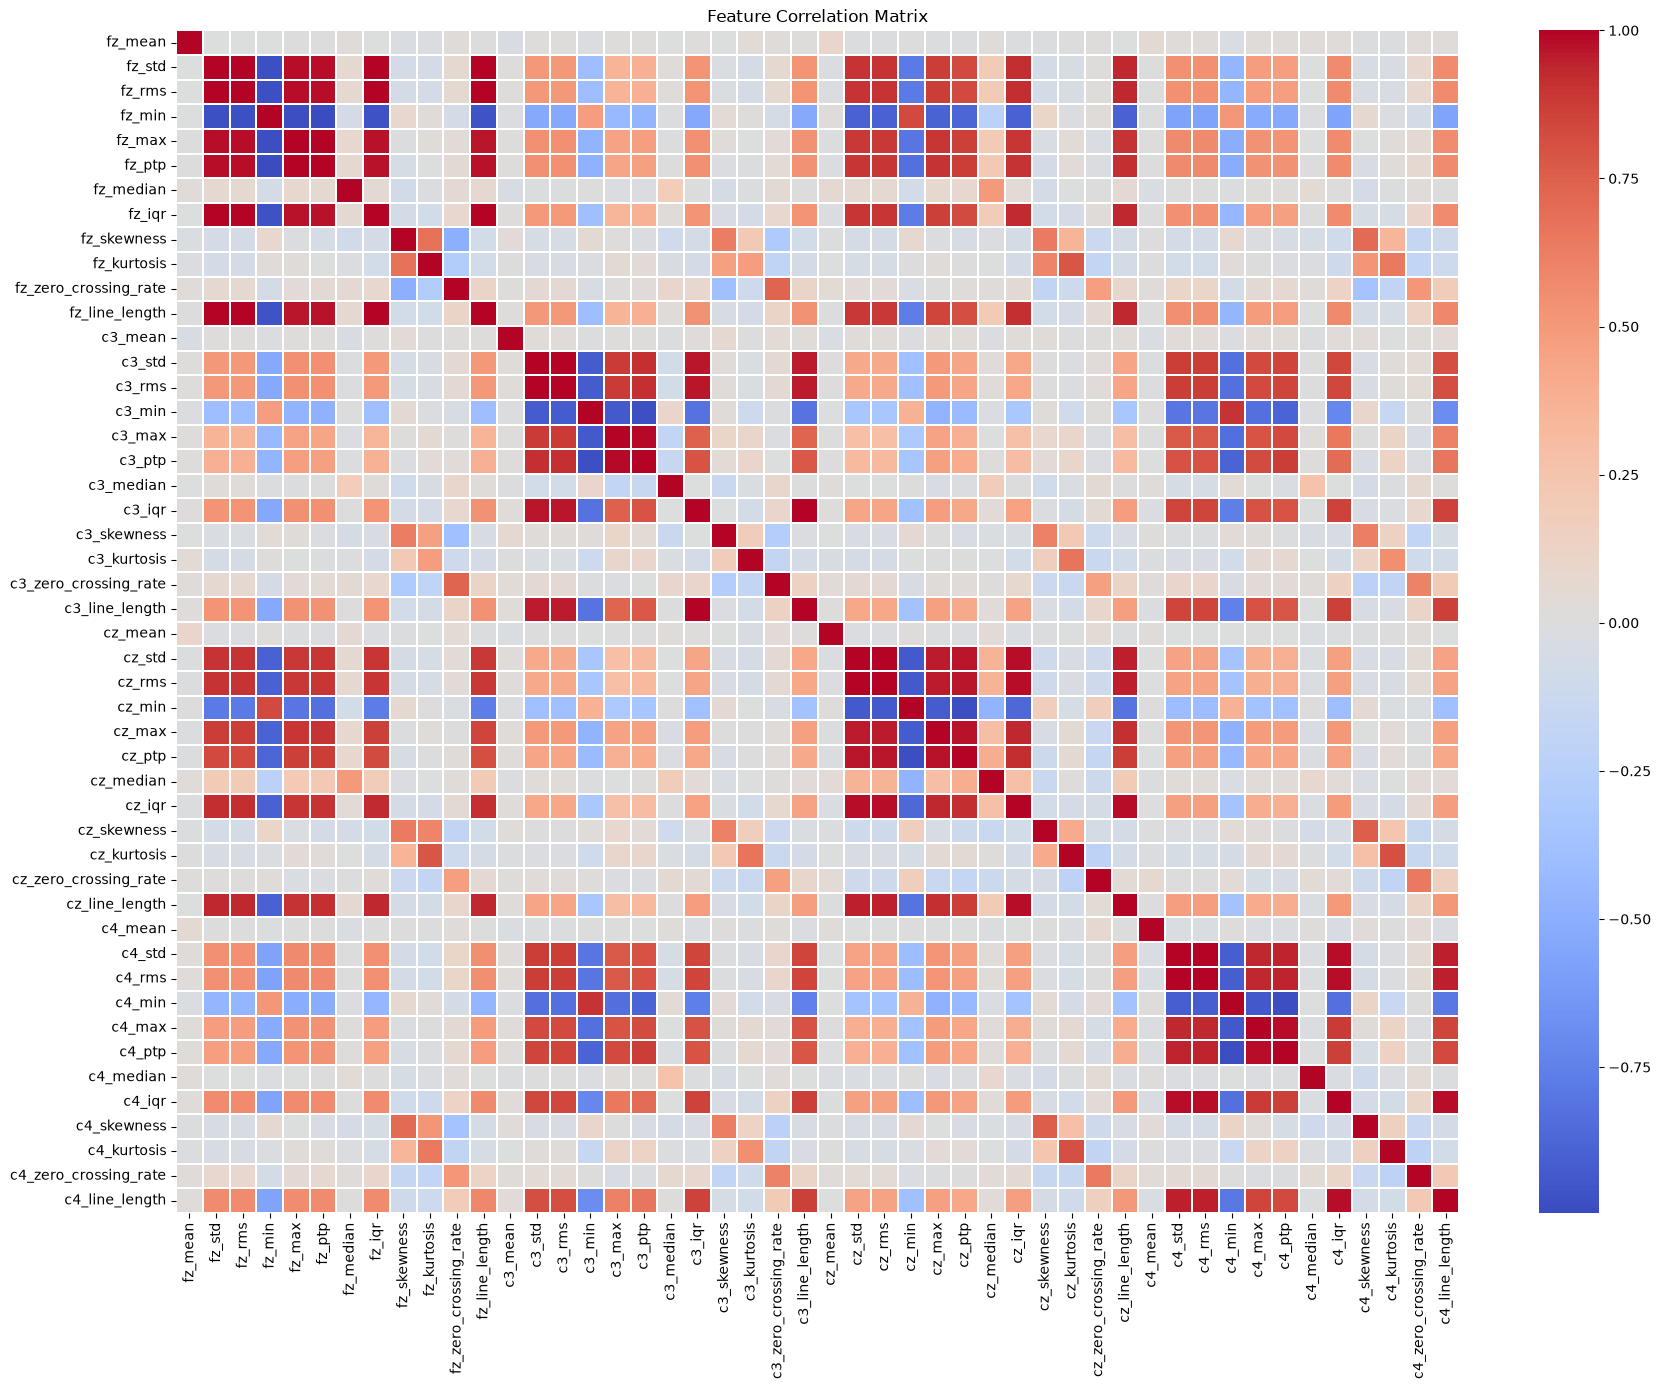

Highly correlated pairs: 80
Correlation reports saved successfully.


In [98]:
# Feature Correlation Analysis

import seaborn as sns
import matplotlib.pyplot as plt

feature_corr = X_features.corr()

# Extract highly correlated feature pairs
upper_triangle = feature_corr.where(
    np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
)

high_corr_pairs = (
    upper_triangle.stack()
    .reset_index()
)

high_corr_pairs.columns = [
    "Feature_1", "Feature_2", "Correlation"
]

high_corr_pairs["Abs_Correlation"] = (
    high_corr_pairs["Correlation"].abs()
)

high_corr_pairs = high_corr_pairs[
    high_corr_pairs["Abs_Correlation"] >= 0.90
].sort_values("Abs_Correlation", ascending=False)

# Save reports
feature_corr.to_csv(
    OUTPUT_DIR / "feature_correlation_matrix.csv"
)

high_corr_pairs.to_csv(
    OUTPUT_DIR / "highly_correlated_features.csv",
    index=False
)

# Visualize correlation matrix
plt.figure(figsize=(18, 14))

sns.heatmap(
    feature_corr,
    cmap="coolwarm",
    center=0,
    linewidths=0.1
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "feature_correlation_heatmap.png",
    dpi=300
)
plt.show()

print("Highly correlated pairs:", len(high_corr_pairs))
print("Correlation reports saved successfully.")

In [99]:
# Display highly correlated feature pairs

print("Highly Correlated Feature Pairs (|r| >= 0.90)")
print("=" * 65)

display(
    high_corr_pairs[
        ["Feature_1", "Feature_2", "Correlation"]
    ].round(4)
)

print("\nTotal highly correlated pairs:", len(high_corr_pairs))

Highly Correlated Feature Pairs (|r| >= 0.90)


,Feature_1,Feature_2,Correlation
1226,cz_std,cz_rms,1.0000
1814,c4_std,c4_rms,1.0000
50,fz_std,fz_rms,1.0000
638,c3_std,c3_rms,1.0000
103,fz_rms,fz_iqr,0.9979
...,...,...,...
275,fz_ptp,cz_line_length,0.9074
227,fz_max,cz_line_length,0.9055
759,c3_min,c4_min,0.9025
179,fz_min,cz_line_length,-0.9020



Total highly correlated pairs: 80


In [100]:
# Identify features involved in high correlation

feature_involvement = pd.concat([
    high_corr_pairs["Feature_1"],
    high_corr_pairs["Feature_2"]
]).value_counts()

redundant_features_df = pd.DataFrame({
    "feature": feature_involvement.index,
    "high_correlation_pairs": feature_involvement.values
})

redundant_features_df.to_csv(
    OUTPUT_DIR / "redundant_features_candidates.csv",
    index=False
)

print("Features involved in high correlations:")
display(redundant_features_df)

print(
    "\nUnique features involved:",
    len(redundant_features_df)
)

Features involved in high correlations:


,feature,high_correlation_pairs
0,cz_line_length,11
1,cz_iqr,10
2,fz_std,8
3,fz_rms,8
4,fz_iqr,8
5,fz_ptp,8
6,fz_line_length,8
7,fz_min,7
8,fz_max,7
9,cz_std,6



Unique features involved: 28


In [101]:
# Feature Selection Review - No automatic deletion

selection_review = []

for channel in channels:
    prefix = channel.lower()

    decisions = {
        f"{prefix}_mean": "Candidate for removal",
        f"{prefix}_rms": "Candidate for removal",
        f"{prefix}_std": "Keep",
        f"{prefix}_min": "Keep for evaluation",
        f"{prefix}_max": "Keep for evaluation",
        f"{prefix}_ptp": "Keep for evaluation",
        f"{prefix}_median": "Keep for evaluation",
        f"{prefix}_iqr": "Keep for evaluation",
        f"{prefix}_skewness": "Keep",
        f"{prefix}_kurtosis": "Keep",
        f"{prefix}_zero_crossing_rate": "Keep",
        f"{prefix}_line_length": "Keep"
    }

    for feature, decision in decisions.items():
        selection_review.append({
            "feature": feature,
            "channel": channel,
            "decision": decision
        })

selection_review_df = pd.DataFrame(selection_review)

selection_review_df.to_csv(
    OUTPUT_DIR / "feature_selection_review.csv",
    index=False
)

print(selection_review_df["decision"].value_counts())
print("\nFeature selection review saved.")

decision
Keep                     20
Keep for evaluation      20
Candidate for removal     8
Name: count, dtype: int64

Feature selection review saved.


In [102]:
# Final Pre-Modeling Audit Report

audit = {
    "dataset": {
        "trials": len(X_features),
        "channels": channels,
        "samples_per_trial": X_centered.shape[1],
        "total_features": X_features.shape[1],
        "classes": ["Left", "Right"],
        "left_trials": int((y_labels == 0).sum()),
        "right_trials": int((y_labels == 1).sum())
    },

    "data_quality": {
        "missing_values": int(X_features.isna().sum().sum()),
        "infinite_values": int(
            np.isinf(X_features.to_numpy()).sum()
        ),
        "removed_trials": int(
            artifact_assessment_df["removed_from_dataset"].sum()
        ),
        "trials_requiring_review": int(
            (artifact_assessment_df["recommended_action"] != "Retain").sum()
        )
    },

    "feature_engineering": {
        "method": "Time-domain statistical features",
        "features_per_channel": 12,
        "high_correlation_pairs": len(high_corr_pairs),
        "features_involved_in_high_correlations": len(
            redundant_features_df
        ),
        "keep": 20,
        "keep_for_evaluation": 20,
        "candidate_for_removal": 8,
        "feature_deletion_performed": False
    },

    "preprocessing": {
        "dc_offset_removal": "Applied",
        "bandpass_filter": "Not applied",
        "notch_filter": "Not applied",
        "resampling": "Not applied",
        "sampling_rate": "Unconfirmed",
        "timestamps": "Irregular"
    },

    "limitations": {
        "label_mapping": "Provisional",
        "sampling_rate_confirmation": "Pending",
        "artifact_review": "Pending",
        "modeling": "Not started"
    }
}

with open(OUTPUT_DIR / "final_pre_modeling_audit.json", "w") as f:
    json.dump(audit, f, indent=4)

print("Final Pre-Modeling Audit saved successfully.")

Final Pre-Modeling Audit saved successfully.


In [103]:
from scipy.signal import welch
from scipy.integrate import trapezoid
from scipy.stats import entropy

# Temporary assumption - must be updated after confirming the real sampling rate
FS = 250

frequency_bands = {
    "delta": (0.5, 4),
    "theta": (4, 8),
    "alpha": (8, 13),
    "mu": (8, 12),
    "beta": (13, 30),
    "gamma": (30, 40)
}

frequency_rows = []

for trial_idx in range(X_centered.shape[0]):
    for ch_idx, channel in enumerate(channels):

        signal = X_centered[trial_idx, :, ch_idx]

        freqs, psd = welch(
            signal,
            fs=FS,
            nperseg=1024,
            noverlap=512
        )

        total_power = trapezoid(psd, freqs)

        # Avoid division by zero
        psd_sum = psd.sum()
        probabilities = psd / psd_sum if psd_sum > 0 else np.zeros_like(psd)

        dominant_frequency = freqs[np.argmax(psd)]

        spectral_centroid = (
            np.sum(freqs * psd) / psd_sum
            if psd_sum > 0 else np.nan
        )

        spectral_bandwidth = (
            np.sqrt(
                np.sum(((freqs - spectral_centroid) ** 2) * psd) / psd_sum
            )
            if psd_sum > 0 else np.nan
        )

        spectral_entropy = (
            entropy(probabilities) / np.log(len(probabilities))
            if psd_sum > 0 and len(probabilities) > 1 else np.nan
        )

        row = {
            "trial_index": trial_idx + 1,
            "label": mapping_df.iloc[trial_idx]["label"],
            "channel": channel,
            "dominant_frequency": dominant_frequency,
            "total_power": total_power,
            "spectral_centroid": spectral_centroid,
            "spectral_bandwidth": spectral_bandwidth,
            "spectral_entropy": spectral_entropy
        }

        for band_name, (low, high) in frequency_bands.items():
            mask = (freqs >= low) & (freqs < high)

            band_power = (
                trapezoid(psd[mask], freqs[mask])
                if mask.sum() >= 2 else 0.0
            )

            row[f"{band_name}_power"] = band_power

            row[f"{band_name}_relative_power"] = (
                band_power / total_power
                if total_power > 0 else np.nan
            )

        frequency_rows.append(row)

frequency_features_df = pd.DataFrame(frequency_rows)

frequency_features_df.to_csv(
    OUTPUT_DIR / "frequency_domain_features.csv",
    index=False
)

print("Shape:", frequency_features_df.shape)
print("Missing values:", frequency_features_df.isna().sum().sum())
print("Infinite values:", np.isinf(
    frequency_features_df.select_dtypes(include=np.number)
).sum().sum())

display(frequency_features_df.head())

Shape: (8640, 20)
Missing values: 0
Infinite values: 0


,trial_index,label,channel,dominant_frequency,total_power,spectral_centroid,spectral_bandwidth,spectral_entropy,delta_power,delta_relative_power,theta_power,theta_relative_power,alpha_power,alpha_relative_power,mu_power,mu_relative_power,beta_power,beta_relative_power,gamma_power,gamma_relative_power
0,1,Left,FZ,50.048828,32802.792969,44.905714,15.074840,0.389741,1595.280029,0.048632,585.030090,0.017835,548.174683,0.016711,502.437286,0.015317,515.201355,0.015706,557.860596,0.017006
1,1,Left,C3,50.048828,31933.478516,44.168046,15.839835,0.402773,1635.002686,0.051200,665.952881,0.020854,689.672363,0.021597,636.040955,0.019918,567.938965,0.017785,573.447266,0.017958
2,1,Left,CZ,50.048828,77479.125000,41.508162,18.092305,0.435795,4908.350098,0.063351,2284.932861,0.029491,2394.570068,0.030906,2222.939209,0.028691,1751.006348,0.022600,1520.557129,0.019625
3,1,Left,C4,50.048828,179165.468750,43.091444,16.877858,0.414305,8909.845703,0.049730,5156.563965,0.028781,4098.815918,0.022877,3788.618652,0.021146,3660.865967,0.020433,3366.314941,0.018789
4,2,Right,FZ,50.048828,23003.144531,47.128927,11.592891,0.196126,476.700684,0.020723,36.095596,0.001569,49.284096,0.002142,46.352829,0.002015,9.762635,0.000424,2.092640,0.000091


In [104]:
frequency_comparison = (
    frequency_features_df
    .groupby(["channel", "label"])
    [[
        "dominant_frequency",
        "total_power",
        "spectral_centroid",
        "spectral_entropy",
        "mu_power",
        "beta_power",
        "mu_relative_power",
        "beta_relative_power"
    ]]
    .agg(["mean", "median", "std"])
    .round(4)
)

display(frequency_comparison)

frequency_comparison.to_csv(
    OUTPUT_DIR / "frequency_class_comparison.csv"
)

dominant_frequency                    total_power               \
                            mean   median      std         mean       median   
channel label                                                                  
C3      Left             47.8457  50.0488  10.0855   3064071.75  254019.5703   
        Right            47.5544  50.0488  10.7231   2930283.25  246879.8750   
C4      Left             48.4310  50.0488   8.6672   4481102.50  590355.0938   
        Right            47.7347  50.0488  10.3460   4397570.00  666892.4062   
CZ      Left             48.8915  50.0488   7.3036  15276684.00  769146.1250   
        Right            48.7942  50.0488   7.6119  13853262.00  816387.8125   
FZ      Left             48.3403  50.0488   8.9124   6412370.50  166983.2969   
        Right            48.0581  50.0488   9.6089   5792321.00  175127.1172   

                            spectral_centroid                   \
                        std              mean   median     std   
channel label                                                    
C3      Left   1.152170e+07           46.3650  49.6960  8.4647   
        Right  1.168534e+07           46.0752  49.7153  8.7635   
C4      Left   1.390331e+07           46.9940  49.8769  7.2492   
        Right  1.239662e+07           46.6063  49.8835  7.7294   
CZ      Left   5.625237e+07           47.1944  49.8493  6.8410   
        Right  5.251434e+07           47.3077  49.8556  6.4591   
FZ      Left   2.320121e+07           46.9771  49.7657  8.0331   
        Right  2.160656e+07           46.9457  49.7919  8.3606   

              spectral_entropy  ...     mu_power    beta_power           \
                          mean  ...          std          mean   median   
channel label                   ...                                       
C3      Left            0.2010  ...   10655.1241   1970.579346  13.5012   
        Right           0.2026  ...   24476.7362   3756.568115  14.4199   
C4      Left            0.1871  ...    8450.2539   1823.625244  13.2422   
        Right           0.1883  ...   12829.3995   3196.855225  13.6773   
CZ      Left            0.1897  ...  238385.9937  27516.199219  13.3175   
        Right           0.1890  ...  340771.0726  49829.367188  13.8701   
FZ      Left            0.1879  ...  105011.4782  10348.865234  13.3487   
        Right           0.1861  ...  114676.8035  14724.375977  13.8856   

                           mu_relative_power                  \
                       std              mean  median     std   
channel label                                                  
C3      Left    11120.0542            0.0024  0.0002  0.0072   
        Right   31587.9571            0.0028  0.0003  0.0064   
C4      Left    10837.4310            0.0013  0.0000  0.0034   
        Right   16747.3778            0.0014  0.0000  0.0037   
CZ      Left   343956.2259            0.0014  0.0001  0.0037   
        Right  488748.9535            0.0016  0.0001  0.0041   
FZ      Left   153543.6074            0.0015  0.0001  0.0034   
        Right  169101.2483            0.0016  0.0002  0.0038   

              beta_relative_power                  
                             mean  median     std  
channel label                                      
C3      Left               0.0026  0.0002  0.0069  
        Right              0.0029  0.0002  0.0076  
C4      Left               0.0017  0.0000  0.0046  
        Right              0.0018  0.0000  0.0048  
CZ      Left               0.0018  0.0000  0.0047  
        Right              0.0019  0.0000  0.0048  
FZ      Left               0.0019  0.0001  0.0047  
        Right              0.0020  0.0001  0.0049  

[8 rows x 24 columns]

In [105]:
mi_features = frequency_features_df[
    frequency_features_df["channel"].isin(["C3", "C4"])
].pivot(
    index=["trial_index", "label"],
    columns="channel",
    values=[
        "mu_power",
        "beta_power",
        "mu_relative_power",
        "beta_relative_power"
    ]
)

mi_features.columns = [
    f"{feature}_{channel.lower()}"
    for feature, channel in mi_features.columns
]

mi_features = mi_features.reset_index()

for channel in ["c3", "c4"]:
    mi_features[f"mu_beta_ratio_{channel}"] = (
        mi_features[f"mu_power_{channel}"] /
        (mi_features[f"beta_power_{channel}"] + 1e-10)
    )

mi_features["mu_power_c3_c4_difference"] = (
    mi_features["mu_power_c3"] - mi_features["mu_power_c4"]
)

mi_features["beta_power_c3_c4_difference"] = (
    mi_features["beta_power_c3"] - mi_features["beta_power_c4"]
)

mi_features.to_csv(
    OUTPUT_DIR / "motor_imagery_features.csv",
    index=False
)

print("Motor Imagery Features Shape:", mi_features.shape)
display(mi_features.head())

Motor Imagery Features Shape: (2160, 14)


,trial_index,label,mu_power_c3,mu_power_c4,beta_power_c3,beta_power_c4,mu_relative_power_c3,mu_relative_power_c4,beta_relative_power_c3,beta_relative_power_c4,mu_beta_ratio_c3,mu_beta_ratio_c4,mu_power_c3_c4_difference,beta_power_c3_c4_difference
0,1,Left,636.040955,3788.618652,567.938965,3660.865967,0.019918,0.021146,0.017785,0.020433,1.119911,1.034897,-3152.577637,-3092.927002
1,2,Right,66.326447,1962.653076,16.191650,183.229874,0.002063,0.004256,0.000504,0.000397,4.096336,10.711425,-1896.326660,-167.038223
2,3,Left,22.431753,633.299072,70.784943,1370.492920,0.000873,0.001839,0.002755,0.003979,0.316900,0.462096,-610.867310,-1299.708008
3,4,Left,267.890869,1526.358398,337.642029,2080.537842,0.006934,0.003962,0.008739,0.005400,0.793417,0.733636,-1258.467529,-1742.895752
4,5,Left,137.658173,1052.777954,96.641815,888.806641,0.006210,0.002958,0.004360,0.002498,1.424416,1.184485,-915.119751,-792.164795


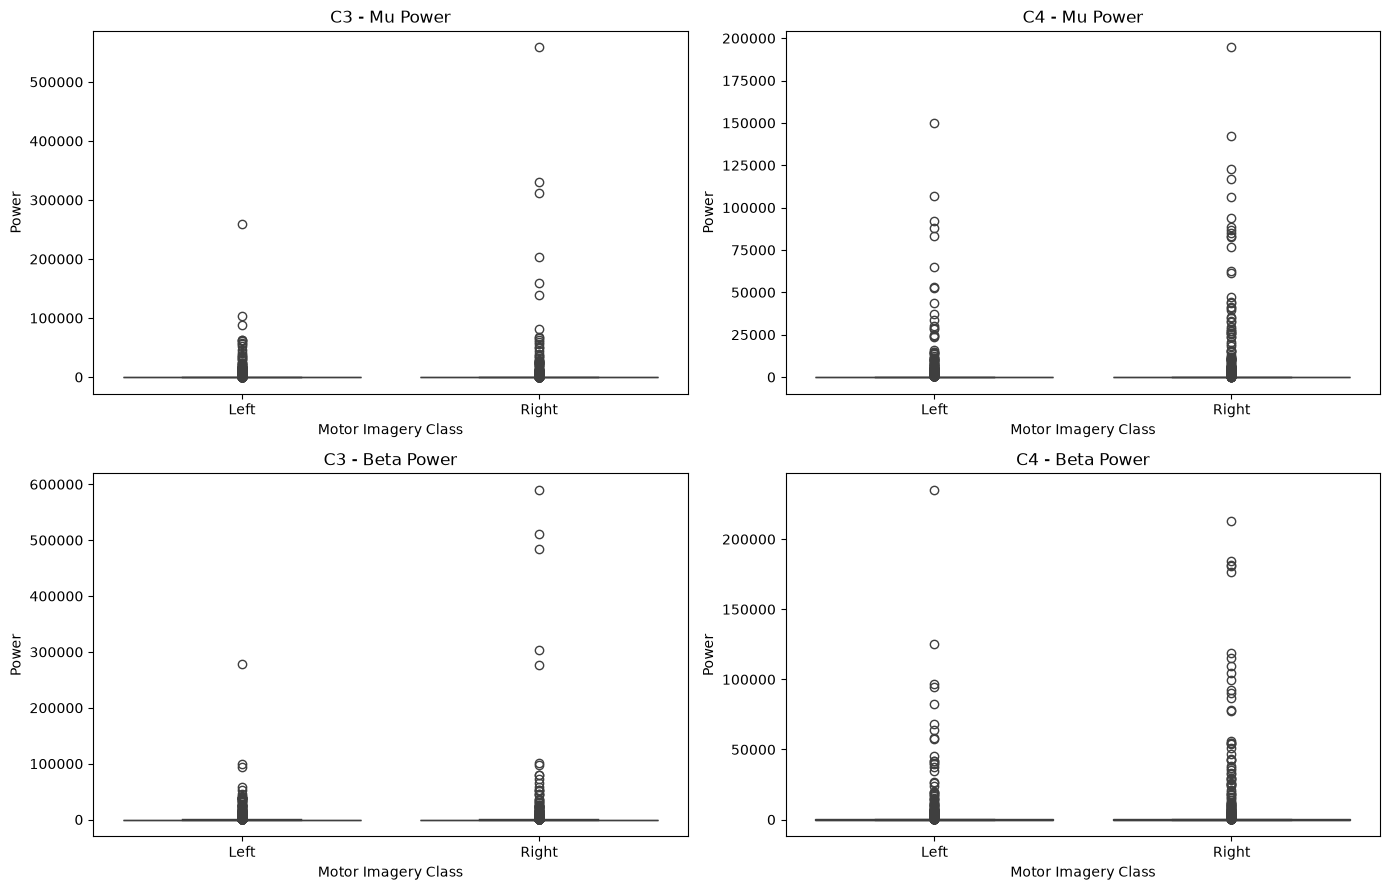

In [106]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

plot_items = [
    ("mu_power", "C3", axes[0, 0], "C3 - Mu Power"),
    ("mu_power", "C4", axes[0, 1], "C4 - Mu Power"),
    ("beta_power", "C3", axes[1, 0], "C3 - Beta Power"),
    ("beta_power", "C4", axes[1, 1], "C4 - Beta Power")
]

for feature, channel, ax, title in plot_items:
    sns.boxplot(
        data=frequency_features_df[
            frequency_features_df["channel"] == channel
        ],
        x="label",
        y=feature,
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Motor Imagery Class")
    ax.set_ylabel("Power")

plt.tight_layout()
plt.show()

In [107]:
from scipy.signal import welch
from scipy.integrate import trapezoid
from scipy.stats import entropy

# Temporary assumption - must be updated after confirming the real sampling rate
FS = 250

frequency_bands = {
    "delta": (0.5, 4),
    "theta": (4, 8),
    "alpha": (8, 13),
    "mu": (8, 12),
    "beta": (13, 30),
    "gamma": (30, 40)
}

frequency_rows = []

for trial_idx in range(X_centered.shape[0]):
    for ch_idx, channel in enumerate(channels):

        signal = X_centered[trial_idx, :, ch_idx]

        freqs, psd = welch(
            signal,
            fs=FS,
            nperseg=1024,
            noverlap=512
        )

        total_power = trapezoid(psd, freqs)

        # Avoid division by zero
        psd_sum = psd.sum()
        probabilities = psd / psd_sum if psd_sum > 0 else np.zeros_like(psd)

        dominant_frequency = freqs[np.argmax(psd)]

        spectral_centroid = (
            np.sum(freqs * psd) / psd_sum
            if psd_sum > 0 else np.nan
        )

        spectral_bandwidth = (
            np.sqrt(
                np.sum(((freqs - spectral_centroid) ** 2) * psd) / psd_sum
            )
            if psd_sum > 0 else np.nan
        )

        spectral_entropy = (
            entropy(probabilities) / np.log(len(probabilities))
            if psd_sum > 0 and len(probabilities) > 1 else np.nan
        )

        row = {
            "trial_index": trial_idx + 1,
            "label": mapping_df.iloc[trial_idx]["label"],
            "channel": channel,
            "dominant_frequency": dominant_frequency,
            "total_power": total_power,
            "spectral_centroid": spectral_centroid,
            "spectral_bandwidth": spectral_bandwidth,
            "spectral_entropy": spectral_entropy
        }

        for band_name, (low, high) in frequency_bands.items():
            mask = (freqs >= low) & (freqs < high)

            band_power = (
                trapezoid(psd[mask], freqs[mask])
                if mask.sum() >= 2 else 0.0
            )

            row[f"{band_name}_power"] = band_power

            row[f"{band_name}_relative_power"] = (
                band_power / total_power
                if total_power > 0 else np.nan
            )

        frequency_rows.append(row)

frequency_features_df = pd.DataFrame(frequency_rows)

frequency_features_df.to_csv(
    OUTPUT_DIR / "frequency_domain_features.csv",
    index=False
)

print("Shape:", frequency_features_df.shape)
print("Missing values:", frequency_features_df.isna().sum().sum())
print("Infinite values:", np.isinf(
    frequency_features_df.select_dtypes(include=np.number)
).sum().sum())

display(frequency_features_df.head())

Shape: (8640, 20)
Missing values: 0
Infinite values: 0


,trial_index,label,channel,dominant_frequency,total_power,spectral_centroid,spectral_bandwidth,spectral_entropy,delta_power,delta_relative_power,theta_power,theta_relative_power,alpha_power,alpha_relative_power,mu_power,mu_relative_power,beta_power,beta_relative_power,gamma_power,gamma_relative_power
0,1,Left,FZ,50.048828,32802.792969,44.905714,15.074840,0.389741,1595.280029,0.048632,585.030090,0.017835,548.174683,0.016711,502.437286,0.015317,515.201355,0.015706,557.860596,0.017006
1,1,Left,C3,50.048828,31933.478516,44.168046,15.839835,0.402773,1635.002686,0.051200,665.952881,0.020854,689.672363,0.021597,636.040955,0.019918,567.938965,0.017785,573.447266,0.017958
2,1,Left,CZ,50.048828,77479.125000,41.508162,18.092305,0.435795,4908.350098,0.063351,2284.932861,0.029491,2394.570068,0.030906,2222.939209,0.028691,1751.006348,0.022600,1520.557129,0.019625
3,1,Left,C4,50.048828,179165.468750,43.091444,16.877858,0.414305,8909.845703,0.049730,5156.563965,0.028781,4098.815918,0.022877,3788.618652,0.021146,3660.865967,0.020433,3366.314941,0.018789
4,2,Right,FZ,50.048828,23003.144531,47.128927,11.592891,0.196126,476.700684,0.020723,36.095596,0.001569,49.284096,0.002142,46.352829,0.002015,9.762635,0.000424,2.092640,0.000091


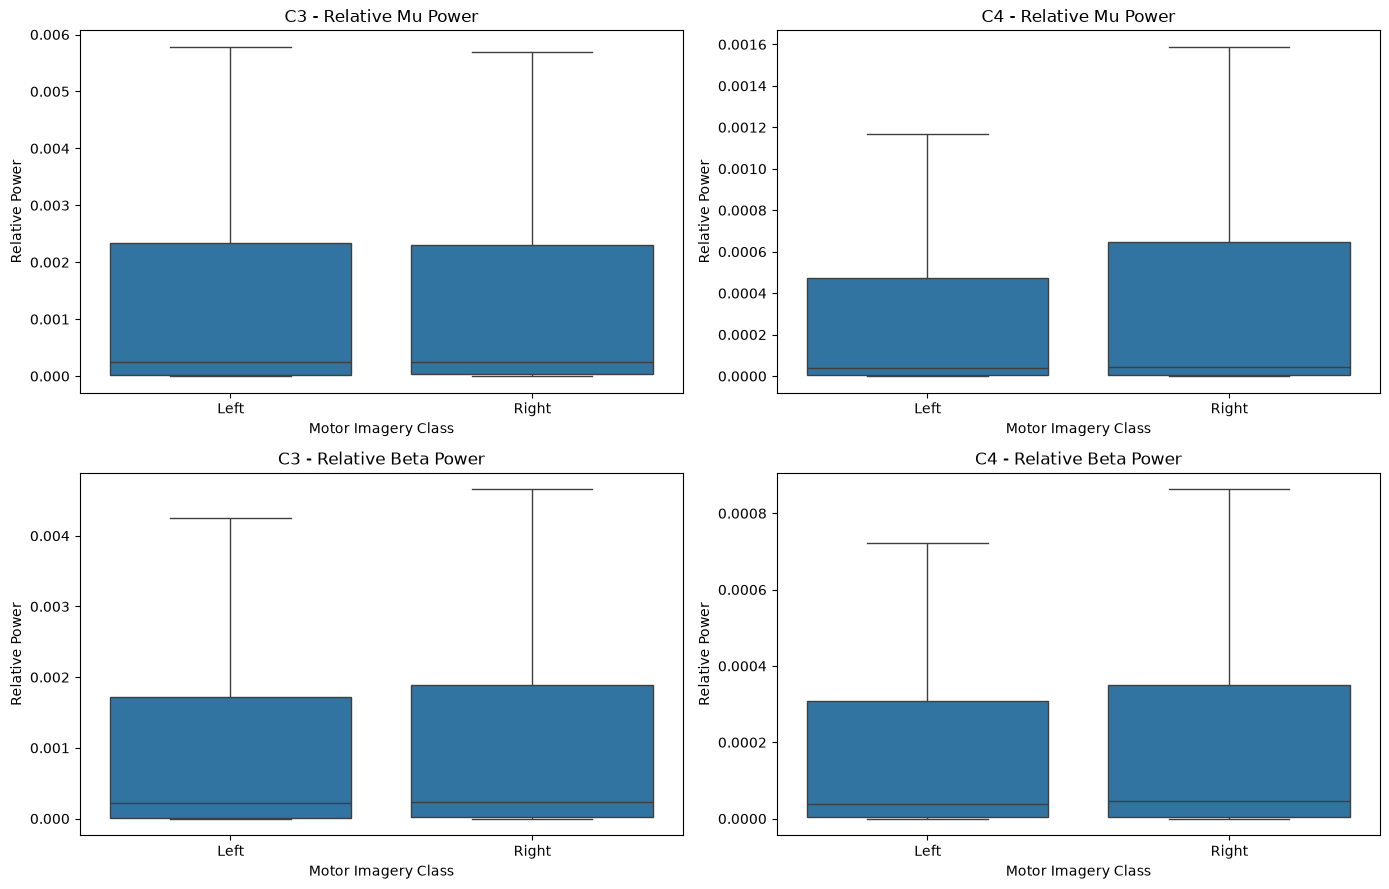

In [109]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

plot_items = [
    ("mu_relative_power", "C3", axes[0, 0], "C3 - Relative Mu Power"),
    ("mu_relative_power", "C4", axes[0, 1], "C4 - Relative Mu Power"),
    ("beta_relative_power", "C3", axes[1, 0], "C3 - Relative Beta Power"),
    ("beta_relative_power", "C4", axes[1, 1], "C4 - Relative Beta Power")
]

for feature, channel, ax, title in plot_items:
    data = frequency_features_df[
        frequency_features_df["channel"] == channel
    ].copy()

    sns.boxplot(
        data=data,
        x="label",
        y=feature,
        ax=ax,
        showfliers=False
    )

    ax.set_title(title)
    ax.set_xlabel("Motor Imagery Class")
    ax.set_ylabel("Relative Power")

plt.tight_layout()
plt.show()

In [110]:
relative_power_comparison = (
    frequency_features_df
    .groupby(["channel", "label"])[
        ["mu_relative_power", "beta_relative_power"]
    ]
    .agg(["mean", "median", "std"])
    .round(6)
)

display(relative_power_comparison)

mu_relative_power                     beta_relative_power  \
                           mean    median       std                mean   
channel label                                                             
C3      Left           0.002449  0.000243  0.007156            0.002648   
        Right          0.002788  0.000251  0.006351            0.002928   
C4      Left           0.001286  0.000041  0.003390            0.001691   
        Right          0.001444  0.000042  0.003707            0.001776   
CZ      Left           0.001435  0.000056  0.003727            0.001801   
        Right          0.001627  0.000051  0.004130            0.001865   
FZ      Left           0.001487  0.000143  0.003441            0.001940   
        Right          0.001597  0.000154  0.003766            0.001950   

                                   
                 median       std  
channel label                      
C3      Left   0.000223  0.006908  
        Right  0.000232  0.007622  
C4      Left   0.000038  0.004569  
        Right  0.000045  0.004758  
CZ      Left   0.000049  0.004663  
        Right  0.000045  0.004816  
FZ      Left   0.000125  0.004734  
        Right  0.000114  0.004865

In [111]:
from scipy.stats import mannwhitneyu
import numpy as np
import pandas as pd

features_to_test = [
    "mu_power",
    "beta_power",
    "mu_relative_power",
    "beta_relative_power"
]

results = []

for channel in channels:
    channel_data = frequency_features_df[
        frequency_features_df["channel"] == channel
    ]

    for feature in features_to_test:
        left = channel_data.loc[
            channel_data["label"] == "Left", feature
        ].dropna()

        right = channel_data.loc[
            channel_data["label"] == "Right", feature
        ].dropna()

        statistic, p_value = mannwhitneyu(
            left, right, alternative="two-sided"
        )

        effect_size = (
            2 * statistic / (len(left) * len(right)) - 1
        )

        results.append({
            "channel": channel,
            "feature": feature,
            "left_median": left.median(),
            "right_median": right.median(),
            "left_mean": left.mean(),
            "right_mean": right.mean(),
            "effect_size": effect_size,
            "p_value": p_value
        })

statistical_results = pd.DataFrame(results)

# Benjamini-Hochberg correction
p_values = statistical_results["p_value"].values
n = len(p_values)
order = np.argsort(p_values)
ranked_p = p_values[order]

adjusted = ranked_p * n / np.arange(1, n + 1)
adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
adjusted = np.clip(adjusted, 0, 1)

q_values = np.empty(n)
q_values[order] = adjusted

statistical_results["q_value"] = q_values
statistical_results["significant"] = (
    statistical_results["q_value"] < 0.05
)

statistical_results = statistical_results.sort_values("q_value")

display(statistical_results.round(6))

statistical_results.to_csv(
    OUTPUT_DIR / "motor_imagery_statistical_tests.csv",
    index=False
)

,channel,feature,left_median,right_median,left_mean,right_mean,effect_size,p_value,q_value,significant
0,FZ,mu_power,16.718666,17.022591,7282.523438,10409.538086,-0.010830,0.663010,0.931187,False
1,FZ,beta_power,13.348710,13.885629,10348.865234,14724.375977,-0.008107,0.744280,0.931187,False
2,FZ,mu_relative_power,0.000143,0.000154,0.001487,0.001597,-0.003650,0.883267,0.931187,False
3,FZ,beta_relative_power,0.000125,0.000114,0.001940,0.001950,-0.004734,0.848940,0.931187,False
4,C3,mu_power,22.415260,21.258579,1785.976807,3027.560791,-0.006432,0.795806,0.931187,False
5,C3,beta_power,13.501234,14.419853,1970.579468,3756.567627,-0.012747,0.608021,0.931187,False
6,C3,mu_relative_power,0.000243,0.000251,0.002449,0.002788,-0.022464,0.366040,0.931187,False
7,C3,beta_relative_power,0.000223,0.000232,0.002648,0.002928,-0.024458,0.325036,0.931187,False
8,CZ,mu_power,19.432680,19.112904,19975.144531,35407.000000,-0.006279,0.800548,0.931187,False
9,CZ,beta_power,13.317507,13.870105,27516.197266,49829.367188,-0.005684,0.819105,0.931187,False


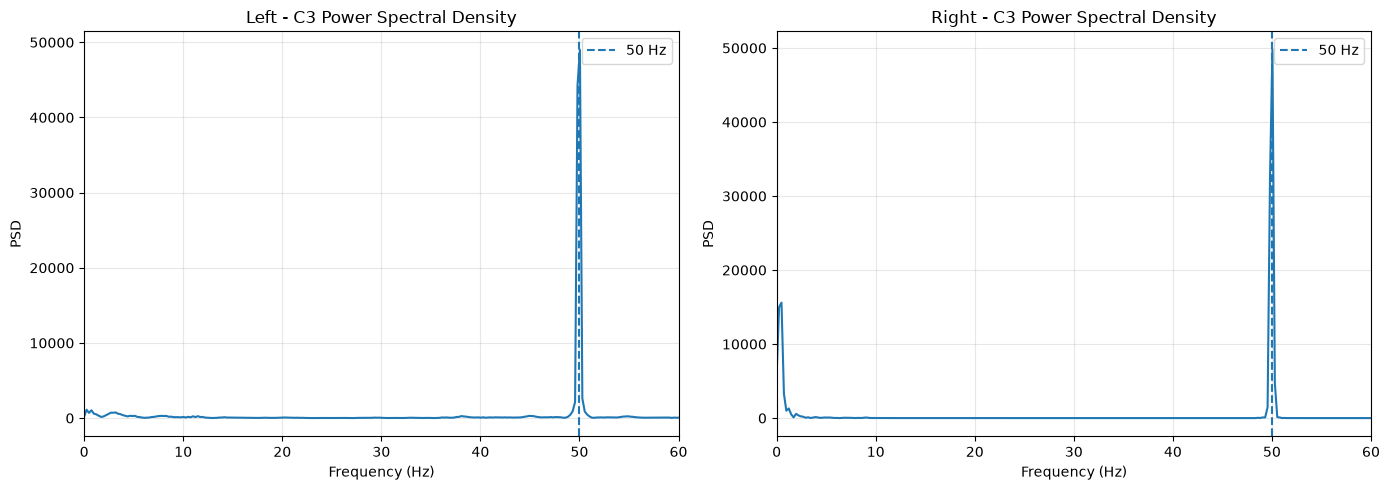

In [112]:
from scipy.signal import welch

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for label, ax in zip(["Left", "Right"], axes):

    trial_idx = mapping_df.index[
        mapping_df["label"] == label
    ][0]

    signal = X_centered[trial_idx, :, channels.index("C3")]

    freqs, psd = welch(
        signal,
        fs=FS,
        nperseg=1024,
        noverlap=512
    )

    ax.plot(freqs, psd)
    ax.axvline(50, linestyle="--", label="50 Hz")
    ax.set_xlim(0, 60)
    ax.set_title(f"{label} - C3 Power Spectral Density")
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("PSD")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [113]:
line_noise_rows = []

for trial_idx in range(X_centered.shape[0]):
    for ch_idx, channel in enumerate(channels):

        signal = X_centered[trial_idx, :, ch_idx]

        freqs, psd = welch(
            signal,
            fs=FS,
            nperseg=1024,
            noverlap=512
        )

        total_power = trapezoid(psd, freqs)

        # Power around 50 Hz
        line_mask = (freqs >= 49) & (freqs <= 51)

        # Very low frequency power
        low_mask = (freqs >= 0) & (freqs <= 1)

        line_power = trapezoid(psd[line_mask], freqs[line_mask])
        low_power = trapezoid(psd[low_mask], freqs[low_mask])

        dominant_frequency = freqs[np.argmax(psd)]

        line_noise_rows.append({
            "trial_index": trial_idx + 1,
            "label": mapping_df.iloc[trial_idx]["label"],
            "channel": channel,
            "line_50hz_relative_power": (
                line_power / total_power if total_power > 0 else np.nan
            ),
            "low_frequency_relative_power": (
                low_power / total_power if total_power > 0 else np.nan
            ),
            "dominant_frequency": dominant_frequency,
            "peak_near_50hz": 49 <= dominant_frequency <= 51
        })

line_noise_df = pd.DataFrame(line_noise_rows)

line_noise_summary = (
    line_noise_df
    .groupby(["channel", "label"])
    .agg(
        mean_50hz_power=("line_50hz_relative_power", "mean"),
        median_50hz_power=("line_50hz_relative_power", "median"),
        mean_low_frequency_power=("low_frequency_relative_power", "mean"),
        trials_with_50hz_peak=("peak_near_50hz", "sum"),
        total_trials=("trial_index", "count")
    )
    .round(5)
)

display(line_noise_summary)

line_noise_df.to_csv(
    OUTPUT_DIR / "line_noise_assessment.csv",
    index=False
)

line_noise_summary.to_csv(
    OUTPUT_DIR / "line_noise_summary.csv"
)

mean_50hz_power  median_50hz_power  mean_low_frequency_power  \
channel label                                                                 
C3      Left           0.90841            0.98957                   0.04331   
        Right          0.90301            0.98863                   0.04731   
C4      Left           0.92612            0.99524                   0.04032   
        Right          0.91848            0.99482                   0.04672   
CZ      Left           0.92942            0.99471                   0.03131   
        Right          0.93194            0.99489                   0.02852   
FZ      Left           0.92538            0.99359                   0.03976   
        Right          0.92491            0.99422                   0.03992   

               trials_with_50hz_peak  total_trials  
channel label                                       
C3      Left                    1035          1082  
        Right                   1025          1078  
C4      Left                    1048          1082  
        Right                   1029          1078  
CZ      Left                    1058          1082  
        Right                   1052          1078  
FZ      Left                    1046          1082  
        Right                   1036          1078

In [114]:
from scipy.signal import welch
import numpy as np
import pandas as pd

peak_analysis = []

for trial_idx in range(X_centered.shape[0]):
    for ch_idx, channel in enumerate(channels):

        signal = X_centered[trial_idx, :, ch_idx]

        freqs, psd = welch(
            signal,
            fs=FS,
            nperseg=1024,
            noverlap=512
        )

        # Frequency around 50 Hz
        mask_50 = (freqs >= 45) & (freqs <= 55)

        local_freqs = freqs[mask_50]
        local_psd = psd[mask_50]

        peak_idx = np.argmax(local_psd)

        peak_analysis.append({
            "trial_index": trial_idx + 1,
            "label": mapping_df.iloc[trial_idx]["label"],
            "channel": channel,
            "peak_frequency": local_freqs[peak_idx],
            "peak_psd": local_psd[peak_idx],
            "mean_local_psd": np.mean(local_psd),
            "peak_to_mean_ratio": (
                local_psd[peak_idx] / np.mean(local_psd)
                if np.mean(local_psd) > 0 else np.nan
            )
        })

peak_analysis_df = pd.DataFrame(peak_analysis)

peak_summary = (
    peak_analysis_df
    .groupby(["channel", "label"])
    .agg(
        mean_peak_frequency=("peak_frequency", "mean"),
        median_peak_frequency=("peak_frequency", "median"),
        mean_peak_strength=("peak_to_mean_ratio", "mean")
    )
    .round(4)
)

display(peak_summary)

peak_analysis_df.to_csv(
    OUTPUT_DIR / "50hz_peak_analysis.csv",
    index=False
)

mean_peak_frequency  median_peak_frequency  mean_peak_strength
channel label                                                                
C3      Left               49.9902                50.0488           23.485701
        Right              49.9897                50.0488           23.578300
C4      Left               49.9904                50.0488           23.618700
        Right              49.9906                50.0488           23.662300
CZ      Left               49.9906                50.0488           23.594200
        Right              49.9904                50.0488           23.624300
FZ      Left               49.9908                50.0488           23.607000
        Right              49.9906                50.0488           23.657400

In [115]:
# 1. Prepare Time-Domain Features
time_features = final_features_df.copy()

# 2. Prepare Frequency-Domain Features
frequency_wide = frequency_features_df.pivot(
    index=["trial_index", "label"],
    columns="channel",
    values=[
        "dominant_frequency",
        "total_power",
        "spectral_centroid",
        "spectral_bandwidth",
        "spectral_entropy",
        "delta_power",
        "delta_relative_power",
        "theta_power",
        "theta_relative_power",
        "alpha_power",
        "alpha_relative_power",
        "mu_power",
        "mu_relative_power",
        "beta_power",
        "beta_relative_power",
        "gamma_power",
        "gamma_relative_power"
    ]
)

frequency_wide.columns = [
    f"{feature}_{channel.lower()}"
    for feature, channel in frequency_wide.columns
]

frequency_wide = frequency_wide.reset_index()

# 3. Prepare Motor Imagery Features
mi_features_clean = mi_features.copy()

# 4. Merge all feature groups
combined_features_df = (
    time_features
    .merge(
        frequency_wide,
        on=["trial_index", "label"],
        validate="one_to_one"
    )
    .merge(
        mi_features_clean,
        on=["trial_index", "label"],
        validate="one_to_one",
        suffixes=("", "_mi")
    )
)

# 5. Validation
print("Combined Dataset Shape:", combined_features_df.shape)
print("Duplicate Trials:", combined_features_df["trial_index"].duplicated().sum())
print("Missing Values:", combined_features_df.isna().sum().sum())
print(
    "Infinite Values:",
    np.isinf(
        combined_features_df.select_dtypes(include=np.number)
    ).sum().sum()
)

display(combined_features_df.head())

combined_features_df.to_csv(
    OUTPUT_DIR / "combined_pre_modeling_features.csv",
    index=False
)

Combined Dataset Shape: (2160, 130)
Duplicate Trials: 0
Missing Values: 0
Infinite Values: 0


,trial_index,label,fz_mean,fz_std,fz_rms,fz_min,fz_max,fz_ptp,fz_median,fz_iqr,...,beta_power_c3_mi,beta_power_c4_mi,mu_relative_power_c3_mi,mu_relative_power_c4_mi,beta_relative_power_c3_mi,beta_relative_power_c4_mi,mu_beta_ratio_c3,mu_beta_ratio_c4,mu_power_c3_c4_difference,beta_power_c3_c4_difference
0,1,Left,-0.248475,182.328857,182.329025,-280.84375,316.12500,596.96875,-13.578125,349.101562,...,567.938965,3660.865967,0.019918,0.021146,0.017785,0.020433,1.119911,1.034897,-3152.577637,-3092.927002
1,2,Right,0.356313,157.600586,157.600983,-335.78125,310.28125,646.06250,15.828125,269.101562,...,16.191650,183.229874,0.002063,0.004256,0.000504,0.000397,4.096336,10.711425,-1896.326660,-167.038223
2,3,Left,0.319150,162.078629,162.078949,-286.12500,269.34375,555.46875,-2.937500,315.687500,...,70.784943,1370.492920,0.000873,0.001839,0.002755,0.003979,0.316900,0.462096,-610.867310,-1299.708008
3,4,Left,0.381325,145.818665,145.819153,-358.03125,296.96875,655.00000,4.875000,265.531250,...,337.642029,2080.537842,0.006934,0.003962,0.008739,0.005400,0.793417,0.733636,-1258.467529,-1742.895752
4,5,Left,-0.425250,136.761200,136.761856,-285.81250,296.65625,582.46875,-1.156250,260.179688,...,96.641815,888.806641,0.006210,0.002958,0.004360,0.002498,1.424416,1.184485,-915.119751,-792.164795


In [116]:
# Remove duplicated MI columns already present in frequency features
duplicate_mi_columns = [
    col for col in combined_features_df.columns
    if col.endswith("_mi")
]

combined_features_df = combined_features_df.drop(
    columns=duplicate_mi_columns
)

print("Removed duplicate columns:", len(duplicate_mi_columns))
print("Final shape:", combined_features_df.shape)
print("Missing values:", combined_features_df.isna().sum().sum())

display(combined_features_df.head())

Removed duplicate columns: 8
Final shape: (2160, 122)
Missing values: 0


,trial_index,label,fz_mean,fz_std,fz_rms,fz_min,fz_max,fz_ptp,fz_median,fz_iqr,...,gamma_power_cz,gamma_power_fz,gamma_relative_power_c3,gamma_relative_power_c4,gamma_relative_power_cz,gamma_relative_power_fz,mu_beta_ratio_c3,mu_beta_ratio_c4,mu_power_c3_c4_difference,beta_power_c3_c4_difference
0,1,Left,-0.248475,182.328857,182.329025,-280.84375,316.12500,596.96875,-13.578125,349.101562,...,1520.557129,557.860596,0.017958,0.018789,0.019625,0.017006,1.119911,1.034897,-3152.577637,-3092.927002
1,2,Right,0.356313,157.600586,157.600983,-335.78125,310.28125,646.06250,15.828125,269.101562,...,17.135025,2.092640,0.000109,0.000073,0.000105,0.000091,4.096336,10.711425,-1896.326660,-167.038223
2,3,Left,0.319150,162.078629,162.078949,-286.12500,269.34375,555.46875,-2.937500,315.687500,...,181.161713,32.427044,0.001304,0.001743,0.001454,0.001273,0.316900,0.462096,-610.867310,-1299.708008
3,4,Left,0.381325,145.818665,145.819153,-358.03125,296.96875,655.00000,4.875000,265.531250,...,536.555298,65.233414,0.002105,0.003873,0.002477,0.002946,0.793417,0.733636,-1258.467529,-1742.895752
4,5,Left,-0.425250,136.761200,136.761856,-285.81250,296.65625,582.46875,-1.156250,260.179688,...,385.727142,51.563122,0.002866,0.002265,0.002702,0.002602,1.424416,1.184485,-915.119751,-792.164795


In [117]:
# Separate metadata and numerical features
metadata_columns = ["trial_index", "label"]

X_features = combined_features_df.drop(
    columns=metadata_columns
)

# Feature quality report
feature_quality_report = pd.DataFrame({
    "feature": X_features.columns,
    "missing_values": X_features.isna().sum().values,
    "infinite_values": np.isinf(X_features).sum().values,
    "unique_values": X_features.nunique().values,
    "mean": X_features.mean().values,
    "std": X_features.std().values
})

feature_quality_report["is_constant"] = (
    feature_quality_report["unique_values"] <= 1
)

display(feature_quality_report)

feature_quality_report.to_csv(
    OUTPUT_DIR / "combined_feature_quality_report.csv",
    index=False
)

print("Total features:", X_features.shape[1])
print("Constant features:", feature_quality_report["is_constant"].sum())

,feature,missing_values,infinite_values,unique_values,mean,std,is_constant
0,fz_mean,0,0,2105,-0.021186,0.494883,False
1,fz_std,0,0,2124,1267.297852,2132.022705,False
2,fz_rms,0,0,2123,1267.298462,2132.022217,False
3,fz_min,0,0,2095,-2052.838379,3340.750732,False
4,fz_max,0,0,2097,2055.581055,3298.530273,False
...,...,...,...,...,...,...,...
115,gamma_relative_power_fz,0,0,2124,0.001244,0.003457,False
116,mu_beta_ratio_c3,0,0,2124,1.714349,1.642291,False
117,mu_beta_ratio_c4,0,0,2124,1.588215,1.516156,False
118,mu_power_c3_c4_difference,0,0,2124,406.206818,13974.389648,False


Total features: 120
Constant features: 0


In [118]:
# Correlation between numerical features
feature_corr = X_features.corr(method="pearson")

# Extract upper triangle to avoid duplicate pairs
upper_triangle = feature_corr.where(
    np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
)

correlation_threshold = 0.95

high_corr_pairs = (
    upper_triangle.stack()
    .reset_index()
)

high_corr_pairs.columns = [
    "feature_1",
    "feature_2",
    "correlation"
]

high_corr_pairs["abs_correlation"] = (
    high_corr_pairs["correlation"].abs()
)

high_corr_pairs = high_corr_pairs[
    high_corr_pairs["abs_correlation"] >= correlation_threshold
].sort_values(
    "abs_correlation",
    ascending=False
)

print("Highly correlated pairs:", len(high_corr_pairs))
display(high_corr_pairs.head(30))

high_corr_pairs.to_csv(
    OUTPUT_DIR / "highly_correlated_feature_pairs.csv",
    index=False
)

feature_corr.to_csv(
    OUTPUT_DIR / "combined_feature_correlation_matrix.csv"
)

Highly correlated pairs: 80


,feature_1,feature_2,correlation,abs_correlation
3026,cz_std,cz_rms,1.000000,1.000000
4478,c4_std,c4_rms,1.000000,1.000000
122,fz_std,fz_rms,1.000000,1.000000
1574,c3_std,c3_rms,1.000000,1.000000
10535,alpha_power_fz,mu_power_fz,0.998533,0.998533
10414,alpha_power_cz,mu_power_cz,0.998307,0.998307
10172,alpha_power_c3,mu_power_c3,0.998170,0.998170
247,fz_rms,fz_iqr,0.997879,0.997879
127,fz_std,fz_iqr,0.997879,0.997879
11019,alpha_relative_power_fz,mu_relative_power_fz,0.997106,0.997106


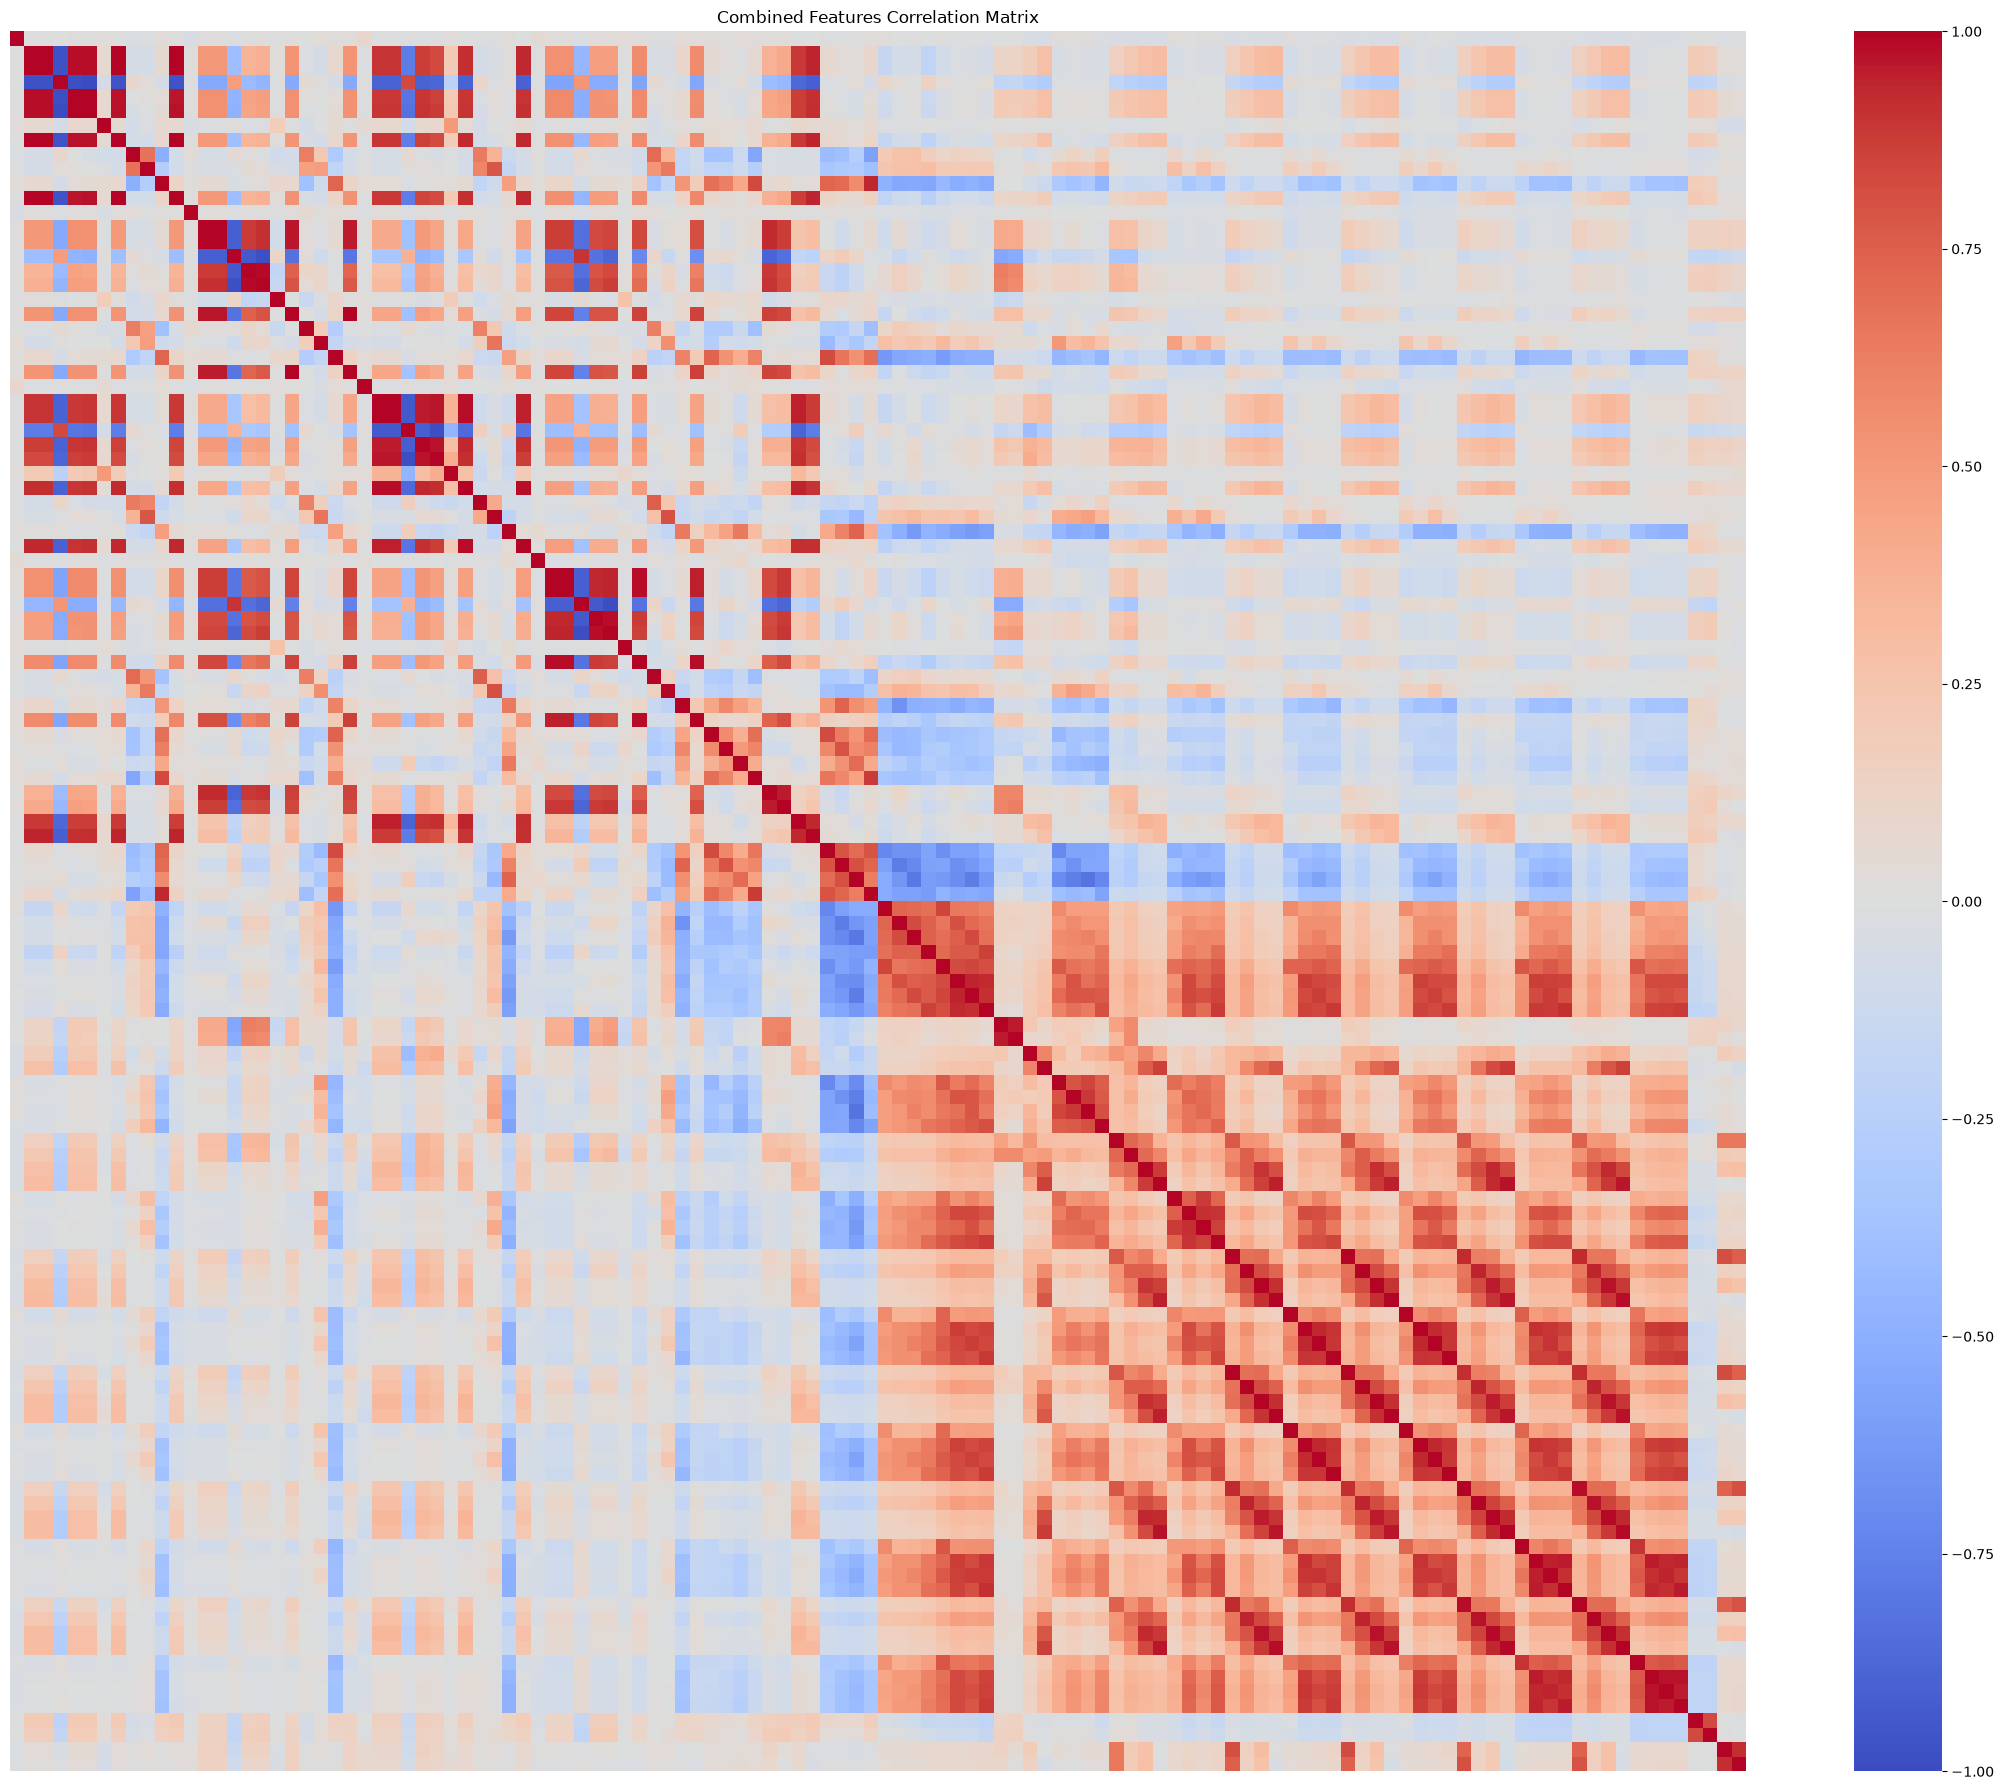

In [119]:
plt.figure(figsize=(22, 18))

sns.heatmap(
    feature_corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    xticklabels=False,
    yticklabels=False
)

plt.title("Combined Features Correlation Matrix")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "combined_feature_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [120]:
def classify_correlation(row):
    f1 = row["feature_1"]
    f2 = row["feature_2"]

    # Same statistical feature family
    if f1.replace("_std", "").replace("_rms", "") == \
       f2.replace("_std", "").replace("_rms", ""):
        return "STD-RMS Redundancy"

    # Alpha and Mu overlap
    if ("alpha" in f1 and "mu" in f2) or \
       ("mu" in f1 and "alpha" in f2):
        return "Alpha-Mu Overlap"

    # Power-related features
    if ("beta_power" in f1 and "gamma_power" in f2) or \
       ("gamma_power" in f1 and "beta_power" in f2):
        return "Beta-Gamma Relationship"

    # Time-domain amplitude features
    time_features = [
        "min", "max", "ptp", "std", "rms",
        "iqr", "line_length"
    ]

    if any(
        f1.endswith("_" + x) and
        f2.endswith("_" + y)
        for x in time_features
        for y in time_features
    ):
        return "Time-Domain Relationship"

    return "Other Relationship"


high_corr_pairs["relationship_type"] = (
    high_corr_pairs.apply(classify_correlation, axis=1)
)

relationship_summary = (
    high_corr_pairs["relationship_type"]
    .value_counts()
    .rename_axis("relationship_type")
    .reset_index(name="number_of_pairs")
)

display(relationship_summary)
display(high_corr_pairs.head(40))

high_corr_pairs.to_csv(
    OUTPUT_DIR / "correlation_relationship_analysis.csv",
    index=False
)

,relationship_type,number_of_pairs
0,Time-Domain Relationship,43
1,Other Relationship,21
2,Alpha-Mu Overlap,8
3,STD-RMS Redundancy,4
4,Beta-Gamma Relationship,4


,feature_1,feature_2,correlation,abs_correlation,relationship_type
3026,cz_std,cz_rms,1.000000,1.000000,STD-RMS Redundancy
4478,c4_std,c4_rms,1.000000,1.000000,STD-RMS Redundancy
122,fz_std,fz_rms,1.000000,1.000000,STD-RMS Redundancy
1574,c3_std,c3_rms,1.000000,1.000000,STD-RMS Redundancy
10535,alpha_power_fz,mu_power_fz,0.998533,0.998533,Alpha-Mu Overlap
10414,alpha_power_cz,mu_power_cz,0.998307,0.998307,Alpha-Mu Overlap
10172,alpha_power_c3,mu_power_c3,0.998170,0.998170,Alpha-Mu Overlap
247,fz_rms,fz_iqr,0.997879,0.997879,Time-Domain Relationship
127,fz_std,fz_iqr,0.997879,0.997879,Time-Domain Relationship
11019,alpha_relative_power_fz,mu_relative_power_fz,0.997106,0.997106,Alpha-Mu Overlap


In [121]:
# Count strong correlations for every feature
feature_involvement = pd.concat([
    high_corr_pairs["feature_1"],
    high_corr_pairs["feature_2"]
]).value_counts()

feature_review_df = pd.DataFrame({
    "feature": X_features.columns
})

feature_review_df["high_correlation_count"] = (
    feature_review_df["feature"]
    .map(feature_involvement)
    .fillna(0)
    .astype(int)
)

feature_review_df["review_priority"] = np.where(
    feature_review_df["high_correlation_count"] >= 5,
    "High",
    np.where(
        feature_review_df["high_correlation_count"] >= 2,
        "Medium",
        "Low"
    )
)

feature_review_df = feature_review_df.sort_values(
    "high_correlation_count",
    ascending=False
)

display(feature_review_df)

feature_review_df.to_csv(
    OUTPUT_DIR / "feature_redundancy_review.csv",
    index=False
)

,feature,high_correlation_count,review_priority
1,fz_std,6,High
2,fz_rms,6,High
3,fz_min,6,High
4,fz_max,6,High
7,fz_iqr,6,High
...,...,...,...
112,gamma_relative_power_c3,0,Low
116,mu_beta_ratio_c3,0,Low
117,mu_beta_ratio_c4,0,Low
118,mu_power_c3_c4_difference,0,Low


In [122]:
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# Select time-domain features only
metadata_cols = ["trial_index", "label"]

time_features = [
    col for col in final_features_df.select_dtypes(include=np.number).columns
    if col not in metadata_cols
]

left_data = final_features_df[
    final_features_df["label"].str.lower() == "left"
]

right_data = final_features_df[
    final_features_df["label"].str.lower() == "right"
]

results = []

for feature in time_features:

    left_values = left_data[feature].dropna()
    right_values = right_data[feature].dropna()

    statistic, p_value = mannwhitneyu(
        left_values,
        right_values,
        alternative="two-sided"
    )

    n_left = len(left_values)
    n_right = len(right_values)

    effect_size = (
        (2 * statistic) / (n_left * n_right)
    ) - 1

    results.append({
        "feature": feature,
        "left_median": left_values.median(),
        "right_median": right_values.median(),
        "left_mean": left_values.mean(),
        "right_mean": right_values.mean(),
        "U_statistic": statistic,
        "effect_size": effect_size,
        "p_value": p_value
    })

time_domain_stats = pd.DataFrame(results)

# Correct for multiple comparisons
time_domain_stats["q_value"] = multipletests(
    time_domain_stats["p_value"],
    method="fdr_bh"
)[1]

time_domain_stats["significant"] = (
    time_domain_stats["q_value"] < 0.05
)

time_domain_stats["abs_effect_size"] = (
    time_domain_stats["effect_size"].abs()
)

time_domain_stats = time_domain_stats.sort_values(
    ["q_value", "abs_effect_size"]
)

display(time_domain_stats)

time_domain_stats.to_csv(
    OUTPUT_DIR / "time_domain_statistical_comparison.csv",
    index=False
)

print("Total features tested:", len(time_domain_stats))
print(
    "Significant features:",
    time_domain_stats["significant"].sum()
)

,feature,left_median,right_median,left_mean,right_mean,U_statistic,effect_size,p_value,q_value,significant,abs_effect_size
34,cz_zero_crossing_rate,0.399360,0.399360,0.382027,0.382932,582402.0,-0.001365,0.955700,0.9557,False,0.001365
21,c3_kurtosis,-1.449569,-1.455313,-0.902107,-0.886636,582361.0,-0.001435,0.953974,0.9557,False,0.001435
10,fz_zero_crossing_rate,0.399360,0.399360,0.379910,0.378972,582354.0,-0.001447,0.952935,0.9557,False,0.001447
11,fz_line_length,411.335022,416.298096,1315.741455,1256.903320,581927.0,-0.002179,0.930145,0.9557,False,0.002179
3,fz_min,-698.000000,-763.578125,-2096.750244,-2008.764160,584662.0,0.002510,0.919567,0.9557,False,0.002510
33,cz_kurtosis,-1.472181,-1.472455,-1.136696,-1.109868,581330.0,-0.003203,0.897473,0.9557,False,0.003203
30,cz_median,-1.031250,-1.539062,4.858393,15.382537,585504.5,0.003955,0.873582,0.9557,False,0.003955
7,fz_iqr,774.234375,798.035156,2492.169678,2385.540771,580816.0,-0.004084,0.869479,0.9557,False,0.004084
5,fz_ptp,1468.328125,1649.906250,4195.583008,4020.932861,580690.5,-0.004300,0.862668,0.9557,False,0.004300
20,c3_skewness,-0.001092,-0.000981,0.031541,0.015748,585756.0,0.004386,0.859930,0.9557,False,0.004386


Total features tested: 48
Significant features: 0


In [123]:
display(
    time_domain_stats[
        [
            "feature",
            "left_median",
            "right_median",
            "effect_size",
            "p_value",
            "q_value",
            "significant"
        ]
    ].head(15)
)

,feature,left_median,right_median,effect_size,p_value,q_value,significant
34,cz_zero_crossing_rate,0.399360,0.399360,-0.001365,0.955700,0.9557,False
21,c3_kurtosis,-1.449569,-1.455313,-0.001435,0.953974,0.9557,False
10,fz_zero_crossing_rate,0.399360,0.399360,-0.001447,0.952935,0.9557,False
11,fz_line_length,411.335022,416.298096,-0.002179,0.930145,0.9557,False
3,fz_min,-698.000000,-763.578125,0.002510,0.919567,0.9557,False
33,cz_kurtosis,-1.472181,-1.472455,-0.003203,0.897473,0.9557,False
30,cz_median,-1.031250,-1.539062,0.003955,0.873582,0.9557,False
7,fz_iqr,774.234375,798.035156,-0.004084,0.869479,0.9557,False
5,fz_ptp,1468.328125,1649.906250,-0.004300,0.862668,0.9557,False
20,c3_skewness,-0.001092,-0.000981,0.004386,0.859930,0.9557,False


In [124]:
def classify_feature(name):

    if name in ["trial_index", "label"]:
        return "Metadata"

    if name in [
        "mu_beta_ratio_c3",
        "mu_beta_ratio_c4",
        "mu_power_c3_c4_difference",
        "beta_power_c3_c4_difference"
    ]:
        return "Motor Imagery"

    frequency_keywords = [
        "frequency", "power", "centroid",
        "bandwidth", "entropy", "relative",
        "dominant", "delta", "theta",
        "alpha", "mu", "beta", "gamma"
    ]

    if any(keyword in name.lower() for keyword in frequency_keywords):
        return "Frequency-Domain"

    return "Time-Domain"


feature_metadata = pd.DataFrame({
    "feature": combined_features_df.columns
})

feature_metadata["feature_group"] = (
    feature_metadata["feature"].apply(classify_feature)
)

feature_metadata["is_target"] = (
    feature_metadata["feature"] == "label"
)

feature_metadata["is_identifier"] = (
    feature_metadata["feature"] == "trial_index"
)

display(
    feature_metadata.groupby("feature_group")
    .size()
    .reset_index(name="number_of_columns")
)

display(feature_metadata)

feature_metadata.to_csv(
    OUTPUT_DIR / "feature_metadata_review.csv",
    index=False
)

,feature_group,number_of_columns
0,Frequency-Domain,68
1,Metadata,2
2,Motor Imagery,4
3,Time-Domain,48


,feature,feature_group,is_target,is_identifier
0,trial_index,Metadata,False,True
1,label,Metadata,True,False
2,fz_mean,Time-Domain,False,False
3,fz_std,Time-Domain,False,False
4,fz_rms,Time-Domain,False,False
...,...,...,...,...
117,gamma_relative_power_fz,Frequency-Domain,False,False
118,mu_beta_ratio_c3,Motor Imagery,False,False
119,mu_beta_ratio_c4,Motor Imagery,False,False
120,mu_power_c3_c4_difference,Motor Imagery,False,False


In [125]:
feature_metadata["validation_status"] = (
    feature_metadata["feature_group"].map({
        "Metadata": "Reference Only",
        "Time-Domain": "Available - Requires Final Review",
        "Frequency-Domain": "Provisional - Sampling Rate Unconfirmed",
        "Motor Imagery": "Provisional - Depends on Frequency Features"
    })
)

display(
    feature_metadata.groupby(
        ["feature_group", "validation_status"]
    ).size().reset_index(name="count")
)

feature_metadata.to_csv(
    OUTPUT_DIR / "feature_metadata_review.csv",
    index=False
)

,feature_group,validation_status,count
0,Frequency-Domain,Provisional - Sampling Rate Unconfirmed,68
1,Metadata,Reference Only,2
2,Motor Imagery,Provisional - Depends on Frequency Features,4
3,Time-Domain,Available - Requires Final Review,48


In [126]:
# Keep all current numerical features
X_pre_modeling = combined_features_df.drop(
    columns=["trial_index", "label"]
).copy()

# Keep labels separately
y_pre_modeling = combined_features_df["label"].copy()

# Keep trial identifiers separately
trial_ids = combined_features_df["trial_index"].copy()

# Validate alignment
assert len(X_pre_modeling) == len(y_pre_modeling)
assert len(X_pre_modeling) == len(trial_ids)

assert X_pre_modeling.index.equals(y_pre_modeling.index)
assert X_pre_modeling.index.equals(trial_ids.index)

# Save provisional datasets
X_pre_modeling.to_csv(
    OUTPUT_DIR / "X_pre_modeling_review.csv",
    index=False
)

y_pre_modeling.to_csv(
    OUTPUT_DIR / "y_pre_modeling_review.csv",
    index=False
)

trial_ids.to_csv(
    OUTPUT_DIR / "trial_ids_pre_modeling.csv",
    index=False
)

print("X shape:", X_pre_modeling.shape)
print("y shape:", y_pre_modeling.shape)
print("Trial IDs:", trial_ids.shape)
print("Alignment check: Passed")

X shape: (2160, 120)
y shape: (2160,)
Trial IDs: (2160,)
Alignment check: Passed


In [127]:
pre_modeling_audit = {
    "total_trials": int(len(X_pre_modeling)),
    "total_features": int(X_pre_modeling.shape[1]),
    "missing_values": int(X_pre_modeling.isna().sum().sum()),
    "infinite_values": int(
        np.isinf(X_pre_modeling.select_dtypes(include=np.number)).sum().sum()
    ),
    "duplicate_trials": int(trial_ids.duplicated().sum()),
    "constant_features": int(
        (X_pre_modeling.nunique() <= 1).sum()
    ),
    "left_trials": int((y_pre_modeling == "Left").sum()),
    "right_trials": int((y_pre_modeling == "Right").sum()),
    "label_mapping_status": "Provisional",
    "sampling_rate_status": "Unconfirmed",
    "frequency_features_status": "Provisional",
    "modeling_started": False
}

audit_df = pd.DataFrame(
    list(pre_modeling_audit.items()),
    columns=["check", "result"]
)

display(audit_df)

audit_df.to_csv(
    OUTPUT_DIR / "final_pre_modeling_audit.csv",
    index=False
)

,check,result
0,total_trials,2160
1,total_features,120
2,missing_values,0
3,infinite_values,0
4,duplicate_trials,0
5,constant_features,0
6,left_trials,1082
7,right_trials,1078
8,label_mapping_status,Provisional
9,sampling_rate_status,Unconfirmed


In [128]:
import re
import pandas as pd
import numpy as np

# وصف القنوات
channel_meanings = {
    "fz": "Frontal electrode",
    "c3": "Left sensorimotor electrode",
    "cz": "Central electrode",
    "c4": "Right sensorimotor electrode"
}

# وصف خصائص Time-Domain
time_feature_meanings = {
    "mean": "Average signal amplitude",
    "std": "Signal variability",
    "rms": "Signal energy / amplitude magnitude",
    "min": "Minimum signal amplitude",
    "max": "Maximum signal amplitude",
    "peak_to_peak": "Difference between maximum and minimum",
    "median": "Median signal amplitude",
    "iqr": "Interquartile range",
    "skewness": "Asymmetry of signal distribution",
    "kurtosis": "Tailedness of signal distribution",
    "zero_crossing_rate": "Rate of signal zero crossings",
    "line_length": "Signal complexity and variation"
}

frequency_feature_meanings = {
    "dominant_frequency": "Frequency with the highest spectral power",
    "total_power": "Total signal power across the analyzed spectrum",
    "spectral_centroid": "Center of mass of the power spectrum",
    "spectral_bandwidth": "Spread of power around the spectral centroid",
    "spectral_entropy": "Distribution / complexity of spectral power",
    "delta_power": "Power in the Delta band",
    "delta_relative_power": "Delta power relative to total power",
    "theta_power": "Power in the Theta band",
    "theta_relative_power": "Theta power relative to total power",
    "alpha_power": "Power in the Alpha band",
    "alpha_relative_power": "Alpha power relative to total power",
    "mu_power": "Power in the Mu band",
    "mu_relative_power": "Mu power relative to total power",
    "beta_power": "Power in the Beta band",
    "beta_relative_power": "Beta power relative to total power",
    "gamma_power": "Power in the Gamma band",
    "gamma_relative_power": "Gamma power relative to total power"
}

def describe_feature(feature):
    name = feature.lower()

    if name == "trial_index":
        return "Unique trial identifier"

    if name == "label":
        return "Target class: Left or Right"

    if name in [
        "mu_beta_ratio_c3", "mu_beta_ratio_c4"
    ]:
        return "Ratio between Mu and Beta power"

    if name == "mu_power_c3_c4_difference":
        return "Difference in Mu power between C3 and C4"

    if name == "beta_power_c3_c4_difference":
        return "Difference in Beta power between C3 and C4"

    for metric, description in time_feature_meanings.items():
        if name.endswith("_" + metric):
            channel = name.split("_")[0]
            return f"{description} at {channel_meanings.get(channel, channel)}"

    for metric, description in frequency_feature_meanings.items():
        if name.startswith(metric + "_"):
            channel = name.split("_")[-1]
            return f"{description} at {channel_meanings.get(channel, channel)}"

    return "Requires manual review"


feature_metadata["scientific_meaning"] = (
    feature_metadata["feature"].apply(describe_feature)
)

display(feature_metadata.head(15))

,feature,feature_group,is_target,is_identifier,validation_status,scientific_meaning
0,trial_index,Metadata,False,True,Reference Only,Unique trial identifier
1,label,Metadata,True,False,Reference Only,Target class: Left or Right
2,fz_mean,Time-Domain,False,False,Available - Requires Final Review,Average signal amplitude at Frontal electrode
3,fz_std,Time-Domain,False,False,Available - Requires Final Review,Signal variability at Frontal electrode
4,fz_rms,Time-Domain,False,False,Available - Requires Final Review,Signal energy / amplitude magnitude at Frontal...
5,fz_min,Time-Domain,False,False,Available - Requires Final Review,Minimum signal amplitude at Frontal electrode
6,fz_max,Time-Domain,False,False,Available - Requires Final Review,Maximum signal amplitude at Frontal electrode
7,fz_ptp,Time-Domain,False,False,Available - Requires Final Review,Requires manual review
8,fz_median,Time-Domain,False,False,Available - Requires Final Review,Median signal amplitude at Frontal electrode
9,fz_iqr,Time-Domain,False,False,Available - Requires Final Review,Interquartile range at Frontal electrode


In [132]:
# Add missing feature aliases
time_feature_meanings.update({
    "ptp": "Peak-to-peak amplitude (maximum minus minimum)"
})

# Rebuild scientific descriptions
feature_metadata["scientific_meaning"] = (
    feature_metadata["feature"].apply(describe_feature)
)

display(
    feature_metadata[
        ["feature", "feature_group", "scientific_meaning"]
    ].head(20)
)

,feature,feature_group,scientific_meaning
0,trial_index,Metadata,Unique trial identifier
1,label,Metadata,Target class: Left or Right
2,fz_mean,Time-Domain,Average signal amplitude at Frontal electrode
3,fz_std,Time-Domain,Signal variability at Frontal electrode
4,fz_rms,Time-Domain,Signal energy / amplitude magnitude at Frontal...
5,fz_min,Time-Domain,Minimum signal amplitude at Frontal electrode
6,fz_max,Time-Domain,Maximum signal amplitude at Frontal electrode
7,fz_ptp,Time-Domain,Peak-to-peak amplitude (maximum minus minimum)...
8,fz_median,Time-Domain,Median signal amplitude at Frontal electrode
9,fz_iqr,Time-Domain,Interquartile range at Frontal electrode


In [133]:
# Step 2: Build Feature Review Report

correlation_review = feature_review_df.copy()

print("Available columns:", correlation_review.columns.tolist())

# Check required columns
required_columns = [
    "feature",
    "high_correlation_count",
    "review_priority"
]

missing_columns = [
    col for col in required_columns
    if col not in correlation_review.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns in feature_review_df: {missing_columns}"
    )

# Merge feature metadata with correlation information
feature_review_report = feature_metadata.merge(
    correlation_review[required_columns],
    on="feature",
    how="left"
)

feature_review_report["high_correlation_count"] = (
    feature_review_report["high_correlation_count"]
    .fillna(0)
    .astype(int)
)

# Add reliability status
feature_review_report["reliability"] = (
    feature_review_report["feature_group"].map({
        "Time-Domain": "Requires Final Review",
        "Frequency-Domain": "Provisional - Sampling Rate Unconfirmed",
        "Motor Imagery": "Provisional - Depends on Frequency Features",
        "Metadata": "Reference Only"
    })
)

display(feature_review_report.head(20))

print("Report shape:", feature_review_report.shape)

Available columns: ['feature', 'high_correlation_count', 'review_priority']


,feature,feature_group,is_target,is_identifier,validation_status,scientific_meaning,high_correlation_count,review_priority,reliability
0,trial_index,Metadata,False,True,Reference Only,Unique trial identifier,0,NaN,Reference Only
1,label,Metadata,True,False,Reference Only,Target class: Left or Right,0,NaN,Reference Only
2,fz_mean,Time-Domain,False,False,Available - Requires Final Review,Average signal amplitude at Frontal electrode,0,Low,Requires Final Review
3,fz_std,Time-Domain,False,False,Available - Requires Final Review,Signal variability at Frontal electrode,6,High,Requires Final Review
4,fz_rms,Time-Domain,False,False,Available - Requires Final Review,Signal energy / amplitude magnitude at Frontal...,6,High,Requires Final Review
5,fz_min,Time-Domain,False,False,Available - Requires Final Review,Minimum signal amplitude at Frontal electrode,6,High,Requires Final Review
6,fz_max,Time-Domain,False,False,Available - Requires Final Review,Maximum signal amplitude at Frontal electrode,6,High,Requires Final Review
7,fz_ptp,Time-Domain,False,False,Available - Requires Final Review,Peak-to-peak amplitude (maximum minus minimum)...,6,High,Requires Final Review
8,fz_median,Time-Domain,False,False,Available - Requires Final Review,Median signal amplitude at Frontal electrode,0,Low,Requires Final Review
9,fz_iqr,Time-Domain,False,False,Available - Requires Final Review,Interquartile range at Frontal electrode,6,High,Requires Final Review


Report shape: (122, 9)


In [134]:
features_requiring_review = (
    feature_review_report[
        feature_review_report["feature_group"] != "Metadata"
    ]
    .sort_values(
        by=["high_correlation_count", "feature"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

display(
    features_requiring_review[
        [
            "feature",
            "feature_group",
            "scientific_meaning",
            "high_correlation_count",
            "review_priority",
            "reliability"
        ]
    ].head(25)
)

,feature,feature_group,scientific_meaning,high_correlation_count,review_priority,reliability
0,cz_rms,Time-Domain,Signal energy / amplitude magnitude at Central...,6,High,Requires Final Review
1,cz_std,Time-Domain,Signal variability at Central electrode,6,High,Requires Final Review
2,fz_iqr,Time-Domain,Interquartile range at Frontal electrode,6,High,Requires Final Review
3,fz_line_length,Time-Domain,Signal complexity and variation at Frontal ele...,6,High,Requires Final Review
4,fz_max,Time-Domain,Maximum signal amplitude at Frontal electrode,6,High,Requires Final Review
5,fz_min,Time-Domain,Minimum signal amplitude at Frontal electrode,6,High,Requires Final Review
6,fz_ptp,Time-Domain,Peak-to-peak amplitude (maximum minus minimum)...,6,High,Requires Final Review
7,fz_rms,Time-Domain,Signal energy / amplitude magnitude at Frontal...,6,High,Requires Final Review
8,fz_std,Time-Domain,Signal variability at Frontal electrode,6,High,Requires Final Review
9,beta_power_fz,Frequency-Domain,Power in the Beta band at Frontal electrode,4,Medium,Provisional - Sampling Rate Unconfirmed


In [135]:
feature_review_summary = (
    feature_review_report
    .groupby(
        ["feature_group", "reliability"],
        as_index=False
    )
    .agg(
        total_features=("feature", "count"),
        features_with_high_correlations=(
            "high_correlation_count",
            lambda x: (x > 0).sum()
        ),
        total_high_correlation_links=(
            "high_correlation_count",
            "sum"
        )
    )
)

display(feature_review_summary)

,feature_group,reliability,total_features,features_with_high_correlations,total_high_correlation_links
0,Frequency-Domain,Provisional - Sampling Rate Unconfirmed,68,35,64
1,Metadata,Reference Only,2,0,0
2,Motor Imagery,Provisional - Depends on Frequency Features,4,0,0
3,Time-Domain,Requires Final Review,48,28,96


In [136]:
feature_review_report.to_csv(
    OUTPUT_DIR / "feature_review_report.csv",
    index=False
)

features_requiring_review.to_csv(
    OUTPUT_DIR / "features_requiring_review.csv",
    index=False
)

feature_review_summary.to_csv(
    OUTPUT_DIR / "feature_review_summary.csv",
    index=False
)

print("All Feature Review Reports saved successfully.")

All Feature Review Reports saved successfully.


In [137]:
# Inspect actual high-correlation pairs

print("Columns:", high_corr_pairs.columns.tolist())
print("Total high-correlation pairs:", len(high_corr_pairs))

display(high_corr_pairs.head(30))

Columns: ['feature_1', 'feature_2', 'correlation', 'abs_correlation', 'relationship_type']
Total high-correlation pairs: 80


,feature_1,feature_2,correlation,abs_correlation,relationship_type
3026,cz_std,cz_rms,1.000000,1.000000,STD-RMS Redundancy
4478,c4_std,c4_rms,1.000000,1.000000,STD-RMS Redundancy
122,fz_std,fz_rms,1.000000,1.000000,STD-RMS Redundancy
1574,c3_std,c3_rms,1.000000,1.000000,STD-RMS Redundancy
10535,alpha_power_fz,mu_power_fz,0.998533,0.998533,Alpha-Mu Overlap
10414,alpha_power_cz,mu_power_cz,0.998307,0.998307,Alpha-Mu Overlap
10172,alpha_power_c3,mu_power_c3,0.998170,0.998170,Alpha-Mu Overlap
247,fz_rms,fz_iqr,0.997879,0.997879,Time-Domain Relationship
127,fz_std,fz_iqr,0.997879,0.997879,Time-Domain Relationship
11019,alpha_relative_power_fz,mu_relative_power_fz,0.997106,0.997106,Alpha-Mu Overlap


In [138]:
top_correlations = (
    high_corr_pairs
    .assign(abs_correlation=lambda df: df["correlation"].abs())
    .sort_values("abs_correlation", ascending=False)
    .head(30)
)

display(top_correlations)

,feature_1,feature_2,correlation,abs_correlation,relationship_type
3026,cz_std,cz_rms,1.000000,1.000000,STD-RMS Redundancy
4478,c4_std,c4_rms,1.000000,1.000000,STD-RMS Redundancy
122,fz_std,fz_rms,1.000000,1.000000,STD-RMS Redundancy
1574,c3_std,c3_rms,1.000000,1.000000,STD-RMS Redundancy
10535,alpha_power_fz,mu_power_fz,0.998533,0.998533,Alpha-Mu Overlap
10414,alpha_power_cz,mu_power_cz,0.998307,0.998307,Alpha-Mu Overlap
10172,alpha_power_c3,mu_power_c3,0.998170,0.998170,Alpha-Mu Overlap
247,fz_rms,fz_iqr,0.997879,0.997879,Time-Domain Relationship
127,fz_std,fz_iqr,0.997879,0.997879,Time-Domain Relationship
11019,alpha_relative_power_fz,mu_relative_power_fz,0.997106,0.997106,Alpha-Mu Overlap


In [139]:
# Validate mathematical relationships

identity_checks = []

for ch in ["fz", "c3", "cz", "c4"]:

    # STD vs RMS
    std_col = f"{ch}_std"
    rms_col = f"{ch}_rms"

    std_rms_diff = (
        combined_features_df[std_col]
        - combined_features_df[rms_col]
    ).abs()

    identity_checks.append({
        "relationship": f"{ch}: STD vs RMS",
        "max_absolute_difference": std_rms_diff.max(),
        "mean_absolute_difference": std_rms_diff.mean(),
        "exact_match": np.allclose(
            combined_features_df[std_col],
            combined_features_df[rms_col],
            rtol=1e-5,
            atol=1e-5
        )
    })

    # PTP vs MAX - MIN
    ptp_col = f"{ch}_ptp"
    min_col = f"{ch}_min"
    max_col = f"{ch}_max"

    expected_ptp = (
        combined_features_df[max_col]
        - combined_features_df[min_col]
    )

    ptp_diff = (
        combined_features_df[ptp_col] - expected_ptp
    ).abs()

    identity_checks.append({
        "relationship": f"{ch}: PTP vs MAX-MIN",
        "max_absolute_difference": ptp_diff.max(),
        "mean_absolute_difference": ptp_diff.mean(),
        "exact_match": np.allclose(
            combined_features_df[ptp_col],
            expected_ptp,
            rtol=1e-5,
            atol=1e-5
        )
    })

identity_checks_df = pd.DataFrame(identity_checks)

display(identity_checks_df)

,relationship,max_absolute_difference,mean_absolute_difference,exact_match
0,fz: STD vs RMS,0.062361,0.000682,False
1,fz: PTP vs MAX-MIN,0.000000,0.000000,True
2,c3: STD vs RMS,0.074968,0.000748,False
3,c3: PTP vs MAX-MIN,0.000000,0.000000,True
4,cz: STD vs RMS,0.034233,0.000342,False
5,cz: PTP vs MAX-MIN,0.000000,0.000000,True
6,c4: STD vs RMS,0.034565,0.000211,False
7,c4: PTP vs MAX-MIN,0.000000,0.000000,True


In [140]:
relationship_summary = (
    high_corr_pairs
    .groupby("relationship_type")
    .agg(
        pair_count=("correlation", "count"),
        mean_correlation=("correlation", "mean"),
        min_absolute_correlation=("abs_correlation", "min"),
        max_absolute_correlation=("abs_correlation", "max")
    )
    .sort_values("pair_count", ascending=False)
    .reset_index()
)

display(relationship_summary)

,relationship_type,pair_count,mean_correlation,min_absolute_correlation,max_absolute_correlation
0,Time-Domain Relationship,43,0.566583,0.950222,0.997879
1,Other Relationship,21,0.962715,0.951439,0.977659
2,Alpha-Mu Overlap,8,0.997309,0.996338,0.998533
3,Beta-Gamma Relationship,4,0.982282,0.976353,0.988019
4,STD-RMS Redundancy,4,1.000000,1.000000,1.000000


In [141]:
identity_checks_df.to_csv(
    OUTPUT_DIR / "mathematical_identity_checks.csv",
    index=False
)

relationship_summary.to_csv(
    OUTPUT_DIR / "correlation_relationship_summary.csv",
    index=False
)

print("Correlation investigation reports saved.")

Correlation investigation reports saved.


In [142]:
std_rms_analysis = []

for ch in ["fz", "c3", "cz", "c4"]:

    std_values = combined_features_df[f"{ch}_std"]
    rms_values = combined_features_df[f"{ch}_rms"]

    absolute_diff = (std_values - rms_values).abs()

    relative_diff = (
        absolute_diff / rms_values.abs().replace(0, np.nan)
    ) * 100

    std_rms_analysis.append({
        "channel": ch.upper(),
        "correlation": std_values.corr(rms_values),
        "mean_absolute_difference": absolute_diff.mean(),
        "max_absolute_difference": absolute_diff.max(),
        "mean_relative_difference_percent": relative_diff.mean(),
        "max_relative_difference_percent": relative_diff.max()
    })

std_rms_analysis_df = pd.DataFrame(std_rms_analysis)

display(std_rms_analysis_df.round(6))

,channel,correlation,mean_absolute_difference,max_absolute_difference,mean_relative_difference_percent,max_relative_difference_percent
0,FZ,1.0,0.000682,0.062361,0.000757,0.227111
1,C3,1.0,0.000748,0.074968,0.001277,0.406933
2,CZ,1.0,0.000342,0.034233,0.000206,0.044817
3,C4,1.0,0.000211,0.034565,0.000149,0.098640


In [143]:
relationship_summary = (
    high_corr_pairs
    .groupby("relationship_type")
    .agg(
        pair_count=("correlation", "count"),
        mean_correlation=("correlation", "mean"),
        mean_absolute_correlation=("abs_correlation", "mean"),
        min_absolute_correlation=("abs_correlation", "min"),
        max_absolute_correlation=("abs_correlation", "max")
    )
    .sort_values("pair_count", ascending=False)
    .reset_index()
)

display(relationship_summary.round(6))

,relationship_type,pair_count,mean_correlation,mean_absolute_correlation,min_absolute_correlation,max_absolute_correlation
0,Time-Domain Relationship,43,0.566583,0.976297,0.950222,0.997879
1,Other Relationship,21,0.962715,0.962715,0.951439,0.977659
2,Alpha-Mu Overlap,8,0.997309,0.997309,0.996338,0.998533
3,Beta-Gamma Relationship,4,0.982282,0.982282,0.976353,0.988019
4,STD-RMS Redundancy,4,1.000000,1.000000,1.000000,1.000000


In [144]:
redundancy_decisions = pd.DataFrame([
    {
        "relationship": "PTP vs MAX-MIN",
        "finding": "Exact mathematical duplicate",
        "decision": "Confirmed redundancy",
        "action": "Consider removing PTP later"
    },
    {
        "relationship": "STD vs RMS",
        "finding": "Perfect correlation but not exact equality",
        "decision": "Near-redundancy",
        "action": "Review relative differences"
    },
    {
        "relationship": "Alpha vs Mu",
        "finding": "Very high correlation",
        "decision": "Possible frequency-band overlap",
        "action": "Verify band definitions"
    },
    {
        "relationship": "Beta vs Gamma",
        "finding": "High correlation",
        "decision": "Requires investigation",
        "action": "Review PSD and 50 Hz interference"
    }
])

display(redundancy_decisions)

redundancy_decisions.to_csv(
    OUTPUT_DIR / "redundancy_decision_log.csv",
    index=False
)

,relationship,finding,decision,action
0,PTP vs MAX-MIN,Exact mathematical duplicate,Confirmed redundancy,Consider removing PTP later
1,STD vs RMS,Perfect correlation but not exact equality,Near-redundancy,Review relative differences
2,Alpha vs Mu,Very high correlation,Possible frequency-band overlap,Verify band definitions
3,Beta vs Gamma,High correlation,Requires investigation,Review PSD and 50 Hz interference


In [145]:
import inspect

# Search notebook variables and functions related to frequency analysis
frequency_related_names = [
    name for name in globals()
    if any(
        keyword in name.lower()
        for keyword in [
            "frequency", "spectral", "welch",
            "psd", "band", "power", "fs"
        ]
    )
]

print("Frequency-related variables:")
for name in sorted(frequency_related_names):
    obj = globals()[name]

    if callable(obj):
        try:
            print(f"\n--- {name} ---")
            print(inspect.getsource(obj))
        except (OSError, TypeError):
            print(f"{name}: source unavailable")
    elif isinstance(obj, (int, float, str, dict, tuple, list)):
        print(f"{name} = {obj}")

IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



In [146]:
# Display only relevant frequency configuration

print("Frequency-related configuration:")

for name in sorted(globals()):
    name_lower = name.lower()

    if name_lower in [
        "fs", "sampling_rate", "sample_rate",
        "freq_bands", "frequency_bands",
        "bands", "nperseg", "noverlap"
    ]:
        obj = globals()[name]

        if isinstance(obj, (int, float, str, dict, tuple, list)):
            print(f"{name} = {obj}")

Frequency-related configuration:
FS = 250
frequency_bands = {'delta': (0.5, 4), 'theta': (4, 8), 'alpha': (8, 13), 'mu': (8, 12), 'beta': (13, 30), 'gamma': (30, 40)}


In [148]:
import inspect

function_names = [
    "extract_frequency_features",
    "calculate_frequency_features",
    "extract_spectral_features",
    "calculate_band_power"
]

for name in function_names:
    if name in globals() and callable(globals()[name]):
        print(f"\n--- {name} ---")
        try:
            print(inspect.getsource(globals()[name]))
        except (OSError, TypeError):
            print("Source unavailable")

In [149]:
FS = 250

frequency_bands = {
    'delta': (0.5, 4),
    'theta': (4, 8),
    'alpha': (8, 13),
    'mu': (8, 12),
    'beta': (13, 30),
    'gamma': (30, 40)
}

In [150]:
import inspect

print("Welch function:", "welch" in globals())

if "welch" in globals():
    print(inspect.getsource(welch))

Welch function: True
def welch(x, fs=1.0, window='hann_periodic', nperseg=None, noverlap=None, nfft=None,
          detrend='constant', return_onesided=True, scaling='density',
          axis=-1, average='mean'):
    r"""
    Estimate power spectral density using Welch's method.

    Welch's method [1]_ computes an estimate of the power spectral
    density by dividing the data into overlapping segments, computing a
    modified periodogram for each segment and averaging the
    periodograms.

    Parameters
    ----------
    x : array_like
        Time series of measurement values
    fs : float, optional
        Sampling frequency of the `x` time series. Defaults to 1.0.
    window : str or tuple or array_like, optional
        Desired window to use. If `window` is a string or tuple, it is
        passed to `get_window` to generate the window values, which are
        DFT-even by default. See `get_window` for a list of windows and
        required parameters. If `window` is array_li

In [154]:
from pathlib import Path

print("Notebook path:", notebook_path)
print("File exists:", notebook_path.exists())

if notebook_path.exists():
    print("Notebook size:", notebook_path.stat().st_size, "bytes")

Notebook path: C:\Users\noura\Z-BCI-Motor\notebooks\01_Data_Collection_and_Validation.ipynb
File exists: True
Notebook size: 337 bytes


In [155]:
import json

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

print("Total cells:", len(nb["cells"]))

for i, cell in enumerate(nb["cells"]):
    if cell["cell_type"] == "code":
        source = "".join(cell["source"])
        if "frequency" in source.lower() or "welch" in source.lower():
            print(f"Cell {i}:")
            print(source[:1500])

Total cells: 1


In [157]:
print("Frequency DataFrame:", "frequency_features_df" in globals())
print("Welch:", "welch" in globals())
print("FS:", FS)

print("\nAvailable frequency-related functions:")

for name, obj in globals().items():
    if callable(obj) and any(
        word in name.lower()
        for word in ["frequency", "spectral", "feature", "power"]
    ):
        print(name)

Frequency DataFrame: True
Welch: True
FS: 250

Available frequency-related functions:
classify_feature
describe_feature


In [158]:
import json
from pathlib import Path

notebook_path = (
    PROJECT_DIR / "notebooks" /
    "01_Data_Collection_and_Validation.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook_data = json.load(f)

keywords = [
    "frequency_features_df",
    "welch(",
    "dominant_frequency",
    "spectral_entropy",
    "mu_power",
    "gamma_power"
]

for i, cell in enumerate(notebook_data["cells"]):
    if cell["cell_type"] == "code":
        source = "".join(cell["source"])

        if any(keyword in source for keyword in keywords):
            print(f"\n{'='*50}")
            print(f"CELL {i}")
            print("="*50)
            print(source[:7000])

In [159]:
print("Shape:", frequency_features_df.shape)

print("\nColumns:")
print(frequency_features_df.columns.tolist())

print("\nData types:")
print(frequency_features_df.dtypes.to_string())

print("\nSample:")
display(frequency_features_df.head(3))

Shape: (8640, 20)

Columns:
['trial_index', 'label', 'channel', 'dominant_frequency', 'total_power', 'spectral_centroid', 'spectral_bandwidth', 'spectral_entropy', 'delta_power', 'delta_relative_power', 'theta_power', 'theta_relative_power', 'alpha_power', 'alpha_relative_power', 'mu_power', 'mu_relative_power', 'beta_power', 'beta_relative_power', 'gamma_power', 'gamma_relative_power']

Data types:
trial_index               int64
label                       str
channel                     str
dominant_frequency      float64
total_power             float32
spectral_centroid       float64
spectral_bandwidth      float64
spectral_entropy        float64
delta_power             float32
delta_relative_power    float32
theta_power             float32
theta_relative_power    float32
alpha_power             float32
alpha_relative_power    float32
mu_power                float32
mu_relative_power       float32
beta_power              float32
beta_relative_power     float32
gamma_power          

,trial_index,label,channel,dominant_frequency,total_power,spectral_centroid,spectral_bandwidth,spectral_entropy,delta_power,delta_relative_power,theta_power,theta_relative_power,alpha_power,alpha_relative_power,mu_power,mu_relative_power,beta_power,beta_relative_power,gamma_power,gamma_relative_power
0,1,Left,FZ,50.048828,32802.792969,44.905714,15.074840,0.389741,1595.280029,0.048632,585.030090,0.017835,548.174683,0.016711,502.437286,0.015317,515.201355,0.015706,557.860596,0.017006
1,1,Left,C3,50.048828,31933.478516,44.168046,15.839835,0.402773,1635.002686,0.051200,665.952881,0.020854,689.672363,0.021597,636.040955,0.019918,567.938965,0.017785,573.447266,0.017958
2,1,Left,CZ,50.048828,77479.125000,41.508162,18.092305,0.435795,4908.350098,0.063351,2284.932861,0.029491,2394.570068,0.030906,2222.939209,0.028691,1751.006348,0.022600,1520.557129,0.019625


In [161]:
ip = get_ipython()
history = ip.history_manager.input_hist_raw

keywords = [
    "frequency_features_df",
    "welch(",
    "spectral_entropy",
    "dominant_frequency",
    "band_power"
]

matches = []

for i, source in enumerate(history):
    if source and any(word in source.lower() for word in keywords):
        matches.append((i, source))

print("Matching cells:", len(matches))

for i, source in matches[-8:]:
    print(f"\n{'='*50}")
    print(f"INPUT CELL: {i}")
    print("="*50)
    print(source[:4000])

Matching cells: 26

INPUT CELL: 152
import json
from pathlib import Path

notebook_path = (
    PROJECT_DIR / "notebooks" /
    "01_Data_Collection_and_Validation.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook_data = json.load(f)

keywords = [
    "frequency_features_df",
    "welch(",
    "dominant_frequency",
    "spectral_entropy",
    "mu_power",
    "gamma_power"
]

for i, cell in enumerate(notebook_data["cells"]):
    if cell["cell_type"] == "code":
        source = "".join(cell["source"])

        if any(keyword in source for keyword in keywords):
            print(f"\n{'='*50}")
            print(f"CELL {i}")
            print("="*50)
            print(source[:7000])

INPUT CELL: 153
import json
from pathlib import Path

notebook_path = (
    PROJECT_DIR / "notebooks" /
    "01_Data_Collection_and_Validation.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook_data = json.load(f)

keywords = [
    "frequency_features_df",
  

In [162]:
history = get_ipython().history_manager.input_hist_raw

for i, source in enumerate(history):
    if not source:
        continue

    lines = source.splitlines()

    relevant_lines = [
        line for line in lines
        if any(keyword in line.lower() for keyword in [
            "frequency_features_df =",
            "welch(",
            "signal.welch",
            "dominant_frequency",
            "spectral_entropy",
            "band_power",
            "frequency_bands"
        ])
    ]

    if relevant_lines:
        print(f"\n--- INPUT CELL {i} ---")
        for line in relevant_lines:
            print(line[:250])


--- INPUT CELL 15 ---
    f, p = signal.welch(x, fs=fs, nperseg=int(2 * fs), axis=-1)
    bpdf = pd.DataFrame(rows); bpdf.to_csv(f"{out}/band_power_stats.csv", index=False)

--- INPUT CELL 103 ---
frequency_bands = {
        freqs, psd = welch(
        dominant_frequency = freqs[np.argmax(psd)]
        spectral_entropy = (
            "dominant_frequency": dominant_frequency,
            "spectral_entropy": spectral_entropy
        for band_name, (low, high) in frequency_bands.items():
            band_power = (
            row[f"{band_name}_power"] = band_power
                band_power / total_power
frequency_features_df = pd.DataFrame(frequency_rows)

--- INPUT CELL 104 ---
        "dominant_frequency",
        "spectral_entropy",

--- INPUT CELL 107 ---
frequency_bands = {
        freqs, psd = welch(
        dominant_frequency = freqs[np.argmax(psd)]
        spectral_entropy = (
            "dominant_frequency": dominant_frequency,
            "spectral_entropy": spectral_entropy

In [163]:
history = get_ipython().history_manager.input_hist_raw

for cell_num in [103, 107]:
    print(f"\n{'='*60}")
    print(f"ORIGINAL INPUT CELL {cell_num}")
    print("="*60)
    print(history[cell_num])


ORIGINAL INPUT CELL 103
from scipy.signal import welch
from scipy.integrate import trapezoid
from scipy.stats import entropy

# Temporary assumption - must be updated after confirming the real sampling rate
FS = 250

frequency_bands = {
    "delta": (0.5, 4),
    "theta": (4, 8),
    "alpha": (8, 13),
    "mu": (8, 12),
    "beta": (13, 30),
    "gamma": (30, 40)
}

frequency_rows = []

for trial_idx in range(X_centered.shape[0]):
    for ch_idx, channel in enumerate(channels):

        signal = X_centered[trial_idx, :, ch_idx]

        freqs, psd = welch(
            signal,
            fs=FS,
            nperseg=1024,
            noverlap=512
        )

        total_power = trapezoid(psd, freqs)

        # Avoid division by zero
        psd_sum = psd.sum()
        probabilities = psd / psd_sum if psd_sum > 0 else np.zeros_like(psd)

        dominant_frequency = freqs[np.argmax(psd)]

        spectral_centroid = (
            np.sum(freqs * psd) / psd_sum
            if psd_sum > 0 

In [167]:
FS = 250

In [169]:
band_power / total_power

np.float32(3.207523e-05)

In [172]:
last_row = frequency_features_df.iloc[-1]

print("Calculated ratio:", band_power / total_power)
print("Stored gamma relative power:", last_row["gamma_relative_power"])

print("Last trial:", last_row["trial_index"])
print("Last channel:", last_row["channel"])

Calculated ratio: 3.207523e-05
Stored gamma relative power: 3.207523e-05
Last trial: 2160
Last channel: C4


In [173]:
# Final Feature Engineering Audit

feature_groups = {
    "Time-Domain": [
        c for c in combined_features_df.columns
        if any(x in c.lower() for x in [
            "mean", "std", "rms", "min", "max",
            "ptp", "median", "iqr", "skewness",
            "kurtosis", "zero_crossing", "line_length"
        ])
    ],
    "Frequency-Domain": [
        c for c in combined_features_df.columns
        if any(x in c.lower() for x in [
            "power", "frequency", "spectral",
            "centroid", "bandwidth", "entropy"
        ])
    ],
    "Motor Imagery": [
        c for c in combined_features_df.columns
        if any(x in c.lower() for x in [
            "mu_beta_ratio", "c3_c4_difference"
        ])
    ]
}

audit_rows = []

for group, features in feature_groups.items():
    audit_rows.append({
        "Feature Group": group,
        "Number of Features": len(features),
        "Missing Values": combined_features_df[features].isna().sum().sum(),
        "Infinite Values": np.isinf(
            combined_features_df[features].select_dtypes(
                include=np.number
            )
        ).sum().sum() if features else 0,
        "Status": (
            "Provisional - Sampling Rate Unconfirmed"
            if group in ["Frequency-Domain", "Motor Imagery"]
            else "Reviewed - Requires Final Selection"
        )
    })

final_audit_df = pd.DataFrame(audit_rows)

display(final_audit_df)

,Feature Group,Number of Features,Missing Values,Infinite Values,Status
0,Time-Domain,52,0,0,Reviewed - Requires Final Selection
1,Frequency-Domain,70,0,0,Provisional - Sampling Rate Unconfirmed
2,Motor Imagery,4,0,0,Provisional - Sampling Rate Unconfirmed


In [174]:
# Save the provisional feature dataset
combined_features_df.to_csv(
    OUTPUT_DIR / "pre_modeling_feature_dataset.csv",
    index=False
)

# Save final audit report
final_audit_df.to_csv(
    OUTPUT_DIR / "final_feature_engineering_audit.csv",
    index=False
)

# Save feature review report
feature_review_report.to_csv(
    OUTPUT_DIR / "final_feature_review_report.csv",
    index=False
)

print("Feature Engineering Audit Completed")
print("Dataset Shape:", combined_features_df.shape)
print("Number of Trials:", len(combined_features_df))
print("Number of Features:", len(X_features.columns))
print("Files saved successfully.")

Feature Engineering Audit Completed
Dataset Shape: (2160, 122)
Number of Trials: 2160
Number of Features: 120
Files saved successfully.


In [175]:
# Correct Feature Audit using Feature Metadata

numeric_features = combined_features_df.select_dtypes(
    include=np.number
).columns.tolist()

audit_rows = []

for group in [
    "Time-Domain",
    "Frequency-Domain",
    "Motor Imagery"
]:
    features = feature_metadata.loc[
        (feature_metadata["feature_group"] == group)
        & (~feature_metadata["is_target"])
        & (~feature_metadata["is_identifier"]),
        "feature"
    ].tolist()

    features = [
        f for f in features
        if f in combined_features_df.columns
        and f in numeric_features
    ]

    missing = combined_features_df[features].isna().sum().sum()

    infinite = np.isinf(
        combined_features_df[features].to_numpy()
    ).sum()

    audit_rows.append({
        "Feature Group": group,
        "Number of Features": len(features),
        "Missing Values": missing,
        "Infinite Values": infinite,
        "Status": (
            "Reviewed - Requires Final Selection"
            if group == "Time-Domain"
            else "Provisional - Sampling Rate Unconfirmed"
        )
    })

final_audit_df = pd.DataFrame(audit_rows)

display(final_audit_df)

,Feature Group,Number of Features,Missing Values,Infinite Values,Status
0,Time-Domain,48,0,0,Reviewed - Requires Final Selection
1,Frequency-Domain,68,0,0,Provisional - Sampling Rate Unconfirmed
2,Motor Imagery,4,0,0,Provisional - Sampling Rate Unconfirmed


In [176]:
final_audit_df.to_csv(
    OUTPUT_DIR / "final_feature_engineering_audit.csv",
    index=False
)

print("Updated audit report saved successfully.")

Updated audit report saved successfully.


In [177]:
display(redundancy_decisions)

redundancy_decisions.to_csv(
    OUTPUT_DIR / "final_redundancy_decisions.csv",
    index=False
)

print("Redundancy decisions saved.")

,relationship,finding,decision,action
0,PTP vs MAX-MIN,Exact mathematical duplicate,Confirmed redundancy,Consider removing PTP later
1,STD vs RMS,Perfect correlation but not exact equality,Near-redundancy,Review relative differences
2,Alpha vs Mu,Very high correlation,Possible frequency-band overlap,Verify band definitions
3,Beta vs Gamma,High correlation,Requires investigation,Review PSD and 50 Hz interference


Redundancy decisions saved.


In [178]:
print("Quality report shape:", combined_quality_df.shape)

display(
    combined_quality_df.head(10)
)

print("\nQuality categories:")
display(final_quality_category_summary)

Quality report shape: (2160, 10)


,trial_index,repeated_samples,longest_constant_run,repeated_percentage,outlier_count,outlier_channels,has_outlier,has_repeated_samples,has_long_plateau,quality_category
0,0,232,32,9.283713,0,NaN,False,True,False,Repeated Samples
1,1,0,1,0.000000,0,NaN,False,False,False,No Detected Issue
2,2,86,41,3.441377,0,NaN,False,True,False,Repeated Samples
3,3,231,49,9.243697,0,NaN,False,True,False,Repeated Samples
4,4,80,27,3.201281,0,NaN,False,True,False,Repeated Samples
5,5,0,1,0.000000,0,NaN,False,False,False,No Detected Issue
6,6,0,1,0.000000,0,NaN,False,False,False,No Detected Issue
7,7,163,39,6.522609,0,NaN,False,True,False,Repeated Samples
8,8,38,39,1.520608,0,NaN,False,True,False,Repeated Samples
9,9,0,1,0.000000,0,NaN,False,False,False,No Detected Issue



Quality categories:


NameError: name 'final_quality_category_summary' is not defined

In [179]:
review_trials = combined_quality_df[
    combined_quality_df["quality_category"] != "No Detected Issue"
].copy()

print("Trials requiring review:", len(review_trials))

display(
    review_trials.sort_values(
        by="trial_index"
    ).head(20)
)

Trials requiring review: 611


,trial_index,repeated_samples,longest_constant_run,repeated_percentage,outlier_count,outlier_channels,has_outlier,has_repeated_samples,has_long_plateau,quality_category
0,0,232,32,9.283713,0,NaN,False,True,False,Repeated Samples
2,2,86,41,3.441377,0,NaN,False,True,False,Repeated Samples
3,3,231,49,9.243697,0,NaN,False,True,False,Repeated Samples
4,4,80,27,3.201281,0,NaN,False,True,False,Repeated Samples
7,7,163,39,6.522609,0,NaN,False,True,False,Repeated Samples
8,8,38,39,1.520608,0,NaN,False,True,False,Repeated Samples
15,15,6,6,0.240096,0,NaN,False,True,False,Repeated Samples
66,66,97,51,3.881553,0,NaN,False,True,True,Long Plateau
74,74,97,40,3.881553,0,NaN,False,True,False,Repeated Samples
81,81,86,27,3.441377,0,NaN,False,True,False,Repeated Samples


In [180]:
# Rebuild quality category summary

final_quality_category_summary = (
    combined_quality_df
    .groupby("quality_category")
    .agg(
        trial_count=("trial_index", "count"),
        percentage=("trial_index", lambda x: len(x) / len(combined_quality_df) * 100)
    )
    .reset_index()
    .sort_values("trial_count", ascending=False)
)

display(final_quality_category_summary)

,quality_category,trial_count,percentage
1,No Detected Issue,1549,71.712963
5,Repeated Samples,286,13.240741
4,Outlier Only,150,6.944444
0,Long Plateau,117,5.416667
3,Outlier + Repeated Samples,42,1.944444
2,Outlier + Long Plateau,16,0.740741


In [181]:
quality_flag_summary = pd.DataFrame({
    "Issue": [
        "Repeated Samples",
        "Long Plateau",
        "Outliers",
        "No Detected Issue"
    ],
    "Trial Count": [
        combined_quality_df["has_repeated_samples"].sum(),
        combined_quality_df["has_long_plateau"].sum(),
        combined_quality_df["has_outlier"].sum(),
        (
            ~combined_quality_df[
                ["has_repeated_samples", "has_long_plateau", "has_outlier"]
            ].any(axis=1)
        ).sum()
    ]
})

quality_flag_summary["Percentage"] = (
    quality_flag_summary["Trial Count"] /
    len(combined_quality_df) * 100
)

display(quality_flag_summary)

,Issue,Trial Count,Percentage
0,Repeated Samples,461,21.342593
1,Long Plateau,133,6.157407
2,Outliers,208,9.629630
3,No Detected Issue,1549,71.712963


In [182]:
priority_trials = combined_quality_df.sort_values(
    by=["repeated_percentage", "longest_constant_run"],
    ascending=False
)

display(priority_trials.head(20))

priority_trials.to_csv(
    OUTPUT_DIR / "quality_review_priority.csv",
    index=False
)

,trial_index,repeated_samples,longest_constant_run,repeated_percentage,outlier_count,outlier_channels,has_outlier,has_repeated_samples,has_long_plateau,quality_category
605,605,1914,258,76.590636,0,NaN,False,True,True,Long Plateau
301,301,1908,88,76.350540,0,NaN,False,True,True,Long Plateau
299,299,1890,102,75.630252,0,NaN,False,True,True,Long Plateau
305,305,1885,135,75.430172,0,NaN,False,True,True,Long Plateau
302,302,1863,132,74.549820,0,NaN,False,True,True,Long Plateau
304,304,1863,93,74.549820,0,NaN,False,True,True,Long Plateau
297,297,1822,100,72.909164,0,NaN,False,True,True,Long Plateau
300,300,1820,96,72.829132,0,NaN,False,True,True,Long Plateau
603,603,1817,195,72.709084,2,"CZ, FZ",True,True,True,Outlier + Long Plateau
298,298,1809,111,72.388956,0,NaN,False,True,True,Long Plateau


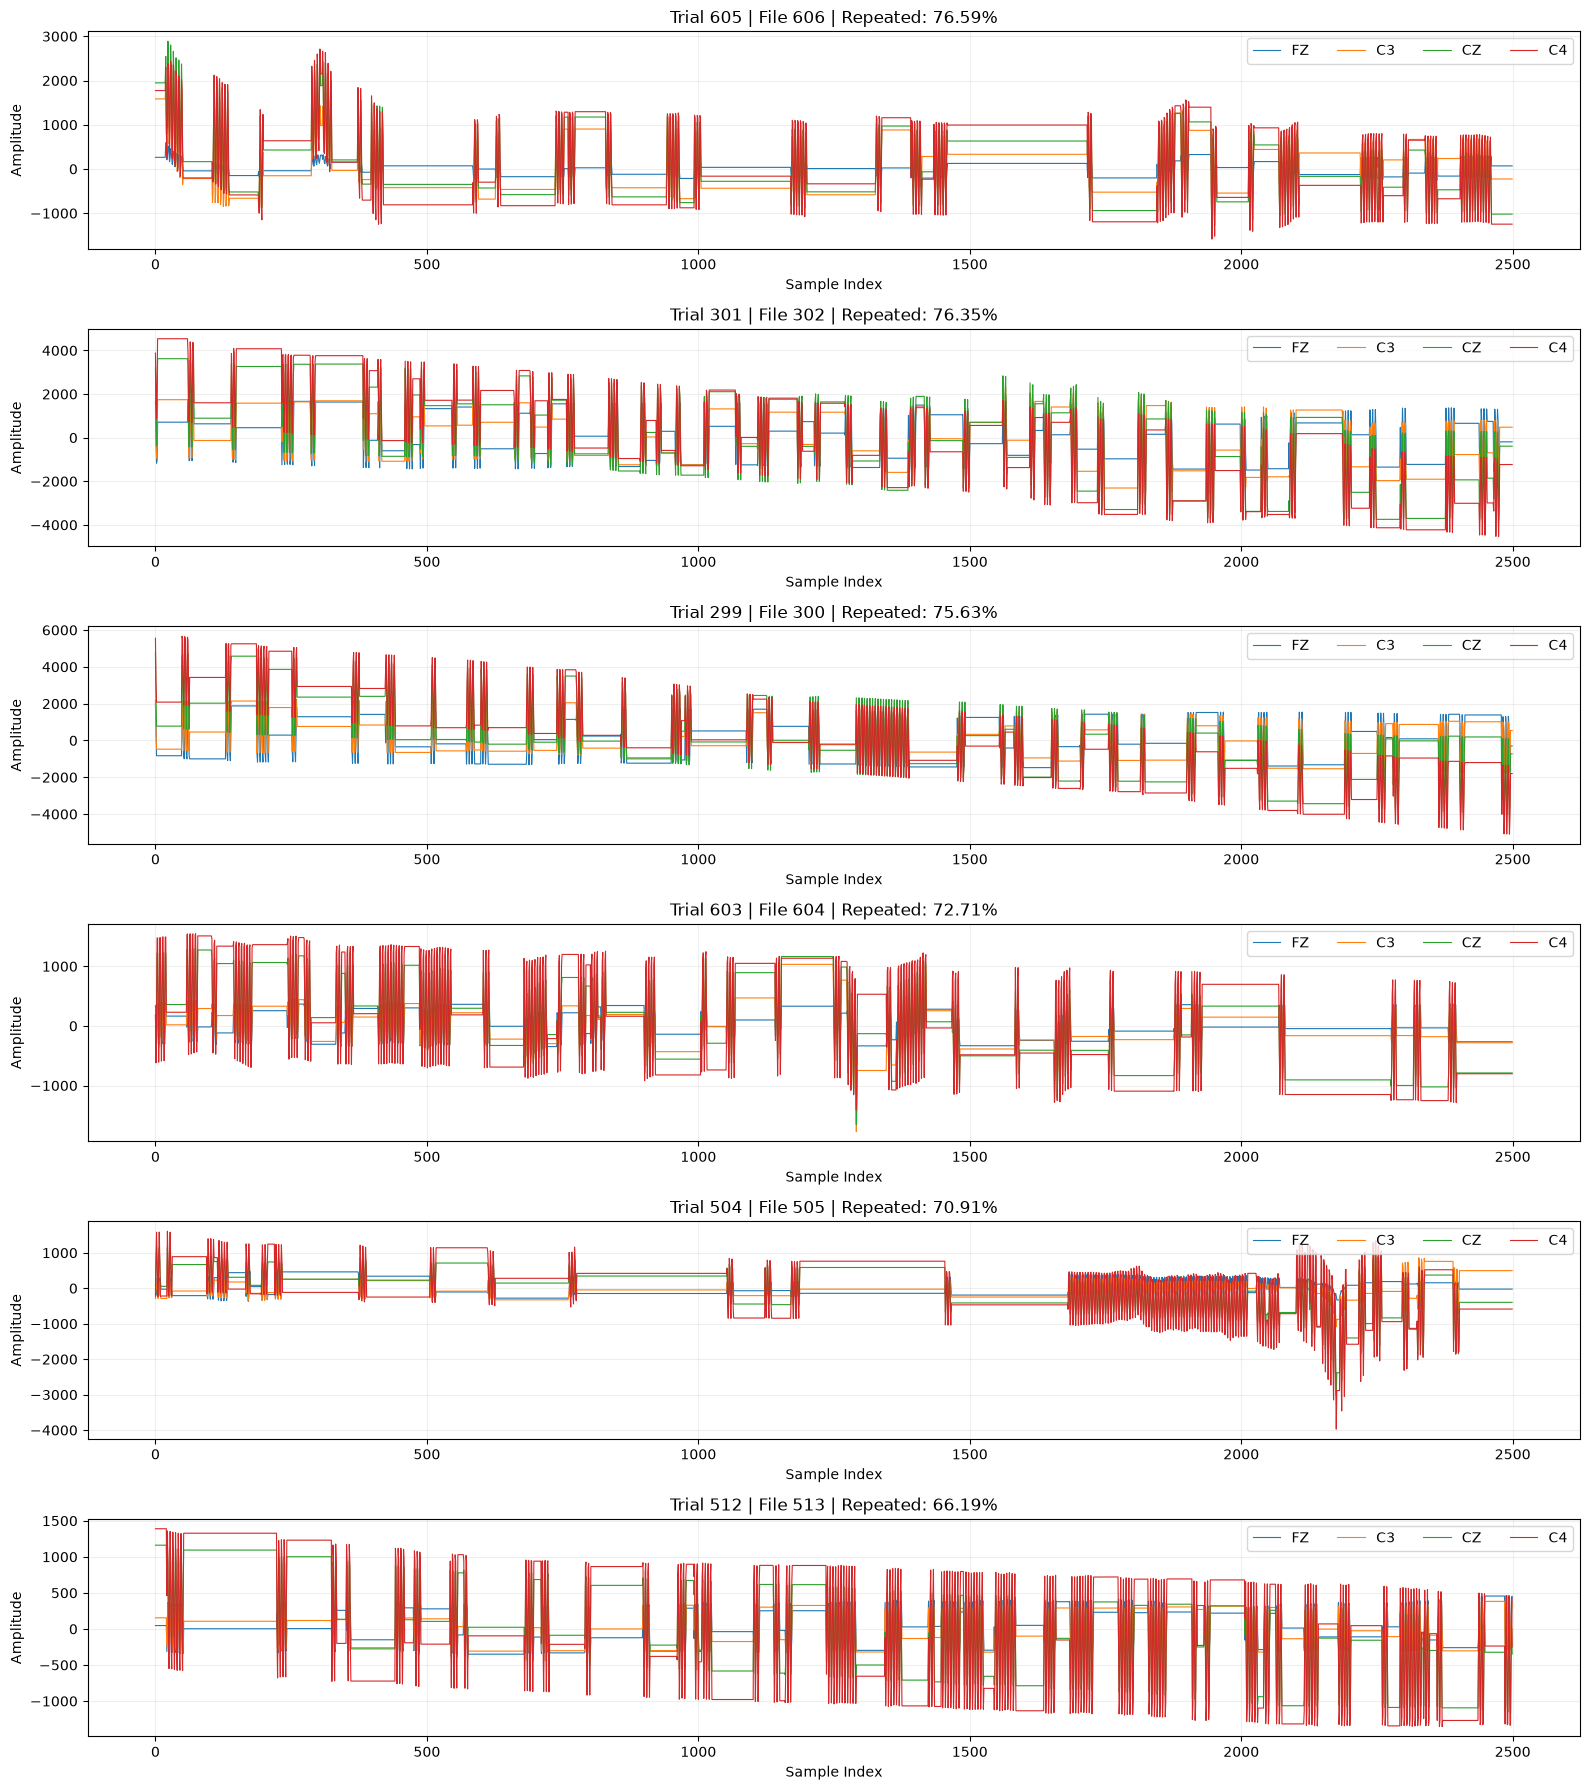

In [183]:
import matplotlib.pyplot as plt
import numpy as np

# Selected high-priority trials (zero-based indices)
selected_trials = [605, 301, 299, 603, 504, 512]

fig, axes = plt.subplots(
    len(selected_trials),
    1,
    figsize=(16, 18)
)

for ax, trial_idx in zip(axes, selected_trials):

    signal = X_centered[trial_idx]

    for ch_idx, channel in enumerate(channels):
        ax.plot(
            signal[:, ch_idx],
            label=channel,
            linewidth=0.8
        )

    ax.set_title(
        f"Trial {trial_idx} | File {trial_idx + 1} | "
        f"Repeated: {combined_quality_df.loc[trial_idx, 'repeated_percentage']:.2f}%"
    )

    ax.set_xlabel("Sample Index")
    ax.set_ylabel("Amplitude")
    ax.legend(loc="upper right", ncol=4)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

Trial: 605
File: cellula_MI_data_606.csv
Longest repeated region: 1459 to 1716
Repeated samples: 257


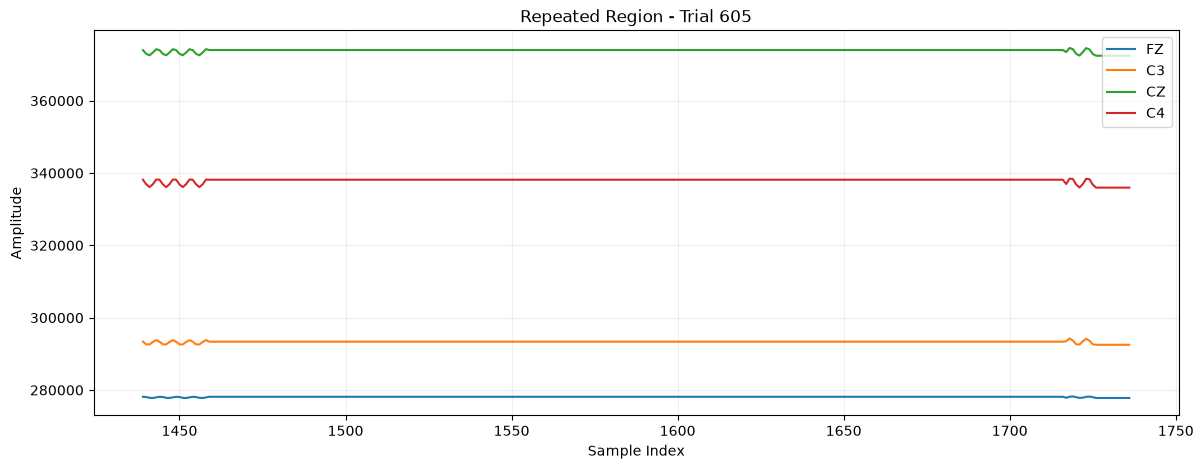

In [184]:
def inspect_trial_plateau(trial_idx):

    file_path = csv_files[trial_idx]
    df = pd.read_csv(file_path)

    eeg = df[channels].to_numpy()

    repeated_mask = np.all(
        eeg[1:] == eeg[:-1],
        axis=1
    )

    # Find consecutive repeated regions
    starts = np.where(
        repeated_mask & ~np.r_[False, repeated_mask[:-1]]
    )[0]

    ends = np.where(
        repeated_mask & ~np.r_[repeated_mask[1:], False]
    )[0]

    if len(starts) == 0:
        print("No repeated region found.")
        return

    lengths = ends - starts + 1
    longest_idx = np.argmax(lengths)

    start = starts[longest_idx]
    end = ends[longest_idx] + 1

    print("Trial:", trial_idx)
    print("File:", file_path.name)
    print("Longest repeated region:", start, "to", end)
    print("Repeated samples:", lengths[longest_idx])

    plt.figure(figsize=(14, 5))

    for ch_idx, channel in enumerate(channels):
        plt.plot(
            np.arange(start - 20, end + 21),
            eeg[max(0, start - 20):min(len(eeg), end + 21), ch_idx],
            label=channel
        )

    plt.title(f"Repeated Region - Trial {trial_idx}")
    plt.xlabel("Sample Index")
    plt.ylabel("Amplitude")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()


inspect_trial_plateau(605)

In [185]:
trial_idx = 605
df = pd.read_csv(csv_files[trial_idx])

# Analyze each EEG channel separately
for channel in channels:
    values = df[channel].to_numpy()

    repeated = values[1:] == values[:-1]

    starts = np.where(
        repeated & ~np.r_[False, repeated[:-1]]
    )[0]

    ends = np.where(
        repeated & ~np.r_[repeated[1:], False]
    )[0]

    run_lengths = ends - starts + 1

    print(f"\nChannel: {channel}")
    print("Unique values:", len(np.unique(values)))
    print("Repeated adjacent pairs:", repeated.sum())
    print(
        "Longest constant run:",
        run_lengths.max() if len(run_lengths) else 0
    )

# Inspect the suspicious region
start, end = 1435, 1730

display(
    df.iloc[start:end][["Time"] + channels].head(15)
)

display(
    df.iloc[start:end][["Time"] + channels].tail(15)
)

# Timestamp behavior in the same region
time_values = df["Time"].to_numpy()
time_diff = np.diff(time_values[start:end])

print("\nTimestamp differences:")
print("Minimum:", time_diff.min())
print("Median:", np.median(time_diff))
print("Maximum:", time_diff.max())
print("Non-positive intervals:", (time_diff <= 0).sum())


Channel: FZ
Unique values: 556
Repeated adjacent pairs: 1914
Longest constant run: 257

Channel: C3
Unique values: 572
Repeated adjacent pairs: 1914
Longest constant run: 257

Channel: CZ
Unique values: 577
Repeated adjacent pairs: 1914
Longest constant run: 257

Channel: C4
Unique values: 584
Repeated adjacent pairs: 1914
Longest constant run: 257


,Time,FZ,C3,CZ,C4
1435,512084.252779,278068.31250,292631.90625,372942.37500,336875.40625
1436,512084.262789,277847.31250,292604.56250,372552.62500,336122.87500
1437,512084.392757,277804.75000,293306.50000,373320.37500,336913.12500
1438,512084.392771,277980.25000,293806.37500,374235.09375,338209.71875
1439,512084.392773,278137.62500,293372.03125,373982.25000,338162.34375
1440,512084.392775,278073.59375,292636.75000,372949.96875,336874.87500
1441,512084.392777,277847.03125,292598.28125,372553.18750,336119.65625
1442,512084.392780,277805.56250,293300.31250,373322.06250,336910.09375
1443,512084.392782,277980.62500,293800.56250,374236.53125,338204.34375
1444,512084.392784,278133.78125,293365.06250,373983.68750,338153.21875


,Time,FZ,C3,CZ,C4
1715,512084.672817,278134.03125,293371.65625,374007.37500,338152.50000
1716,512084.672818,278134.03125,293371.65625,374007.37500,338152.50000
1717,512084.672818,277870.90625,293499.68750,373448.84375,336965.09375
1718,512084.672820,278147.81250,294251.06250,374573.31250,338441.71875
1719,512084.672822,278237.31250,293703.00000,374261.46875,338358.75000
1720,512084.672824,278034.71875,292640.40625,372953.43750,336839.56250
1721,512084.690225,277809.40625,292558.34375,372472.25000,335995.18750
1722,512084.704336,277890.59375,293487.18750,373432.65625,336946.93750
1723,512084.743886,278129.28125,294172.50000,374533.09375,338414.18750
1724,512084.821623,278198.68750,293649.71875,374195.84375,338301.18750



Timestamp differences:
Minimum: 2.00001522898674e-07
Median: 3.00002284348011e-07
Maximum: 0.13507349998690188
Non-positive intervals: 0


In [190]:
trial_idx = 301
df = pd.read_csv(csv_files[trial_idx])

# Analyze each EEG channel separately
for channel in channels:
    values = df[channel].to_numpy()

    repeated = values[1:] == values[:-1]

    starts = np.where(
        repeated & ~np.r_[False, repeated[:-1]]
    )[0]

    ends = np.where(
        repeated & ~np.r_[repeated[1:], False]
    )[0]

    run_lengths = ends - starts + 1

    print(f"\nChannel: {channel}")
    print("Unique values:", len(np.unique(values)))
    print("Repeated adjacent pairs:", repeated.sum())
    print(
        "Longest constant run:",
        run_lengths.max() if len(run_lengths) else 0
    )

# Inspect the suspicious region
start, end = 1435, 1730

display(
    df.iloc[start:end][["Time"] + channels].head(15)
)

display(
    df.iloc[start:end][["Time"] + channels].tail(15)
)

# Timestamp behavior in the same region
time_values = df["Time"].to_numpy()
time_diff = np.diff(time_values[start:end])

print("\nTimestamp differences:")
print("Minimum:", time_diff.min())
print("Median:", np.median(time_diff))
print("Maximum:", time_diff.max())
print("Non-positive intervals:", (time_diff <= 0).sum())


Channel: FZ
Unique values: 590
Repeated adjacent pairs: 1908
Longest constant run: 87

Channel: C3
Unique values: 582
Repeated adjacent pairs: 1908
Longest constant run: 87

Channel: CZ
Unique values: 587
Repeated adjacent pairs: 1908
Longest constant run: 87

Channel: C4
Unique values: 589
Repeated adjacent pairs: 1908
Longest constant run: 87


,Time,FZ,C3,CZ,C4
1435,89489.204578,290316.09375,305656.625,399615.3125,412921.78125
1436,89489.204578,290316.09375,305656.625,399615.3125,412921.78125
1437,89489.204578,290316.09375,305656.625,399615.3125,412921.78125
1438,89489.204578,290316.09375,305656.625,399615.3125,412921.78125
1439,89489.204579,290316.09375,305656.625,399615.3125,412921.78125
1440,89489.204579,290316.09375,305656.625,399615.3125,412921.78125
1441,89489.204579,290316.09375,305656.625,399615.3125,412921.78125
1442,89489.204580,290316.09375,305656.625,399615.3125,412921.78125
1443,89489.204580,290316.09375,305656.625,399615.3125,412921.78125
1444,89489.204580,290316.09375,305656.625,399615.3125,412921.78125


,Time,FZ,C3,CZ,C4
1715,89490.303313,288737.875,304162.90625,397299.78125,410585.75
1716,89490.303314,288737.875,304162.90625,397299.78125,410585.75
1717,89490.303316,288737.875,304162.90625,397299.78125,410585.75
1718,89490.303317,288737.875,304162.90625,397299.78125,410585.75
1719,89490.303318,288737.875,304162.90625,397299.78125,410585.75
1720,89490.303320,288737.875,304162.90625,397299.78125,410585.75
1721,89490.303321,288737.875,304162.90625,397299.78125,410585.75
1722,89490.303322,288737.875,304162.90625,397299.78125,410585.75
1723,89490.303324,288737.875,304162.90625,397299.78125,410585.75
1724,89490.303325,288737.875,304162.90625,397299.78125,410585.75



Timestamp differences:
Minimum: 1.9998697098344564e-07
Median: 6.00004568696022e-07
Maximum: 0.11498120000760537
Non-positive intervals: 0


In [188]:
trial_idx = 605

df = pd.read_csv(csv_files[trial_idx])

eeg = df[channels].to_numpy()
timestamps = df["Time"].to_numpy()

# Detect rows where all EEG channels remain unchanged
repeated_mask = np.all(
    eeg[1:] == eeg[:-1],
    axis=1
)

starts = np.where(
    repeated_mask & ~np.r_[False, repeated_mask[:-1]]
)[0]

ends = np.where(
    repeated_mask & ~np.r_[repeated_mask[1:], False]
)[0]

lengths = ends - starts + 1

longest_idx = np.argmax(lengths)

start = starts[longest_idx]
end = ends[longest_idx] + 1

print("Trial:", trial_idx)
print("File:", csv_files[trial_idx].name)
print("Start sample:", start)
print("End sample:", end)
print("Repeated samples:", lengths[longest_idx])

print("\nTimestamp at start:", timestamps[start])
print("Timestamp at end:", timestamps[end])
print(
    "Timestamp duration:",
    timestamps[end] - timestamps[start],
    "seconds"
)

print("\nTimestamp intervals inside plateau:")
plateau_diffs = np.diff(timestamps[start:end + 1])

print("Minimum:", plateau_diffs.min())
print("Median:", np.median(plateau_diffs))
print("Maximum:", plateau_diffs.max())

print("\nEEG values at plateau start:")
print(df.loc[start, channels])

print("\nEEG values at plateau end:")
print(df.loc[end, channels])

Trial: 605
File: cellula_MI_data_606.csv
Start sample: 1459
End sample: 1716
Repeated samples: 257

Timestamp at start: 512084.6727118
Timestamp at end: 512084.6728177
Timestamp duration: 0.0001058999914675951 seconds

Timestamp intervals inside plateau:
Minimum: 2.00001522898674e-07
Median: 3.00002284348011e-07
Maximum: 3.579998156055808e-05

EEG values at plateau start:
FZ    278134.03125
C3    293371.65625
CZ    374007.37500
C4    338152.50000
Name: 1459, dtype: float64

EEG values at plateau end:
FZ    278134.03125
C3    293371.65625
CZ    374007.37500
C4    338152.50000
Name: 1716, dtype: float64


In [191]:
trial_idx = 301
df = pd.read_csv(csv_files[trial_idx])

eeg = df[channels].to_numpy()
timestamps = df["Time"].to_numpy()

# Detect rows where all EEG channels remain unchanged
repeated_mask = np.all(
    eeg[1:] == eeg[:-1],
    axis=1
)

starts = np.where(
    repeated_mask & ~np.r_[False, repeated_mask[:-1]]
)[0]

ends = np.where(
    repeated_mask & ~np.r_[repeated_mask[1:], False]
)[0]

lengths = ends - starts + 1

longest_idx = np.argmax(lengths)

start = starts[longest_idx]
end = ends[longest_idx] + 1

print("Trial:", trial_idx)
print("File:", csv_files[trial_idx].name)
print("Start sample:", start)
print("End sample:", end)
print("Repeated samples:", lengths[longest_idx])

print("\nTimestamp at start:", timestamps[start])
print("Timestamp at end:", timestamps[end])
print(
    "Timestamp duration:",
    timestamps[end] - timestamps[start],
    "seconds"
)

print("\nTimestamp intervals inside plateau:")
plateau_diffs = np.diff(timestamps[start:end + 1])

print("Minimum:", plateau_diffs.min())
print("Median:", np.median(plateau_diffs))
print("Maximum:", plateau_diffs.max())

print("\nEEG values at plateau start:")
print(df.loc[start, channels])

print("\nEEG values at plateau end:")
print(df.loc[end, channels])

Trial: 301
File: cellula_MI_data_302.csv
Start sample: 295
End sample: 382
Repeated samples: 87

Timestamp at start: 89484.8196573
Timestamp at end: 89484.8197352
Timestamp duration: 7.789999654050916e-05 seconds

Timestamp intervals inside plateau:
Minimum: 3.9998849388211966e-07
Median: 5.00003807246685e-07
Maximum: 3.3499993151053786e-05

EEG values at plateau start:
FZ    290899.28125
C3    307395.59375
CZ    403127.06250
C4    417329.62500
Name: 295, dtype: float64

EEG values at plateau end:
FZ    290899.28125
C3    307395.59375
CZ    403127.06250
C4    417329.62500
Name: 382, dtype: float64


In [192]:
shared_repetition_rows = []

for trial_idx, file_path in enumerate(csv_files):

    df = pd.read_csv(file_path)

    eeg = df[channels].to_numpy()
    timestamps = df["Time"].to_numpy()

    # Adjacent rows where all EEG channels are identical
    repeated_mask = np.all(
        eeg[1:] == eeg[:-1],
        axis=1
    )

    repeated_pairs = int(repeated_mask.sum())

    # Find consecutive repeated regions
    starts = np.where(
        repeated_mask & ~np.r_[False, repeated_mask[:-1]]
    )[0]

    ends = np.where(
        repeated_mask & ~np.r_[repeated_mask[1:], False]
    )[0]

    if len(starts) > 0:

        run_lengths = ends - starts + 1
        longest_idx = np.argmax(run_lengths)

        start = starts[longest_idx]
        end = ends[longest_idx] + 1

        longest_run = int(run_lengths[longest_idx])

        timestamp_duration = (
            timestamps[end] - timestamps[start]
        )

        plateau_time_intervals = np.diff(
            timestamps[start:end + 1]
        )

        median_plateau_interval = np.median(
            plateau_time_intervals
        )

    else:
        longest_run = 0
        timestamp_duration = np.nan
        median_plateau_interval = np.nan

    shared_repetition_rows.append({
        "trial_index": trial_idx,
        "file_name": file_path.name,
        "repeated_pairs_all_channels": repeated_pairs,
        "repeated_percentage": (
            repeated_pairs / (len(df) - 1) * 100
        ),
        "longest_shared_run": longest_run,
        "longest_run_duration_seconds": timestamp_duration,
        "median_timestamp_interval_in_run": median_plateau_interval
    })


shared_repetition_df = pd.DataFrame(shared_repetition_rows)

shared_repetition_df.to_csv(
    OUTPUT_DIR / "shared_channel_repetition_analysis.csv",
    index=False
)

print("Report shape:", shared_repetition_df.shape)

display(
    shared_repetition_df.sort_values(
        "repeated_percentage",
        ascending=False
    ).head(20)
)

Report shape: (2160, 7)


,trial_index,file_name,repeated_pairs_all_channels,repeated_percentage,longest_shared_run,longest_run_duration_seconds,median_timestamp_interval_in_run
605,605,cellula_MI_data_606.csv,1914,76.590636,257,0.000106,3.000023e-07
301,301,cellula_MI_data_302.csv,1908,76.350540,87,0.000078,5.000038e-07
299,299,cellula_MI_data_300.csv,1890,75.630252,101,0.007613,6.000046e-07
305,305,cellula_MI_data_306.csv,1885,75.430172,134,0.000052,2.499946e-07
302,302,cellula_MI_data_303.csv,1863,74.549820,131,0.098923,1.399996e-06
304,304,cellula_MI_data_305.csv,1863,74.549820,92,0.003785,2.000015e-07
297,297,cellula_MI_data_298.csv,1822,72.909164,99,0.002563,3.000023e-07
300,300,cellula_MI_data_301.csv,1820,72.829132,95,0.000218,1.399996e-06
603,603,cellula_MI_data_604.csv,1817,72.709084,194,0.005252,6.000046e-07
298,298,cellula_MI_data_299.csv,1809,72.388956,110,0.000089,5.000038e-07


In [193]:
print(
    "Trials with shared repeated samples:",
    (shared_repetition_df["repeated_pairs_all_channels"] > 0).sum()
)

print(
    "Trials with shared runs >= 50 samples:",
    (shared_repetition_df["longest_shared_run"] >= 50).sum()
)

print(
    "Trials with shared runs >= 100 samples:",
    (shared_repetition_df["longest_shared_run"] >= 100).sum()
)

print(
    "Maximum shared repetition percentage:",
    shared_repetition_df["repeated_percentage"].max()
)

print(
    "Maximum shared constant run:",
    shared_repetition_df["longest_shared_run"].max()
)

print("\nLongest shared runs:")
display(
    shared_repetition_df.nlargest(
        15, "longest_shared_run"
    )
)

Trials with shared repeated samples: 461
Trials with shared runs >= 50 samples: 125
Trials with shared runs >= 100 samples: 30
Maximum shared repetition percentage: 76.5906362545018
Maximum shared constant run: 306

Longest shared runs:


,trial_index,file_name,repeated_pairs_all_channels,repeated_percentage,longest_shared_run,longest_run_duration_seconds,median_timestamp_interval_in_run
246,246,cellula_MI_data_247.csv,499,19.967987,306,0.000543,1.300010e-06
504,504,cellula_MI_data_505.csv,1772,70.908363,276,0.005323,3.000023e-07
510,510,cellula_MI_data_511.csv,1013,40.536214,276,0.000121,3.000023e-07
605,605,cellula_MI_data_606.csv,1914,76.590636,257,0.000106,3.000023e-07
590,590,cellula_MI_data_591.csv,1038,41.536615,246,0.000156,5.000038e-07
611,611,cellula_MI_data_612.csv,1446,57.863145,199,0.000377,1.300010e-06
506,506,cellula_MI_data_507.csv,1172,46.898760,195,0.002742,1.300010e-06
603,603,cellula_MI_data_604.csv,1817,72.709084,194,0.005252,6.000046e-07
608,608,cellula_MI_data_609.csv,1373,54.941977,179,0.000365,1.300010e-06
511,511,cellula_MI_data_512.csv,801,32.052821,173,0.015317,1.300010e-06


In [194]:
# Identify consecutive groups of trials with >= 20% shared repetition

threshold = 20

affected = (
    shared_repetition_df["repeated_percentage"] >= threshold
).sort_values().reset_index(drop=True)

trial_ids = shared_repetition_df.loc[
    shared_repetition_df["repeated_percentage"] >= threshold,
    "trial_index"
].sort_values().tolist()

groups = []

if trial_ids:
    group_start = trial_ids[0]
    previous = trial_ids[0]

    for current in trial_ids[1:]:
        if current != previous + 1:
            groups.append((group_start, previous))
            group_start = current

        previous = current

    groups.append((group_start, previous))

cluster_report = pd.DataFrame([
    {
        "start_trial": start,
        "end_trial": end,
        "number_of_trials": end - start + 1
    }
    for start, end in groups
])

display(cluster_report)

cluster_report.to_csv(
    OUTPUT_DIR / "repetition_cluster_report.csv",
    index=False
)

,start_trial,end_trial,number_of_trials
0,297,305,9
1,504,512,9
2,571,574,4
3,589,590,2
4,603,611,9
5,657,659,3
6,662,662,1
7,909,909,1
8,1067,1067,1
9,2069,2069,1


In [195]:
final_signal_quality_df = combined_quality_df.merge(
    shared_repetition_df[
        [
            "trial_index",
            "repeated_pairs_all_channels",
            "longest_shared_run",
            "longest_run_duration_seconds"
        ]
    ],
    on="trial_index",
    how="left"
)

def assign_review_status(row):

    if row["repeated_percentage"] >= 50:
        return "Critical - Severe Repetition"

    if row["longest_shared_run"] >= 100:
        return "High - Long Shared Plateau"

    if row["has_outlier"] or row["has_repeated_samples"]:
        return "Review Required"

    return "No Detected Issue"

final_signal_quality_df["review_status"] = (
    final_signal_quality_df.apply(
        assign_review_status,
        axis=1
    )
)

final_signal_quality_df.to_csv(
    OUTPUT_DIR / "final_signal_quality_assessment.csv",
    index=False
)

display(
    final_signal_quality_df["review_status"]
    .value_counts()
    .to_frame("trial_count")
)

,trial_count
review_status,
No Detected Issue,1549
Review Required,577
Critical - Severe Repetition,22
High - Long Shared Plateau,12


In [196]:
# Final signal quality summary

final_quality_summary = (
    final_signal_quality_df
    .groupby("review_status")
    .agg(
        trial_count=("trial_index", "count"),
        mean_repeated_percentage=("repeated_percentage", "mean"),
        max_repeated_percentage=("repeated_percentage", "max"),
        max_constant_run=("longest_constant_run", "max")
    )
    .reset_index()
)

final_quality_summary["percentage"] = (
    final_quality_summary["trial_count"]
    / len(final_signal_quality_df) * 100
)

display(final_quality_summary)

final_quality_summary.to_csv(
    OUTPUT_DIR / "final_signal_quality_summary.csv",
    index=False
)

,review_status,trial_count,mean_repeated_percentage,max_repeated_percentage,max_constant_run,percentage
0,Critical - Severe Repetition,22,67.039543,76.590636,277,1.018519
1,High - Long Shared Plateau,12,36.554622,49.419768,307,0.555556
2,No Detected Issue,1549,0.000000,0.000000,1,71.712963
3,Review Required,577,4.623270,48.419368,96,26.712963


### EEG Signal Quality Assessment

The quality assessment was performed on 2,160 EEG trials, each containing four channels: FZ, C3, CZ, and C4.

The analysis identified:

- 1,549 trials (71.71%) with no detected issues according to the implemented checks.
- 577 trials (26.71%) requiring further review due to repeated samples and/or outliers.
- 22 trials (1.02%) classified as critical due to severe repetition.
- 12 trials (0.56%) classified as high priority due to long shared constant segments.

A total of 461 trials showed repeated adjacent samples simultaneously across all four EEG channels. In addition, several consecutive groups of files exhibited unusually high repetition percentages.

Visual inspection confirmed extended constant signal segments and abrupt transitions in selected trials. Timestamp analysis also revealed highly irregular intervals.

These findings indicate substantial signal continuity and timestamp quality concerns. However, the underlying cause cannot be determined from the available data alone.

No trials were automatically deleted or modified. All original recordings were preserved, and quality flags were retained for subsequent processing and analysis.

In [197]:
final_quality_summary = (
    final_signal_quality_df
    .groupby("review_status")
    .agg(
        trial_count=("trial_index", "count"),
        mean_repeated_percentage=("repeated_percentage", "mean"),
        max_repeated_percentage=("repeated_percentage", "max"),
        max_constant_run=("longest_constant_run", "max"),
        max_shared_run=("longest_shared_run", "max")
    )
    .reset_index()
)

final_quality_summary["percentage"] = (
    final_quality_summary["trial_count"]
    / len(final_signal_quality_df) * 100
)

display(final_quality_summary)

,review_status,trial_count,mean_repeated_percentage,max_repeated_percentage,max_constant_run,max_shared_run,percentage
0,Critical - Severe Repetition,22,67.039543,76.590636,277,276,1.018519
1,High - Long Shared Plateau,12,36.554622,49.419768,307,306,0.555556
2,No Detected Issue,1549,0.000000,0.000000,1,0,71.712963
3,Review Required,577,4.623270,48.419368,96,95,26.712963


In [198]:
# Feature Reliability Audit - Initial Overview

print("Combined Dataset Shape:", combined_features_df.shape)
print("Total Numerical Features:", len(X_features.columns))

feature_group_summary = (
    feature_metadata[
        ~feature_metadata["is_target"]
        & ~feature_metadata["is_identifier"]
    ]
    .groupby("feature_group")
    .agg(
        feature_count=("feature", "count"),
        features=("feature", lambda x: ", ".join(x))
    )
    .reset_index()
)

display(feature_group_summary)

Combined Dataset Shape: (2160, 122)
Total Numerical Features: 120


,feature_group,feature_count,features
0,Frequency-Domain,68,"dominant_frequency_c3, dominant_frequency_c4, ..."
1,Motor Imagery,4,"mu_beta_ratio_c3, mu_beta_ratio_c4, mu_power_c..."
2,Time-Domain,48,"fz_mean, fz_std, fz_rms, fz_min, fz_max, fz_pt..."


In [199]:
# Feature Reliability Audit - Numerical Quality

feature_quality_rows = []

for feature in X_features.columns:
    values = X_features[feature]

    feature_quality_rows.append({
        "feature": feature,
        "missing_count": values.isna().sum(),
        "infinite_count": np.isinf(values).sum(),
        "unique_values": values.nunique(),
        "mean": values.mean(),
        "std": values.std(),
        "min": values.min(),
        "max": values.max(),
        "is_constant": values.nunique() <= 1
    })

feature_reliability_df = pd.DataFrame(feature_quality_rows)

display(
    feature_reliability_df.sort_values(
        by=["is_constant", "missing_count", "infinite_count"],
        ascending=False
    )
)

print("Total Features:", len(feature_reliability_df))
print("Features with Missing Values:",
      (feature_reliability_df["missing_count"] > 0).sum())
print("Features with Infinite Values:",
      (feature_reliability_df["infinite_count"] > 0).sum())
print("Constant Features:",
      feature_reliability_df["is_constant"].sum())

feature_reliability_df.to_csv(
    OUTPUT_DIR / "feature_reliability_audit.csv",
    index=False
)

,feature,missing_count,infinite_count,unique_values,mean,std,min,max,is_constant
0,fz_mean,0,0,2105,-0.021186,0.494883,-4.748638e+00,3.590437,False
1,fz_std,0,0,2124,1267.297852,2132.022705,2.689156e+01,12041.567383,False
2,fz_rms,0,0,2123,1267.298462,2132.022217,2.692147e+01,12041.566406,False
3,fz_min,0,0,2095,-2052.838379,3340.750732,-2.388878e+04,-59.031250,False
4,fz_max,0,0,2097,2055.581055,3298.530273,7.703125e+01,21711.781250,False
...,...,...,...,...,...,...,...,...,...
115,gamma_relative_power_fz,0,0,2124,0.001244,0.003457,1.674342e-08,0.029822,False
116,mu_beta_ratio_c3,0,0,2124,1.714349,1.642291,6.489141e-02,16.567837,False
117,mu_beta_ratio_c4,0,0,2124,1.588215,1.516156,7.420747e-02,12.694691,False
118,mu_power_c3_c4_difference,0,0,2124,406.206818,13974.389648,-8.797046e+04,363840.656250,False


Total Features: 120
Features with Missing Values: 0
Features with Infinite Values: 0
Constant Features: 0


In [200]:
# Feature Redundancy Analysis

feature_corr = X_features.corr(method="pearson")

upper_triangle = feature_corr.where(
    np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
)

high_corr_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

high_corr_pairs.columns = [
    "feature_1",
    "feature_2",
    "correlation"
]

high_corr_pairs["absolute_correlation"] = (
    high_corr_pairs["correlation"].abs()
)

high_corr_pairs = high_corr_pairs.sort_values(
    "absolute_correlation",
    ascending=False
).reset_index(drop=True)

print("Total highly correlated pairs (|r| >= 0.90):",
      (high_corr_pairs["absolute_correlation"] >= 0.90).sum())

display(
    high_corr_pairs[
        high_corr_pairs["absolute_correlation"] >= 0.90
    ].head(30)
)

high_corr_pairs.to_csv(
    OUTPUT_DIR / "high_correlation_feature_pairs.csv",
    index=False
)

Total highly correlated pairs (|r| >= 0.90): 176


,feature_1,feature_2,correlation,absolute_correlation
0,cz_std,cz_rms,1.000000,1.000000
1,c4_std,c4_rms,1.000000,1.000000
2,fz_std,fz_rms,1.000000,1.000000
3,c3_std,c3_rms,1.000000,1.000000
4,alpha_power_fz,mu_power_fz,0.998533,0.998533
5,alpha_power_cz,mu_power_cz,0.998307,0.998307
6,alpha_power_c3,mu_power_c3,0.998170,0.998170
7,fz_rms,fz_iqr,0.997879,0.997879
8,fz_std,fz_iqr,0.997879,0.997879
9,alpha_relative_power_fz,mu_relative_power_fz,0.997106,0.997106


In [201]:
# Exact Redundancy and Relationship Investigation

pairs_to_check = [
    ("cz_std", "cz_rms"),
    ("c4_std", "c4_rms"),
    ("fz_std", "fz_rms"),
    ("c3_std", "c3_rms"),
    ("alpha_power_fz", "mu_power_fz"),
    ("alpha_power_cz", "mu_power_cz"),
    ("alpha_power_c3", "mu_power_c3"),
    ("alpha_power_c4", "mu_power_c4"),
    ("fz_ptp", "fz_max"),
    ("fz_ptp", "fz_min"),
    ("beta_power_fz", "gamma_power_fz"),
]

relationship_rows = []

for feature_1, feature_2 in pairs_to_check:
    a = X_features[feature_1].to_numpy()
    b = X_features[feature_2].to_numpy()

    relationship_rows.append({
        "feature_1": feature_1,
        "feature_2": feature_2,
        "correlation": np.corrcoef(a, b)[0, 1],
        "exactly_equal": np.array_equal(a, b),
        "max_absolute_difference": np.max(np.abs(a - b)),
        "mean_absolute_difference": np.mean(np.abs(a - b))
    })

relationship_check_df = pd.DataFrame(relationship_rows)

display(relationship_check_df)

relationship_check_df.to_csv(
    OUTPUT_DIR / "feature_relationship_investigation.csv",
    index=False
)

,feature_1,feature_2,correlation,exactly_equal,max_absolute_difference,mean_absolute_difference
0,cz_std,cz_rms,1.000000,False,3.423309e-02,0.000342
1,c4_std,c4_rms,1.000000,False,3.456497e-02,0.000211
2,fz_std,fz_rms,1.000000,False,6.236076e-02,0.000682
3,c3_std,c3_rms,1.000000,False,7.496834e-02,0.000748
4,alpha_power_fz,mu_power_fz,0.998533,False,4.020991e+05,1403.977876
5,alpha_power_cz,mu_power_cz,0.998307,False,1.295839e+06,4729.175880
6,alpha_power_c3,mu_power_c3,0.998170,False,1.108809e+05,428.780156
7,alpha_power_c4,mu_power_c4,0.996934,False,4.032334e+04,349.322831
8,fz_ptp,fz_max,0.995980,False,2.388878e+04,2052.838379
9,fz_ptp,fz_min,-0.996081,False,6.535566e+04,6161.257812


In [202]:
# Verify the mathematical relationship between STD and RMS

std_rms_rows = []

for channel in channels:
    std_values = X_features[f"{channel.lower()}_std"]
    rms_values = X_features[f"{channel.lower()}_rms"]

    std_rms_rows.append({
        "channel": channel,
        "correlation": std_values.corr(rms_values),
        "mean_std": std_values.mean(),
        "mean_rms": rms_values.mean(),
        "mean_difference": (rms_values - std_values).mean(),
        "max_difference": (rms_values - std_values).abs().max(),
        "mean_ratio": (rms_values / std_values).mean()
    })

std_rms_check = pd.DataFrame(std_rms_rows)

display(std_rms_check)

,channel,correlation,mean_std,mean_rms,mean_difference,max_difference,mean_ratio
0,FZ,1.0,1267.297852,1267.298462,0.000671,0.062361,1.000008
1,C3,1.0,973.761353,973.762146,0.000740,0.074968,1.000013
2,CZ,1.0,2026.444458,2026.444702,0.000314,0.034233,1.000002
3,C4,1.0,1451.481079,1451.481323,0.000199,0.034565,1.000001


In [203]:
std_rms_decision = pd.DataFrame([
    {
        "feature_1": f"{ch.lower()}_std",
        "feature_2": f"{ch.lower()}_rms",
        "correlation": 1.0,
        "relationship": "Near-Redundancy",
        "decision": "Keep one during final feature selection",
        "reason": "Mean-centered signals make STD and RMS numerically very close, but they are not exactly equal."
    }
    for ch in channels
])

display(std_rms_decision)

std_rms_decision.to_csv(
    OUTPUT_DIR / "std_rms_redundancy_decisions.csv",
    index=False
)

,feature_1,feature_2,correlation,relationship,decision,reason
0,fz_std,fz_rms,1.0,Near-Redundancy,Keep one during final feature selection,Mean-centered signals make STD and RMS numeric...
1,c3_std,c3_rms,1.0,Near-Redundancy,Keep one during final feature selection,Mean-centered signals make STD and RMS numeric...
2,cz_std,cz_rms,1.0,Near-Redundancy,Keep one during final feature selection,Mean-centered signals make STD and RMS numeric...
3,c4_std,c4_rms,1.0,Near-Redundancy,Keep one during final feature selection,Mean-centered signals make STD and RMS numeric...


In [204]:
# Frequency Feature Configuration Audit

from scipy.signal import welch

FS = 250
N_PERSEG = 1024
N_OVERLAP = 512

freqs, _ = welch(
    X_centered[0, :, 0],
    fs=FS,
    nperseg=N_PERSEG,
    noverlap=N_OVERLAP
)

frequency_resolution = freqs[1] - freqs[0]

print("Assumed Sampling Rate:", FS, "Hz")
print("Frequency Resolution:", frequency_resolution, "Hz")
print("Nyquist Frequency:", FS / 2, "Hz")
print("Number of PSD Bins:", len(freqs))

frequency_bands = {
    "Delta": (0.5, 4),
    "Theta": (4, 8),
    "Alpha": (8, 13),
    "Mu": (8, 12),
    "Beta": (13, 30),
    "Gamma": (30, 40)
}

band_audit = []

for band, (low, high) in frequency_bands.items():
    mask = (freqs >= low) & (freqs < high)

    band_audit.append({
        "band": band,
        "low_hz": low,
        "high_hz": high,
        "available_bins": mask.sum(),
        "actual_first_bin": freqs[mask][0] if mask.any() else np.nan,
        "actual_last_bin": freqs[mask][-1] if mask.any() else np.nan
    })

band_audit_df = pd.DataFrame(band_audit)

display(band_audit_df)

Assumed Sampling Rate: 250 Hz
Frequency Resolution: 0.244140625 Hz
Nyquist Frequency: 125.0 Hz
Number of PSD Bins: 513


,band,low_hz,high_hz,available_bins,actual_first_bin,actual_last_bin
0,Delta,0.5,4,14,0.732422,3.906250
1,Theta,4.0,8,16,4.150391,7.812500
2,Alpha,8.0,13,21,8.056641,12.939453
3,Mu,8.0,12,17,8.056641,11.962891
4,Beta,13.0,30,69,13.183594,29.785156
5,Gamma,30.0,40,41,30.029297,39.794922


In [205]:
# Relative Power Consistency Audit

relative_power_columns = [
    "delta_relative_power",
    "theta_relative_power",
    "alpha_relative_power",
    "mu_relative_power",
    "beta_relative_power",
    "gamma_relative_power"
]

relative_power_audit = (
    frequency_features_df
    .groupby(["trial_index", "channel"])[relative_power_columns]
    .first()
)

# Alpha and Mu overlap, so exclude one from the sum
non_overlapping_columns = [
    "delta_relative_power",
    "theta_relative_power",
    "alpha_relative_power",
    "beta_relative_power",
    "gamma_relative_power"
]

relative_power_sum = relative_power_audit[
    non_overlapping_columns
].sum(axis=1)

print("Minimum Sum:", relative_power_sum.min())
print("Maximum Sum:", relative_power_sum.max())
print("Mean Sum:", relative_power_sum.mean())

print(
    "Rows where sum > 1:",
    (relative_power_sum > 1.000001).sum()
)

print(
    "Rows where sum <= 1:",
    (relative_power_sum <= 1.000001).sum()
)

print(
    "Mean Uncovered Power:",
    (1 - relative_power_sum).mean()
)

Minimum Sum: 8.132866e-07
Maximum Sum: 0.9070384
Mean Sum: 0.031599548
Rows where sum > 1: 0
Rows where sum <= 1: 8640
Mean Uncovered Power: 0.9684004


In [207]:
# Investigate Power Outside the Selected EEG Bands

from scipy.signal import welch
from scipy.integrate import trapezoid

FS = 250

investigation_bands = {
    "40_45_Hz": (40, 45),
    "45_55_Hz": (45, 55),
    "55_60_Hz": (55, 60),
    "60_80_Hz": (60, 80),
    "80_125_Hz": (80, 125)
}

power_rows = []

for trial_idx in range(X_centered.shape[0]):

    for ch_idx, channel in enumerate(channels):

        signal = X_centered[trial_idx, :, ch_idx]

        freqs, psd = welch(
            signal,
            fs=FS,
            nperseg=1024,
            noverlap=512
        )

        total_power = trapezoid(psd, freqs)

        row = {
            "trial_index": trial_idx + 1,
            "channel": channel,
            "total_power": total_power
        }

        for band_name, (low, high) in investigation_bands.items():

            mask = (freqs >= low) & (freqs < high)

            band_power = (
                trapezoid(psd[mask], freqs[mask])
                if mask.sum() >= 2 else 0.0
            )

            row[f"{band_name}_power"] = band_power
            row[f"{band_name}_relative_power"] = (
                band_power / total_power
                if total_power > 0 else np.nan
            )

        power_rows.append(row)

outside_band_power_df = pd.DataFrame(power_rows)

display(
    outside_band_power_df[
        [
            col for col in outside_band_power_df.columns
            if "relative_power" in col
        ]
    ].mean().to_frame("mean_relative_power")
)

outside_band_power_df.to_csv(
    OUTPUT_DIR / "outside_frequency_band_power_audit.csv",
    index=False
)

,mean_relative_power
40_45_Hz_relative_power,0.001505
45_55_Hz_relative_power,0.926409
55_60_Hz_relative_power,0.001077
60_80_Hz_relative_power,0.000984
80_125_Hz_relative_power,0.001576


,channel,label,count,mean,median,std,min,max
0,C3,Left,1082,0.914416,0.990312,0.182583,0.010717,0.999984
1,C3,Right,1078,0.908559,0.989328,0.186944,0.045311,0.999974
2,C4,Left,1082,0.931612,0.995371,0.155353,0.022176,0.999973
3,C4,Right,1078,0.923442,0.994982,0.164393,0.086302,0.999974
4,CZ,Left,1082,0.935012,0.994879,0.148920,0.041821,0.999979
5,CZ,Right,1078,0.937083,0.995099,0.141999,0.121928,0.999987
6,FZ,Left,1082,0.931045,0.994015,0.169767,0.020374,0.999972
7,FZ,Right,1078,0.930078,0.994436,0.176534,0.014589,0.999979


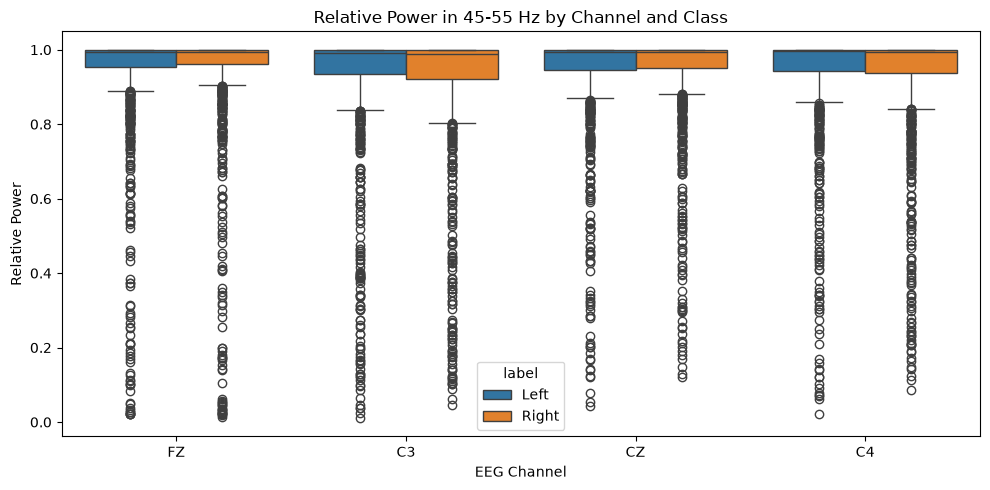

In [208]:
# 45-55 Hz Power Distribution by Channel and Class

band_50_summary = (
    outside_band_power_df
    .merge(
        mapping_df[["trial_index", "label"]],
        on="trial_index",
        how="left"
    )
    .groupby(["channel", "label"])
    ["45_55_Hz_relative_power"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .reset_index()
)

display(band_50_summary)

# Distribution across all channels
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=outside_band_power_df.merge(
        mapping_df[["trial_index", "label"]],
        on="trial_index",
        how="left"
    ),
    x="channel",
    y="45_55_Hz_relative_power",
    hue="label"
)

plt.title("Relative Power in 45-55 Hz by Channel and Class")
plt.ylabel("Relative Power")
plt.xlabel("EEG Channel")
plt.tight_layout()
plt.show()

band_50_summary.to_csv(
    OUTPUT_DIR / "power_45_55_by_channel_class.csv",
    index=False
)

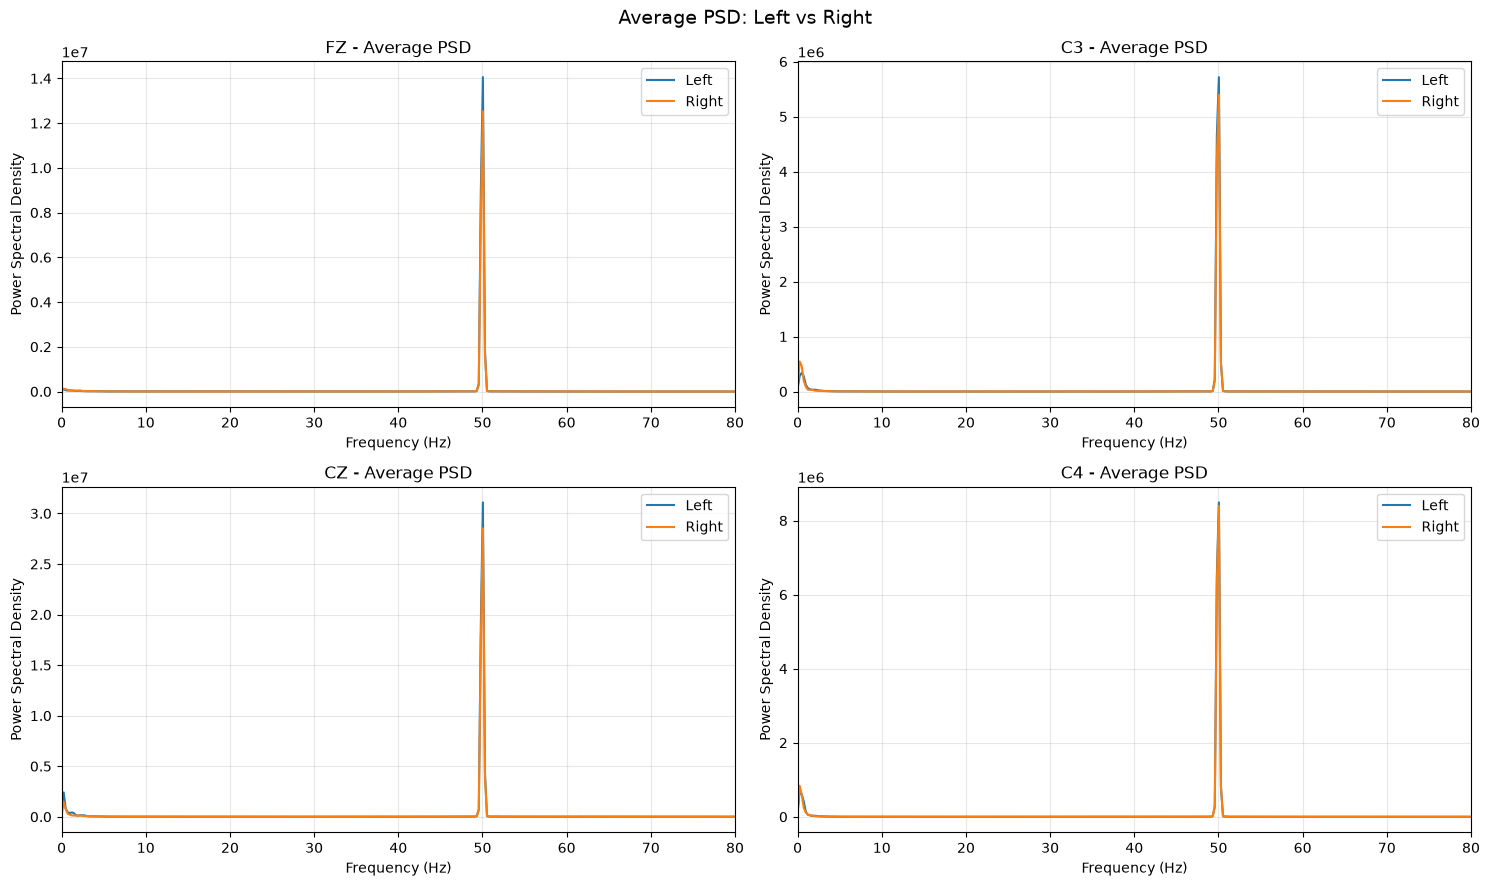

In [209]:
# Average PSD by Channel and Provisional Class

from scipy.signal import welch

FS = 250

fig, axes = plt.subplots(2, 2, figsize=(15, 9))

for ch_idx, channel in enumerate(channels):

    ax = axes.flat[ch_idx]

    for label in ["Left", "Right"]:

        trial_indices = mapping_df.loc[
            mapping_df["label"] == label,
            "trial_index"
        ].to_numpy() - 1

        psd_list = []

        for trial_idx in trial_indices:

            signal = X_centered[trial_idx, :, ch_idx]

            freqs, psd = welch(
                signal,
                fs=FS,
                nperseg=1024,
                noverlap=512
            )

            psd_list.append(psd)

        mean_psd = np.mean(psd_list, axis=0)

        ax.plot(
            freqs,
            mean_psd,
            label=label
        )

    ax.set_xlim(0, 80)
    ax.set_title(f"{channel} - Average PSD")
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("Power Spectral Density")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("Average PSD: Left vs Right", fontsize=14)
plt.tight_layout()
plt.show()

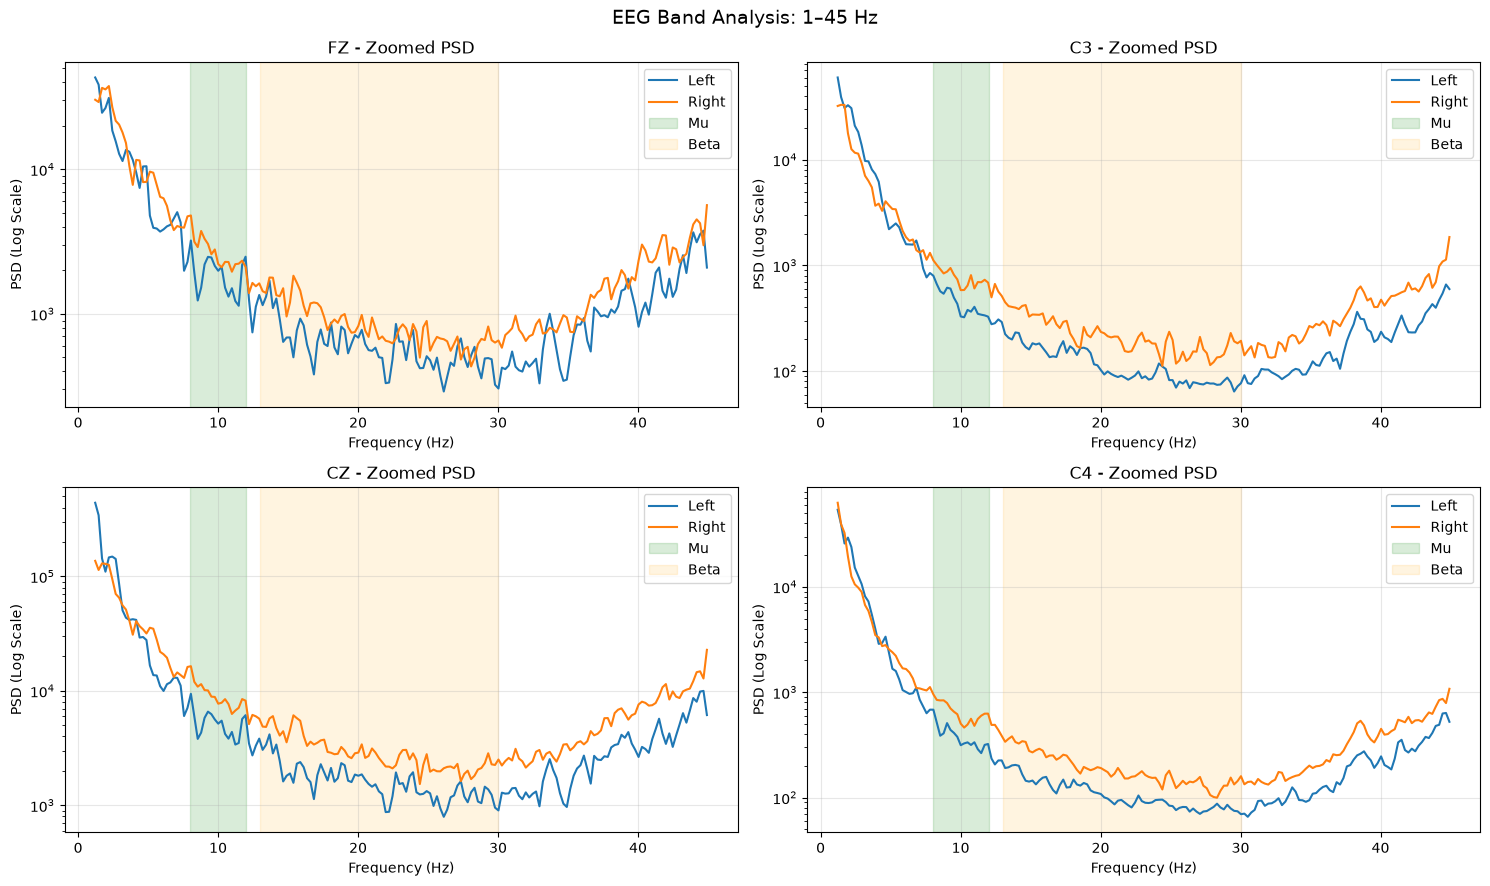

In [210]:
# Zoomed PSD Analysis: EEG Frequency Bands

fig, axes = plt.subplots(2, 2, figsize=(15, 9))

for ch_idx, channel in enumerate(channels):

    ax = axes.flat[ch_idx]

    for label in ["Left", "Right"]:

        trial_indices = (
            mapping_df.loc[
                mapping_df["label"] == label,
                "trial_index"
            ].to_numpy() - 1
        )

        psd_list = []

        for trial_idx in trial_indices:

            signal = X_centered[trial_idx, :, ch_idx]

            freqs, psd = welch(
                signal,
                fs=250,
                nperseg=1024,
                noverlap=512
            )

            psd_list.append(psd)

        mean_psd = np.mean(psd_list, axis=0)

        mask = (freqs >= 1) & (freqs <= 45)

        ax.plot(
            freqs[mask],
            mean_psd[mask],
            label=label
        )

    ax.axvspan(8, 12, alpha=0.15, color="green", label="Mu")
    ax.axvspan(13, 30, alpha=0.12, color="orange", label="Beta")

    ax.set_yscale("log")
    ax.set_title(f"{channel} - Zoomed PSD")
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("PSD (Log Scale)")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("EEG Band Analysis: 1–45 Hz", fontsize=14)
plt.tight_layout()
plt.show()

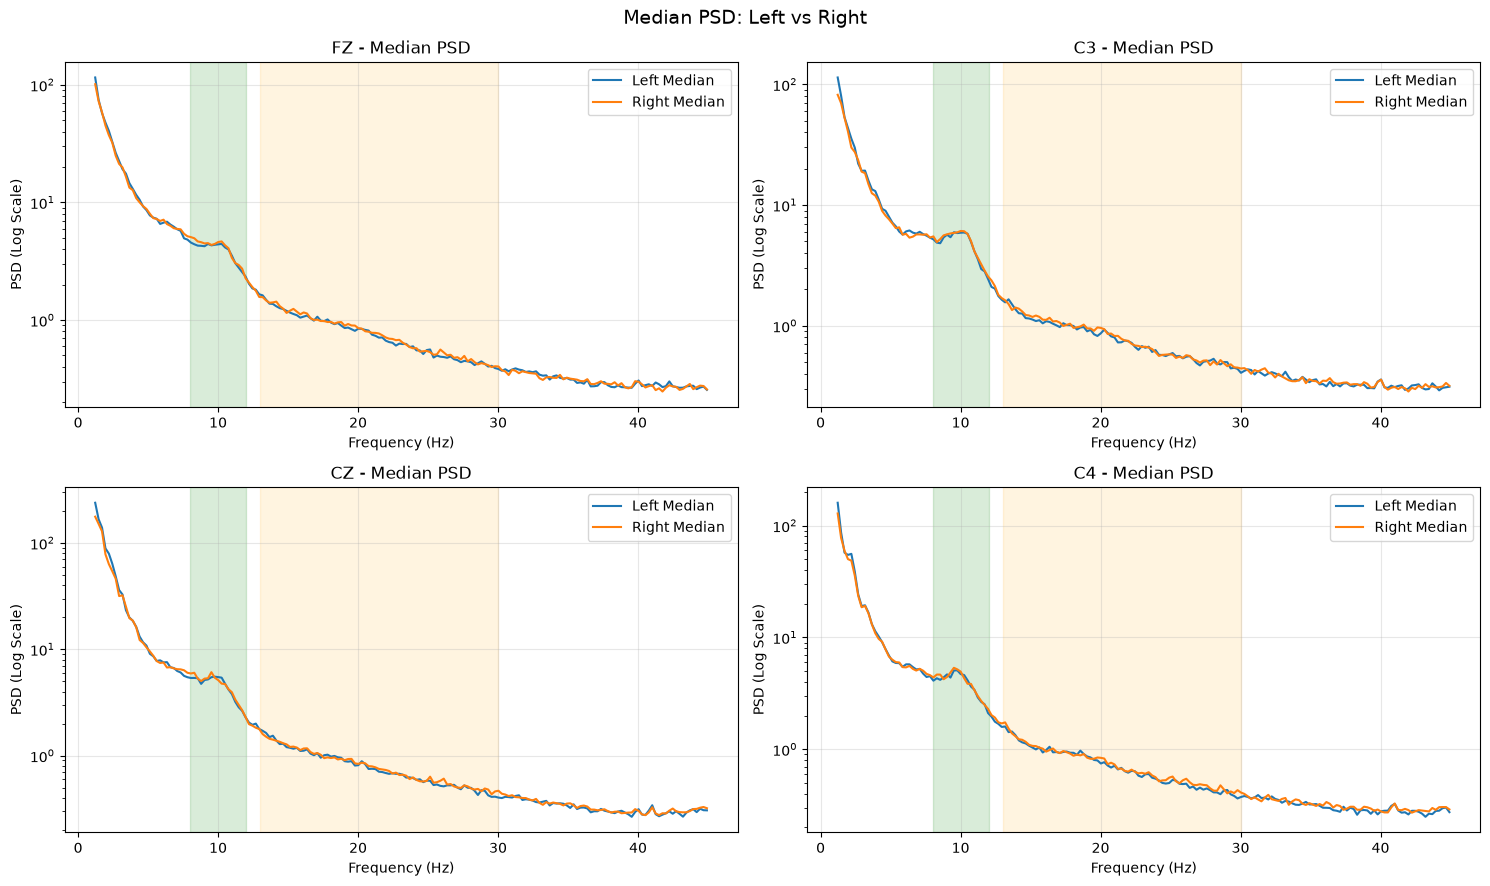

In [211]:
# Median PSD Analysis - More Robust Class Comparison

fig, axes = plt.subplots(2, 2, figsize=(15, 9))

median_psd_results = []

for ch_idx, channel in enumerate(channels):

    ax = axes.flat[ch_idx]

    for label in ["Left", "Right"]:

        trial_indices = (
            mapping_df.loc[
                mapping_df["label"] == label,
                "trial_index"
            ].to_numpy() - 1
        )

        psd_list = []

        for trial_idx in trial_indices:

            signal = X_centered[trial_idx, :, ch_idx]

            freqs, psd = welch(
                signal,
                fs=250,
                nperseg=1024,
                noverlap=512
            )

            psd_list.append(psd)

        psd_array = np.asarray(psd_list)

        median_psd = np.median(psd_array, axis=0)

        mean_psd = np.mean(psd_array, axis=0)

        median_psd_results.append({
            "channel": channel,
            "label": label,
            "mean_psd": mean_psd,
            "median_psd": median_psd
        })

        mask = (freqs >= 1) & (freqs <= 45)

        ax.plot(
            freqs[mask],
            median_psd[mask],
            label=f"{label} Median"
        )

    ax.axvspan(8, 12, alpha=0.15, color="green")
    ax.axvspan(13, 30, alpha=0.12, color="orange")

    ax.set_yscale("log")
    ax.set_title(f"{channel} - Median PSD")
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("PSD (Log Scale)")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("Median PSD: Left vs Right", fontsize=14)
plt.tight_layout()
plt.show()

In [212]:
# Per-Trial Mu and Beta Power Comparison

bands_to_compare = [
    "mu_power",
    "beta_power",
    "mu_relative_power",
    "beta_relative_power"
]

mi_band_summary = (
    frequency_features_df
    .groupby(["channel", "label"])[bands_to_compare]
    .agg(["median", "mean", "std"])
    .round(4)
)

display(mi_band_summary)

mi_band_summary.to_csv(
    OUTPUT_DIR / "mi_band_power_class_comparison.csv"
)

mu_power                            beta_power                \
                  median          mean          std     median          mean   
channel label                                                                  
C3      Left   22.415300   1785.976807   10655.1241    13.5012   1970.579346   
        Right  21.258600   3027.560547   24476.7362    14.4199   3756.568115   
C4      Left   17.650499   1474.259766    8450.2539    13.2422   1823.625244   
        Right  18.226400   2526.513184   12829.3995    13.6773   3196.855225   
CZ      Left   19.432699  19975.144531  238385.9937    13.3175  27516.199219   
        Right  19.112900  35407.000000  340771.0726    13.8701  49829.367188   
FZ      Left   16.718700   7282.523438  105011.4782    13.3487  10348.865234   
        Right  17.022600  10409.539062  114676.8035    13.8856  14724.375977   

                           mu_relative_power                  \
                       std            median    mean     std   
channel label                                                  
C3      Left    11120.0542            0.0002  0.0024  0.0072   
        Right   31587.9571            0.0003  0.0028  0.0064   
C4      Left    10837.4310            0.0000  0.0013  0.0034   
        Right   16747.3778            0.0000  0.0014  0.0037   
CZ      Left   343956.2259            0.0001  0.0014  0.0037   
        Right  488748.9535            0.0001  0.0016  0.0041   
FZ      Left   153543.6074            0.0001  0.0015  0.0034   
        Right  169101.2483            0.0002  0.0016  0.0038   

              beta_relative_power                  
                           median    mean     std  
channel label                                      
C3      Left               0.0002  0.0026  0.0069  
        Right              0.0002  0.0029  0.0076  
C4      Left               0.0000  0.0017  0.0046  
        Right              0.0000  0.0018  0.0048  
CZ      Left               0.0000  0.0018  0.0047  
        Right              0.0000  0.0019  0.0048  
FZ      Left               0.0001  0.0019  0.0047  
        Right              0.0001  0.0020  0.0049

In [213]:
# Robust Statistical Comparison: Left vs Right

from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

features_to_test = [
    "mu_power",
    "beta_power",
    "mu_relative_power",
    "beta_relative_power"
]

statistical_rows = []

for channel in channels:

    for feature in features_to_test:

        left_values = frequency_features_df.loc[
            (frequency_features_df["channel"] == channel) &
            (frequency_features_df["label"] == "Left"),
            feature
        ].dropna()

        right_values = frequency_features_df.loc[
            (frequency_features_df["channel"] == channel) &
            (frequency_features_df["label"] == "Right"),
            feature
        ].dropna()

        u_stat, p_value = mannwhitneyu(
            left_values,
            right_values,
            alternative="two-sided"
        )

        effect_size = (
            2 * u_stat / (len(left_values) * len(right_values)) - 1
        )

        statistical_rows.append({
            "channel": channel,
            "feature": feature,
            "left_median": left_values.median(),
            "right_median": right_values.median(),
            "effect_size": effect_size,
            "p_value": p_value
        })

mi_statistical_df = pd.DataFrame(statistical_rows)

mi_statistical_df["adjusted_p_value"] = multipletests(
    mi_statistical_df["p_value"],
    method="fdr_bh"
)[1]

mi_statistical_df["significant"] = (
    mi_statistical_df["adjusted_p_value"] < 0.05
)

display(
    mi_statistical_df.sort_values("adjusted_p_value")
)

mi_statistical_df.to_csv(
    OUTPUT_DIR / "mi_statistical_comparison.csv",
    index=False
)

,channel,feature,left_median,right_median,effect_size,p_value,adjusted_p_value,significant
0,FZ,mu_power,16.718666,17.022591,-0.010830,0.663010,0.931187,False
1,FZ,beta_power,13.348710,13.885629,-0.008107,0.744280,0.931187,False
2,FZ,mu_relative_power,0.000143,0.000154,-0.003650,0.883267,0.931187,False
3,FZ,beta_relative_power,0.000125,0.000114,-0.004734,0.848940,0.931187,False
4,C3,mu_power,22.415260,21.258579,-0.006432,0.795806,0.931187,False
5,C3,beta_power,13.501234,14.419853,-0.012747,0.608021,0.931187,False
6,C3,mu_relative_power,0.000243,0.000251,-0.022464,0.366040,0.931187,False
7,C3,beta_relative_power,0.000223,0.000232,-0.024458,0.325036,0.931187,False
8,CZ,mu_power,19.432680,19.112904,-0.006279,0.800548,0.931187,False
9,CZ,beta_power,13.317507,13.870105,-0.005684,0.819105,0.931187,False


In [214]:
# Motor Imagery Statistical Audit Summary

mi_statistical_summary = pd.DataFrame([{
    "total_comparisons": len(mi_statistical_df),
    "significant_features": int(
        mi_statistical_df["significant"].sum()
    ),
    "non_significant_features": int(
        (~mi_statistical_df["significant"]).sum()
    ),
    "minimum_adjusted_p_value": mi_statistical_df[
        "adjusted_p_value"
    ].min(),
    "maximum_absolute_effect_size": mi_statistical_df[
        "effect_size"
    ].abs().max(),
    "overall_status": "No significant univariate differences detected"
}])

display(mi_statistical_summary)

mi_statistical_summary.to_csv(
    OUTPUT_DIR / "motor_imagery_statistical_audit_summary.csv",
    index=False
)

,total_comparisons,significant_features,non_significant_features,minimum_adjusted_p_value,maximum_absolute_effect_size,overall_status
0,16,0,16,0.931187,0.024458,No significant univariate differences detected


In [215]:
# Final Feature Reliability Classification

reliability_rows = []

for feature in X_features.columns:

    group = feature_metadata.loc[
        feature_metadata["feature"] == feature,
        "feature_group"
    ].iloc[0]

    if group == "Time-Domain":
        status = "Exploratory - Signal Quality Review"
        reason = (
            "Time-domain feature is numerically valid, "
            "but affected by unresolved signal-quality issues."
        )

    elif group in ["Frequency-Domain", "Motor Imagery"]:
        status = "Provisional - Sampling Rate Unconfirmed"
        reason = (
            "Frequency-based feature depends on the assumed "
            "250 Hz sampling rate."
        )

    else:
        status = "Requires Review"
        reason = "Feature group requires manual verification."

    # Identify known redundancy patterns
    if feature.endswith("_ptp"):
        status = "Redundancy Review"
        reason = "Peak-to-peak is mathematically derived from max and min."

    elif feature.endswith("_std") or feature.endswith("_rms"):
        status = "Near-Redundant"
        reason = "STD and RMS are numerically very close."

    elif feature.startswith("alpha_power_") or feature.startswith("mu_power_"):
        status = "Overlap Review"
        reason = "Alpha and Mu frequency bands overlap."

    elif (
        feature.startswith("alpha_relative_power_")
        or feature.startswith("mu_relative_power_")
    ):
        status = "Overlap Review"
        reason = "Alpha and Mu relative-power bands overlap."

    elif feature.startswith("beta_power_") or feature.startswith("gamma_power_"):
        status = "Correlation Review"
        reason = "High correlation between Beta and Gamma requires investigation."

    reliability_rows.append({
        "feature": feature,
        "feature_group": group,
        "reliability_status": status,
        "review_reason": reason
    })

final_feature_reliability_df = pd.DataFrame(reliability_rows)

display(
    final_feature_reliability_df
    .groupby(["feature_group", "reliability_status"])
    .size()
    .reset_index(name="feature_count")
)

final_feature_reliability_df.to_csv(
    OUTPUT_DIR / "final_feature_reliability_classification.csv",
    index=False
)

display(final_feature_reliability_df)

,feature_group,reliability_status,feature_count
0,Frequency-Domain,Correlation Review,8
1,Frequency-Domain,Overlap Review,16
2,Frequency-Domain,Provisional - Sampling Rate Unconfirmed,44
3,Motor Imagery,Correlation Review,1
4,Motor Imagery,Overlap Review,1
5,Motor Imagery,Provisional - Sampling Rate Unconfirmed,2
6,Time-Domain,Exploratory - Signal Quality Review,36
7,Time-Domain,Near-Redundant,8
8,Time-Domain,Redundancy Review,4


,feature,feature_group,reliability_status,review_reason
0,fz_mean,Time-Domain,Exploratory - Signal Quality Review,"Time-domain feature is numerically valid, but ..."
1,fz_std,Time-Domain,Near-Redundant,STD and RMS are numerically very close.
2,fz_rms,Time-Domain,Near-Redundant,STD and RMS are numerically very close.
3,fz_min,Time-Domain,Exploratory - Signal Quality Review,"Time-domain feature is numerically valid, but ..."
4,fz_max,Time-Domain,Exploratory - Signal Quality Review,"Time-domain feature is numerically valid, but ..."
...,...,...,...,...
115,gamma_relative_power_fz,Frequency-Domain,Provisional - Sampling Rate Unconfirmed,Frequency-based feature depends on the assumed...
116,mu_beta_ratio_c3,Motor Imagery,Provisional - Sampling Rate Unconfirmed,Frequency-based feature depends on the assumed...
117,mu_beta_ratio_c4,Motor Imagery,Provisional - Sampling Rate Unconfirmed,Frequency-based feature depends on the assumed...
118,mu_power_c3_c4_difference,Motor Imagery,Overlap Review,Alpha and Mu frequency bands overlap.


In [216]:
# Improved Multi-Label Feature Reliability Audit

reliability_rows = []

# Features participating in highly correlated pairs
correlated_features = set(
    high_corr_pairs["feature_1"].tolist()
    + high_corr_pairs["feature_2"].tolist()
)

for feature in X_features.columns:

    group = feature_metadata.loc[
        feature_metadata["feature"] == feature,
        "feature_group"
    ].iloc[0]

    is_frequency_dependent = group in [
        "Frequency-Domain",
        "Motor Imagery"
    ]

    is_signal_quality_sensitive = group == "Time-Domain"

    is_near_redundant = (
        feature.endswith("_std")
        or feature.endswith("_rms")
    )

    is_exact_redundancy_candidate = feature.endswith("_ptp")

    is_alpha_mu_overlap = (
        feature.startswith("alpha_power_")
        or feature.startswith("mu_power_")
        or feature.startswith("alpha_relative_power_")
        or feature.startswith("mu_relative_power_")
    )

    is_highly_correlated = feature in correlated_features

    flags = []

    if is_frequency_dependent:
        flags.append("Sampling Rate Unconfirmed")

    if is_signal_quality_sensitive:
        flags.append("Signal Quality Review")

    if is_near_redundant:
        flags.append("Near-Redundant")

    if is_exact_redundancy_candidate:
        flags.append("Mathematical Redundancy Review")

    if is_alpha_mu_overlap:
        flags.append("Alpha-Mu Band Overlap")

    if is_highly_correlated:
        flags.append("High Correlation Review")

    reliability_rows.append({
        "feature": feature,
        "feature_group": group,
        "sampling_rate_unconfirmed": is_frequency_dependent,
        "signal_quality_review": is_signal_quality_sensitive,
        "near_redundant": is_near_redundant,
        "mathematical_redundancy_candidate": is_exact_redundancy_candidate,
        "alpha_mu_overlap": is_alpha_mu_overlap,
        "high_correlation_review": is_highly_correlated,
        "review_flags": " | ".join(flags) if flags else "No Specific Flag"
    })

final_feature_reliability_df = pd.DataFrame(reliability_rows)

# Summary by feature group
reliability_summary = (
    final_feature_reliability_df
    .groupby("feature_group")
    .agg(
        feature_count=("feature", "count"),
        sampling_rate_issues=("sampling_rate_unconfirmed", "sum"),
        signal_quality_issues=("signal_quality_review", "sum"),
        near_redundant=("near_redundant", "sum"),
        mathematical_redundancy=("mathematical_redundancy_candidate", "sum"),
        alpha_mu_overlap=("alpha_mu_overlap", "sum"),
        high_correlation=("high_correlation_review", "sum")
    )
    .reset_index()
)

display(reliability_summary)
display(final_feature_reliability_df)

final_feature_reliability_df.to_csv(
    OUTPUT_DIR / "final_feature_reliability_classification.csv",
    index=False
)

reliability_summary.to_csv(
    OUTPUT_DIR / "final_feature_reliability_summary.csv",
    index=False
)

,feature_group,feature_count,sampling_rate_issues,signal_quality_issues,near_redundant,mathematical_redundancy,alpha_mu_overlap,high_correlation
0,Frequency-Domain,68,68,0,0,0,16,68
1,Motor Imagery,4,4,0,0,0,1,4
2,Time-Domain,48,0,48,8,4,0,48


,feature,feature_group,sampling_rate_unconfirmed,signal_quality_review,near_redundant,mathematical_redundancy_candidate,alpha_mu_overlap,high_correlation_review,review_flags
0,fz_mean,Time-Domain,False,True,False,False,False,True,Signal Quality Review | High Correlation Review
1,fz_std,Time-Domain,False,True,True,False,False,True,Signal Quality Review | Near-Redundant | High ...
2,fz_rms,Time-Domain,False,True,True,False,False,True,Signal Quality Review | Near-Redundant | High ...
3,fz_min,Time-Domain,False,True,False,False,False,True,Signal Quality Review | High Correlation Review
4,fz_max,Time-Domain,False,True,False,False,False,True,Signal Quality Review | High Correlation Review
...,...,...,...,...,...,...,...,...,...
115,gamma_relative_power_fz,Frequency-Domain,True,False,False,False,False,True,Sampling Rate Unconfirmed | High Correlation R...
116,mu_beta_ratio_c3,Motor Imagery,True,False,False,False,False,True,Sampling Rate Unconfirmed | High Correlation R...
117,mu_beta_ratio_c4,Motor Imagery,True,False,False,False,False,True,Sampling Rate Unconfirmed | High Correlation R...
118,mu_power_c3_c4_difference,Motor Imagery,True,False,False,False,True,True,Sampling Rate Unconfirmed | Alpha-Mu Band Over...


In [217]:
is_near_redundant = (
    feature.endswith("_std")
    or feature.endswith("_rms")
)

In [218]:
# Validate Feature Reliability Flags

print("Near-Redundant Features:")
display(
    final_feature_reliability_df.loc[
        final_feature_reliability_df["near_redundant"],
        ["feature", "feature_group"]
    ]
)

print("Alpha-Mu Overlap Features:")
display(
    final_feature_reliability_df.loc[
        final_feature_reliability_df["alpha_mu_overlap"],
        ["feature", "feature_group"]
    ]
)

print("Mathematical Redundancy Candidates:")
display(
    final_feature_reliability_df.loc[
        final_feature_reliability_df["mathematical_redundancy_candidate"],
        ["feature", "feature_group"]
    ]
)

print("High Correlation Features:")
display(
    final_feature_reliability_df.loc[
        final_feature_reliability_df["high_correlation_review"],
        ["feature", "feature_group"]
    ]
)

Near-Redundant Features:


,feature,feature_group
1,fz_std,Time-Domain
2,fz_rms,Time-Domain
13,c3_std,Time-Domain
14,c3_rms,Time-Domain
25,cz_std,Time-Domain
26,cz_rms,Time-Domain
37,c4_std,Time-Domain
38,c4_rms,Time-Domain


Alpha-Mu Overlap Features:


,feature,feature_group
84,alpha_power_c3,Frequency-Domain
85,alpha_power_c4,Frequency-Domain
86,alpha_power_cz,Frequency-Domain
87,alpha_power_fz,Frequency-Domain
88,alpha_relative_power_c3,Frequency-Domain
89,alpha_relative_power_c4,Frequency-Domain
90,alpha_relative_power_cz,Frequency-Domain
91,alpha_relative_power_fz,Frequency-Domain
92,mu_power_c3,Frequency-Domain
93,mu_power_c4,Frequency-Domain


Mathematical Redundancy Candidates:


,feature,feature_group
5,fz_ptp,Time-Domain
17,c3_ptp,Time-Domain
29,cz_ptp,Time-Domain
41,c4_ptp,Time-Domain


High Correlation Features:


,feature,feature_group
0,fz_mean,Time-Domain
1,fz_std,Time-Domain
2,fz_rms,Time-Domain
3,fz_min,Time-Domain
4,fz_max,Time-Domain
...,...,...
115,gamma_relative_power_fz,Frequency-Domain
116,mu_beta_ratio_c3,Motor Imagery
117,mu_beta_ratio_c4,Motor Imagery
118,mu_power_c3_c4_difference,Motor Imagery


In [219]:
# Correct Alpha-Mu Overlap Classification

final_feature_reliability_df.loc[
    final_feature_reliability_df["feature"] == "mu_power_c3_c4_difference",
    "alpha_mu_overlap"
] = False

# Rebuild review flags
flag_columns = [
    "sampling_rate_unconfirmed",
    "signal_quality_review",
    "near_redundant",
    "mathematical_redundancy_candidate",
    "alpha_mu_overlap",
    "high_correlation_review"
]

flag_labels = {
    "sampling_rate_unconfirmed": "Sampling Rate Unconfirmed",
    "signal_quality_review": "Signal Quality Review",
    "near_redundant": "Near-Redundant",
    "mathematical_redundancy_candidate": "Mathematical Redundancy Review",
    "alpha_mu_overlap": "Alpha-Mu Band Overlap",
    "high_correlation_review": "High Correlation Review"
}

final_feature_reliability_df["review_flags"] = (
    final_feature_reliability_df[flag_columns]
    .apply(
        lambda row: " | ".join(
            flag_labels[col]
            for col in flag_columns
            if row[col]
        ) or "No Specific Flag",
        axis=1
    )
)

display(
    final_feature_reliability_df.loc[
        final_feature_reliability_df["feature"].str.contains("difference"),
        ["feature", "review_flags"]
    ]
)

final_feature_reliability_df.to_csv(
    OUTPUT_DIR / "final_feature_reliability_classification.csv",
    index=False
)

,feature,review_flags
118,mu_power_c3_c4_difference,Sampling Rate Unconfirmed | High Correlation R...
119,beta_power_c3_c4_difference,Sampling Rate Unconfirmed | High Correlation R...


In [220]:
# Verify Peak-to-Peak Mathematical Relationship

ptp_validation = []

for ch in channels:

    ch_lower = ch.lower()

    actual_difference = (
        combined_features_df[f"{ch_lower}_max"]
        - combined_features_df[f"{ch_lower}_min"]
    )

    ptp_values = combined_features_df[f"{ch_lower}_ptp"]

    differences = (actual_difference - ptp_values).abs()

    ptp_validation.append({
        "channel": ch,
        "exactly_equal": np.allclose(
            actual_difference,
            ptp_values,
            rtol=1e-5,
            atol=1e-5
        ),
        "max_absolute_difference": differences.max(),
        "mean_absolute_difference": differences.mean()
    })

ptp_validation_df = pd.DataFrame(ptp_validation)

display(ptp_validation_df)

ptp_validation_df.to_csv(
    OUTPUT_DIR / "ptp_mathematical_validation.csv",
    index=False
)

,channel,exactly_equal,max_absolute_difference,mean_absolute_difference
0,FZ,True,0.0,0.0
1,C3,True,0.0,0.0
2,CZ,True,0.0,0.0
3,C4,True,0.0,0.0


In [223]:
print("Columns:")
print(redundancy_decisions.columns.tolist())

print("\nCurrent DataFrame:")
display(redundancy_decisions.head())

Columns:
['relationship', 'finding', 'decision', 'action']

Current DataFrame:


,relationship,finding,decision,action
0,PTP vs MAX-MIN,Exact mathematical duplicate,Confirmed redundancy,Consider removing PTP later
1,STD vs RMS,Perfect correlation but not exact equality,Near-redundancy,Review relative differences
2,Alpha vs Mu,Very high correlation,Possible frequency-band overlap,Verify band definitions
3,Beta vs Gamma,High correlation,Requires investigation,Review PSD and 50 Hz interference


In [224]:
ptp_validation_df["relationship"] = "PTP vs MAX-MIN"

ptp_validation_df["finding"] = (
    "Exact mathematical equality across all four channels"
)

ptp_validation_df["decision"] = "Confirmed redundancy"

ptp_validation_df["action"] = (
    "Consider removing PTP during final feature selection"
)

ptp_validation_df.to_csv(
    OUTPUT_DIR / "ptp_mathematical_validation.csv",
    index=False
)

display(ptp_validation_df)

,channel,exactly_equal,max_absolute_difference,mean_absolute_difference,relationship,finding,decision,action
0,FZ,True,0.0,0.0,PTP vs MAX-MIN,Exact mathematical equality across all four ch...,Confirmed redundancy,Consider removing PTP during final feature sel...
1,C3,True,0.0,0.0,PTP vs MAX-MIN,Exact mathematical equality across all four ch...,Confirmed redundancy,Consider removing PTP during final feature sel...
2,CZ,True,0.0,0.0,PTP vs MAX-MIN,Exact mathematical equality across all four ch...,Confirmed redundancy,Consider removing PTP during final feature sel...
3,C4,True,0.0,0.0,PTP vs MAX-MIN,Exact mathematical equality across all four ch...,Confirmed redundancy,Consider removing PTP during final feature sel...


In [225]:
print("High-correlation pairs:", len(high_corr_pairs))
print("Columns:", high_corr_pairs.columns.tolist())

display(
    high_corr_pairs
    .sort_values("absolute_correlation", ascending=False)
    .head(30)
)

High-correlation pairs: 14400
Columns: ['feature_1', 'feature_2', 'correlation', 'absolute_correlation']


,feature_1,feature_2,correlation,absolute_correlation
0,cz_std,cz_rms,1.000000,1.000000
1,c4_std,c4_rms,1.000000,1.000000
2,fz_std,fz_rms,1.000000,1.000000
3,c3_std,c3_rms,1.000000,1.000000
4,alpha_power_fz,mu_power_fz,0.998533,0.998533
5,alpha_power_cz,mu_power_cz,0.998307,0.998307
6,alpha_power_c3,mu_power_c3,0.998170,0.998170
7,fz_rms,fz_iqr,0.997879,0.997879
8,fz_std,fz_iqr,0.997879,0.997879
9,alpha_relative_power_fz,mu_relative_power_fz,0.997106,0.997106


In [226]:
print("Feature correlation matrix:", feature_corr.shape)
print("High correlation pairs:", high_corr_pairs.shape)

print("\nCorrelation matrix index duplicates:")
print(feature_corr.index.duplicated().sum())

print("\nCorrelation matrix column duplicates:")
print(feature_corr.columns.duplicated().sum())

print("\nDuplicate pairs:")
print(
    high_corr_pairs.duplicated(
        subset=["feature_1", "feature_2"]
    ).sum()
)

print("\nReversed duplicate pairs:")
pair_keys = high_corr_pairs.apply(
    lambda row: tuple(sorted([
        row["feature_1"],
        row["feature_2"]
    ])),
    axis=1
)

print("Unique unordered pairs:", pair_keys.nunique())

Feature correlation matrix: (120, 120)
High correlation pairs: (14400, 4)

Correlation matrix index duplicates:
0

Correlation matrix column duplicates:
0

Duplicate pairs:
0

Reversed duplicate pairs:
Unique unordered pairs: 7260


In [227]:
# Extract upper triangle only

upper_triangle = feature_corr.where(
    np.triu(
        np.ones(feature_corr.shape),
        k=1
    ).astype(bool)
)

high_corr_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

high_corr_pairs.columns = [
    "feature_1",
    "feature_2",
    "correlation"
]

high_corr_pairs["absolute_correlation"] = (
    high_corr_pairs["correlation"].abs()
)

high_corr_pairs = (
    high_corr_pairs[
        high_corr_pairs["absolute_correlation"] >= 0.90
    ]
    .sort_values(
        "absolute_correlation",
        ascending=False
    )
    .reset_index(drop=True)
)

print("Unique high-correlation pairs:", len(high_corr_pairs))

display(high_corr_pairs.head(30))

high_corr_pairs.to_csv(
    OUTPUT_DIR / "high_correlation_pairs.csv",
    index=False
)

Unique high-correlation pairs: 176


,feature_1,feature_2,correlation,absolute_correlation
0,cz_std,cz_rms,1.000000,1.000000
1,c4_std,c4_rms,1.000000,1.000000
2,fz_std,fz_rms,1.000000,1.000000
3,c3_std,c3_rms,1.000000,1.000000
4,alpha_power_fz,mu_power_fz,0.998533,0.998533
5,alpha_power_cz,mu_power_cz,0.998307,0.998307
6,alpha_power_c3,mu_power_c3,0.998170,0.998170
7,fz_rms,fz_iqr,0.997879,0.997879
8,fz_std,fz_iqr,0.997879,0.997879
9,alpha_relative_power_fz,mu_relative_power_fz,0.997106,0.997106


In [228]:
# Add feature groups to correlation pairs

feature_group_map = feature_metadata.set_index(
    "feature"
)["feature_group"].to_dict()

high_corr_pairs["feature_1_group"] = (
    high_corr_pairs["feature_1"].map(feature_group_map)
)

high_corr_pairs["feature_2_group"] = (
    high_corr_pairs["feature_2"].map(feature_group_map)
)

high_corr_pairs["group_relationship"] = high_corr_pairs.apply(
    lambda row: (
        f"{row['feature_1_group']} vs {row['feature_2_group']}"
    ),
    axis=1
)

group_summary = (
    high_corr_pairs
    .groupby("group_relationship")
    .agg(
        pair_count=("correlation", "count"),
        mean_correlation=("absolute_correlation", "mean"),
        max_correlation=("absolute_correlation", "max")
    )
    .sort_values("pair_count", ascending=False)
    .reset_index()
)

display(group_summary)

group_summary.to_csv(
    OUTPUT_DIR / "high_correlation_group_summary.csv",
    index=False
)

,group_relationship,pair_count,mean_correlation,max_correlation
0,Time-Domain vs Time-Domain,80,0.955589,1.000000
1,Frequency-Domain vs Frequency-Domain,76,0.943710,0.998533
2,Time-Domain vs Frequency-Domain,19,0.925104,0.952036
3,Motor Imagery vs Motor Imagery,1,0.915157,0.915157


In [229]:
# Time-Domain High-Correlation Pairs

time_domain_pairs = high_corr_pairs[
    (high_corr_pairs["feature_1_group"] == "Time-Domain") &
    (high_corr_pairs["feature_2_group"] == "Time-Domain")
].copy()

display(
    time_domain_pairs[
        [
            "feature_1",
            "feature_2",
            "correlation",
            "absolute_correlation"
        ]
    ].sort_values(
        "absolute_correlation",
        ascending=False
    )
)

print("Total Time-Domain pairs:", len(time_domain_pairs))

,feature_1,feature_2,correlation,absolute_correlation
0,cz_std,cz_rms,1.000000,1.000000
1,c4_std,c4_rms,1.000000,1.000000
2,fz_std,fz_rms,1.000000,1.000000
3,c3_std,c3_rms,1.000000,1.000000
7,fz_rms,fz_iqr,0.997879,0.997879
...,...,...,...,...
159,fz_ptp,cz_line_length,0.907369,0.907369
162,fz_max,cz_line_length,0.905521,0.905521
167,c3_min,c4_min,0.902462,0.902462
169,fz_min,cz_line_length,-0.902036,0.902036


Total Time-Domain pairs: 80


In [230]:
def get_feature_type(feature):
    for suffix in [
        "mean", "std", "rms", "min", "max",
        "ptp", "median", "iqr", "skewness",
        "kurtosis", "zero_crossing_rate", "line_length"
    ]:
        if feature.endswith("_" + suffix):
            return suffix

    return "Other"


time_domain_pairs["type_1"] = (
    time_domain_pairs["feature_1"].apply(get_feature_type)
)

time_domain_pairs["type_2"] = (
    time_domain_pairs["feature_2"].apply(get_feature_type)
)

time_domain_pairs["relationship_type"] = (
    time_domain_pairs.apply(
        lambda row: " vs ".join(
            sorted([row["type_1"], row["type_2"]])
        ),
        axis=1
    )
)

time_domain_relationship_summary = (
    time_domain_pairs
    .groupby("relationship_type")
    .agg(
        pair_count=("correlation", "count"),
        mean_correlation=("absolute_correlation", "mean"),
        max_correlation=("absolute_correlation", "max")
    )
    .sort_values("pair_count", ascending=False)
    .reset_index()
)

display(time_domain_relationship_summary)

time_domain_relationship_summary.to_csv(
    OUTPUT_DIR / "time_domain_correlation_relationships.csv",
    index=False
)

,relationship_type,pair_count,mean_correlation,max_correlation
0,iqr vs line_length,6,0.965064,0.995677
1,iqr vs rms,5,0.969755,0.997879
2,iqr vs std,5,0.969755,0.997879
3,line_length vs rms,5,0.956495,0.992632
4,line_length vs std,5,0.956495,0.992632
5,max vs min,4,0.942530,0.984156
6,max vs ptp,4,0.984562,0.995980
7,min vs std,4,0.934491,0.974065
8,ptp vs std,4,0.948195,0.979607
9,rms vs std,4,1.000000,1.000000


In [231]:
# Detect whether correlated features belong to the same channel

def get_channel(feature):
    channels_found = ["fz", "c3", "cz", "c4"]

    for ch in channels_found:
        if feature.startswith(ch + "_"):
            return ch

    return "unknown"


time_domain_pairs["channel_1"] = (
    time_domain_pairs["feature_1"].apply(get_channel)
)

time_domain_pairs["channel_2"] = (
    time_domain_pairs["feature_2"].apply(get_channel)
)

time_domain_pairs["channel_relationship"] = np.where(
    time_domain_pairs["channel_1"] ==
    time_domain_pairs["channel_2"],
    "Same Channel",
    "Different Channels"
)

channel_relationship_summary = (
    time_domain_pairs
    .groupby("channel_relationship")
    .agg(
        pair_count=("correlation", "count"),
        mean_correlation=("absolute_correlation", "mean"),
        max_correlation=("absolute_correlation", "max")
    )
    .reset_index()
)

display(channel_relationship_summary)

channel_relationship_summary.to_csv(
    OUTPUT_DIR / "time_domain_channel_relationship_summary.csv",
    index=False
)

,channel_relationship,pair_count,mean_correlation,max_correlation
0,Different Channels,13,0.917712,0.935152
1,Same Channel,67,0.962938,1.000000


In [232]:
frequency_pairs = high_corr_pairs[
    (high_corr_pairs["feature_1_group"] == "Frequency-Domain") &
    (high_corr_pairs["feature_2_group"] == "Frequency-Domain")
].copy()

display(
    frequency_pairs.sort_values(
        "absolute_correlation",
        ascending=False
    )
)

print("Total Frequency-Domain pairs:", len(frequency_pairs))

,feature_1,feature_2,correlation,absolute_correlation,feature_1_group,feature_2_group,group_relationship
4,alpha_power_fz,mu_power_fz,0.998533,0.998533,Frequency-Domain,Frequency-Domain,Frequency-Domain vs Frequency-Domain
5,alpha_power_cz,mu_power_cz,0.998307,0.998307,Frequency-Domain,Frequency-Domain,Frequency-Domain vs Frequency-Domain
6,alpha_power_c3,mu_power_c3,0.998170,0.998170,Frequency-Domain,Frequency-Domain,Frequency-Domain vs Frequency-Domain
9,alpha_relative_power_fz,mu_relative_power_fz,0.997106,0.997106,Frequency-Domain,Frequency-Domain,Frequency-Domain vs Frequency-Domain
10,alpha_power_c4,mu_power_c4,0.996934,0.996934,Frequency-Domain,Frequency-Domain,Frequency-Domain vs Frequency-Domain
...,...,...,...,...,...,...,...
166,theta_relative_power_c4,theta_relative_power_fz,0.903068,0.903068,Frequency-Domain,Frequency-Domain,Frequency-Domain vs Frequency-Domain
168,alpha_relative_power_cz,beta_relative_power_cz,0.902222,0.902222,Frequency-Domain,Frequency-Domain,Frequency-Domain vs Frequency-Domain
171,alpha_relative_power_c4,alpha_relative_power_fz,0.901352,0.901352,Frequency-Domain,Frequency-Domain,Frequency-Domain vs Frequency-Domain
173,theta_power_cz,alpha_power_cz,0.900437,0.900437,Frequency-Domain,Frequency-Domain,Frequency-Domain vs Frequency-Domain


Total Frequency-Domain pairs: 76


In [233]:
def get_frequency_type(feature):

    prefixes = [
        "delta_relative_power",
        "theta_relative_power",
        "alpha_relative_power",
        "mu_relative_power",
        "beta_relative_power",
        "gamma_relative_power",
        "delta_power",
        "theta_power",
        "alpha_power",
        "mu_power",
        "beta_power",
        "gamma_power",
        "dominant_frequency",
        "spectral_centroid",
        "spectral_bandwidth",
        "spectral_entropy"
    ]

    for prefix in prefixes:
        if feature.startswith(prefix + "_"):
            return prefix

    return "Other"


frequency_pairs["type_1"] = (
    frequency_pairs["feature_1"].apply(get_frequency_type)
)

frequency_pairs["type_2"] = (
    frequency_pairs["feature_2"].apply(get_frequency_type)
)

frequency_pairs["relationship_type"] = frequency_pairs.apply(
    lambda row: " vs ".join(
        sorted([row["type_1"], row["type_2"]])
    ),
    axis=1
)

frequency_relationship_summary = (
    frequency_pairs
    .groupby("relationship_type")
    .agg(
        pair_count=("correlation", "count"),
        mean_correlation=("absolute_correlation", "mean"),
        max_correlation=("absolute_correlation", "max")
    )
    .sort_values("pair_count", ascending=False)
    .reset_index()
)

display(frequency_relationship_summary)

frequency_relationship_summary.to_csv(
    OUTPUT_DIR / "frequency_correlation_relationships.csv",
    index=False
)

,relationship_type,pair_count,mean_correlation,max_correlation
0,beta_relative_power vs gamma_relative_power,9,0.931914,0.960600
1,alpha_relative_power vs mu_relative_power,7,0.963902,0.997106
2,alpha_power vs mu_power,5,0.981864,0.998533
3,alpha_power vs beta_power,5,0.937014,0.962543
4,beta_power vs gamma_power,5,0.972077,0.988019
5,alpha_power vs gamma_power,4,0.955050,0.977659
6,gamma_power vs mu_power,4,0.948672,0.971933
7,beta_power vs mu_power,4,0.944935,0.961990
8,spectral_entropy vs spectral_entropy,3,0.924682,0.941921
9,beta_relative_power vs beta_relative_power,3,0.939154,0.957017


In [234]:
other_frequency_pairs = frequency_pairs[
    (frequency_pairs["type_1"] == "Other") |
    (frequency_pairs["type_2"] == "Other")
][
    ["feature_1", "feature_2", "correlation", "type_1", "type_2"]
]

display(other_frequency_pairs)

,feature_1,feature_2,correlation,type_1,type_2
70,total_power_c3,total_power_c4,0.957384,Other,Other
98,total_power_cz,total_power_fz,0.937028,Other,Other


In [236]:
def get_frequency_type(feature):

    prefixes = [
        "delta_relative_power",
        "theta_relative_power",
        "alpha_relative_power",
        "mu_relative_power",
        "beta_relative_power",
        "gamma_relative_power",
        "delta_power",
        "theta_power",
        "alpha_power",
        "mu_power",
        "beta_power",
        "gamma_power",
        "total_power",
        "dominant_frequency",
        "spectral_centroid",
        "spectral_bandwidth",
        "spectral_entropy"
    ]

    for prefix in prefixes:
        if feature.startswith(prefix + "_"):
            return prefix

    return "Other"

In [237]:
frequency_relationship_summary.to_csv(
    OUTPUT_DIR / "frequency_correlation_relationships.csv",
    index=False
)

In [238]:
# Reclassify frequency features
frequency_pairs["type_1"] = frequency_pairs["feature_1"].apply(
    get_frequency_type
)

frequency_pairs["type_2"] = frequency_pairs["feature_2"].apply(
    get_frequency_type
)

# Rebuild relationship types
frequency_pairs["relationship_type"] = frequency_pairs.apply(
    lambda row: " vs ".join(
        sorted([row["type_1"], row["type_2"]])
    ),
    axis=1
)

# Rebuild summary
frequency_relationship_summary = (
    frequency_pairs
    .groupby("relationship_type")
    .agg(
        pair_count=("correlation", "count"),
        mean_correlation=("absolute_correlation", "mean"),
        max_correlation=("absolute_correlation", "max")
    )
    .sort_values("pair_count", ascending=False)
    .reset_index()
)

# Verify classification
print("Other pairs:", len(
    frequency_pairs[
        (frequency_pairs["type_1"] == "Other") |
        (frequency_pairs["type_2"] == "Other")
    ]
))

display(frequency_relationship_summary)

# Save updated summary
frequency_relationship_summary.to_csv(
    OUTPUT_DIR / "frequency_correlation_relationships.csv",
    index=False
)

Other pairs: 0


,relationship_type,pair_count,mean_correlation,max_correlation
0,beta_relative_power vs gamma_relative_power,9,0.931914,0.960600
1,alpha_relative_power vs mu_relative_power,7,0.963902,0.997106
2,beta_power vs gamma_power,5,0.972077,0.988019
3,alpha_power vs mu_power,5,0.981864,0.998533
4,alpha_power vs beta_power,5,0.937014,0.962543
5,alpha_power vs gamma_power,4,0.955050,0.977659
6,beta_power vs mu_power,4,0.944935,0.961990
7,gamma_power vs mu_power,4,0.948672,0.971933
8,beta_power vs theta_power,3,0.944514,0.975579
9,beta_relative_power vs beta_relative_power,3,0.939154,0.957017


In [239]:
frequency_redundancy_decisions = pd.DataFrame([
    {
        "relationship": "Alpha Power vs Mu Power",
        "finding": "Overlapping frequency bands (8-13 Hz and 8-12 Hz)",
        "decision": "Confirmed Feature Overlap",
        "action": "Review before final feature selection"
    },
    {
        "relationship": "Alpha Relative Power vs Mu Relative Power",
        "finding": "Overlapping frequency bands",
        "decision": "Confirmed Feature Overlap",
        "action": "Review before final feature selection"
    },
    {
        "relationship": "Beta Power vs Gamma Power",
        "finding": "High correlation without direct band overlap",
        "decision": "Requires Investigation",
        "action": "Retain pending signal quality investigation"
    },
    {
        "relationship": "Beta Relative Power vs Gamma Relative Power",
        "finding": "High correlation without direct band overlap",
        "decision": "Requires Investigation",
        "action": "Retain pending signal quality investigation"
    },
    {
        "relationship": "Total Power across channels",
        "finding": "Strong cross-channel correlation",
        "decision": "Keep",
        "action": "Retain as potentially shared EEG activity"
    },
    {
        "relationship": "Other Frequency Relationships",
        "finding": "High statistical correlation",
        "decision": "Keep for Now",
        "action": "No deletion based on correlation alone"
    }
])

display(frequency_redundancy_decisions)

frequency_redundancy_decisions.to_csv(
    OUTPUT_DIR / "frequency_redundancy_decisions.csv",
    index=False
)

,relationship,finding,decision,action
0,Alpha Power vs Mu Power,Overlapping frequency bands (8-13 Hz and 8-12 Hz),Confirmed Feature Overlap,Review before final feature selection
1,Alpha Relative Power vs Mu Relative Power,Overlapping frequency bands,Confirmed Feature Overlap,Review before final feature selection
2,Beta Power vs Gamma Power,High correlation without direct band overlap,Requires Investigation,Retain pending signal quality investigation
3,Beta Relative Power vs Gamma Relative Power,High correlation without direct band overlap,Requires Investigation,Retain pending signal quality investigation
4,Total Power across channels,Strong cross-channel correlation,Keep,Retain as potentially shared EEG activity
5,Other Frequency Relationships,High statistical correlation,Keep for Now,No deletion based on correlation alone


In [240]:
mi_pairs = high_corr_pairs[
    (high_corr_pairs["feature_1_group"] == "Motor Imagery") &
    (high_corr_pairs["feature_2_group"] == "Motor Imagery")
].copy()

display(
    mi_pairs.sort_values(
        "absolute_correlation",
        ascending=False
    )
)

print("Total Motor Imagery pairs:", len(mi_pairs))

,feature_1,feature_2,correlation,absolute_correlation,feature_1_group,feature_2_group,group_relationship
137,mu_power_c3_c4_difference,beta_power_c3_c4_difference,0.915157,0.915157,Motor Imagery,Motor Imagery,Motor Imagery vs Motor Imagery


Total Motor Imagery pairs: 1


In [241]:
mi_redundancy_decisions = pd.DataFrame([
    {
        "relationship": "Mu C3-C4 Difference vs Beta C3-C4 Difference",
        "finding": "High correlation between different frequency-band features",
        "decision": "Keep - Requires Review",
        "action": "Retain both features; no confirmed redundancy"
    }
])

display(mi_redundancy_decisions)

mi_redundancy_decisions.to_csv(
    OUTPUT_DIR / "motor_imagery_redundancy_decisions.csv",
    index=False
)

,relationship,finding,decision,action
0,Mu C3-C4 Difference vs Beta C3-C4 Difference,High correlation between different frequency-b...,Keep - Requires Review,Retain both features; no confirmed redundancy


In [242]:
# Add feature group labels
time_decisions = redundancy_decisions.copy()
time_decisions["feature_group"] = "Time-Domain"

frequency_decisions = frequency_redundancy_decisions.copy()
frequency_decisions["feature_group"] = "Frequency-Domain"

mi_decisions = mi_redundancy_decisions.copy()
mi_decisions["feature_group"] = "Motor Imagery"

# Combine all decisions
final_redundancy_audit = pd.concat(
    [
        time_decisions,
        frequency_decisions,
        mi_decisions
    ],
    ignore_index=True
)

# Organize columns
final_redundancy_audit = final_redundancy_audit[
    ["feature_group", "relationship", "finding", "decision", "action"]
]

display(final_redundancy_audit)

print("Total recorded decisions:", len(final_redundancy_audit))
print("\nDecisions by feature group:")
display(
    final_redundancy_audit["feature_group"].value_counts()
)

print("\nDecision distribution:")
display(
    final_redundancy_audit["decision"].value_counts()
)

# Save
final_redundancy_audit.to_csv(
    OUTPUT_DIR / "final_redundancy_audit.csv",
    index=False
)

,feature_group,relationship,finding,decision,action
0,Time-Domain,PTP vs MAX-MIN,Exact mathematical duplicate,Confirmed redundancy,Consider removing PTP later
1,Time-Domain,STD vs RMS,Perfect correlation but not exact equality,Near-redundancy,Review relative differences
2,Time-Domain,Alpha vs Mu,Very high correlation,Possible frequency-band overlap,Verify band definitions
3,Time-Domain,Beta vs Gamma,High correlation,Requires investigation,Review PSD and 50 Hz interference
4,Frequency-Domain,Alpha Power vs Mu Power,Overlapping frequency bands (8-13 Hz and 8-12 Hz),Confirmed Feature Overlap,Review before final feature selection
5,Frequency-Domain,Alpha Relative Power vs Mu Relative Power,Overlapping frequency bands,Confirmed Feature Overlap,Review before final feature selection
6,Frequency-Domain,Beta Power vs Gamma Power,High correlation without direct band overlap,Requires Investigation,Retain pending signal quality investigation
7,Frequency-Domain,Beta Relative Power vs Gamma Relative Power,High correlation without direct band overlap,Requires Investigation,Retain pending signal quality investigation
8,Frequency-Domain,Total Power across channels,Strong cross-channel correlation,Keep,Retain as potentially shared EEG activity
9,Frequency-Domain,Other Frequency Relationships,High statistical correlation,Keep for Now,No deletion based on correlation alone


Total recorded decisions: 11

Decisions by feature group:


feature_group
Frequency-Domain    6
Time-Domain         4
Motor Imagery       1
Name: count, dtype: int64


Decision distribution:


decision
Confirmed Feature Overlap          2
Requires Investigation             2
Confirmed redundancy               1
Near-redundancy                    1
Possible frequency-band overlap    1
Requires investigation             1
Keep                               1
Keep for Now                       1
Keep - Requires Review             1
Name: count, dtype: int64

In [244]:
review_flag_columns = [
    "sampling_rate_unconfirmed",
    "signal_quality_review",
    "near_redundant",
    "mathematical_redundancy_candidate",
    "alpha_mu_overlap",
    "high_correlation_review"
]

flag_summary = pd.DataFrame({
    "review_flag": review_flag_columns,
    "affected_features": [
        int(final_feature_reliability_df[col].sum())
        for col in review_flag_columns
    ],
    "percentage": [
        final_feature_reliability_df[col].mean() * 100
        for col in review_flag_columns
    ]
})

display(flag_summary)

,review_flag,affected_features,percentage
0,sampling_rate_unconfirmed,72,60.000000
1,signal_quality_review,48,40.000000
2,near_redundant,8,6.666667
3,mathematical_redundancy_candidate,4,3.333333
4,alpha_mu_overlap,16,13.333333
5,high_correlation_review,120,100.000000


In [245]:
group_summary = (
    final_feature_reliability_df
    .groupby("feature_group")
    .agg(
        total_features=("feature", "count"),
        sampling_rate_issues=("sampling_rate_unconfirmed", "sum"),
        signal_quality_issues=("signal_quality_review", "sum"),
        near_redundant=("near_redundant", "sum"),
        mathematical_duplicates=(
            "mathematical_redundancy_candidate", "sum"
        ),
        alpha_mu_overlap=("alpha_mu_overlap", "sum"),
        high_correlation=("high_correlation_review", "sum")
    )
    .reset_index()
)

display(group_summary)

,feature_group,total_features,sampling_rate_issues,signal_quality_issues,near_redundant,mathematical_duplicates,alpha_mu_overlap,high_correlation
0,Frequency-Domain,68,68,0,0,0,16,68
1,Motor Imagery,4,4,0,0,0,0,4
2,Time-Domain,48,0,48,8,4,0,48


In [246]:
# Count review flags for each feature
flag_columns = [
    "sampling_rate_unconfirmed",
    "signal_quality_review",
    "near_redundant",
    "mathematical_redundancy_candidate",
    "alpha_mu_overlap",
    "high_correlation_review"
]

final_feature_reliability_df["review_flag_count"] = (
    final_feature_reliability_df[flag_columns]
    .sum(axis=1)
)

# Summarize number of flags per feature
flag_count_summary = (
    final_feature_reliability_df
    .groupby(
        ["feature_group", "review_flag_count"]
    )
    .size()
    .reset_index(name="feature_count")
)

display(flag_count_summary)

# Features with multiple review flags
multiple_flags = (
    final_feature_reliability_df[
        final_feature_reliability_df["review_flag_count"] >= 2
    ]
    .sort_values(
        ["feature_group", "review_flag_count"],
        ascending=[True, False]
    )
)

display(multiple_flags)

print("Features with multiple flags:", len(multiple_flags))

,feature_group,review_flag_count,feature_count
0,Frequency-Domain,2,52
1,Frequency-Domain,3,16
2,Motor Imagery,2,4
3,Time-Domain,2,36
4,Time-Domain,3,12


,feature,feature_group,sampling_rate_unconfirmed,signal_quality_review,near_redundant,mathematical_redundancy_candidate,alpha_mu_overlap,high_correlation_review,review_flags,review_flag_count
84,alpha_power_c3,Frequency-Domain,True,False,False,False,True,True,Sampling Rate Unconfirmed | Alpha-Mu Band Over...,3
85,alpha_power_c4,Frequency-Domain,True,False,False,False,True,True,Sampling Rate Unconfirmed | Alpha-Mu Band Over...,3
86,alpha_power_cz,Frequency-Domain,True,False,False,False,True,True,Sampling Rate Unconfirmed | Alpha-Mu Band Over...,3
87,alpha_power_fz,Frequency-Domain,True,False,False,False,True,True,Sampling Rate Unconfirmed | Alpha-Mu Band Over...,3
88,alpha_relative_power_c3,Frequency-Domain,True,False,False,False,True,True,Sampling Rate Unconfirmed | Alpha-Mu Band Over...,3
...,...,...,...,...,...,...,...,...,...,...
43,c4_iqr,Time-Domain,False,True,False,False,False,True,Signal Quality Review | High Correlation Review,2
44,c4_skewness,Time-Domain,False,True,False,False,False,True,Signal Quality Review | High Correlation Review,2
45,c4_kurtosis,Time-Domain,False,True,False,False,False,True,Signal Quality Review | High Correlation Review,2
46,c4_zero_crossing_rate,Time-Domain,False,True,False,False,False,True,Signal Quality Review | High Correlation Review,2


Features with multiple flags: 120


In [247]:
def classify_feature_review(row):

    if row["mathematical_redundancy_candidate"]:
        return "Mathematical Redundancy Review"

    if row["alpha_mu_overlap"]:
        return "Frequency Band Overlap Review"

    if row["signal_quality_review"]:
        return "Signal Quality Review"

    if row["sampling_rate_unconfirmed"]:
        return "Sampling Rate Unconfirmed"

    if row["near_redundant"]:
        return "Near-Redundancy Review"

    if row["high_correlation_review"]:
        return "High Correlation Review"

    return "No Detected Review Flag"


final_feature_reliability_df["reliability_status"] = (
    final_feature_reliability_df.apply(
        classify_feature_review,
        axis=1
    )
)

display(
    final_feature_reliability_df[
        ["feature", "feature_group", "reliability_status"]
    ].groupby(
        ["feature_group", "reliability_status"]
    ).size().reset_index(name="feature_count")
)

print("\nReliability status distribution:")

display(
    final_feature_reliability_df["reliability_status"]
    .value_counts()
)

,feature_group,reliability_status,feature_count
0,Frequency-Domain,Frequency Band Overlap Review,16
1,Frequency-Domain,Sampling Rate Unconfirmed,52
2,Motor Imagery,Sampling Rate Unconfirmed,4
3,Time-Domain,Mathematical Redundancy Review,4
4,Time-Domain,Signal Quality Review,44



Reliability status distribution:


reliability_status
Sampling Rate Unconfirmed         56
Signal Quality Review             44
Frequency Band Overlap Review     16
Mathematical Redundancy Review     4
Name: count, dtype: int64

In [248]:
def classify_review_priority(row):

    if (
        row["mathematical_redundancy_candidate"]
        or row["alpha_mu_overlap"]
    ):
        return "Critical Review"

    if (
        row["sampling_rate_unconfirmed"]
        or row["signal_quality_review"]
    ):
        return "Technical Review"

    if (
        row["near_redundant"]
        or row["high_correlation_review"]
    ):
        return "Correlation Review"

    return "No Review Required"


final_feature_reliability_df["review_priority"] = (
    final_feature_reliability_df.apply(
        classify_review_priority,
        axis=1
    )
)

display(
    final_feature_reliability_df.groupby(
        ["feature_group", "review_priority"]
    ).size().reset_index(name="feature_count")
)

display(
    final_feature_reliability_df["review_priority"]
    .value_counts()
)

,feature_group,review_priority,feature_count
0,Frequency-Domain,Critical Review,16
1,Frequency-Domain,Technical Review,52
2,Motor Imagery,Technical Review,4
3,Time-Domain,Critical Review,4
4,Time-Domain,Technical Review,44


review_priority
Technical Review    100
Critical Review      20
Name: count, dtype: int64

In [249]:
final_feature_reliability_df.to_csv(
    OUTPUT_DIR / "final_feature_reliability_classification.csv",
    index=False
)

In [250]:
# Keep only valid Time-Domain redundancy decisions
time_domain_redundancy = redundancy_decisions[
    redundancy_decisions["relationship"].isin([
        "PTP vs MAX-MIN",
        "STD vs RMS"
    ])
].copy()

# Rebuild the final redundancy audit
final_redundancy_audit = pd.concat(
    [
        time_domain_redundancy,
        frequency_redundancy_decisions,
        mi_redundancy_decisions
    ],
    ignore_index=True
)

display(final_redundancy_audit)

print("Final audit shape:", final_redundancy_audit.shape)

final_redundancy_audit.to_csv(
    OUTPUT_DIR / "final_redundancy_audit.csv",
    index=False
)

,relationship,finding,decision,action
0,PTP vs MAX-MIN,Exact mathematical duplicate,Confirmed redundancy,Consider removing PTP later
1,STD vs RMS,Perfect correlation but not exact equality,Near-redundancy,Review relative differences
2,Alpha Power vs Mu Power,Overlapping frequency bands (8-13 Hz and 8-12 Hz),Confirmed Feature Overlap,Review before final feature selection
3,Alpha Relative Power vs Mu Relative Power,Overlapping frequency bands,Confirmed Feature Overlap,Review before final feature selection
4,Beta Power vs Gamma Power,High correlation without direct band overlap,Requires Investigation,Retain pending signal quality investigation
5,Beta Relative Power vs Gamma Relative Power,High correlation without direct band overlap,Requires Investigation,Retain pending signal quality investigation
6,Total Power across channels,Strong cross-channel correlation,Keep,Retain as potentially shared EEG activity
7,Other Frequency Relationships,High statistical correlation,Keep for Now,No deletion based on correlation alone
8,Mu C3-C4 Difference vs Beta C3-C4 Difference,High correlation between different frequency-b...,Keep - Requires Review,Retain both features; no confirmed redundancy


Final audit shape: (9, 4)


In [251]:
# 1. Dataset validation
feature_columns = [
    col for col in combined_features_df.columns
    if col not in ["trial_index", "label"]
]

print("=== FINAL DATASET VALIDATION ===")
print("Dataset shape:", combined_features_df.shape)
print("Number of trials:", len(combined_features_df))
print("Number of features:", len(feature_columns))
print("Duplicate trials:", combined_features_df["trial_index"].duplicated().sum())
print("Missing values:", combined_features_df.isna().sum().sum())
print("Infinite values:", np.isinf(
    combined_features_df[feature_columns].select_dtypes(include=np.number)
).sum().sum())

# 2. Metadata validation
metadata_features = set(
    feature_metadata.loc[
        ~feature_metadata["is_target"]
        & ~feature_metadata["is_identifier"],
        "feature"
    ]
)

dataset_features = set(feature_columns)

print("\n=== METADATA VALIDATION ===")
print("Metadata feature count:", len(metadata_features))
print("Dataset feature count:", len(dataset_features))
print("Missing from metadata:", dataset_features - metadata_features)
print("Missing from dataset:", metadata_features - dataset_features)

# 3. Reliability validation
reliability_features = set(final_feature_reliability_df["feature"])

print("\n=== RELIABILITY VALIDATION ===")
print("Reliability feature count:", len(reliability_features))
print("Missing from reliability:", dataset_features - reliability_features)
print("Extra in reliability:", reliability_features - dataset_features)

# 4. Label validation
print("\n=== LABEL VALIDATION ===")
print(combined_features_df["label"].value_counts())
print("Missing labels:", combined_features_df["label"].isna().sum())

# 5. Redundancy audit validation
print("\n=== REDUNDANCY AUDIT ===")
print("Audit rows:", len(final_redundancy_audit))
print(final_redundancy_audit["decision"].value_counts())

=== FINAL DATASET VALIDATION ===
Dataset shape: (2160, 122)
Number of trials: 2160
Number of features: 120
Duplicate trials: 0
Missing values: 0
Infinite values: 0

=== METADATA VALIDATION ===
Metadata feature count: 120
Dataset feature count: 120
Missing from metadata: set()
Missing from dataset: set()

=== RELIABILITY VALIDATION ===
Reliability feature count: 120
Missing from reliability: set()
Extra in reliability: set()

=== LABEL VALIDATION ===
label
Left     1082
Right    1078
Name: count, dtype: int64
Missing labels: 0

=== REDUNDANCY AUDIT ===
Audit rows: 9
decision
Confirmed Feature Overlap    2
Requires Investigation       2
Confirmed redundancy         1
Near-redundancy              1
Keep                         1
Keep for Now                 1
Keep - Requires Review       1
Name: count, dtype: int64


In [252]:
from datetime import datetime

report = f"""
BCI MOTOR IMAGERY EEG
FINAL PRE-MODELING REPORT
========================================

1. DATASET OVERVIEW
----------------------------------------
Total Trials: 2160
Total Features: 120
Dataset Shape: {combined_features_df.shape}
Channels: FZ, C3, CZ, C4
Samples per Trial: 2500

2. DATA VALIDATION
----------------------------------------
Duplicate Trials: 0
Missing Values: 0
Infinite Values: 0
Metadata Features: 120
Reliability Features: 120
Unmatched Metadata Features: 0
Unmatched Reliability Features: 0

3. LABEL DISTRIBUTION
----------------------------------------
Left: 1082
Right: 1078
Missing Labels: 0

4. FEATURE ENGINEERING
----------------------------------------
Time-Domain Features: 48
Frequency-Domain Features: 68
Motor Imagery Features: 4
Total Features: 120

5. FEATURE REDUNDANCY AUDIT
----------------------------------------
Total Reviewed Relationships: 9
Confirmed Mathematical Redundancy: 1
Near-Redundancy: 1
Confirmed Feature Overlap: 2
Requires Investigation: 2
Other Retained Relationships: 3

No features were deleted during this audit.

6. FEATURE REVIEW PRIORITY
----------------------------------------
Technical Review: 100
Critical Review: 20

7. SCIENTIFIC LIMITATIONS
----------------------------------------
- Sampling rate remains unconfirmed.
- Timestamp intervals are irregular.
- Frequency-domain results are provisional.
- Motor Imagery frequency features are provisional.
- Label-to-file mapping is provisional.
- 240 labels remain unmatched.
- Signal quality issues require further investigation.
- ERD/ERS was not calculated because cue timing
  and baseline information are unavailable.

8. PRE-MODELING STATUS
----------------------------------------
Dataset structural validation: PASSED
Feature metadata validation: PASSED
Feature reliability validation: PASSED
Redundancy audit: COMPLETED

Modeling has NOT started.

This report documents the current exploratory and
pre-modeling state. It does not certify the EEG
signals or provisional labels as scientifically valid.

Generated: {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}
"""

report_path = OUTPUT_DIR / "Final_Pre_Modeling_Report.txt"

report_path.write_text(report, encoding="utf-8")

print(report)
print(f"\nReport saved to: {report_path}")


BCI MOTOR IMAGERY EEG
FINAL PRE-MODELING REPORT

1. DATASET OVERVIEW
----------------------------------------
Total Trials: 2160
Total Features: 120
Dataset Shape: (2160, 122)
Channels: FZ, C3, CZ, C4
Samples per Trial: 2500

2. DATA VALIDATION
----------------------------------------
Duplicate Trials: 0
Missing Values: 0
Infinite Values: 0
Metadata Features: 120
Reliability Features: 120
Unmatched Metadata Features: 0
Unmatched Reliability Features: 0

3. LABEL DISTRIBUTION
----------------------------------------
Left: 1082
Right: 1078
Missing Labels: 0

4. FEATURE ENGINEERING
----------------------------------------
Time-Domain Features: 48
Frequency-Domain Features: 68
Motor Imagery Features: 4
Total Features: 120

5. FEATURE REDUNDANCY AUDIT
----------------------------------------
Total Reviewed Relationships: 9
Confirmed Mathematical Redundancy: 1
Near-Redundancy: 1
Confirmed Feature Overlap: 2
Requires Investigation: 2
Other Retained Relationships: 3

No features were deleted 

In [255]:
from pathlib import Path
import json

PROJECT_DIR = Path(r"C:\Users\noura\Z-BCI-Motor")

print("=== NOTEBOOK FILES ===")

for path in PROJECT_DIR.rglob("*.ipynb"):

    try:
        with open(path, "r", encoding="utf-8") as f:
            nb = json.load(f)

        cells = nb.get("cells", [])

        print("\nFile:", path)
        print("Size:", path.stat().st_size, "bytes")
        print("Cells:", len(cells))
        print("Outputs:", sum(
            len(cell.get("outputs", []))
            for cell in cells
        ))

    except Exception as e:
        print("\nCould not read:", path)
        print(e)

=== NOTEBOOK FILES ===

File: C:\Users\noura\Z-BCI-Motor\01_Data_Collection_and_Validation.ipynb
Size: 9065765 bytes
Cells: 219
Outputs: 412

File: C:\Users\noura\Z-BCI-Motor\.ipynb_checkpoints\01_Data_Collection_and_Validation-checkpoint.ipynb
Size: 9042343 bytes
Cells: 213
Outputs: 405

File: C:\Users\noura\Z-BCI-Motor\notebooks\01_Data_Collection_and_Validation.ipynb
Size: 337 bytes
Cells: 1
Outputs: 0

File: C:\Users\noura\Z-BCI-Motor\notebooks\.ipynb_checkpoints\BCI_MI_Processing_EDA-checkpoint.ipynb
Size: 468664 bytes
Cells: 24
Outputs: 12


In [256]:

import json
import base64
from pathlib import Path

# Correct notebook path
NOTEBOOK_PATH = Path(
    r"C:\Users\noura\Z-BCI-Motor\01_Data_Collection_and_Validation.ipynb"
)

# Destination folder
IMAGE_DIR = Path(
    r"C:\Users\noura\Z-BCI-Motor\outputs\#Image"
)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

# Read notebook without executing cells
with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
    notebook = json.load(f)

supported_formats = {
    "image/png": ".png",
    "image/jpeg": ".jpg",
    "image/jpg": ".jpg",
    "image/svg+xml": ".svg",
    "image/webp": ".webp"
}

saved_count = 0
format_counts = {}
failed_count = 0

for cell_index, cell in enumerate(notebook.get("cells", []), start=1):

    for output_index, output in enumerate(
        cell.get("outputs", []), start=1
    ):

        data = output.get("data", {})

        for mime_type, extension in supported_formats.items():

            if mime_type not in data:
                continue

            content = data[mime_type]

            if isinstance(content, list):
                content = "".join(content)

            try:
                if mime_type == "image/svg+xml":
                    image_bytes = content.encode("utf-8")
                else:
                    image_bytes = base64.b64decode(content)

                saved_count += 1

                filename = (
                    f"figure_{saved_count:03d}"
                    f"_cell_{cell_index}"
                    f"_output_{output_index}{extension}"
                )

                (IMAGE_DIR / filename).write_bytes(image_bytes)

                format_counts[extension] = (
                    format_counts.get(extension, 0) + 1
                )

            except Exception as e:
                failed_count += 1
                print(
                    f"Failed: cell {cell_index}, "
                    f"output {output_index}: {e}"
                )

print("\n========== EXTRACTION SUMMARY ==========")
print("Total cells:", len(notebook.get("cells", [])))
print("Total saved images:", saved_count)
print("Failed images:", failed_count)

for extension, count in format_counts.items():
    print(f"{extension}: {count}")

print("\nDestination:")
print(IMAGE_DIR)

print("\nFiles in destination:", len(list(IMAGE_DIR.iterdir())))



========== EXTRACTION SUMMARY ==========
Total cells: 219
Total saved images: 26
Failed images: 0
.png: 26

Destination:
C:\Users\noura\Z-BCI-Motor\outputs\#Image

Files in destination: 26
